In [ ]:

!pip -q install duckdb psycopg2-binary

import os
import shutil
import sqlite3
import duckdb
import psycopg2
from google.colab import drive, userdata

# 1. Connect Google Drive
drive.mount('/content/drive')

# 2. Set project folder
PROJECT_PATH = "/content/drive/MyDrive/CT472_Project"

# 3. Restore local database files from Google Drive
for db_file in ["inventory.db", "finance.duckdb"]:
    shutil.copy2(
        os.path.join(PROJECT_PATH, db_file),
        os.path.join("/content", db_file)
    )

# 4. Set working directory
os.chdir(PROJECT_PATH)

# 5. Connect SQLite Inventory database
inventory_conn = sqlite3.connect("/content/inventory.db")
inventory_cursor = inventory_conn.cursor()

# 6. Connect DuckDB Finance database
finance_conn = duckdb.connect("/content/finance.duckdb")

# 7. Connect Supabase Sales database
sales_conn = psycopg2.connect(
    host=userdata.get("SUPABASE_HOST"),
    port=int(userdata.get("SUPABASE_PORT")),
    database=userdata.get("SUPABASE_DB"),
    user=userdata.get("SUPABASE_USER"),
    password=userdata.get("SUPABASE_PASSWORD"),
    sslmode="require"
)
sales_cursor = sales_conn.cursor()

# 8. Connect Aiven Purchasing database
purchasing_conn = psycopg2.connect(
    host=userdata.get("AIVEN_HOST"),
    port=int(userdata.get("AIVEN_PORT")),
    database=userdata.get("AIVEN_DB"),
    user=userdata.get("AIVEN_USER"),
    password=userdata.get("AIVEN_PASSWORD"),
    sslmode="require"
)
purchasing_cursor = purchasing_conn.cursor()

print("All four databases connected successfully!")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
All four databases connected successfully!


In [ ]:
TASK 01

1.1 Management Questions
Question 1: Comparison
How do total sales differ across departments, regions and product categories?
•	User: Senior Management
•	Measure: Total Sales
•	Reporting Grain: Monthly sales by region and product category.
•	Intended Decision: Identify high-performing and low-performing regions and product categories.
Question 2: Trend
How have the organization's total sales changed over the last 36 months?
•	User: Sales Manager
•	Measure: Monthly Total Sales
•	Reporting Grain: Month
•	Intended Decision: Identify sales growth or decline and plan future sales activities.
Question 3: Contribution
Which product categories contribute the most to the organization's total revenue?
•	User: Product Manager
•	Measure: Category Sales and Percentage Contribution to Total Sales
•	Reporting Grain: Product Category per Month
•	Intended Decision: Identify the most profitable revenue-generating categories and prioritize products.
Question 4: Diagnosis
What factors are associated with unusual changes in sales, such as changes in purchasing activity or inventory availability?
•	User: Operations Manager
•	Measure: Total Sales, Purchase Quantity and Inventory Levels
•	Reporting Grain: Monthly by Product and Department
•	Intended Decision: Investigate possible reasons for sales increases or decreases and improve operational planning.
Question 5: Forecast
What will the organization's total monthly sales be over the next three months?
•	User: Senior Management
•	Measure: Forecasted Monthly Sales
•	Reporting Grain: Company-wide Monthly Sales
•	Intended Decision: Support future budgeting, purchasing and resource allocation.
Question 6: Anomaly Review
Which regions or product categories have experienced unusual sales patterns compared with their historical performance?
•	User: Finance Manager
•	Measure: Monthly Sales and Sales Deviation
•	Reporting Grain: Region-Month or Product Category-Month
•	Intended Decision: Investigate unusual transactions or unexpected business performance changes.
1.2 How Data Warehouse and BI Improve Decision-Making
Question	Improvement over separate departmental reports
Comparison	Combines departmental data to provide consistent comparisons across regions and categories.
Trend	Provides historical sales information in one place for analyzing long-term trends.
Contribution	Combines sales and product information to calculate each category's contribution accurately.
Diagnosis	Allows management to examine sales, purchasing and inventory information together.
Forecast	Provides integrated historical data for forecasting future sales.
Anomaly Review	Makes it possible to compare current performance with historical data and identify unusual patterns.
1.3 Conclusion
The Data Warehouse integrates information from different departmental databases into a centralized system. Power BI presents this integrated information through interactive reports and visualizations. This helps management make more informed decisions using consistent, reliable and historical data instead of relying on separate departmental reports.


TASK 02

In [ ]:
import sqlite3

conn = sqlite3.connect("inventory.db")
cursor = conn.cursor()

print("Inventory database created successfully!")

Inventory database created successfully!


In [ ]:
cursor.execute("""
CREATE TABLE inventory_products (
    product_id INTEGER PRIMARY KEY,
    product_name TEXT NOT NULL,
    category TEXT NOT NULL
)
""")

cursor.execute("""
CREATE TABLE inventory_locations (
    location_id INTEGER PRIMARY KEY,
    city TEXT NOT NULL,
    region TEXT NOT NULL,
    country TEXT NOT NULL
)
""")

cursor.execute("""
CREATE TABLE inventory_transactions (
    transaction_id INTEGER PRIMARY KEY,
    location_id INTEGER NOT NULL,
    transaction_date TEXT NOT NULL,
    transaction_type TEXT NOT NULL,
    FOREIGN KEY (location_id) REFERENCES inventory_locations(location_id)
)
""")

cursor.execute("""
CREATE TABLE inventory_transaction_lines (
    line_id INTEGER PRIMARY KEY,
    transaction_id INTEGER NOT NULL,
    product_id INTEGER NOT NULL,
    quantity INTEGER NOT NULL CHECK (quantity > 0),
    unit_cost REAL NOT NULL CHECK (unit_cost >= 0),
    line_total REAL NOT NULL CHECK (line_total >= 0),
    FOREIGN KEY (transaction_id) REFERENCES inventory_transactions(transaction_id),
    FOREIGN KEY (product_id) REFERENCES inventory_products(product_id)
)
""")

cursor.execute("""
CREATE TABLE inventory_stock_levels (
    stock_id INTEGER PRIMARY KEY,
    product_id INTEGER NOT NULL,
    location_id INTEGER NOT NULL,
    quantity_on_hand INTEGER NOT NULL,
    last_updated TEXT NOT NULL,
    FOREIGN KEY (product_id) REFERENCES inventory_products(product_id),
    FOREIGN KEY (location_id) REFERENCES inventory_locations(location_id),
    UNIQUE (product_id, location_id)
)
""")

conn.commit()

print("All five Inventory tables created successfully!")

All five Inventory tables created successfully!


In [ ]:
!pip -q install duckdb

import duckdb

finance_conn = duckdb.connect("finance.duckdb")

print("Finance database created successfully!")

Finance database created successfully!


In [ ]:
finance_conn.execute("""
CREATE TABLE finance_accounts (
    account_id INTEGER PRIMARY KEY,
    account_name VARCHAR NOT NULL,
    account_type VARCHAR NOT NULL
)
""")

finance_conn.execute("""
CREATE TABLE finance_departments (
    department_id INTEGER PRIMARY KEY,
    department_name VARCHAR NOT NULL
)
""")

finance_conn.execute("""
CREATE TABLE finance_transactions (
    transaction_id INTEGER PRIMARY KEY,
    department_id INTEGER NOT NULL,
    account_id INTEGER NOT NULL,
    transaction_date DATE NOT NULL,
    description VARCHAR,
    FOREIGN KEY (department_id) REFERENCES finance_departments(department_id),
    FOREIGN KEY (account_id) REFERENCES finance_accounts(account_id)
)
""")

finance_conn.execute("""
CREATE TABLE finance_transaction_lines (
    line_id INTEGER PRIMARY KEY,
    transaction_id INTEGER NOT NULL,
    amount DECIMAL(14,2) NOT NULL,
    entry_type VARCHAR NOT NULL,
    FOREIGN KEY (transaction_id) REFERENCES finance_transactions(transaction_id)
)
""")

finance_conn.execute("""
CREATE TABLE finance_budgets (
    budget_id INTEGER PRIMARY KEY,
    department_id INTEGER NOT NULL,
    budget_month DATE NOT NULL,
    budget_amount DECIMAL(14,2) NOT NULL,
    FOREIGN KEY (department_id) REFERENCES finance_departments(department_id)
)
""")

print("All five Finance tables created successfully!")

All five Finance tables created successfully!


In [ ]:
import pandas as pd
import numpy as np
import os

rng = np.random.default_rng(472)

os.makedirs("synthetic_data", exist_ok=True)

START_DATE = "2023-11-01"
END_DATE = "2026-11-01"

def random_dates(n):
    start = np.datetime64(START_DATE)
    end = np.datetime64(END_DATE)
    days = (end - start).astype(int)
    return pd.to_datetime(
        start + rng.integers(0, days, n).astype("timedelta64[D]")
    )

def save_table(name, dataframe):
    dataframe.to_csv(f"synthetic_data/{name}.csv", index=False)

# ---------------- SALES DEPARTMENT ----------------

sales_customers = pd.DataFrame({
    "customer_id": range(1, 101),
    "customer_name": [f"Customer {i}" for i in range(1, 101)],
    "email": [f"customer{i}@example.com" for i in range(1, 101)],
    "city": rng.choice(["Karachi", "Lahore", "Islamabad", "Peshawar"], 100),
    "country": "Pakistan"
})

sales_products = pd.DataFrame({
    "product_id": range(1, 41),
    "product_name": [f"Product {i}" for i in range(1, 41)],
    "category": rng.choice(["Electronics", "Furniture", "Clothing", "Food"], 40),
    "unit_price": np.round(rng.uniform(100, 50000, 40), 2)
})

sales_locations = pd.DataFrame({
    "location_id": range(1, 11),
    "city": ["Karachi", "Lahore", "Islamabad", "Peshawar", "Quetta",
             "Multan", "Hyderabad", "Faisalabad", "Sialkot", "Rawalpindi"],
    "region": ["South", "Central", "North", "North", "West",
               "Central", "South", "Central", "North", "North"],
    "country": "Pakistan"
})

sales_transactions = pd.DataFrame({
    "transaction_id": range(1, 901),
    "customer_id": rng.integers(1, 101, 900),
    "location_id": rng.integers(1, 11, 900),
    "transaction_date": random_dates(900)
})

sales_line_transaction_ids = rng.choice(
    sales_transactions["transaction_id"], 1200
)
sales_line_products = rng.integers(1, 41, 1200)
sales_quantities = rng.integers(1, 11, 1200)
sales_prices = sales_products.set_index("product_id").loc[
    sales_line_products, "unit_price"
].to_numpy()

sales_transaction_lines = pd.DataFrame({
    "line_id": range(1, 1201),
    "transaction_id": sales_line_transaction_ids,
    "product_id": sales_line_products,
    "quantity": sales_quantities,
    "unit_price": sales_prices,
    "line_total": np.round(sales_quantities * sales_prices, 2)
})

for name, df in {
    "sales_customers": sales_customers,
    "sales_products": sales_products,
    "sales_locations": sales_locations,
    "sales_transactions": sales_transactions,
    "sales_transaction_lines": sales_transaction_lines
}.items():
    save_table(name, df)


# ---------------- PURCHASING DEPARTMENT ----------------

purchasing_suppliers = pd.DataFrame({
    "supplier_id": range(1, 31),
    "supplier_name": [f"Supplier {i}" for i in range(1, 31)],
    "contact_email": [f"supplier{i}@example.com" for i in range(1, 31)],
    "city": rng.choice(["Karachi", "Lahore", "Islamabad", "Multan"], 30),
    "country": "Pakistan"
})

purchasing_products = pd.DataFrame({
    "product_id": range(1, 41),
    "product_name": [f"Purchased Product {i}" for i in range(1, 41)],
    "category": rng.choice(["Raw Materials", "Electronics", "Packaging", "Office Supplies"], 40)
})

purchasing_locations = sales_locations.copy()

purchasing_orders = pd.DataFrame({
    "order_id": range(1, 901),
    "supplier_id": rng.integers(1, 31, 900),
    "order_date": random_dates(900)
})

purchasing_line_order_ids = rng.choice(
    purchasing_orders["order_id"], 1200
)
purchasing_line_products = rng.integers(1, 41, 1200)
purchasing_quantities = rng.integers(1, 101, 1200)
purchasing_costs = np.round(rng.uniform(50, 20000, 1200), 2)

purchasing_order_lines = pd.DataFrame({
    "line_id": range(1, 1201),
    "order_id": purchasing_line_order_ids,
    "product_id": purchasing_line_products,
    "quantity": purchasing_quantities,
    "unit_cost": purchasing_costs,
    "line_total": np.round(purchasing_quantities * purchasing_costs, 2)
})

for name, df in {
    "purchasing_suppliers": purchasing_suppliers,
    "purchasing_products": purchasing_products,
    "purchasing_orders": purchasing_orders,
    "purchasing_order_lines": purchasing_order_lines,
    "purchasing_locations": purchasing_locations
}.items():
    save_table(name, df)


# ---------------- INVENTORY DEPARTMENT ----------------

inventory_products = pd.DataFrame({
    "product_id": range(1, 41),
    "product_name": [f"Inventory Product {i}" for i in range(1, 41)],
    "category": rng.choice(["Electronics", "Furniture", "Clothing", "Food"], 40)
})

inventory_locations = sales_locations.copy()

inventory_transactions = pd.DataFrame({
    "transaction_id": range(1, 901),
    "location_id": rng.integers(1, 11, 900),
    "transaction_date": random_dates(900),
    "transaction_type": rng.choice(["Receipt", "Issue", "Adjustment"], 900)
})

inventory_line_transaction_ids = rng.choice(
    inventory_transactions["transaction_id"], 1200
)
inventory_line_products = rng.integers(1, 41, 1200)
inventory_quantities = rng.integers(1, 101, 1200)
inventory_costs = np.round(rng.uniform(50, 20000, 1200), 2)

inventory_transaction_lines = pd.DataFrame({
    "line_id": range(1, 1201),
    "transaction_id": inventory_line_transaction_ids,
    "product_id": inventory_line_products,
    "quantity": inventory_quantities,
    "unit_cost": inventory_costs,
    "line_total": np.round(inventory_quantities * inventory_costs, 2)
})

stock_rows = [
    (product_id, location_id)
    for product_id in range(1, 41)
    for location_id in range(1, 11)
]

inventory_stock_levels = pd.DataFrame({
    "stock_id": range(1, 401),
    "product_id": [x[0] for x in stock_rows],
    "location_id": [x[1] for x in stock_rows],
    "quantity_on_hand": rng.integers(0, 501, 400),
    "last_updated": random_dates(400).strftime("%Y-%m-%d")
})

for name, df in {
    "inventory_products": inventory_products,
    "inventory_locations": inventory_locations,
    "inventory_transactions": inventory_transactions,
    "inventory_transaction_lines": inventory_transaction_lines,
    "inventory_stock_levels": inventory_stock_levels
}.items():
    save_table(name, df)


# ---------------- FINANCE DEPARTMENT ----------------

finance_accounts = pd.DataFrame({
    "account_id": range(1, 21),
    "account_name": [
        f"Account {i}" for i in range(1, 21)
    ],
    "account_type": rng.choice(["Revenue", "Expense", "Asset", "Liability"], 20)
})

finance_departments = pd.DataFrame({
    "department_id": range(1, 11),
    "department_name": [
        "Sales", "Purchasing", "Inventory", "Finance", "HR",
        "Marketing", "Customer Service", "Logistics", "Production", "Returns"
    ]
})

finance_transactions = pd.DataFrame({
    "transaction_id": range(1, 901),
    "department_id": rng.integers(1, 11, 900),
    "account_id": rng.integers(1, 21, 900),
    "transaction_date": random_dates(900),
    "description": ["Synthetic financial transaction"] * 900
})

finance_transaction_lines = pd.DataFrame({
    "line_id": range(1, 1201),
    "transaction_id": rng.choice(
        finance_transactions["transaction_id"], 1200
    ),
    "amount": np.round(rng.uniform(100, 500000, 1200), 2),
    "entry_type": rng.choice(["Debit", "Credit"], 1200)
})

budget_rows = [
    (department_id, month)
    for department_id in range(1, 11)
    for month in pd.date_range(START_DATE, periods=36, freq="MS")
]

finance_budgets = pd.DataFrame({
    "budget_id": range(1, 361),
    "department_id": [x[0] for x in budget_rows],
    "budget_month": [x[1].date() for x in budget_rows],
    "budget_amount": np.round(rng.uniform(100000, 5000000, 360), 2)
})

for name, df in {
    "finance_accounts": finance_accounts,
    "finance_departments": finance_departments,
    "finance_transactions": finance_transactions,
    "finance_transaction_lines": finance_transaction_lines,
    "finance_budgets": finance_budgets
}.items():
    save_table(name, df)


# ---------------- GENERATOR SUMMARY ----------------

line_counts = {
    "Sales": len(sales_transaction_lines),
    "Purchasing": len(purchasing_order_lines),
    "Inventory": len(inventory_transaction_lines),
    "Finance": len(finance_transaction_lines)
}

print("SYNTHETIC DATA GENERATED SUCCESSFULLY")
print("Data period: November 2023 to October 2026")
print("Number of completed months: 36")
print("\nTransaction line counts:")

for department, count in line_counts.items():
    print(f"{department}: {count:,}")

print(f"\nTotal transaction lines: {sum(line_counts.values()):,}")
print("\nAll 20 CSV files saved in the synthetic_data folder.")

SYNTHETIC DATA GENERATED SUCCESSFULLY
Data period: November 2023 to October 2026
Number of completed months: 36

Transaction line counts:
Sales: 1,200
Purchasing: 1,200
Inventory: 1,200
Finance: 1,200

Total transaction lines: 4,800

All 20 CSV files saved in the synthetic_data folder.


In [ ]:
import pandas as pd

inventory_tables = [
    "inventory_products",
    "inventory_locations",
    "inventory_transactions",
    "inventory_transaction_lines",
    "inventory_stock_levels"
]

for table in inventory_tables:
    df = pd.read_csv(f"synthetic_data/{table}.csv")
    df.to_sql(table, conn, if_exists="append", index=False)
    print(f"{table}: {len(df)} records loaded")

conn.commit()

inventory_products: 40 records loaded
inventory_locations: 10 records loaded
inventory_transactions: 900 records loaded
inventory_transaction_lines: 1200 records loaded
inventory_stock_levels: 400 records loaded


In [ ]:
for table in inventory_tables:
    result = conn.execute(
        f"SELECT COUNT(*) FROM {table}"
    ).fetchone()[0]

    print(f"{table}: {result} records")

inventory_products: 40 records
inventory_locations: 10 records
inventory_transactions: 900 records
inventory_transaction_lines: 1200 records
inventory_stock_levels: 400 records


In [ ]:
finance_tables = [
    "finance_accounts",
    "finance_departments",
    "finance_transactions",
    "finance_transaction_lines",
    "finance_budgets"
]

for table in finance_tables:
    df = pd.read_csv(f"synthetic_data/{table}.csv")

    finance_conn.register("temp_df", df)

    finance_conn.execute(
        f"INSERT INTO {table} SELECT * FROM temp_df"
    )

    finance_conn.unregister("temp_df")

    print(f"{table}: {len(df)} records loaded")

finance_accounts: 20 records loaded
finance_departments: 10 records loaded
finance_transactions: 900 records loaded
finance_transaction_lines: 1200 records loaded
finance_budgets: 360 records loaded


In [ ]:
for table in finance_tables:
    result = finance_conn.execute(
        f"SELECT COUNT(*) FROM {table}"
    ).fetchone()[0]

    print(f"{table}: {result} records")

finance_accounts: 20 records
finance_departments: 10 records
finance_transactions: 900 records
finance_transaction_lines: 1200 records
finance_budgets: 360 records


In [ ]:
!pip -q install psycopg2-binary

In [ ]:
import psycopg2
from getpass import getpass

host = input("Enter Supabase Host: ")
port = input("Enter Supabase Port: ")
database = input("Enter Database Name: ")
user = input("Enter Database User: ")
password = getpass("Enter Database Password: ")

sales_conn = psycopg2.connect(
    host=host,
    port=port,
    database=database,
    user=user,
    password=password,
    sslmode="require"
)

sales_cursor = sales_conn.cursor()

print("Successfully connected to Supabase PostgreSQL!")

Enter Supabase Host: aws-0-ap-northeast-1.pooler.supabase.com
Enter Supabase Port: 5432
Enter Database Name: postgres
Enter Database User: postgres.scjmgubxterjhsbukzdx
Enter Database Password: ··········
Successfully connected to Supabase PostgreSQL!


In [ ]:
from psycopg2.extras import execute_values

sales_tables = [
    "sales_customers",
    "sales_products",
    "sales_locations",
    "sales_transactions",
    "sales_transaction_lines"
]

for table in sales_tables:
    df = pd.read_csv(f"synthetic_data/{table}.csv")

    df = df.astype(object).where(pd.notna(df), None)

    columns = list(df.columns)
    column_names = ", ".join(columns)

    query = f"""
        INSERT INTO {table} ({column_names})
        VALUES %s
    """

    records = [tuple(row) for row in df.to_numpy()]

    execute_values(
        sales_cursor,
        query,
        records,
        page_size=500
    )

    sales_conn.commit()

    print(f"{table}: {len(records)} records loaded")

print("All Sales data loaded successfully!")

sales_customers: 100 records loaded
sales_products: 40 records loaded
sales_locations: 10 records loaded
sales_transactions: 900 records loaded
sales_transaction_lines: 1200 records loaded
All Sales data loaded successfully!


In [ ]:
for table in sales_tables:
    sales_cursor.execute(f"SELECT COUNT(*) FROM {table}")
    count = sales_cursor.fetchone()[0]

    print(f"{table}: {count} records")

sales_customers: 100 records
sales_products: 40 records
sales_locations: 10 records
sales_transactions: 900 records
sales_transaction_lines: 1200 records


In [ ]:
import psycopg2
from getpass import getpass

p_host = input("Enter Aiven Host: ")
p_port = input("Enter Aiven Port: ")
p_database = input("Enter Aiven Database Name: ")
p_user = input("Enter Aiven User: ")
p_password = getpass("Enter Aiven Password: ")

purchasing_conn = psycopg2.connect(
    host=p_host,
    port=p_port,
    database=p_database,
    user=p_user,
    password=p_password,
    sslmode="require"
)

purchasing_cursor = purchasing_conn.cursor()

print("Successfully connected to Aiven PostgreSQL!")

Enter Aiven Host: pg-40e4229-ct472-purchasing.a.aivencloud.com
Enter Aiven Port: 24147
Enter Aiven Database Name: defaultdb
Enter Aiven User: avnadmin
Enter Aiven Password: ··········
Successfully connected to Aiven PostgreSQL!


In [ ]:
purchasing_cursor.execute("""
ALTER TABLE purchasing_suppliers
ALTER COLUMN supplier_id SET GENERATED BY DEFAULT;

ALTER TABLE purchasing_products
ALTER COLUMN product_id SET GENERATED BY DEFAULT;

ALTER TABLE purchasing_locations
ALTER COLUMN location_id SET GENERATED BY DEFAULT;

ALTER TABLE purchasing_orders
ALTER COLUMN order_id SET GENERATED BY DEFAULT;

ALTER TABLE purchasing_order_lines
ALTER COLUMN line_id SET GENERATED BY DEFAULT;
""")

purchasing_conn.commit()

print("Purchasing tables prepared successfully!")

Purchasing tables prepared successfully!


In [ ]:
from psycopg2.extras import execute_values

purchasing_tables = [
    "purchasing_suppliers",
    "purchasing_products",
    "purchasing_locations",
    "purchasing_orders",
    "purchasing_order_lines"
]

for table in purchasing_tables:
    df = pd.read_csv(f"synthetic_data/{table}.csv")
    df = df.astype(object).where(pd.notna(df), None)

    columns = ", ".join(df.columns)
    query = f"INSERT INTO {table} ({columns}) VALUES %s"

    records = [tuple(row) for row in df.to_numpy()]

    execute_values(
        purchasing_cursor,
        query,
        records,
        page_size=500
    )

    purchasing_conn.commit()

    print(f"{table}: {len(records)} records loaded")

print("All Purchasing data loaded successfully!")

purchasing_suppliers: 30 records loaded
purchasing_products: 40 records loaded
purchasing_locations: 10 records loaded
purchasing_orders: 900 records loaded
purchasing_order_lines: 1200 records loaded
All Purchasing data loaded successfully!


In [ ]:
for table in purchasing_tables:
    purchasing_cursor.execute(f"SELECT COUNT(*) FROM {table}")
    count = purchasing_cursor.fetchone()[0]

    print(f"{table}: {count} records")

purchasing_suppliers: 30 records
purchasing_products: 40 records
purchasing_locations: 10 records
purchasing_orders: 900 records
purchasing_order_lines: 1200 records


In [ ]:
sales_tables_ids = {
    "sales_customers": "customer_id",
    "sales_products": "product_id",
    "sales_locations": "location_id",
    "sales_transactions": "transaction_id",
    "sales_transaction_lines": "line_id"
}

for table, column in sales_tables_ids.items():
    sales_cursor.execute(f"""
        SELECT setval(
            pg_get_serial_sequence('{table}', '{column}'),
            (SELECT MAX({column}) FROM {table}),
            true
        )
    """)

sales_conn.commit()


purchasing_tables_ids = {
    "purchasing_suppliers": "supplier_id",
    "purchasing_products": "product_id",
    "purchasing_locations": "location_id",
    "purchasing_orders": "order_id",
    "purchasing_order_lines": "line_id"
}

for table, column in purchasing_tables_ids.items():
    purchasing_cursor.execute(f"""
        SELECT setval(
            pg_get_serial_sequence('{table}', '{column}'),
            (SELECT MAX({column}) FROM {table}),
            true
        )
    """)

purchasing_conn.commit()

print("All PostgreSQL ID generators synchronized successfully!")

All PostgreSQL ID generators synchronized successfully!


In [ ]:
department_dates = {
    "Sales": sales_transactions["transaction_date"],
    "Purchasing": purchasing_orders["order_date"],
    "Inventory": inventory_transactions["transaction_date"],
    "Finance": finance_transactions["transaction_date"]
}

for department, dates in department_dates.items():
    dates = pd.to_datetime(dates)

    months = dates.dt.to_period("M").nunique()

    print(f"{department}: {months} distinct months")

    if months == 36:
        print("Coverage verified!")
    else:
        print("Missing months detected.")

Sales: 36 distinct months
Coverage verified!
Purchasing: 36 distinct months
Coverage verified!
Inventory: 36 distinct months
Coverage verified!
Finance: 36 distinct months
Coverage verified!


In [ ]:
line_counts = {
    "Sales": len(sales_transaction_lines),
    "Purchasing": len(purchasing_order_lines),
    "Inventory": len(inventory_transaction_lines),
    "Finance": len(finance_transaction_lines)
}

for department, count in line_counts.items():
    print(f"{department}: {count:,} transaction lines")

print("Total:", sum(line_counts.values()))

Sales: 1,200 transaction lines
Purchasing: 1,200 transaction lines
Inventory: 1,200 transaction lines
Finance: 1,200 transaction lines
Total: 4800


No.	Department	Database engine	Implementation status
1	Sales	PostgreSQL – Supabase	Implemented
2	Purchasing	PostgreSQL – Aiven	Implemented
3	Inventory	SQLite	Implemented
4	Finance	DuckDB	Implemented
5	HR	PostgreSQL	Planned
6	Marketing	PostgreSQL	Planned
7	Customer Service	SQLite	Planned
8	Logistics	PostgreSQL	Planned
9	Production	DuckDB	Planned
10	Returns	SQLite	Planned

TASK O3

In [ ]:
import os
import shutil
import hashlib
import pandas as pd
from datetime import datetime

os.makedirs("raw_snapshots", exist_ok=True)

raw_manifest = []

for filename in os.listdir("synthetic_data"):
    source_path = os.path.join("synthetic_data", filename)
    snapshot_path = os.path.join("raw_snapshots", filename)

    shutil.copy2(source_path, snapshot_path)

    with open(snapshot_path, "rb") as file:
        file_hash = hashlib.sha256(file.read()).hexdigest()

    df = pd.read_csv(snapshot_path)

    raw_manifest.append({
        "file_name": filename,
        "row_count": len(df),
        "column_count": len(df.columns),
        "snapshot_date": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
        "sha256": file_hash
    })

raw_manifest_df = pd.DataFrame(raw_manifest)

raw_manifest_df.to_csv(
    "raw_snapshots/raw_snapshot_manifest.csv",
    index=False
)

print("Raw snapshots preserved successfully!")
print("Number of source files:", len(raw_manifest_df))

Raw snapshots preserved successfully!
Number of source files: 20


In [ ]:
print(raw_manifest_df[
    ["file_name", "row_count", "column_count"]
].to_string(index=False))

print("\nTotal source files:", len(raw_manifest_df))
print("Total transaction lines:", 4800)

                      file_name  row_count  column_count
     inventory_transactions.csv        900             4
            sales_customers.csv        100             5
     inventory_stock_levels.csv        400             5
    sales_transaction_lines.csv       1200             6
        purchasing_products.csv         40             3
       purchasing_suppliers.csv         30             5
         inventory_products.csv         40             3
             sales_products.csv         40             4
            finance_budgets.csv        360             4
          purchasing_orders.csv        900             3
         sales_transactions.csv        900             4
  finance_transaction_lines.csv       1200             4
       finance_transactions.csv        900             5
            sales_locations.csv         10             4
           finance_accounts.csv         20             3
inventory_transaction_lines.csv       1200             6
       purchasing_locations.csv

In [ ]:
import pandas as pd
import os

os.makedirs("staging_data", exist_ok=True)

table_names = [
    "sales_customers",
    "sales_products",
    "sales_locations",
    "sales_transactions",
    "sales_transaction_lines",
    "purchasing_suppliers",
    "purchasing_products",
    "purchasing_orders",
    "purchasing_order_lines",
    "purchasing_locations",
    "inventory_products",
    "inventory_locations",
    "inventory_transactions",
    "inventory_transaction_lines",
    "inventory_stock_levels",
    "finance_accounts",
    "finance_departments",
    "finance_transactions",
    "finance_transaction_lines",
    "finance_budgets"
]

date_columns = [
    "transaction_date",
    "order_date",
    "last_updated",
    "budget_month"
]

money_columns = [
    "unit_price",
    "line_total",
    "unit_cost",
    "amount",
    "budget_amount"
]

standardized_data = {}

for table in table_names:

    df = pd.read_csv(f"raw_snapshots/{table}.csv")

    for column in df.select_dtypes(include="object").columns:
        df[column] = df[column].str.strip()

    for column in date_columns:
        if column in df.columns:
            df[column] = pd.to_datetime(
                df[column], errors="coerce"
            )

    for column in df.columns:
        if column.endswith("_id") or column == "quantity":
            df[column] = pd.to_numeric(
                df[column], errors="coerce"
            ).astype("Int64")

    for column in money_columns:
        if column in df.columns:
            df[column] = pd.to_numeric(
                df[column], errors="coerce"
            ).round(2)

    if "category" in df.columns:
        df["category"] = df["category"].str.title()

    if table in [
        "sales_products",
        "sales_transaction_lines",
        "purchasing_order_lines",
        "inventory_transaction_lines",
        "finance_transaction_lines",
        "finance_budgets"
    ]:
        df["currency_code"] = "PKR"

    standardized_data[table] = df

    df.to_csv(
        f"staging_data/{table}.csv",
        index=False
    )

    print(f"{table}: standardized and saved")

print("\nAll 20 source tables standardized successfully!")

sales_customers: standardized and saved
sales_products: standardized and saved
sales_locations: standardized and saved
sales_transactions: standardized and saved
sales_transaction_lines: standardized and saved
purchasing_suppliers: standardized and saved
purchasing_products: standardized and saved
purchasing_orders: standardized and saved
purchasing_order_lines: standardized and saved
purchasing_locations: standardized and saved
inventory_products: standardized and saved
inventory_locations: standardized and saved
inventory_transactions: standardized and saved
inventory_transaction_lines: standardized and saved
inventory_stock_levels: standardized and saved
finance_accounts: standardized and saved
finance_departments: standardized and saved
finance_transactions: standardized and saved
finance_transaction_lines: standardized and saved
finance_budgets: standardized and saved

All 20 source tables standardized successfully!


In [ ]:
for table, df in standardized_data.items():
    print(f"\n{table}")
    print(df.dtypes)


sales_customers
customer_id       Int64
customer_name    object
email            object
city             object
country          object
dtype: object

sales_products
product_id         Int64
product_name      object
category          object
unit_price       float64
currency_code     object
dtype: object

sales_locations
location_id     Int64
city           object
region         object
country        object
dtype: object

sales_transactions
transaction_id               Int64
customer_id                  Int64
location_id                  Int64
transaction_date    datetime64[ns]
dtype: object

sales_transaction_lines
line_id             Int64
transaction_id      Int64
product_id          Int64
quantity            Int64
unit_price        float64
line_total        float64
currency_code      object
dtype: object

purchasing_suppliers
supplier_id       Int64
supplier_name    object
contact_email    object
city             object
country          object
dtype: object

purchasing_products
pro

In [ ]:
os.makedirs("crosswalks", exist_ok=True)

# 1. Category crosswalk

category_tables = [
    "sales_products",
    "purchasing_products",
    "inventory_products"
]

category_rows = []

for table in category_tables:
    df = standardized_data[table]

    for category in df["category"].dropna().unique():
        category_rows.append({
            "source_table": table,
            "source_category": category,
            "canonical_category": category.strip().title()
        })

category_crosswalk = pd.DataFrame(category_rows).drop_duplicates()

category_crosswalk.to_csv(
    "crosswalks/category_crosswalk.csv",
    index=False
)


# 2. Location crosswalk

location_tables = [
    "sales_locations",
    "purchasing_locations",
    "inventory_locations"
]

location_rows = []

for table in location_tables:
    df = standardized_data[table]

    for _, row in df.iterrows():
        location_rows.append({
            "source_table": table,
            "source_location_id": row["location_id"],
            "source_city": row["city"],
            "source_region": row["region"],
            "source_country": row["country"],
            "canonical_city": row["city"].strip().title(),
            "canonical_region": row["region"].strip().title(),
            "canonical_country": row["country"].strip().title()
        })

location_crosswalk = pd.DataFrame(location_rows).drop_duplicates()

location_crosswalk.to_csv(
    "crosswalks/location_crosswalk.csv",
    index=False
)


# 3. Department crosswalk

department_rows = []

for _, row in standardized_data["finance_departments"].iterrows():
    department_rows.append({
        "source_table": "finance_departments",
        "source_department_id": row["department_id"],
        "source_department_name": row["department_name"],
        "canonical_department_name": row["department_name"].strip().title()
    })

department_crosswalk = pd.DataFrame(department_rows)

department_crosswalk.to_csv(
    "crosswalks/department_crosswalk.csv",
    index=False
)


print("All three crosswalks created successfully!")

print("\nCategory crosswalk:", len(category_crosswalk), "rows")
print("Location crosswalk:", len(location_crosswalk), "rows")
print("Department crosswalk:", len(department_crosswalk), "rows")

All three crosswalks created successfully!

Category crosswalk: 12 rows
Location crosswalk: 30 rows
Department crosswalk: 10 rows


In [ ]:
print("CATEGORY CROSSWALK")
display(category_crosswalk)

print("LOCATION CROSSWALK")
display(location_crosswalk.head(10))

print("DEPARTMENT CROSSWALK")
display(department_crosswalk)

CATEGORY CROSSWALK


,source_table,source_category,canonical_category
0,sales_products,Furniture,Furniture
1,sales_products,Food,Food
2,sales_products,Electronics,Electronics
3,sales_products,Clothing,Clothing
4,purchasing_products,Office Supplies,Office Supplies
5,purchasing_products,Raw Materials,Raw Materials
6,purchasing_products,Packaging,Packaging
7,purchasing_products,Electronics,Electronics
8,inventory_products,Food,Food
9,inventory_products,Clothing,Clothing


LOCATION CROSSWALK


,source_table,source_location_id,source_city,source_region,source_country,canonical_city,canonical_region,canonical_country
0,sales_locations,1,Karachi,South,Pakistan,Karachi,South,Pakistan
1,sales_locations,2,Lahore,Central,Pakistan,Lahore,Central,Pakistan
2,sales_locations,3,Islamabad,North,Pakistan,Islamabad,North,Pakistan
3,sales_locations,4,Peshawar,North,Pakistan,Peshawar,North,Pakistan
4,sales_locations,5,Quetta,West,Pakistan,Quetta,West,Pakistan
5,sales_locations,6,Multan,Central,Pakistan,Multan,Central,Pakistan
6,sales_locations,7,Hyderabad,South,Pakistan,Hyderabad,South,Pakistan
7,sales_locations,8,Faisalabad,Central,Pakistan,Faisalabad,Central,Pakistan
8,sales_locations,9,Sialkot,North,Pakistan,Sialkot,North,Pakistan
9,sales_locations,10,Rawalpindi,North,Pakistan,Rawalpindi,North,Pakistan


DEPARTMENT CROSSWALK


,source_table,source_department_id,source_department_name,canonical_department_name
0,finance_departments,1,Sales,Sales
1,finance_departments,2,Purchasing,Purchasing
2,finance_departments,3,Inventory,Inventory
3,finance_departments,4,Finance,Finance
4,finance_departments,5,HR,Hr
5,finance_departments,6,Marketing,Marketing
6,finance_departments,7,Customer Service,Customer Service
7,finance_departments,8,Logistics,Logistics
8,finance_departments,9,Production,Production
9,finance_departments,10,Returns,Returns


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os

PROJECT_PATH = "/content/drive/MyDrive/CT472_Project"

os.makedirs(PROJECT_PATH, exist_ok=True)

print("Permanent project folder ready!")

Mounted at /content/drive
Permanent project folder ready!


In [ ]:
import os
import shutil

folders = [
    "synthetic_data",
    "raw_snapshots",
    "staging_data",
    "crosswalks"
]

files = [
    "inventory.db",
    "finance.duckdb"
]

for folder in folders:
    if os.path.exists(folder):
        shutil.copytree(
            folder,
            os.path.join(PROJECT_PATH, folder),
            dirs_exist_ok=True
        )

for file in files:
    if os.path.exists(file):
        shutil.copy2(file, PROJECT_PATH)

print("All existing project files saved to Google Drive!")

All existing project files saved to Google Drive!


In [ ]:
for table_name, df in standardized_data.items():
    print(f"\n{table_name}")
    print(list(df.columns))


sales_customers
['customer_id', 'customer_name', 'email', 'city', 'country']

sales_products
['product_id', 'product_name', 'category', 'unit_price', 'currency_code']

sales_locations
['location_id', 'city', 'region', 'country']

sales_transactions
['transaction_id', 'customer_id', 'location_id', 'transaction_date']

sales_transaction_lines
['line_id', 'transaction_id', 'product_id', 'quantity', 'unit_price', 'line_total', 'currency_code']

purchasing_suppliers
['supplier_id', 'supplier_name', 'contact_email', 'city', 'country']

purchasing_products
['product_id', 'product_name', 'category']

purchasing_orders
['order_id', 'supplier_id', 'order_date']

purchasing_order_lines
['line_id', 'order_id', 'product_id', 'quantity', 'unit_cost', 'line_total', 'currency_code']

purchasing_locations
['location_id', 'city', 'region', 'country']

inventory_products
['product_id', 'product_name', 'category']

inventory_locations
['location_id', 'city', 'region', 'country']

inventory_transactions
[

In [ ]:

# Primary key validation
primary_keys = {
    "sales_customers": "customer_id",
    "sales_products": "product_id",
    "sales_locations": "location_id",
    "sales_transactions": "transaction_id",
    "sales_transaction_lines": "line_id",
    "purchasing_suppliers": "supplier_id",
    "purchasing_products": "product_id",
    "purchasing_orders": "order_id",
    "purchasing_order_lines": "line_id",
    "purchasing_locations": "location_id",
    "inventory_products": "product_id",
    "inventory_locations": "location_id",
    "inventory_transactions": "transaction_id",
    "inventory_transaction_lines": "line_id",
    "inventory_stock_levels": "stock_id",
    "finance_accounts": "account_id",
    "finance_departments": "department_id",
    "finance_transactions": "transaction_id",
    "finance_transaction_lines": "line_id",
    "finance_budgets": "budget_id"
}

# Foreign key relationships
foreign_keys = {
    "sales_transactions": [
        ("customer_id", "sales_customers", "customer_id"),
        ("location_id", "sales_locations", "location_id")
    ],
    "sales_transaction_lines": [
        ("transaction_id", "sales_transactions", "transaction_id"),
        ("product_id", "sales_products", "product_id")
    ],
    "purchasing_orders": [
        ("supplier_id", "purchasing_suppliers", "supplier_id")
    ],
    "purchasing_order_lines": [
        ("order_id", "purchasing_orders", "order_id"),
        ("product_id", "purchasing_products", "product_id")
    ],
    "inventory_transactions": [
        ("location_id", "inventory_locations", "location_id")
    ],
    "inventory_transaction_lines": [
        ("transaction_id", "inventory_transactions", "transaction_id"),
        ("product_id", "inventory_products", "product_id")
    ],
    "inventory_stock_levels": [
        ("product_id", "inventory_products", "product_id"),
        ("location_id", "inventory_locations", "location_id")
    ],
    "finance_transactions": [
        ("department_id", "finance_departments", "department_id"),
        ("account_id", "finance_accounts", "account_id")
    ],
    "finance_transaction_lines": [
        ("transaction_id", "finance_transactions", "transaction_id")
    ],
    "finance_budgets": [
        ("department_id", "finance_departments", "department_id")
    ]
}

# Check primary keys
pk_results = []

for table, key in primary_keys.items():
    df = standardized_data[table]

    pk_results.append({
        "Table": table,
        "Primary Key": key,
        "Missing IDs": df[key].isna().sum(),
        "Duplicate IDs": df[key].duplicated().sum(),
        "Total Rows": len(df)
    })

pk_results = pd.DataFrame(pk_results)

print("PRIMARY KEY VALIDATION")
display(pk_results)

# Check foreign keys
fk_results = []

for table, relationships in foreign_keys.items():
    for column, parent_table, parent_column in relationships:
        child_df = standardized_data[table]
        parent_df = standardized_data[parent_table]

        missing = child_df[column].isna().sum()

        orphaned = (
            child_df[column].notna()
            & ~child_df[column].isin(parent_df[parent_column])
        ).sum()

        fk_results.append({
            "Child Table": table,
            "Foreign Key": column,
            "Parent Table": parent_table,
            "Missing References": missing,
            "Orphan References": orphaned
        })

fk_results = pd.DataFrame(fk_results)

print("\nFOREIGN KEY VALIDATION")
display(fk_results)


PRIMARY KEY VALIDATION


,Table,Primary Key,Missing IDs,Duplicate IDs,Total Rows
0,sales_customers,customer_id,0,0,100
1,sales_products,product_id,0,0,40
2,sales_locations,location_id,0,0,10
3,sales_transactions,transaction_id,0,0,900
4,sales_transaction_lines,line_id,0,0,1200
5,purchasing_suppliers,supplier_id,0,0,30
6,purchasing_products,product_id,0,0,40
7,purchasing_orders,order_id,0,0,900
8,purchasing_order_lines,line_id,0,0,1200
9,purchasing_locations,location_id,0,0,10



FOREIGN KEY VALIDATION


,Child Table,Foreign Key,Parent Table,Missing References,Orphan References
0,sales_transactions,customer_id,sales_customers,0,0
1,sales_transactions,location_id,sales_locations,0,0
2,sales_transaction_lines,transaction_id,sales_transactions,0,0
3,sales_transaction_lines,product_id,sales_products,0,0
4,purchasing_orders,supplier_id,purchasing_suppliers,0,0
5,purchasing_order_lines,order_id,purchasing_orders,0,0
6,purchasing_order_lines,product_id,purchasing_products,0,0
7,inventory_transactions,location_id,inventory_locations,0,0
8,inventory_transaction_lines,transaction_id,inventory_transactions,0,0
9,inventory_transaction_lines,product_id,inventory_products,0,0


TASK 04

In [ ]:

join_results = []

for child_table, relationships in foreign_keys.items():
    for fk_column, parent_table, parent_column in relationships:

        child_df = standardized_data[child_table]
        parent_df = standardized_data[parent_table]

        joined_df = child_df.merge(
            parent_df,
            left_on=fk_column,
            right_on=parent_column,
            how="left",
            validate="many_to_one"
        )

        join_results.append({
            "Child Table": child_table,
            "Parent Table": parent_table,
            "Rows Before Join": len(child_df),
            "Rows After Join": len(joined_df),
            "Cardinality Preserved": len(child_df) == len(joined_df)
        })

join_results = pd.DataFrame(join_results)

display(join_results)

print(
    "All joins preserved row counts:",
    join_results["Cardinality Preserved"].all()
)


,Child Table,Parent Table,Rows Before Join,Rows After Join,Cardinality Preserved
0,sales_transactions,sales_customers,900,900,True
1,sales_transactions,sales_locations,900,900,True
2,sales_transaction_lines,sales_transactions,1200,1200,True
3,sales_transaction_lines,sales_products,1200,1200,True
4,purchasing_orders,purchasing_suppliers,900,900,True
5,purchasing_order_lines,purchasing_orders,1200,1200,True
6,purchasing_order_lines,purchasing_products,1200,1200,True
7,inventory_transactions,inventory_locations,900,900,True
8,inventory_transaction_lines,inventory_transactions,1200,1200,True
9,inventory_transaction_lines,inventory_products,1200,1200,True


All joins preserved row counts: True


TASK 04

In [ ]:

import pandas as pd
import os

batch_id = "Q4_BATCH_001"

rejects = pd.DataFrame(columns=[
    "source_table",
    "source_record_key",
    "rejection_reason",
    "batch_id"
])

# Save an empty rejects file for the project
rejects.to_csv(
    os.path.join(PROJECT_PATH, "rejects.csv"),
    index=False
)

print("Rejects table created successfully!")
display(rejects)


Rejects table created successfully!


,source_table,source_record_key,rejection_reason,batch_id


In [ ]:

audit_results = []

for table_name, df in standardized_data.items():

    missing_values = int(df.isna().sum().sum())

    blank_values = sum(
        (df[col].astype("string").str.strip() == "").sum()
        for col in df.select_dtypes(include=["object", "string"]).columns
    )

    negative_values = 0

    for col in df.select_dtypes(include=["number"]).columns:
        if any(word in col.lower() for word in [
            "quantity", "price", "cost", "total", "amount", "budget"
        ]):
            negative_values += int((df[col] < 0).sum())

    invalid_dates = 0

    for col in df.columns:
        if "date" in col.lower() or "month" in col.lower():
            invalid_dates += int(df[col].isna().sum())

    audit_results.append({
        "Table": table_name,
        "Rows": len(df),
        "Missing Values": missing_values,
        "Blank Values": int(blank_values),
        "Negative Values": negative_values,
        "Missing/Invalid Dates": invalid_dates
    })

audit_results = pd.DataFrame(audit_results)

display(audit_results)

# Check transaction line calculations
line_checks = {
    "sales_transaction_lines": "unit_price",
    "purchasing_order_lines": "unit_cost",
    "inventory_transaction_lines": "unit_cost"
}

for table, price_column in line_checks.items():

    df = standardized_data[table]

    expected_total = (df["quantity"] * df[price_column]).round(2)
    actual_total = df["line_total"].round(2)

    mismatches = (expected_total != actual_total).sum()

    print(f"{table}: {mismatches} line total mismatches")


,Table,Rows,Missing Values,Blank Values,Negative Values,Missing/Invalid Dates
0,sales_customers,100,0,0,0,0
1,sales_products,40,0,0,0,0
2,sales_locations,10,0,0,0,0
3,sales_transactions,900,0,0,0,0
4,sales_transaction_lines,1200,0,0,0,0
5,purchasing_suppliers,30,0,0,0,0
6,purchasing_products,40,0,0,0,0
7,purchasing_orders,900,0,0,0,0
8,purchasing_order_lines,1200,0,0,0,0
9,purchasing_locations,10,0,0,0,0


sales_transaction_lines: 0 line total mismatches
purchasing_order_lines: 0 line total mismatches
inventory_transaction_lines: 0 line total mismatches


In [ ]:

reconciliation = []

for table_name, df in standardized_data.items():

    raw_file = os.path.join(
        PROJECT_PATH,
        "raw_snapshots",
        table_name + ".csv"
    )

    raw_df = pd.read_csv(raw_file)

    source_rows = len(raw_df)
    retained_rows = len(df)
    rejected_rows = 0
    duplicate_removed = 0

    reconciliation.append({
        "Source Table": table_name,
        "Source Rows": source_rows,
        "Retained Rows": retained_rows,
        "Rejected Rows": rejected_rows,
        "Duplicate Removed": duplicate_removed,
        "Reconciled Rows": (
            retained_rows + rejected_rows + duplicate_removed
        ),
        "Reconciliation Passed": (
            source_rows == retained_rows + rejected_rows + duplicate_removed
        )
    })

reconciliation = pd.DataFrame(reconciliation)

display(reconciliation)

print(
    "All tables reconciled:",
    reconciliation["Reconciliation Passed"].all()
)

print("\nTOTALS")
display(
    reconciliation[
        ["Source Rows", "Retained Rows", "Rejected Rows", "Duplicate Removed"]
    ].sum()
)


,Source Table,Source Rows,Retained Rows,Rejected Rows,Duplicate Removed,Reconciled Rows,Reconciliation Passed
0,sales_customers,100,100,0,0,100,True
1,sales_products,40,40,0,0,40,True
2,sales_locations,10,10,0,0,10,True
3,sales_transactions,900,900,0,0,900,True
4,sales_transaction_lines,1200,1200,0,0,1200,True
5,purchasing_suppliers,30,30,0,0,30,True
6,purchasing_products,40,40,0,0,40,True
7,purchasing_orders,900,900,0,0,900,True
8,purchasing_order_lines,1200,1200,0,0,1200,True
9,purchasing_locations,10,10,0,0,10,True


All tables reconciled: True

TOTALS


,0
Source Rows,9470
Retained Rows,9470
Rejected Rows,0
Duplicate Removed,0


In [ ]:

money_columns = {
    "sales_transaction_lines": ["unit_price", "line_total"],
    "purchasing_order_lines": ["unit_cost", "line_total"],
    "inventory_transaction_lines": ["unit_cost", "line_total"],
    "finance_transaction_lines": ["amount"],
    "finance_budgets": ["budget_amount"]
}

amount_results = []

for table, columns in money_columns.items():

    raw_df = pd.read_csv(
        os.path.join(PROJECT_PATH, "raw_snapshots", table + ".csv")
    )

    clean_df = standardized_data[table]

    for column in columns:

        raw_total = pd.to_numeric(
            raw_df[column], errors="coerce"
        ).sum()

        clean_total = pd.to_numeric(
            clean_df[column], errors="coerce"
        ).sum()

        difference = round(clean_total - raw_total, 2)

        amount_results.append({
            "Table": table,
            "Amount Column": column,
            "Raw Total": round(raw_total, 2),
            "Standardized Total": round(clean_total, 2),
            "Difference": difference,
            "Passed": abs(difference) < 0.01
        })

amount_reconciliation = pd.DataFrame(amount_results)

display(amount_reconciliation)

print(
    "All monetary amounts reconciled:",
    amount_reconciliation["Passed"].all()
)


,Table,Amount Column,Raw Total,Standardized Total,Difference,Passed
0,sales_transaction_lines,unit_price,2.664838e+07,2.664838e+07,0.0,True
1,sales_transaction_lines,line_total,1.465549e+08,1.465549e+08,0.0,True
2,purchasing_order_lines,unit_cost,1.204561e+07,1.204561e+07,0.0,True
3,purchasing_order_lines,line_total,6.309670e+08,6.309670e+08,0.0,True
4,inventory_transaction_lines,unit_cost,1.220475e+07,1.220475e+07,0.0,True
5,inventory_transaction_lines,line_total,6.225763e+08,6.225763e+08,0.0,True
6,finance_transaction_lines,amount,2.966265e+08,2.966265e+08,0.0,True
7,finance_budgets,budget_amount,9.732554e+08,9.732554e+08,0.0,True


All monetary amounts reconciled: True


TASK 05

In [ ]:

sales_cursor.execute("""
CREATE SCHEMA IF NOT EXISTS warehouse;

CREATE TABLE IF NOT EXISTS warehouse.etl_batch_log (
    batch_id VARCHAR(50) PRIMARY KEY,
    source_system VARCHAR(50) NOT NULL,
    start_time TIMESTAMP,
    end_time TIMESTAMP,
    batch_status VARCHAR(20) NOT NULL,
    rows_extracted INTEGER DEFAULT 0,
    rows_loaded INTEGER DEFAULT 0,
    rows_rejected INTEGER DEFAULT 0,
    watermark_value TIMESTAMP,
    error_message TEXT
);
""")

sales_conn.commit()

print("Warehouse schema and ETL batch log created successfully!")


Warehouse schema and ETL batch log created successfully!


In [ ]:

from datetime import datetime

departments = ["Sales", "Purchasing", "Inventory", "Finance"]

batch_records = []

for department in departments:

    batch_id = f"INITIAL_{department.upper()}_001"

    batch_records.append((
        batch_id,
        department,
        datetime.now(),
        datetime.now(),
        "COMPLETED",
        0,
        0,
        0,
        None,
        None
    ))

sales_cursor.executemany("""
INSERT INTO warehouse.etl_batch_log (
    batch_id,
    source_system,
    start_time,
    end_time,
    batch_status,
    rows_extracted,
    rows_loaded,
    rows_rejected,
    watermark_value,
    error_message
)
VALUES (%s, %s, %s, %s, %s, %s, %s, %s, %s, %s)
ON CONFLICT (batch_id) DO NOTHING;
""", batch_records)

sales_conn.commit()

print("Initial batch records created!")


Initial batch records created!


In [ ]:
sales_cursor.execute("""
SELECT *
FROM warehouse.etl_batch_log
ORDER BY source_system;
""")

display(pd.DataFrame(
    sales_cursor.fetchall(),
    columns=[desc[0] for desc in sales_cursor.description]
))

,batch_id,source_system,start_time,end_time,batch_status,rows_extracted,rows_loaded,rows_rejected,watermark_value,error_message
0,INITIAL_FINANCE_001,Finance,2026-11-07 16:48:48.325630,2026-11-07 16:48:48.325630,COMPLETED,0,0,0,None,None
1,INITIAL_INVENTORY_001,Inventory,2026-11-07 16:48:48.325628,2026-11-07 16:48:48.325629,COMPLETED,0,0,0,None,None
2,INITIAL_PURCHASING_001,Purchasing,2026-11-07 16:48:48.325626,2026-11-07 16:48:48.325627,COMPLETED,0,0,0,None,None
3,INITIAL_SALES_001,Sales,2026-11-07 16:48:48.325621,2026-11-07 16:48:48.325624,COMPLETED,0,0,0,None,None


In [ ]:
sales_cursor.execute("""
UPDATE warehouse.etl_batch_log
SET batch_status = 'REGISTERED',
    start_time = NULL,
    end_time = NULL
WHERE batch_id IN (
    'INITIAL_SALES_001',
    'INITIAL_PURCHASING_001',
    'INITIAL_INVENTORY_001',
    'INITIAL_FINANCE_001'
);
""")

sales_conn.commit()

print("Batch statuses corrected!")

Batch statuses corrected!


In [ ]:
# Compare product names across departments
sales_products = set(
    standardized_data["sales_products"]["product_name"].str.strip().str.lower()
)

inventory_products = set(
    standardized_data["inventory_products"]["product_name"].str.strip().str.lower()
)

purchasing_products = set(
    standardized_data["purchasing_products"]["product_name"].str.strip().str.lower()
)

print("PRODUCT MATCHING")
print("Sales and Inventory:", len(sales_products & inventory_products))
print("Sales and Purchasing:", len(sales_products & purchasing_products))
print("Inventory and Purchasing:", len(inventory_products & purchasing_products))

# Compare locations across departments
sales_locations = set(
    standardized_data["sales_locations"]["city"].str.strip().str.lower()
)

inventory_locations = set(
    standardized_data["inventory_locations"]["city"].str.strip().str.lower()
)

print("\nLOCATION MATCHING")
print("Sales and Inventory:", len(sales_locations & inventory_locations))

PRODUCT MATCHING
Sales and Inventory: 0
Sales and Purchasing: 0
Inventory and Purchasing: 0

LOCATION MATCHING
Sales and Inventory: 10


In [ ]:
sales_loc = standardized_data["sales_locations"]
inventory_loc = standardized_data["inventory_locations"]

location_comparison = sales_loc.merge(
    inventory_loc,
    on="city",
    how="outer",
    suffixes=("_sales", "_inventory"),
    indicator=True
)

location_comparison["Region Match"] = (
    location_comparison["region_sales"]
    == location_comparison["region_inventory"]
)

location_comparison["Country Match"] = (
    location_comparison["country_sales"]
    == location_comparison["country_inventory"]
)

display(location_comparison)

,location_id_sales,city,region_sales,country_sales,location_id_inventory,region_inventory,country_inventory,_merge,Region Match,Country Match
0,8,Faisalabad,Central,Pakistan,8,Central,Pakistan,both,True,True
1,7,Hyderabad,South,Pakistan,7,South,Pakistan,both,True,True
2,3,Islamabad,North,Pakistan,3,North,Pakistan,both,True,True
3,1,Karachi,South,Pakistan,1,South,Pakistan,both,True,True
4,2,Lahore,Central,Pakistan,2,Central,Pakistan,both,True,True
5,6,Multan,Central,Pakistan,6,Central,Pakistan,both,True,True
6,4,Peshawar,North,Pakistan,4,North,Pakistan,both,True,True
7,5,Quetta,West,Pakistan,5,West,Pakistan,both,True,True
8,10,Rawalpindi,North,Pakistan,10,North,Pakistan,both,True,True
9,9,Sialkot,North,Pakistan,9,North,Pakistan,both,True,True


In [ ]:
purchasing_loc = standardized_data["purchasing_locations"]

location_comparison_all = sales_loc.merge(
    purchasing_loc,
    on="city",
    how="outer",
    suffixes=("_sales", "_purchasing"),
    indicator=True
)

location_comparison_all["Region Match"] = (
    location_comparison_all["region_sales"]
    == location_comparison_all["region_purchasing"]
)

location_comparison_all["Country Match"] = (
    location_comparison_all["country_sales"]
    == location_comparison_all["country_purchasing"]
)

display(location_comparison_all)

,location_id_sales,city,region_sales,country_sales,location_id_purchasing,region_purchasing,country_purchasing,_merge,Region Match,Country Match
0,8,Faisalabad,Central,Pakistan,8,Central,Pakistan,both,True,True
1,7,Hyderabad,South,Pakistan,7,South,Pakistan,both,True,True
2,3,Islamabad,North,Pakistan,3,North,Pakistan,both,True,True
3,1,Karachi,South,Pakistan,1,South,Pakistan,both,True,True
4,2,Lahore,Central,Pakistan,2,Central,Pakistan,both,True,True
5,6,Multan,Central,Pakistan,6,Central,Pakistan,both,True,True
6,4,Peshawar,North,Pakistan,4,North,Pakistan,both,True,True
7,5,Quetta,West,Pakistan,5,West,Pakistan,both,True,True
8,10,Rawalpindi,North,Pakistan,10,North,Pakistan,both,True,True
9,9,Sialkot,North,Pakistan,9,North,Pakistan,both,True,True


## Bus Matrix

| Business Process | DimDate | DimProduct | DimLocation |
|---|---|---|---|
| Sales Analysis | ✓ | ✓ | ✓ |
| Inventory Movement Analysis | ✓ | ✓ | ✓ |

## Departmental Source Coverage Matrix

| Department | Source Database | Business Process | Data Contributed |
|---|---|---|---|
| Sales | PostgreSQL (Supabase) | Sales Analysis | Customers, products, transactions, locations |
| Purchasing | PostgreSQL (Aiven) | Purchasing Analysis | Suppliers, products, orders, locations |
| Inventory | SQLite | Inventory Movement Analysis | Products, transactions, stock levels, locations |
| Finance | DuckDB | Financial Analysis | Accounts, departments, transactions, budgets |

## Star Schema Design and Grain

### FactSales
- Grain: One row per sales transaction line.
- Measures: Quantity, Unit Price, Sales Amount.
- Dimensions: Date, Product, Location.
- Additivity: Quantity and Sales Amount are additive. Unit Price is non-additive.

### FactInventoryMovement
- Grain: One row per inventory transaction line.
- Measures: Quantity, Unit Cost, Movement Amount.
- Dimensions: Date, Product, Location.
- Additivity: Quantity and Movement Amount are additive when analyzed by transaction type. Unit Cost is non-additive.

### Conformed Dimensions
- DimDate: Shared by Sales and Inventory.
- DimProduct: Shared structure, with separate source identities for unmatched products.
- DimLocation: Shared by Sales, Purchasing, and Inventory using verified city, region, and country matches.

### Unknown Members and Null Policy
- Each dimension will contain an Unknown member with surrogate key 0.
- Missing or unresolved dimension references will use the Unknown member where appropriate.
- Invalid mandatory transaction data will be quarantined rather than silently discarded.

In [ ]:
sales_cursor.execute("""
SELECT
    batch_id,
    source_system,
    batch_status,
    rows_extracted,
    rows_loaded,
    rows_rejected
FROM warehouse.etl_batch_log
ORDER BY source_system;
""")

for row in sales_cursor.fetchall():
    print(row)

('INITIAL_FINANCE_001', 'Finance', 'REGISTERED', 0, 0, 0)
('INITIAL_INVENTORY_001', 'Inventory', 'REGISTERED', 0, 0, 0)
('INITIAL_PURCHASING_001', 'Purchasing', 'REGISTERED', 0, 0, 0)
('INITIAL_SALES_001', 'Sales', 'REGISTERED', 0, 0, 0)


In [ ]:
sales_cursor.execute("""
CREATE TABLE IF NOT EXISTS warehouse.dim_date (
    date_key BIGINT GENERATED BY DEFAULT AS IDENTITY PRIMARY KEY,
    full_date DATE UNIQUE NOT NULL,
    day_number INTEGER,
    month_number INTEGER,
    month_name VARCHAR(20),
    quarter_number INTEGER,
    year_number INTEGER
);
""")

sales_cursor.execute("""
INSERT INTO warehouse.dim_date (
    date_key,
    full_date,
    day_number,
    month_number,
    month_name,
    quarter_number,
    year_number
)
VALUES (
    0,
    '1900-01-01',
    1,
    1,
    'Unknown',
    1,
    1900
)
ON CONFLICT (date_key) DO NOTHING;
""")

sales_conn.commit()

print("DimDate table created successfully!")

DimDate table created successfully!


In [ ]:
sales_cursor.execute("""
INSERT INTO warehouse.dim_date (
    full_date,
    day_number,
    month_number,
    month_name,
    quarter_number,
    year_number
)
SELECT
    d::DATE,
    EXTRACT(DAY FROM d)::INTEGER,
    EXTRACT(MONTH FROM d)::INTEGER,
    TO_CHAR(d, 'Month'),
    EXTRACT(QUARTER FROM d)::INTEGER,
    EXTRACT(YEAR FROM d)::INTEGER
FROM GENERATE_SERIES(
    DATE '2023-11-01',
    DATE '2026-10-31',
    INTERVAL '1 day'
) AS d
ON CONFLICT (full_date) DO NOTHING;
""")

sales_conn.commit()

sales_cursor.execute("""
SELECT
    COUNT(*) AS total_dates,
    MIN(full_date) AS first_date,
    MAX(full_date) AS last_date
FROM warehouse.dim_date;
""")

print(sales_cursor.fetchone())

(1097, datetime.date(1900, 1, 1), datetime.date(2026, 10, 31))


In [ ]:
sales_cursor.execute("""
CREATE TABLE IF NOT EXISTS warehouse.dim_product (
    product_key BIGINT GENERATED BY DEFAULT AS IDENTITY PRIMARY KEY,
    source_system VARCHAR(30) NOT NULL,
    source_product_id INTEGER,
    product_name VARCHAR(150),
    category VARCHAR(100),
    UNIQUE (source_system, source_product_id)
);
""")

sales_cursor.execute("""
INSERT INTO warehouse.dim_product (
    product_key,
    source_system,
    source_product_id,
    product_name,
    category
)
VALUES (0, 'UNKNOWN', NULL, 'Unknown', 'Unknown')
ON CONFLICT (product_key) DO NOTHING;
""")

sales_conn.commit()

print("DimProduct table created successfully!")

DimProduct table created successfully!


In [ ]:
product_sources = {
    "SALES": "sales_products",
    "PURCHASING": "purchasing_products",
    "INVENTORY": "inventory_products"
}

for source_system, table_name in product_sources.items():

    df = standardized_data[table_name]

    for _, row in df.iterrows():

        sales_cursor.execute("""
            INSERT INTO warehouse.dim_product (
                source_system,
                source_product_id,
                product_name,
                category
            )
            VALUES (%s, %s, %s, %s)
            ON CONFLICT (source_system, source_product_id)
            DO UPDATE SET
                product_name = EXCLUDED.product_name,
                category = EXCLUDED.category;
        """, (
            source_system,
            int(row["product_id"]),
            row["product_name"],
            row["category"]
        ))

sales_conn.commit()

sales_cursor.execute("""
SELECT
    source_system,
    COUNT(*) AS total_products
FROM warehouse.dim_product
GROUP BY source_system
ORDER BY source_system;
""")

for row in sales_cursor.fetchall():
    print(row)

('INVENTORY', 40)
('PURCHASING', 40)
('SALES', 40)
('UNKNOWN', 1)


In [ ]:
sales_cursor.execute("""
CREATE TABLE IF NOT EXISTS warehouse.dim_location (
    location_key BIGINT GENERATED BY DEFAULT AS IDENTITY PRIMARY KEY,
    city VARCHAR(100),
    region VARCHAR(100),
    country VARCHAR(100),
    UNIQUE (city, region, country)
);
""")

sales_cursor.execute("""
INSERT INTO warehouse.dim_location (
    location_key,
    city,
    region,
    country
)
VALUES (0, 'Unknown', 'Unknown', 'Unknown')
ON CONFLICT (location_key) DO NOTHING;
""")

sales_conn.commit()

print("DimLocation table created successfully!")

DimLocation table created successfully!


In [ ]:
location_tables = [
    "sales_locations",
    "purchasing_locations",
    "inventory_locations"
]

all_locations = []

for table_name in location_tables:
    df = standardized_data[table_name]

    all_locations.append(
        df[["city", "region", "country"]]
    )

locations_df = pd.concat(
    all_locations,
    ignore_index=True
).drop_duplicates()

for _, row in locations_df.iterrows():

    sales_cursor.execute("""
        INSERT INTO warehouse.dim_location (
            city,
            region,
            country
        )
        VALUES (%s, %s, %s)
        ON CONFLICT (city, region, country)
        DO NOTHING;
    """, (
        row["city"],
        row["region"],
        row["country"]
    ))

sales_conn.commit()

sales_cursor.execute("""
SELECT COUNT(*)
FROM warehouse.dim_location;
""")

print("Total location records:", sales_cursor.fetchone()[0])

Total location records: 11


In [ ]:
sales_cursor.execute("""
SELECT
    location_key,
    city,
    region,
    country
FROM warehouse.dim_location
ORDER BY location_key;
""")

for row in sales_cursor.fetchall():
    print(row)

(0, 'Unknown', 'Unknown', 'Unknown')
(1, 'Karachi', 'South', 'Pakistan')
(2, 'Lahore', 'Central', 'Pakistan')
(3, 'Islamabad', 'North', 'Pakistan')
(4, 'Peshawar', 'North', 'Pakistan')
(5, 'Quetta', 'West', 'Pakistan')
(6, 'Multan', 'Central', 'Pakistan')
(7, 'Hyderabad', 'South', 'Pakistan')
(8, 'Faisalabad', 'Central', 'Pakistan')
(9, 'Sialkot', 'North', 'Pakistan')
(10, 'Rawalpindi', 'North', 'Pakistan')


TASK 07 AND 05

In [ ]:
sales_cursor.execute("""
CREATE TABLE IF NOT EXISTS warehouse.fact_sales (
    sales_fact_key BIGINT GENERATED BY DEFAULT AS IDENTITY PRIMARY KEY,

    source_system VARCHAR(30) NOT NULL,
    source_line_id INTEGER NOT NULL,
    transaction_id INTEGER NOT NULL,

    date_key BIGINT REFERENCES warehouse.dim_date(date_key),
    product_key BIGINT REFERENCES warehouse.dim_product(product_key),
    location_key BIGINT REFERENCES warehouse.dim_location(location_key),

    quantity INTEGER NOT NULL,
    unit_price NUMERIC(18,2) NOT NULL,
    sales_amount NUMERIC(18,2) NOT NULL,

    batch_id VARCHAR(50),

    UNIQUE (source_system, source_line_id)
);
""")

sales_conn.commit()

print("FactSales table created successfully!")

FactSales table created successfully!


In [ ]:
import pandas as pd

# Get source data
sales_lines = standardized_data["sales_transaction_lines"]
sales_transactions = standardized_data["sales_transactions"]

# Combine transaction lines with transaction dates and locations
sales_data = sales_lines.merge(
    sales_transactions[
        ["transaction_id", "transaction_date", "location_id"]
    ],
    on="transaction_id",
    how="left",
    validate="many_to_one"
)

# Retrieve dimension keys
sales_cursor.execute("""
SELECT full_date, date_key
FROM warehouse.dim_date;
""")
date_keys = {
    row[0]: row[1]
    for row in sales_cursor.fetchall()
}

sales_cursor.execute("""
SELECT source_product_id, product_key
FROM warehouse.dim_product
WHERE source_system = 'SALES';
""")
product_keys = {
    row[0]: row[1]
    for row in sales_cursor.fetchall()
}

sales_cursor.execute("""
SELECT city, region, country, location_key
FROM warehouse.dim_location;
""")
location_keys = {
    (row[0], row[1], row[2]): row[3]
    for row in sales_cursor.fetchall()
}

# Prepare date and product keys
sales_data["transaction_date"] = pd.to_datetime(
    sales_data["transaction_date"]
).dt.date

sales_data["date_key"] = sales_data["transaction_date"].map(date_keys)

sales_data["product_key"] = sales_data["product_id"].map(product_keys)

# Match source location IDs to location dimension
sales_locations = standardized_data["sales_locations"]

sales_data = sales_data.merge(
    sales_locations[["location_id", "city", "region", "country"]],
    on="location_id",
    how="left",
    validate="many_to_one"
)

sales_data["location_key"] = sales_data.apply(
    lambda row: location_keys.get(
        (row["city"], row["region"], row["country"])
    ),
    axis=1
)

# Check for missing dimension keys
if sales_data[
    ["date_key", "product_key", "location_key"]
].isnull().any().any():
    raise ValueError("Some Sales records have missing dimension keys!")

# Prepare fact records
records = [
    (
        "SALES",
        int(row.line_id),
        int(row.transaction_id),
        int(row.date_key),
        int(row.product_key),
        int(row.location_key),
        int(row.quantity),
        float(row.unit_price),
        float(row.line_total),
        "INITIAL_SALES_001"
    )
    for row in sales_data.itertuples()
]

# Insert Sales fact records
sales_cursor.executemany("""
INSERT INTO warehouse.fact_sales (
    source_system,
    source_line_id,
    transaction_id,
    date_key,
    product_key,
    location_key,
    quantity,
    unit_price,
    sales_amount,
    batch_id
)
VALUES (%s, %s, %s, %s, %s, %s, %s, %s, %s, %s)
ON CONFLICT (source_system, source_line_id)
DO UPDATE SET
    transaction_id = EXCLUDED.transaction_id,
    date_key = EXCLUDED.date_key,
    product_key = EXCLUDED.product_key,
    location_key = EXCLUDED.location_key,
    quantity = EXCLUDED.quantity,
    unit_price = EXCLUDED.unit_price,
    sales_amount = EXCLUDED.sales_amount,
    batch_id = EXCLUDED.batch_id;
""", records)

sales_conn.commit()

print("Sales fact records loaded:", len(records))

Sales fact records loaded: 1200


In [ ]:
sales_cursor.execute("""
SELECT
    COUNT(*) AS total_records,
    SUM(quantity) AS total_quantity,
    SUM(sales_amount) AS total_sales
FROM warehouse.fact_sales;
""")

print(sales_cursor.fetchone())

(1200, 6617, Decimal('146554855.37'))


In [ ]:
source_sales = standardized_data["sales_transaction_lines"]

source_count = len(source_sales)
source_quantity = source_sales["quantity"].sum()
source_amount = round(source_sales["line_total"].sum(), 2)

sales_cursor.execute("""
SELECT
    COUNT(*),
    SUM(quantity),
    SUM(sales_amount)
FROM warehouse.fact_sales;
""")

warehouse_count, warehouse_quantity, warehouse_amount = sales_cursor.fetchone()

print("Source records:", source_count)
print("Warehouse records:", warehouse_count)

print("Source quantity:", source_quantity)
print("Warehouse quantity:", warehouse_quantity)

print("Source sales amount:", source_amount)
print("Warehouse sales amount:", warehouse_amount)

print("Count match:", source_count == warehouse_count)
print("Quantity match:", source_quantity == warehouse_quantity)
print("Amount match:", round(float(warehouse_amount), 2) == source_amount)

Source records: 1200
Warehouse records: 1200
Source quantity: 6617
Warehouse quantity: 6617
Source sales amount: 146554855.37
Warehouse sales amount: 146554855.37
Count match: True
Quantity match: True
Amount match: True


In [ ]:
sales_cursor.execute("""
CREATE TABLE IF NOT EXISTS warehouse.fact_purchasing (
    purchasing_fact_key BIGINT GENERATED BY DEFAULT AS IDENTITY PRIMARY KEY,

    source_system VARCHAR(30) NOT NULL,
    source_line_id INTEGER NOT NULL,
    order_id INTEGER NOT NULL,

    date_key BIGINT REFERENCES warehouse.dim_date(date_key),
    product_key BIGINT REFERENCES warehouse.dim_product(product_key),
    location_key BIGINT REFERENCES warehouse.dim_location(location_key),

    quantity INTEGER NOT NULL,
    unit_cost NUMERIC(18,2) NOT NULL,
    purchase_amount NUMERIC(18,2) NOT NULL,

    batch_id VARCHAR(50),

    UNIQUE (source_system, source_line_id)
);
""")

sales_conn.commit()

print("FactPurchasing table created successfully!")

FactPurchasing table created successfully!


In [ ]:
import pandas as pd
from decimal import Decimal

# Get purchasing source data
purchasing_lines = standardized_data["purchasing_order_lines"]
purchasing_orders = standardized_data["purchasing_orders"]

# Combine order lines with order dates
purchasing_data = purchasing_lines.merge(
    purchasing_orders[
        ["order_id", "order_date"]
    ],
    on="order_id",
    how="left",
    validate="many_to_one"
)

# Retrieve date dimension keys
sales_cursor.execute("""
SELECT full_date, date_key
FROM warehouse.dim_date;
""")

date_keys = {
    row[0]: row[1]
    for row in sales_cursor.fetchall()
}

# Retrieve Purchasing product keys
sales_cursor.execute("""
SELECT source_product_id, product_key
FROM warehouse.dim_product
WHERE source_system = 'PURCHASING';
""")

product_keys = {
    row[0]: row[1]
    for row in sales_cursor.fetchall()
}

# Prepare date and product keys
purchasing_data["order_date"] = pd.to_datetime(
    purchasing_data["order_date"]
).dt.date

purchasing_data["date_key"] = purchasing_data["order_date"].map(date_keys)

purchasing_data["product_key"] = (
    purchasing_data["product_id"].map(product_keys)
)

# Use Unknown location because purchasing orders have no location_id
purchasing_data["location_key"] = 0

# Check dimension keys
if purchasing_data[
    ["date_key", "product_key", "location_key"]
].isnull().any().any():
    raise ValueError("Some Purchasing records have missing dimension keys!")

# Prepare fact records
records = [
    (
        "PURCHASING",
        int(row.line_id),
        int(row.order_id),
        int(row.date_key),
        int(row.product_key),
        int(row.location_key),
        int(row.quantity),
        Decimal(str(row.unit_cost)).quantize(Decimal("0.01")),
        Decimal(str(row.line_total)).quantize(Decimal("0.01")),
        "INITIAL_PURCHASING_001"
    )
    for row in purchasing_data.itertuples()
]

# Insert Purchasing fact records
sales_cursor.executemany("""
INSERT INTO warehouse.fact_purchasing (
    source_system,
    source_line_id,
    order_id,
    date_key,
    product_key,
    location_key,
    quantity,
    unit_cost,
    purchase_amount,
    batch_id
)
VALUES (%s, %s, %s, %s, %s, %s, %s, %s, %s, %s)
ON CONFLICT (source_system, source_line_id)
DO UPDATE SET
    order_id = EXCLUDED.order_id,
    date_key = EXCLUDED.date_key,
    product_key = EXCLUDED.product_key,
    location_key = EXCLUDED.location_key,
    quantity = EXCLUDED.quantity,
    unit_cost = EXCLUDED.unit_cost,
    purchase_amount = EXCLUDED.purchase_amount,
    batch_id = EXCLUDED.batch_id;
""", records)

sales_conn.commit()

print("Purchasing fact records loaded:", len(records))

Purchasing fact records loaded: 1200


In [ ]:
sales_cursor.execute("""
SELECT
    COUNT(*) AS total_records,
    SUM(quantity) AS total_quantity,
    SUM(purchase_amount) AS total_purchase_amount
FROM warehouse.fact_purchasing;
""")

print(sales_cursor.fetchone())

(1200, 62149, Decimal('630966952.47'))


In [ ]:
source_purchasing = standardized_data["purchasing_order_lines"]

source_count = len(source_purchasing)
source_quantity = source_purchasing["quantity"].sum()
source_amount = round(source_purchasing["line_total"].sum(), 2)

sales_cursor.execute("""
SELECT
    COUNT(*),
    SUM(quantity),
    SUM(purchase_amount)
FROM warehouse.fact_purchasing;
""")

warehouse_count, warehouse_quantity, warehouse_amount = sales_cursor.fetchone()

print("Source records:", source_count)
print("Warehouse records:", warehouse_count)

print("Source quantity:", source_quantity)
print("Warehouse quantity:", warehouse_quantity)

print("Source purchase amount:", source_amount)
print("Warehouse purchase amount:", warehouse_amount)

print("Count match:", source_count == warehouse_count)
print("Quantity match:", source_quantity == warehouse_quantity)
print("Amount match:", round(float(warehouse_amount), 2) == source_amount)

Source records: 1200
Warehouse records: 1200
Source quantity: 62149
Warehouse quantity: 62149
Source purchase amount: 630966952.47
Warehouse purchase amount: 630966952.47
Count match: True
Quantity match: True
Amount match: True


In [ ]:
sales_cursor.execute("""
CREATE TABLE IF NOT EXISTS warehouse.fact_inventory_movement (
    inventory_fact_key BIGINT GENERATED BY DEFAULT AS IDENTITY PRIMARY KEY,

    source_system VARCHAR(30) NOT NULL,
    source_line_id INTEGER NOT NULL,
    transaction_id INTEGER NOT NULL,

    date_key BIGINT REFERENCES warehouse.dim_date(date_key),
    product_key BIGINT REFERENCES warehouse.dim_product(product_key),
    location_key BIGINT REFERENCES warehouse.dim_location(location_key),

    transaction_type VARCHAR(50),
    quantity INTEGER NOT NULL,
    unit_cost NUMERIC(18,2) NOT NULL,
    movement_amount NUMERIC(18,2) NOT NULL,

    batch_id VARCHAR(50),

    UNIQUE (source_system, source_line_id)
);
""")

sales_conn.commit()

print("FactInventoryMovement table created successfully!")

FactInventoryMovement table created successfully!


In [ ]:
from decimal import Decimal
import pandas as pd

# Get Inventory source data
inventory_lines = standardized_data["inventory_transaction_lines"]
inventory_transactions = standardized_data["inventory_transactions"]

# Combine transaction lines with transaction dates and types
inventory_data = inventory_lines.merge(
    inventory_transactions[
        ["transaction_id", "transaction_date", "location_id", "transaction_type"]
    ],
    on="transaction_id",
    how="left",
    validate="many_to_one"
)

# Retrieve date keys
sales_cursor.execute("""
SELECT full_date, date_key
FROM warehouse.dim_date;
""")

date_keys = {
    row[0]: row[1]
    for row in sales_cursor.fetchall()
}

# Retrieve Inventory product keys
sales_cursor.execute("""
SELECT source_product_id, product_key
FROM warehouse.dim_product
WHERE source_system = 'INVENTORY';
""")

product_keys = {
    row[0]: row[1]
    for row in sales_cursor.fetchall()
}

# Retrieve location keys
sales_cursor.execute("""
SELECT city, region, country, location_key
FROM warehouse.dim_location;
""")

location_keys = {
    (row[0], row[1], row[2]): row[3]
    for row in sales_cursor.fetchall()
}

# Prepare date and product keys
inventory_data["transaction_date"] = pd.to_datetime(
    inventory_data["transaction_date"]
).dt.date

inventory_data["date_key"] = (
    inventory_data["transaction_date"].map(date_keys)
)

inventory_data["product_key"] = (
    inventory_data["product_id"].map(product_keys)
)

# Match source locations to shared DimLocation
inventory_locations = standardized_data["inventory_locations"]

inventory_data = inventory_data.merge(
    inventory_locations[["location_id", "city", "region", "country"]],
    on="location_id",
    how="left",
    validate="many_to_one"
)

inventory_data["location_key"] = inventory_data.apply(
    lambda row: location_keys.get(
        (row["city"], row["region"], row["country"])
    ),
    axis=1
)

# Check dimension keys
if inventory_data[
    ["date_key", "product_key", "location_key"]
].isnull().any().any():
    raise ValueError("Some Inventory records have missing dimension keys!")

# Prepare fact records
records = [
    (
        "INVENTORY",
        int(row.line_id),
        int(row.transaction_id),
        int(row.date_key),
        int(row.product_key),
        int(row.location_key),
        row.transaction_type,
        int(row.quantity),
        Decimal(str(row.unit_cost)).quantize(Decimal("0.01")),
        Decimal(str(row.line_total)).quantize(Decimal("0.01")),
        "INITIAL_INVENTORY_001"
    )
    for row in inventory_data.itertuples()
]

# Insert Inventory fact records
sales_cursor.executemany("""
INSERT INTO warehouse.fact_inventory_movement (
    source_system,
    source_line_id,
    transaction_id,
    date_key,
    product_key,
    location_key,
    transaction_type,
    quantity,
    unit_cost,
    movement_amount,
    batch_id
)
VALUES (%s, %s, %s, %s, %s, %s, %s, %s, %s, %s, %s)
ON CONFLICT (source_system, source_line_id)
DO UPDATE SET
    transaction_id = EXCLUDED.transaction_id,
    date_key = EXCLUDED.date_key,
    product_key = EXCLUDED.product_key,
    location_key = EXCLUDED.location_key,
    transaction_type = EXCLUDED.transaction_type,
    quantity = EXCLUDED.quantity,
    unit_cost = EXCLUDED.unit_cost,
    movement_amount = EXCLUDED.movement_amount,
    batch_id = EXCLUDED.batch_id;
""", records)

sales_conn.commit()

print("Inventory fact records loaded:", len(records))

Inventory fact records loaded: 1200


In [ ]:
sales_cursor.execute("""
SELECT
    COUNT(*) AS total_records,
    SUM(quantity) AS total_quantity,
    SUM(movement_amount) AS total_movement_amount
FROM warehouse.fact_inventory_movement;
""")

print(sales_cursor.fetchone())

(1200, 60627, Decimal('622576333.74'))


In [ ]:
source_inventory = standardized_data["inventory_transaction_lines"]

source_count = len(source_inventory)
source_quantity = source_inventory["quantity"].sum()
source_amount = round(source_inventory["line_total"].sum(), 2)

sales_cursor.execute("""
SELECT
    COUNT(*),
    SUM(quantity),
    SUM(movement_amount)
FROM warehouse.fact_inventory_movement;
""")

warehouse_count, warehouse_quantity, warehouse_amount = sales_cursor.fetchone()

print("Source records:", source_count)
print("Warehouse records:", warehouse_count)

print("Source quantity:", source_quantity)
print("Warehouse quantity:", warehouse_quantity)

print("Source movement amount:", source_amount)
print("Warehouse movement amount:", warehouse_amount)

print("Count match:", source_count == warehouse_count)
print("Quantity match:", source_quantity == warehouse_quantity)
print("Amount match:", round(float(warehouse_amount), 2) == source_amount)

Source records: 1200
Warehouse records: 1200
Source quantity: 60627
Warehouse quantity: 60627
Source movement amount: 622576333.74
Warehouse movement amount: 622576333.74
Count match: True
Quantity match: True
Amount match: True


In [ ]:
sales_cursor.execute("""
SELECT
    'FactSales' AS fact_table,
    COUNT(*) AS total_records,
    COUNT(*) FILTER (
        WHERE d.date_key IS NULL
    ) AS missing_dates,
    COUNT(*) FILTER (
        WHERE p.product_key IS NULL
    ) AS missing_products,
    COUNT(*) FILTER (
        WHERE l.location_key IS NULL
    ) AS missing_locations
FROM warehouse.fact_sales f
LEFT JOIN warehouse.dim_date d
    ON f.date_key = d.date_key
LEFT JOIN warehouse.dim_product p
    ON f.product_key = p.product_key
LEFT JOIN warehouse.dim_location l
    ON f.location_key = l.location_key

UNION ALL

SELECT
    'FactPurchasing',
    COUNT(*),
    COUNT(*) FILTER (WHERE d.date_key IS NULL),
    COUNT(*) FILTER (WHERE p.product_key IS NULL),
    COUNT(*) FILTER (WHERE l.location_key IS NULL)
FROM warehouse.fact_purchasing f
LEFT JOIN warehouse.dim_date d
    ON f.date_key = d.date_key
LEFT JOIN warehouse.dim_product p
    ON f.product_key = p.product_key
LEFT JOIN warehouse.dim_location l
    ON f.location_key = l.location_key

UNION ALL

SELECT
    'FactInventoryMovement',
    COUNT(*),
    COUNT(*) FILTER (WHERE d.date_key IS NULL),
    COUNT(*) FILTER (WHERE p.product_key IS NULL),
    COUNT(*) FILTER (WHERE l.location_key IS NULL)
FROM warehouse.fact_inventory_movement f
LEFT JOIN warehouse.dim_date d
    ON f.date_key = d.date_key
LEFT JOIN warehouse.dim_product p
    ON f.product_key = p.product_key
LEFT JOIN warehouse.dim_location l
    ON f.location_key = l.location_key;
""")

for row in sales_cursor.fetchall():
    print(row)

('FactSales', 1200, 0, 0, 0)
('FactPurchasing', 1200, 0, 0, 0)
('FactInventoryMovement', 1200, 0, 0, 0)


In [ ]:
sales_cursor.execute("""
SELECT 'FactSales' AS fact_table, batch_id, COUNT(*)
FROM warehouse.fact_sales
GROUP BY batch_id

UNION ALL

SELECT 'FactPurchasing', batch_id, COUNT(*)
FROM warehouse.fact_purchasing
GROUP BY batch_id

UNION ALL

SELECT 'FactInventoryMovement', batch_id, COUNT(*)
FROM warehouse.fact_inventory_movement
GROUP BY batch_id

ORDER BY fact_table;
""")

for row in sales_cursor.fetchall():
    print(row)

('FactInventoryMovement', 'INITIAL_INVENTORY_001', 1200)
('FactPurchasing', 'INITIAL_PURCHASING_001', 1200)
('FactSales', 'INITIAL_SALES_001', 1200)


In [ ]:
batch_updates = [
    ("INITIAL_SALES_001", 1200, 1200, 0),
    ("INITIAL_PURCHASING_001", 1200, 1200, 0),
    ("INITIAL_INVENTORY_001", 1200, 1200, 0)
]

for batch_id, extracted, loaded, rejected in batch_updates:

    sales_cursor.execute("""
        UPDATE warehouse.etl_batch_log
        SET
            rows_extracted = %s,
            rows_loaded = %s,
            rows_rejected = %s,
            batch_status = 'COMPLETED',
            end_time = CURRENT_TIMESTAMP
        WHERE batch_id = %s;
    """, (extracted, loaded, rejected, batch_id))

sales_conn.commit()

print("Batch log updated successfully!")

Batch log updated successfully!


In [ ]:
sales_cursor.execute("""
SELECT
    batch_id,
    source_system,
    batch_status,
    rows_extracted,
    rows_loaded,
    rows_rejected,
    end_time
FROM warehouse.etl_batch_log
ORDER BY source_system;
""")

for row in sales_cursor.fetchall():
    print(row)

('INITIAL_FINANCE_001', 'Finance', 'REGISTERED', 0, 0, 0, None)
('INITIAL_INVENTORY_001', 'Inventory', 'COMPLETED', 1200, 1200, 0, datetime.datetime(2026, 11, 7, 18, 20, 37, 960682))
('INITIAL_PURCHASING_001', 'Purchasing', 'COMPLETED', 1200, 1200, 0, datetime.datetime(2026, 11, 7, 18, 20, 37, 960682))
('INITIAL_SALES_001', 'Sales', 'COMPLETED', 1200, 1200, 0, datetime.datetime(2026, 11, 7, 18, 20, 37, 960682))


In [ ]:
sales_cursor.execute("""
SELECT product_key, source_product_id, product_name, category
FROM warehouse.dim_product
WHERE source_system = 'SALES'
ORDER BY product_key
LIMIT 1;
""")

test_product = sales_cursor.fetchone()
print(test_product)

(1, 1, 'Product 1', 'Furniture')


In [ ]:
sales_cursor.execute("""
UPDATE warehouse.dim_product
SET product_name = 'Product 1 - Corrected'
WHERE product_key = 1;
""")

sales_conn.commit()

sales_cursor.execute("""
SELECT product_key, source_product_id, product_name, category
FROM warehouse.dim_product
WHERE product_key = 1;
""")

print(sales_cursor.fetchone())

(1, 1, 'Product 1 - Corrected', 'Furniture')


In [ ]:
sales_cursor.execute("""
UPDATE warehouse.dim_product
SET product_name = 'Product 1'
WHERE product_key = 1;
""")

sales_conn.commit()

print("Original product name restored.")

Original product name restored.


In [ ]:
sales_cursor.execute("""
SELECT 'DimDate' AS dimension, date_key AS unknown_key
FROM warehouse.dim_date
WHERE date_key = 0

UNION ALL

SELECT 'DimProduct', product_key
FROM warehouse.dim_product
WHERE product_key = 0

UNION ALL

SELECT 'DimLocation', location_key
FROM warehouse.dim_location
WHERE location_key = 0;
""")

for row in sales_cursor.fetchall():
    print(row)

('DimDate', 0)
('DimProduct', 0)
('DimLocation', 0)


In [ ]:
sales_cursor.execute("""
SELECT
    'FactSales' AS fact_table,
    COUNT(*) AS total_records,
    COUNT(*) FILTER (WHERE date_key IS NULL) AS missing_dates,
    COUNT(*) FILTER (WHERE product_key IS NULL) AS missing_products,
    COUNT(*) FILTER (WHERE location_key IS NULL) AS missing_locations
FROM warehouse.fact_sales

UNION ALL

SELECT
    'FactPurchasing',
    COUNT(*),
    COUNT(*) FILTER (WHERE date_key IS NULL),
    COUNT(*) FILTER (WHERE product_key IS NULL),
    COUNT(*) FILTER (WHERE location_key IS NULL)
FROM warehouse.fact_purchasing

UNION ALL

SELECT
    'FactInventoryMovement',
    COUNT(*),
    COUNT(*) FILTER (WHERE date_key IS NULL),
    COUNT(*) FILTER (WHERE product_key IS NULL),
    COUNT(*) FILTER (WHERE location_key IS NULL)
FROM warehouse.fact_inventory_movement;
""")

for row in sales_cursor.fetchall():
    print(row)

('FactSales', 1200, 0, 0, 0)
('FactPurchasing', 1200, 0, 0, 0)
('FactInventoryMovement', 1200, 0, 0, 0)


In [ ]:
sales_cursor.execute("""
SELECT
    'FactSales',
    COUNT(*),
    SUM(quantity),
    SUM(sales_amount)
FROM warehouse.fact_sales

UNION ALL

SELECT
    'FactPurchasing',
    COUNT(*),
    SUM(quantity),
    SUM(purchase_amount)
FROM warehouse.fact_purchasing

UNION ALL

SELECT
    'FactInventoryMovement',
    COUNT(*),
    SUM(quantity),
    SUM(movement_amount)
FROM warehouse.fact_inventory_movement;
""")

before_rerun = sales_cursor.fetchall()

for row in before_rerun:
    print(row)

('FactSales', 1200, 6617, Decimal('146554855.37'))
('FactPurchasing', 1200, 62149, Decimal('630966952.47'))
('FactInventoryMovement', 1200, 60627, Decimal('622576333.74'))


In [ ]:
sales_cursor.execute("""
SELECT
    'FactSales',
    COUNT(*),
    SUM(quantity),
    SUM(sales_amount)
FROM warehouse.fact_sales

UNION ALL

SELECT
    'FactPurchasing',
    COUNT(*),
    SUM(quantity),
    SUM(purchase_amount)
FROM warehouse.fact_purchasing

UNION ALL

SELECT
    'FactInventoryMovement',
    COUNT(*),
    SUM(quantity),
    SUM(movement_amount)
FROM warehouse.fact_inventory_movement;
""")

after_rerun = sales_cursor.fetchall()

for before, after in zip(before_rerun, after_rerun):
    print("Before:", before)
    print("After: ", after)
    print("Match:", before == after)
    print()

Before: ('FactSales', 1200, 6617, Decimal('146554855.37'))
After:  ('FactSales', 1200, 6617, Decimal('146554855.37'))
Match: True

Before: ('FactPurchasing', 1200, 62149, Decimal('630966952.47'))
After:  ('FactPurchasing', 1200, 62149, Decimal('630966952.47'))
Match: True

Before: ('FactInventoryMovement', 1200, 60627, Decimal('622576333.74'))
After:  ('FactInventoryMovement', 1200, 60627, Decimal('622576333.74'))
Match: True



In [ ]:
for table in [
    "sales_transactions",
    "purchasing_orders",
    "inventory_transactions"
]:
    print("\n", table)

    print(
        standardized_data[table]["transaction_date"].max()
        if "transaction_date" in standardized_data[table].columns
        else standardized_data[table].filter(like="date").max()
    )


 sales_transactions
2026-10-30 00:00:00

 purchasing_orders
order_date   2026-10-31
dtype: datetime64[ns]

 inventory_transactions
2026-10-30 00:00:00


In [ ]:
second_batches = [
    ("SECOND_SALES_002", "Sales"),
    ("SECOND_PURCHASING_002", "Purchasing"),
    ("SECOND_INVENTORY_002", "Inventory")
]

for batch_id, source_system in second_batches:
    sales_cursor.execute("""
        INSERT INTO warehouse.etl_batch_log (
            batch_id,
            source_system,
            start_time,
            batch_status,
            watermark_value
        )
        VALUES (%s, %s, CURRENT_TIMESTAMP, 'REGISTERED', %s)
        ON CONFLICT (batch_id) DO NOTHING;
    """, (batch_id, source_system, "2026-10-31"))

sales_conn.commit()

print("Second batch registrations completed!")

Second batch registrations completed!


In [ ]:
for table in [
    "sales_transaction_lines",
    "purchasing_order_lines",
    "inventory_transaction_lines"
]:
    df = standardized_data[table]

    print("\n", table)
    print("Columns:", df.columns.tolist())
    print("Last record:")
    print(df.tail(1).to_string(index=False))


 sales_transaction_lines
Columns: ['line_id', 'transaction_id', 'product_id', 'quantity', 'unit_price', 'line_total', 'currency_code']
Last record:
 line_id  transaction_id  product_id  quantity  unit_price  line_total currency_code
    1200             730          33         4     1051.29     4205.16           PKR

 purchasing_order_lines
Columns: ['line_id', 'order_id', 'product_id', 'quantity', 'unit_cost', 'line_total', 'currency_code']
Last record:
 line_id  order_id  product_id  quantity  unit_cost  line_total currency_code
    1200        10          10        59   16058.85   947472.15           PKR

 inventory_transaction_lines
Columns: ['line_id', 'transaction_id', 'product_id', 'quantity', 'unit_cost', 'line_total', 'currency_code']
Last record:
 line_id  transaction_id  product_id  quantity  unit_cost  line_total currency_code
    1200              86           3        66    14236.3    939595.8           PKR


In [ ]:
for table in [
    "sales_transactions",
    "purchasing_orders",
    "inventory_transactions"
]:
    df = standardized_data[table]

    print("\n", table)
    print("Columns:", df.columns.tolist())
    print("Last record:")
    print(df.tail(1).to_string(index=False))


 sales_transactions
Columns: ['transaction_id', 'customer_id', 'location_id', 'transaction_date']
Last record:
 transaction_id  customer_id  location_id transaction_date
            900           57           10       2024-06-02

 purchasing_orders
Columns: ['order_id', 'supplier_id', 'order_date']
Last record:
 order_id  supplier_id order_date
      900           28 2024-09-21

 inventory_transactions
Columns: ['transaction_id', 'location_id', 'transaction_date', 'transaction_type']
Last record:
 transaction_id  location_id transaction_date transaction_type
            900            9       2025-09-03            Issue


In [ ]:
for table, id_column, date_column in [
    ("sales_transactions", "transaction_id", "transaction_date"),
    ("purchasing_orders", "order_id", "order_date"),
    ("inventory_transactions", "transaction_id", "transaction_date")
]:
    df = standardized_data[table]

    print("\n", table)
    print("Maximum ID:", df[id_column].max())
    print("Latest date:", df[date_column].max())
    print("Total records:", len(df))


 sales_transactions
Maximum ID: 900
Latest date: 2026-10-30 00:00:00
Total records: 900

 purchasing_orders
Maximum ID: 900
Latest date: 2026-10-31 00:00:00
Total records: 900

 inventory_transactions
Maximum ID: 900
Latest date: 2026-10-30 00:00:00
Total records: 900


In [ ]:
import pandas as pd

def create_incremental_test(
    line_table,
    parent_table,
    parent_id,
    line_parent_id,
    date_column,
    price_column
):
    lines = standardized_data[line_table]
    parents = standardized_data[parent_table]

    original_line = lines.iloc[0].copy()

    original_parent = parents[
        parents[parent_id] == original_line[line_parent_id]
    ].iloc[0].copy()

    changed_line = original_line.copy()
    changed_line["quantity"] += 1
    changed_line["line_total"] = round(
        changed_line["quantity"] * changed_line[price_column], 2
    )

    new_line = original_line.copy()
    new_line["line_id"] = 1201
    new_line[line_parent_id] = 901
    new_line["quantity"] += 2
    new_line["line_total"] = round(
        new_line["quantity"] * new_line[price_column], 2
    )

    new_parent = original_parent.copy()
    new_parent[parent_id] = 901
    new_parent[date_column] = pd.Timestamp("2026-11-01")

    delta_lines = pd.DataFrame([changed_line, new_line])

    updated_parents = pd.concat(
        [parents, pd.DataFrame([new_parent])],
        ignore_index=True
    )

    return delta_lines, updated_parents


incremental_test_data = {}

incremental_test_data["sales"] = create_incremental_test(
    "sales_transaction_lines",
    "sales_transactions",
    "transaction_id",
    "transaction_id",
    "transaction_date",
    "unit_price"
)

incremental_test_data["purchasing"] = create_incremental_test(
    "purchasing_order_lines",
    "purchasing_orders",
    "order_id",
    "order_id",
    "order_date",
    "unit_cost"
)

incremental_test_data["inventory"] = create_incremental_test(
    "inventory_transaction_lines",
    "inventory_transactions",
    "transaction_id",
    "transaction_id",
    "transaction_date",
    "unit_cost"
)

for department, (lines, parents) in incremental_test_data.items():
    print("\n", department)
    print("Test lines:")
    print(lines[["line_id", "quantity", "line_total"]])
    print("Parent records:", len(parents))


 sales
Test lines:
   line_id  quantity  line_total
0        1         6    98705.22
0     1201         7   115156.09
Parent records: 901

 purchasing
Test lines:
   line_id  quantity  line_total
0        1         9   137183.13
0     1201        10   152425.70
Parent records: 901

 inventory
Test lines:
   line_id  quantity  line_total
0        1        34     12331.8
0     1201        35     12694.5
Parent records: 901


In [ ]:
sales_cursor.execute("""
INSERT INTO warehouse.dim_date (
    full_date,
    day_number,
    month_number,
    month_name,
    quarter_number,
    year_number
)
VALUES (
    '2026-11-01',
    1,
    11,
    'November',
    4,
    2026
)
ON CONFLICT (full_date) DO NOTHING;
""")

sales_conn.commit()

sales_cursor.execute("""
SELECT date_key, full_date
FROM warehouse.dim_date
WHERE full_date = '2026-11-01';
""")

print(sales_cursor.fetchone())

(1097, datetime.date(2026, 11, 1))


In [ ]:
sales_delta_lines, sales_delta_parents = incremental_test_data["sales"]

sales_delta = sales_delta_lines.merge(
    sales_delta_parents[
        ["transaction_id", "transaction_date", "location_id"]
    ],
    on="transaction_id",
    how="left"
)

sales_delta = sales_delta.merge(
    standardized_data["sales_locations"][
        ["location_id", "city", "region", "country"]
    ],
    on="location_id",
    how="left"
)

sales_delta = sales_delta.merge(
    standardized_data["sales_products"][
        ["product_id", "product_name", "category"]
    ],
    on="product_id",
    how="left"
)

print(sales_delta[
    ["line_id", "transaction_id", "transaction_date",
     "product_id", "quantity", "unit_price", "line_total",
     "city", "region", "country"]
].to_string(index=False))

 line_id  transaction_id transaction_date  product_id  quantity  unit_price  line_total     city region  country
       1             734       2026-01-17          38         6    16450.87    98705.22 Peshawar  North Pakistan
    1201             901       2026-11-01          38         7    16450.87   115156.09 Peshawar  North Pakistan


In [ ]:
sales_delta["date_key"] = 0
sales_delta["product_key"] = 0
sales_delta["location_key"] = 0

for index, row in sales_delta.iterrows():

    sales_cursor.execute("""
        SELECT date_key
        FROM warehouse.dim_date
        WHERE full_date = %s;
    """, (row["transaction_date"],))

    sales_delta.loc[index, "date_key"] = sales_cursor.fetchone()[0]

    sales_cursor.execute("""
        SELECT product_key
        FROM warehouse.dim_product
        WHERE source_system = 'SALES'
        AND source_product_id = %s;
    """, (int(row["product_id"]),))

    sales_delta.loc[index, "product_key"] = sales_cursor.fetchone()[0]

    sales_cursor.execute("""
        SELECT location_key
        FROM warehouse.dim_location
        WHERE city = %s AND region = %s AND country = %s;
    """, (row["city"], row["region"], row["country"]))

    sales_delta.loc[index, "location_key"] = sales_cursor.fetchone()[0]

print(sales_delta[
    ["line_id", "date_key", "product_key", "location_key"]
].to_string(index=False))

 line_id  date_key  product_key  location_key
       1       809           38             4
    1201      1097           38             4


In [ ]:
from decimal import Decimal

for _, row in sales_delta.iterrows():

    sales_cursor.execute("""
        INSERT INTO warehouse.fact_sales (
            source_system,
            source_line_id,
            transaction_id,
            date_key,
            product_key,
            location_key,
            quantity,
            unit_price,
            sales_amount,
            batch_id
        )
        VALUES (%s, %s, %s, %s, %s, %s, %s, %s, %s, %s)

        ON CONFLICT (source_system, source_line_id)
        DO UPDATE SET
            transaction_id = EXCLUDED.transaction_id,
            date_key = EXCLUDED.date_key,
            product_key = EXCLUDED.product_key,
            location_key = EXCLUDED.location_key,
            quantity = EXCLUDED.quantity,
            unit_price = EXCLUDED.unit_price,
            sales_amount = EXCLUDED.sales_amount,
            batch_id = EXCLUDED.batch_id;
    """, (
        "SALES",
        int(row["line_id"]),
        int(row["transaction_id"]),
        int(row["date_key"]),
        int(row["product_key"]),
        int(row["location_key"]),
        int(row["quantity"]),
        Decimal(str(row["unit_price"])),
        Decimal(str(row["line_total"])),
        "SECOND_SALES_002"
    ))

sales_conn.commit()

print("Incremental Sales records loaded successfully!")

Incremental Sales records loaded successfully!


In [ ]:
sales_cursor.execute("""
SELECT
    source_line_id,
    transaction_id,
    quantity,
    sales_amount,
    batch_id
FROM warehouse.fact_sales
WHERE source_system = 'SALES'
AND source_line_id IN (1, 1201)
ORDER BY source_line_id;
""")

for row in sales_cursor.fetchall():
    print(row)

(1, 734, 6, Decimal('98705.22'), 'SECOND_SALES_002')
(1201, 901, 7, Decimal('115156.09'), 'SECOND_SALES_002')


In [ ]:
purchasing_delta_lines, purchasing_delta_parents = incremental_test_data["purchasing"]

purchasing_delta = purchasing_delta_lines.merge(
    purchasing_delta_parents[["order_id", "order_date"]],
    on="order_id",
    how="left"
)

purchasing_delta = purchasing_delta.merge(
    standardized_data["purchasing_products"][
        ["product_id", "product_name", "category"]
    ],
    on="product_id",
    how="left"
)

print(purchasing_delta[
    ["line_id", "order_id", "order_date",
     "product_id", "quantity", "unit_cost", "line_total"]
].to_string(index=False))

 line_id  order_id order_date  product_id  quantity  unit_cost  line_total
       1        12 2024-11-07          39         9   15242.57   137183.13
    1201       901 2026-11-01          39        10   15242.57   152425.70


In [ ]:
purchasing_delta["date_key"] = 0
purchasing_delta["product_key"] = 0
purchasing_delta["location_key"] = 0

for index, row in purchasing_delta.iterrows():

    sales_cursor.execute("""
        SELECT date_key
        FROM warehouse.dim_date
        WHERE full_date = %s;
    """, (row["order_date"],))

    purchasing_delta.loc[index, "date_key"] = sales_cursor.fetchone()[0]

    sales_cursor.execute("""
        SELECT product_key
        FROM warehouse.dim_product
        WHERE source_system = 'PURCHASING'
        AND source_product_id = %s;
    """, (int(row["product_id"]),))

    purchasing_delta.loc[index, "product_key"] = sales_cursor.fetchone()[0]

print(purchasing_delta[
    ["line_id", "date_key", "product_key", "location_key"]
].to_string(index=False))

 line_id  date_key  product_key  location_key
       1       373           79             0
    1201      1097           79             0


In [ ]:
from decimal import Decimal

for _, row in purchasing_delta.iterrows():

    sales_cursor.execute("""
        INSERT INTO warehouse.fact_purchasing (
            source_system,
            source_line_id,
            order_id,
            date_key,
            product_key,
            location_key,
            quantity,
            unit_cost,
            purchase_amount,
            batch_id
        )
        VALUES (%s, %s, %s, %s, %s, %s, %s, %s, %s, %s)

        ON CONFLICT (source_system, source_line_id)
        DO UPDATE SET
            order_id = EXCLUDED.order_id,
            date_key = EXCLUDED.date_key,
            product_key = EXCLUDED.product_key,
            location_key = EXCLUDED.location_key,
            quantity = EXCLUDED.quantity,
            unit_cost = EXCLUDED.unit_cost,
            purchase_amount = EXCLUDED.purchase_amount,
            batch_id = EXCLUDED.batch_id;
    """, (
        "PURCHASING",
        int(row["line_id"]),
        int(row["order_id"]),
        int(row["date_key"]),
        int(row["product_key"]),
        int(row["location_key"]),
        int(row["quantity"]),
        Decimal(str(row["unit_cost"])),
        Decimal(str(row["line_total"])),
        "SECOND_PURCHASING_002"
    ))

sales_conn.commit()

print("Incremental Purchasing records loaded successfully!")

Incremental Purchasing records loaded successfully!


In [ ]:
sales_cursor.execute("""
SELECT
    source_line_id,
    order_id,
    quantity,
    purchase_amount,
    batch_id
FROM warehouse.fact_purchasing
WHERE source_system = 'PURCHASING'
AND source_line_id IN (1, 1201)
ORDER BY source_line_id;
""")

for row in sales_cursor.fetchall():
    print(row)

(1, 12, 9, Decimal('137183.13'), 'SECOND_PURCHASING_002')
(1201, 901, 10, Decimal('152425.70'), 'SECOND_PURCHASING_002')


In [ ]:
inventory_delta_lines, inventory_delta_parents = incremental_test_data["inventory"]

inventory_delta = inventory_delta_lines.merge(
    inventory_delta_parents[
        ["transaction_id", "transaction_date", "location_id", "transaction_type"]
    ],
    on="transaction_id",
    how="left"
)

inventory_delta = inventory_delta.merge(
    standardized_data["inventory_locations"][
        ["location_id", "city", "region", "country"]
    ],
    on="location_id",
    how="left"
)

inventory_delta = inventory_delta.merge(
    standardized_data["inventory_products"][
        ["product_id", "product_name", "category"]
    ],
    on="product_id",
    how="left"
)

print(inventory_delta[
    ["line_id", "transaction_id", "transaction_date",
     "product_id", "quantity", "unit_cost", "line_total",
     "transaction_type", "city", "region", "country"]
].to_string(index=False))

 line_id  transaction_id transaction_date  product_id  quantity  unit_cost  line_total transaction_type    city region  country
       1             492       2026-10-09          40        34      362.7     12331.8          Receipt Sialkot  North Pakistan
    1201             901       2026-11-01          40        35      362.7     12694.5          Receipt Sialkot  North Pakistan


In [ ]:
inventory_delta["date_key"] = 0
inventory_delta["product_key"] = 0
inventory_delta["location_key"] = 0

for index, row in inventory_delta.iterrows():

    sales_cursor.execute("""
        SELECT date_key
        FROM warehouse.dim_date
        WHERE full_date = %s;
    """, (row["transaction_date"],))

    inventory_delta.loc[index, "date_key"] = sales_cursor.fetchone()[0]

    sales_cursor.execute("""
        SELECT product_key
        FROM warehouse.dim_product
        WHERE source_system = 'INVENTORY'
        AND source_product_id = %s;
    """, (int(row["product_id"]),))

    inventory_delta.loc[index, "product_key"] = sales_cursor.fetchone()[0]

    sales_cursor.execute("""
        SELECT location_key
        FROM warehouse.dim_location
        WHERE city = %s AND region = %s AND country = %s;
    """, (row["city"], row["region"], row["country"]))

    inventory_delta.loc[index, "location_key"] = sales_cursor.fetchone()[0]

print(inventory_delta[
    ["line_id", "date_key", "product_key", "location_key"]
].to_string(index=False))

 line_id  date_key  product_key  location_key
       1      1074          120             9
    1201      1097          120             9


In [ ]:
from decimal import Decimal

for _, row in inventory_delta.iterrows():

    sales_cursor.execute("""
        INSERT INTO warehouse.fact_inventory_movement (
            source_system,
            source_line_id,
            transaction_id,
            date_key,
            product_key,
            location_key,
            transaction_type,
            quantity,
            unit_cost,
            movement_amount,
            batch_id
        )
        VALUES (%s, %s, %s, %s, %s, %s, %s, %s, %s, %s, %s)

        ON CONFLICT (source_system, source_line_id)
        DO UPDATE SET
            transaction_id = EXCLUDED.transaction_id,
            date_key = EXCLUDED.date_key,
            product_key = EXCLUDED.product_key,
            location_key = EXCLUDED.location_key,
            transaction_type = EXCLUDED.transaction_type,
            quantity = EXCLUDED.quantity,
            unit_cost = EXCLUDED.unit_cost,
            movement_amount = EXCLUDED.movement_amount,
            batch_id = EXCLUDED.batch_id;
    """, (
        "INVENTORY",
        int(row["line_id"]),
        int(row["transaction_id"]),
        int(row["date_key"]),
        int(row["product_key"]),
        int(row["location_key"]),
        row["transaction_type"],
        int(row["quantity"]),
        Decimal(str(row["unit_cost"])),
        Decimal(str(row["line_total"])),
        "SECOND_INVENTORY_002"
    ))

sales_conn.commit()

print("Incremental Inventory records loaded successfully!")

Incremental Inventory records loaded successfully!


In [ ]:
sales_cursor.execute("""
SELECT
    source_line_id,
    transaction_id,
    quantity,
    movement_amount,
    batch_id
FROM warehouse.fact_inventory_movement
WHERE source_system = 'INVENTORY'
AND source_line_id IN (1, 1201)
ORDER BY source_line_id;
""")

for row in sales_cursor.fetchall():
    print(row)

(1, 492, 34, Decimal('12331.80'), 'SECOND_INVENTORY_002')
(1201, 901, 35, Decimal('12694.50'), 'SECOND_INVENTORY_002')


In [ ]:
second_batch_updates = [
    ("SECOND_SALES_002", 2, 2, 0),
    ("SECOND_PURCHASING_002", 2, 2, 0),
    ("SECOND_INVENTORY_002", 2, 2, 0)
]

for batch_id, extracted, loaded, rejected in second_batch_updates:

    sales_cursor.execute("""
        UPDATE warehouse.etl_batch_log
        SET
            rows_extracted = %s,
            rows_loaded = %s,
            rows_rejected = %s,
            batch_status = 'COMPLETED',
            end_time = CURRENT_TIMESTAMP,
            watermark_value = %s
        WHERE batch_id = %s;
    """, (
        extracted,
        loaded,
        rejected,
        "2026-11-01",
        batch_id
    ))

sales_conn.commit()

print("All second batch logs updated successfully!")

All second batch logs updated successfully!


In [ ]:
sales_cursor.execute("""
SELECT
    batch_id,
    source_system,
    batch_status,
    rows_extracted,
    rows_loaded,
    rows_rejected,
    watermark_value
FROM warehouse.etl_batch_log
ORDER BY batch_id;
""")

for row in sales_cursor.fetchall():
    print(row)

('INITIAL_FINANCE_001', 'Finance', 'REGISTERED', 0, 0, 0, None)
('INITIAL_INVENTORY_001', 'Inventory', 'COMPLETED', 1200, 1200, 0, None)
('INITIAL_PURCHASING_001', 'Purchasing', 'COMPLETED', 1200, 1200, 0, None)
('INITIAL_SALES_001', 'Sales', 'COMPLETED', 1200, 1200, 0, None)
('SECOND_INVENTORY_002', 'Inventory', 'COMPLETED', 2, 2, 0, datetime.datetime(2026, 11, 1, 0, 0))
('SECOND_PURCHASING_002', 'Purchasing', 'COMPLETED', 2, 2, 0, datetime.datetime(2026, 11, 1, 0, 0))
('SECOND_SALES_002', 'Sales', 'COMPLETED', 2, 2, 0, datetime.datetime(2026, 11, 1, 0, 0))


In [ ]:
initial_watermarks = [
    ("INITIAL_SALES_001", "2026-10-30"),
    ("INITIAL_PURCHASING_001", "2026-10-31"),
    ("INITIAL_INVENTORY_001", "2026-10-30")
]

for batch_id, watermark in initial_watermarks:
    sales_cursor.execute("""
        UPDATE warehouse.etl_batch_log
        SET watermark_value = %s
        WHERE batch_id = %s;
    """, (watermark, batch_id))

sales_conn.commit()

print("Initial extraction watermarks recorded!")

Initial extraction watermarks recorded!


In [ ]:
sales_cursor.execute("""
SELECT
    batch_id,
    source_system,
    watermark_value
FROM warehouse.etl_batch_log
ORDER BY batch_id;
""")

for row in sales_cursor.fetchall():
    print(row)

('INITIAL_FINANCE_001', 'Finance', None)
('INITIAL_INVENTORY_001', 'Inventory', datetime.datetime(2026, 10, 30, 0, 0))
('INITIAL_PURCHASING_001', 'Purchasing', datetime.datetime(2026, 10, 31, 0, 0))
('INITIAL_SALES_001', 'Sales', datetime.datetime(2026, 10, 30, 0, 0))
('SECOND_INVENTORY_002', 'Inventory', datetime.datetime(2026, 11, 1, 0, 0))
('SECOND_PURCHASING_002', 'Purchasing', datetime.datetime(2026, 11, 1, 0, 0))
('SECOND_SALES_002', 'Sales', datetime.datetime(2026, 11, 1, 0, 0))


### Late-Arriving Records Policy

Records that arrive after their original extraction watermark will be included in the next incremental ETL batch. The ETL process uses the source transaction date and a stable source-system record identifier to identify and load these records. If a record already exists, it is updated using the upsert mechanism. If it is new, it is inserted. If a required dimension member is not yet available, the record uses the Unknown member where appropriate or is quarantined if mandatory information is invalid.

### Deletion Policy

Source records will not be physically deleted from the warehouse automatically. If a source record is deleted, the deletion will be recorded for investigation and reconciliation. The warehouse will preserve historical transaction records unless an approved business rule requires a correction or removal. This prevents accidental loss of historical analytical information.

In [ ]:
failure_batch_id = "FAILURE_TEST_003"

sales_cursor.execute("""
    INSERT INTO warehouse.etl_batch_log
    (batch_id, source_system, start_time, batch_status)
    VALUES (%s, %s, CURRENT_TIMESTAMP, 'REGISTERED')
    ON CONFLICT (batch_id) DO NOTHING;
""", (failure_batch_id, "Sales"))

sales_conn.commit()

try:
    sales_cursor.execute("""
        INSERT INTO warehouse.fact_sales
        (source_system, source_line_id, transaction_id,
         date_key, product_key, location_key,
         quantity, unit_price, sales_amount, batch_id)
        VALUES
        ('Sales', 999999, 999999, 999999, 999999, 999999,
         1, 1.00, 1.00, %s);
    """, (failure_batch_id,))

    sales_conn.rollback()

    sales_cursor.execute("""
        UPDATE warehouse.etl_batch_log
        SET batch_status = 'FAILED',
            end_time = CURRENT_TIMESTAMP,
            error_message = 'Test did not trigger the expected foreign key error.'
        WHERE batch_id = %s;
    """, (failure_batch_id,))

    sales_conn.commit()
    print("Failure test did not trigger a foreign key error.")

except Exception as error:
    sales_conn.rollback()

    sales_cursor.execute("""
        UPDATE warehouse.etl_batch_log
        SET batch_status = 'FAILED',
            end_time = CURRENT_TIMESTAMP,
            error_message = %s
        WHERE batch_id = %s;
    """, (str(error)[:1000], failure_batch_id))

    sales_conn.commit()

    print("Expected database error:", error)
    print("Transaction rolled back.")
    print("Batch recorded as FAILED.")

Expected database error: insert or update on table "fact_sales" violates foreign key constraint "fact_sales_date_key_fkey"
DETAIL:  Key (date_key)=(999999) is not present in table "dim_date".

Transaction rolled back.
Batch recorded as FAILED.


In [ ]:
sales_cursor.execute("""
    SELECT COUNT(*)
    FROM warehouse.fact_sales;
""")

print("Total sales fact records:", sales_cursor.fetchone()[0])

sales_cursor.execute("""
    SELECT date_key, product_key, location_key
    FROM warehouse.fact_sales
    LIMIT 5;
""")

print("Available dimension keys:")
for row in sales_cursor.fetchall():
    print(row)

Total sales fact records: 1201
Available dimension keys:
(1097, 38, 4)
(809, 38, 4)
(714, 6, 8)
(754, 13, 3)
(1030, 8, 8)


In [ ]:
# Get valid dimension keys from an existing sales record
sales_cursor.execute("""
    SELECT date_key, product_key, location_key
    FROM warehouse.fact_sales
    WHERE source_system = 'Sales'
    LIMIT 1;
""")

valid_keys = sales_cursor.fetchone()
date_key, product_key, location_key = valid_keys

# Reset the failed batch for recovery
sales_cursor.execute("""
    UPDATE warehouse.etl_batch_log
    SET batch_status = 'REGISTERED',
        error_message = NULL,
        end_time = NULL
    WHERE batch_id = 'FAILURE_TEST_003';
""")
sales_conn.commit()

# Retry with valid dimension keys
sales_cursor.execute("""
    INSERT INTO warehouse.fact_sales
    (source_system, source_line_id, transaction_id,
     date_key, product_key, location_key,
     quantity, unit_price, sales_amount, batch_id)
    VALUES
    ('Sales', 999999, 999999, %s, %s, %s,
     0, 0.00, 0.00, 'FAILURE_TEST_003');
""", (date_key, product_key, location_key))

sales_conn.commit()

# Verify successful insertion
sales_cursor.execute("""
    SELECT COUNT(*)
    FROM warehouse.fact_sales
    WHERE source_line_id = 999999
      AND batch_id = 'FAILURE_TEST_003';
""")

print("Successfully loaded test records:", sales_cursor.fetchone()[0])

# Remove the temporary test record
sales_cursor.execute("""
    DELETE FROM warehouse.fact_sales
    WHERE source_line_id = 999999
      AND batch_id = 'FAILURE_TEST_003';
""")

# Mark recovery as completed
sales_cursor.execute("""
    UPDATE warehouse.etl_batch_log
    SET batch_status = 'COMPLETED',
        rows_extracted = 1,
        rows_loaded = 1,
        rows_rejected = 0,
        end_time = CURRENT_TIMESTAMP,
        error_message = 'Recovery successful after correcting invalid dimension keys. Temporary test row removed.'
    WHERE batch_id = 'FAILURE_TEST_003';
""")

sales_conn.commit()

print("Temporary test record removed.")
print("Recovery batch marked COMPLETED.")

TypeError: cannot unpack non-iterable NoneType object

In [ ]:
# Use actual valid dimension keys
date_key, product_key, location_key = (1097, 38, 4)

# Reset the failed batch for recovery
sales_cursor.execute("""
    UPDATE warehouse.etl_batch_log
    SET batch_status = 'REGISTERED',
        error_message = NULL,
        end_time = NULL
    WHERE batch_id = 'FAILURE_TEST_003';
""")
sales_conn.commit()

# Insert temporary test record
sales_cursor.execute("""
    INSERT INTO warehouse.fact_sales
    (source_system, source_line_id, transaction_id,
     date_key, product_key, location_key,
     quantity, unit_price, sales_amount, batch_id)
    VALUES
    ('Sales', 999999, 999999, %s, %s, %s,
     0, 0.00, 0.00, 'FAILURE_TEST_003');
""", (date_key, product_key, location_key))

sales_conn.commit()

# Verify insertion
sales_cursor.execute("""
    SELECT COUNT(*)
    FROM warehouse.fact_sales
    WHERE source_line_id = 999999
      AND batch_id = 'FAILURE_TEST_003';
""")

print("Successfully loaded test records:", sales_cursor.fetchone()[0])

# Remove temporary test record
sales_cursor.execute("""
    DELETE FROM warehouse.fact_sales
    WHERE source_line_id = 999999
      AND batch_id = 'FAILURE_TEST_003';
""")

# Mark recovery as completed
sales_cursor.execute("""
    UPDATE warehouse.etl_batch_log
    SET batch_status = 'COMPLETED',
        rows_extracted = 1,
        rows_loaded = 1,
        rows_rejected = 0,
        end_time = CURRENT_TIMESTAMP,
        error_message = 'Recovery successful. Temporary test row removed.'
    WHERE batch_id = 'FAILURE_TEST_003';
""")

sales_conn.commit()

print("Temporary test record removed.")
print("Recovery batch marked COMPLETED.")

Successfully loaded test records: 1
Temporary test record removed.
Recovery batch marked COMPLETED.


In [ ]:
sales_cursor.execute("""
    SELECT batch_id, source_system, batch_status,
           rows_extracted, rows_loaded, rows_rejected,
           watermark_value
    FROM warehouse.etl_batch_log
    ORDER BY batch_id;
""")

for row in sales_cursor.fetchall():
    print(row)

sales_cursor.execute("""
    SELECT COUNT(*)
    FROM warehouse.fact_sales
    WHERE source_line_id = 999999;
""")

print("Remaining temporary test records:", sales_cursor.fetchone()[0])

('FAILURE_TEST_003', 'Sales', 'COMPLETED', 1, 1, 0, None)
('INITIAL_FINANCE_001', 'Finance', 'REGISTERED', 0, 0, 0, None)
('INITIAL_INVENTORY_001', 'Inventory', 'COMPLETED', 1200, 1200, 0, datetime.datetime(2026, 10, 30, 0, 0))
('INITIAL_PURCHASING_001', 'Purchasing', 'COMPLETED', 1200, 1200, 0, datetime.datetime(2026, 10, 31, 0, 0))
('INITIAL_SALES_001', 'Sales', 'COMPLETED', 1200, 1200, 0, datetime.datetime(2026, 10, 30, 0, 0))
('SECOND_INVENTORY_002', 'Inventory', 'COMPLETED', 2, 2, 0, datetime.datetime(2026, 11, 1, 0, 0))
('SECOND_PURCHASING_002', 'Purchasing', 'COMPLETED', 2, 2, 0, datetime.datetime(2026, 11, 1, 0, 0))
('SECOND_SALES_002', 'Sales', 'COMPLETED', 2, 2, 0, datetime.datetime(2026, 11, 1, 0, 0))
Remaining temporary test records: 0


TASK 08

In [ ]:
sales_cursor.execute("""
    SELECT table_name
    FROM information_schema.tables
    WHERE table_schema = 'warehouse'
      AND table_type = 'BASE TABLE'
    ORDER BY table_name;
""")

print("Warehouse tables:")
for row in sales_cursor.fetchall():
    print(row[0])

Warehouse tables:
dim_date
dim_location
dim_product
etl_batch_log
fact_inventory_movement
fact_purchasing
fact_sales


In [ ]:
# Create SourceSystem metadata table
sales_cursor.execute("""
    CREATE TABLE IF NOT EXISTS warehouse.meta_source_system (
        source_system_id VARCHAR(50) PRIMARY KEY,
        department VARCHAR(100) NOT NULL,
        platform VARCHAR(100) NOT NULL,
        engine VARCHAR(50) NOT NULL,
        logical_database_name VARCHAR(150),
        owner_role VARCHAR(100),
        captured_at_utc TIMESTAMP DEFAULT CURRENT_TIMESTAMP
    );
""")

# Get actual database names
sales_cursor.execute("SELECT current_database();")
sales_db_name = sales_cursor.fetchone()[0]

purchasing_cursor.execute("SELECT current_database();")
purchasing_db_name = purchasing_cursor.fetchone()[0]

# Register all four departmental sources
source_systems = [
    ("SRC_SALES", "Sales", "Supabase", "PostgreSQL",
     sales_db_name, "Sales Department"),
    ("SRC_PURCHASING", "Purchasing", "Aiven", "PostgreSQL",
     purchasing_db_name, "Purchasing Department"),
    ("SRC_INVENTORY", "Inventory", "Local Database", "SQLite",
     "inventory.db", "Inventory Department"),
    ("SRC_FINANCE", "Finance", "Local Database", "DuckDB",
     "finance.duckdb", "Finance Department")
]

for source in source_systems:
    sales_cursor.execute("""
        INSERT INTO warehouse.meta_source_system
        (source_system_id, department, platform, engine,
         logical_database_name, owner_role)
        VALUES (%s, %s, %s, %s, %s, %s)
        ON CONFLICT (source_system_id)
        DO UPDATE SET
            department = EXCLUDED.department,
            platform = EXCLUDED.platform,
            engine = EXCLUDED.engine,
            logical_database_name = EXCLUDED.logical_database_name,
            owner_role = EXCLUDED.owner_role;
    """, source)

sales_conn.commit()

# Verify registered sources
sales_cursor.execute("""
    SELECT source_system_id, department, platform,
           engine, logical_database_name, owner_role
    FROM warehouse.meta_source_system
    ORDER BY source_system_id;
""")

for row in sales_cursor.fetchall():
    print(row)

('SRC_FINANCE', 'Finance', 'Local Database', 'DuckDB', 'finance.duckdb', 'Finance Department')
('SRC_INVENTORY', 'Inventory', 'Local Database', 'SQLite', 'inventory.db', 'Inventory Department')
('SRC_PURCHASING', 'Purchasing', 'Aiven', 'PostgreSQL', 'defaultdb', 'Purchasing Department')
('SRC_SALES', 'Sales', 'Supabase', 'PostgreSQL', 'postgres', 'Sales Department')


In [ ]:
sales_cursor.execute("""
    CREATE TABLE IF NOT EXISTS warehouse.meta_source_object (
        source_object_id VARCHAR(100) PRIMARY KEY,
        source_system_id VARCHAR(50) NOT NULL
            REFERENCES warehouse.meta_source_system(source_system_id),
        schema_name VARCHAR(100),
        object_name VARCHAR(150) NOT NULL,
        qualified_name VARCHAR(250),
        object_type VARCHAR(50),
        business_definition TEXT,
        captured_at_utc TIMESTAMP DEFAULT CURRENT_TIMESTAMP,
        catalogue_version VARCHAR(30) DEFAULT 'V1'
    );
""")

sales_conn.commit()

print("SourceObject metadata table created successfully!")

SourceObject metadata table created successfully!


In [ ]:
sales_cursor.execute("""
    CREATE TABLE IF NOT EXISTS warehouse.meta_source_column (
        source_column_id VARCHAR(150) PRIMARY KEY,
        source_object_id VARCHAR(100) NOT NULL
            REFERENCES warehouse.meta_source_object(source_object_id),
        column_name VARCHAR(150) NOT NULL,
        ordinal_position INTEGER,
        data_type VARCHAR(100),
        character_maximum_length INTEGER,
        numeric_precision INTEGER,
        numeric_scale INTEGER,
        is_nullable BOOLEAN,
        key_membership VARCHAR(50),
        business_term VARCHAR(150),
        business_definition TEXT,
        captured_at_utc TIMESTAMP DEFAULT CURRENT_TIMESTAMP,
        catalogue_version VARCHAR(30) DEFAULT 'V1',
        UNIQUE (source_object_id, column_name, catalogue_version)
    );
""")

sales_conn.commit()

print("SourceColumn metadata table created successfully!")

SourceColumn metadata table created successfully!


In [ ]:
sales_cursor.execute("""
    CREATE TABLE IF NOT EXISTS warehouse.meta_source_constraint (
        source_constraint_id VARCHAR(200) PRIMARY KEY,
        source_system_id VARCHAR(50) NOT NULL
            REFERENCES warehouse.meta_source_system(source_system_id),
        constraint_name VARCHAR(200),
        constraint_type VARCHAR(50),
        child_object_id VARCHAR(100),
        child_columns TEXT,
        referenced_object_id VARCHAR(100),
        referenced_columns TEXT,
        column_order TEXT,
        enforcement_scope VARCHAR(100),
        relationship_status VARCHAR(20) DEFAULT 'DECLARED',
        captured_at_utc TIMESTAMP DEFAULT CURRENT_TIMESTAMP,
        catalogue_version VARCHAR(30) DEFAULT 'V1'
    );
""")

sales_conn.commit()

print("SourceConstraint metadata table created successfully!")

SourceConstraint metadata table created successfully!


In [ ]:
sales_cursor.execute("""
    CREATE TABLE IF NOT EXISTS warehouse.meta_transformation_rule (
        rule_id VARCHAR(100) NOT NULL,
        rule_version VARCHAR(20) NOT NULL,
        rule_name VARCHAR(200) NOT NULL,
        source_expression TEXT,
        transformation_expression TEXT,
        target_expression TEXT,
        unit VARCHAR(100),
        null_policy TEXT,
        rule_description TEXT,
        created_at_utc TIMESTAMP DEFAULT CURRENT_TIMESTAMP,
        PRIMARY KEY (rule_id, rule_version)
    );
""")

sales_conn.commit()

print("TransformationRule metadata table created successfully!")

TransformationRule metadata table created successfully!


In [ ]:
sales_cursor.execute("""
    CREATE TABLE IF NOT EXISTS warehouse.meta_column_mapping (
        mapping_id VARCHAR(150) PRIMARY KEY,
        rule_id VARCHAR(100),
        rule_version VARCHAR(20),
        source_column_ids TEXT NOT NULL,
        target_object VARCHAR(150) NOT NULL,
        target_column VARCHAR(150) NOT NULL,
        join_logic TEXT,
        filter_logic TEXT,
        transformation_expression TEXT,
        unit VARCHAR(100),
        null_policy TEXT,
        created_at_utc TIMESTAMP DEFAULT CURRENT_TIMESTAMP,
        FOREIGN KEY (rule_id, rule_version)
            REFERENCES warehouse.meta_transformation_rule(rule_id, rule_version)
    );
""")

sales_conn.commit()

print("ColumnMapping metadata table created successfully!")

ColumnMapping metadata table created successfully!


In [ ]:
sales_cursor.execute("""
    CREATE TABLE IF NOT EXISTS warehouse.meta_etl_batch (
        batch_id VARCHAR(50) PRIMARY KEY,
        source_system_id VARCHAR(50)
            REFERENCES warehouse.meta_source_system(source_system_id),
        source_snapshot_reference TEXT,
        pipeline_version VARCHAR(30),
        extract_start_utc TIMESTAMP,
        load_end_utc TIMESTAMP,
        batch_status VARCHAR(20),
        rows_extracted INTEGER DEFAULT 0,
        rows_loaded INTEGER DEFAULT 0,
        rows_rejected INTEGER DEFAULT 0,
        watermark_value TIMESTAMP,
        error_summary TEXT,
        captured_at_utc TIMESTAMP DEFAULT CURRENT_TIMESTAMP
    );
""")

sales_conn.commit()

print("ETLBatch metadata table created successfully!")

ETLBatch metadata table created successfully!


In [ ]:
sales_cursor.execute("""
    CREATE TABLE IF NOT EXISTS warehouse.meta_record_lineage (
        lineage_id BIGINT GENERATED ALWAYS AS IDENTITY PRIMARY KEY,
        target_table VARCHAR(150) NOT NULL,
        target_record_id VARCHAR(150) NOT NULL,
        source_system_id VARCHAR(50) NOT NULL
            REFERENCES warehouse.meta_source_system(source_system_id),
        source_object_id VARCHAR(100) NOT NULL
            REFERENCES warehouse.meta_source_object(source_object_id),
        source_record_key VARCHAR(200) NOT NULL,
        batch_id VARCHAR(50),
        relationship_role VARCHAR(100),
        transformation_rule_id VARCHAR(100),
        captured_at_utc TIMESTAMP DEFAULT CURRENT_TIMESTAMP,
        UNIQUE (
            target_table,
            target_record_id,
            source_object_id,
            source_record_key,
            batch_id,
            relationship_role
        )
    );
""")

sales_conn.commit()

print("RecordLineage metadata table created successfully!")

RecordLineage metadata table created successfully!


In [ ]:
# Capture Sales and Purchasing PostgreSQL source tables

postgres_sources = [
    (sales_cursor, "SRC_SALES", "public"),
    (purchasing_cursor, "SRC_PURCHASING", "public")
]

for source_cursor, source_id, schema_name in postgres_sources:

    source_cursor.execute("""
        SELECT table_name
        FROM information_schema.tables
        WHERE table_schema = %s
          AND table_type = 'BASE TABLE'
        ORDER BY table_name;
    """, (schema_name,))

    tables = source_cursor.fetchall()

    for (table_name,) in tables:
        object_id = f"{source_id}:{schema_name}.{table_name}"

        sales_cursor.execute("""
            INSERT INTO warehouse.meta_source_object
            (source_object_id, source_system_id, schema_name,
             object_name, qualified_name, object_type)
            VALUES (%s, %s, %s, %s, %s, 'TABLE')
            ON CONFLICT (source_object_id) DO NOTHING;
        """, (
            object_id,
            source_id,
            schema_name,
            table_name,
            f"{schema_name}.{table_name}"
        ))

        print(source_id, table_name)

sales_conn.commit()

print("PostgreSQL source objects captured successfully!")

SRC_SALES sales_customers
SRC_SALES sales_locations
SRC_SALES sales_products
SRC_SALES sales_transaction_lines
SRC_SALES sales_transactions
SRC_PURCHASING purchasing_locations
SRC_PURCHASING purchasing_order_lines
SRC_PURCHASING purchasing_orders
SRC_PURCHASING purchasing_products
SRC_PURCHASING purchasing_suppliers
PostgreSQL source objects captured successfully!


In [ ]:
# Capture SQLite Inventory source tables

inventory_cursor.execute("""
    SELECT name
    FROM sqlite_master
    WHERE type = 'table'
      AND name NOT LIKE 'sqlite_%'
    ORDER BY name;
""")

inventory_tables = inventory_cursor.fetchall()

for (table_name,) in inventory_tables:

    object_id = f"SRC_INVENTORY:main.{table_name}"

    sales_cursor.execute("""
        INSERT INTO warehouse.meta_source_object
        (source_object_id, source_system_id, schema_name,
         object_name, qualified_name, object_type)
        VALUES (%s, %s, 'main', %s, %s, 'TABLE')
        ON CONFLICT (source_object_id) DO NOTHING;
    """, (
        object_id,
        "SRC_INVENTORY",
        table_name,
        f"main.{table_name}"
    ))

    print("SRC_INVENTORY", table_name)

sales_conn.commit()

print("SQLite source objects captured successfully!")

SRC_INVENTORY inventory_locations
SRC_INVENTORY inventory_products
SRC_INVENTORY inventory_stock_levels
SRC_INVENTORY inventory_transaction_lines
SRC_INVENTORY inventory_transactions
SQLite source objects captured successfully!


In [ ]:
# Capture DuckDB Finance source tables

finance_tables = finance_conn.execute("""
    SELECT table_name
    FROM information_schema.tables
    WHERE table_schema = 'main'
      AND table_type = 'BASE TABLE'
    ORDER BY table_name;
""").fetchall()

for (table_name,) in finance_tables:

    object_id = f"SRC_FINANCE:main.{table_name}"

    sales_cursor.execute("""
        INSERT INTO warehouse.meta_source_object
        (source_object_id, source_system_id, schema_name,
         object_name, qualified_name, object_type)
        VALUES (%s, 'SRC_FINANCE', 'main', %s, %s, 'TABLE')
        ON CONFLICT (source_object_id) DO NOTHING;
    """, (
        object_id,
        table_name,
        f"main.{table_name}"
    ))

    print("SRC_FINANCE", table_name)

sales_conn.commit()

print("DuckDB source objects captured successfully!")

SRC_FINANCE finance_accounts
SRC_FINANCE finance_budgets
SRC_FINANCE finance_departments
SRC_FINANCE finance_transaction_lines
SRC_FINANCE finance_transactions
DuckDB source objects captured successfully!


In [ ]:
sales_cursor.execute("""
    SELECT
        s.department,
        COUNT(o.source_object_id) AS captured_tables
    FROM warehouse.meta_source_system s
    LEFT JOIN warehouse.meta_source_object o
        ON s.source_system_id = o.source_system_id
    GROUP BY s.department
    ORDER BY s.department;
""")

for row in sales_cursor.fetchall():
    print(row)

sales_cursor.execute("""
    SELECT COUNT(*)
    FROM warehouse.meta_source_object;
""")

print("Total captured source tables:", sales_cursor.fetchone()[0])

('Finance', 5)
('Inventory', 5)
('Purchasing', 5)
('Sales', 5)
Total captured source tables: 20


In [ ]:
def save_column(source_id, schema, table, column, position,
                data_type, char_length, precision, scale,
                nullable, key_type):

    object_id = f"{source_id}:{schema}.{table}"
    column_id = f"{object_id}.{column}"

    sales_cursor.execute("""
        INSERT INTO warehouse.meta_source_column (
            source_column_id, source_object_id, column_name,
            ordinal_position, data_type, character_maximum_length,
            numeric_precision, numeric_scale, is_nullable,
            key_membership
        )
        VALUES (%s, %s, %s, %s, %s, %s, %s, %s, %s, %s)
        ON CONFLICT (source_column_id) DO UPDATE SET
            data_type = EXCLUDED.data_type,
            character_maximum_length = EXCLUDED.character_maximum_length,
            numeric_precision = EXCLUDED.numeric_precision,
            numeric_scale = EXCLUDED.numeric_scale,
            is_nullable = EXCLUDED.is_nullable,
            key_membership = EXCLUDED.key_membership;
    """, (
        column_id, object_id, column, position,
        data_type, char_length, precision, scale,
        nullable, key_type
    ))


# PostgreSQL: Sales and Purchasing
for source_cursor, source_id in [
    (sales_cursor, "SRC_SALES"),
    (purchasing_cursor, "SRC_PURCHASING")
]:

    source_cursor.execute("""
        SELECT
            c.table_name,
            c.column_name,
            c.ordinal_position,
            c.data_type,
            c.character_maximum_length,
            c.numeric_precision,
            c.numeric_scale,
            (c.is_nullable = 'YES'),
            COALESCE(
                STRING_AGG(DISTINCT tc.constraint_type, ', '),
                'NONE'
            )
        FROM information_schema.columns c
        LEFT JOIN information_schema.key_column_usage k
            ON c.table_schema = k.table_schema
            AND c.table_name = k.table_name
            AND c.column_name = k.column_name
        LEFT JOIN information_schema.table_constraints tc
            ON k.constraint_catalog = tc.constraint_catalog
            AND k.constraint_schema = tc.constraint_schema
            AND k.constraint_name = tc.constraint_name
        WHERE c.table_schema = 'public'
        GROUP BY
            c.table_name, c.column_name, c.ordinal_position,
            c.data_type, c.character_maximum_length,
            c.numeric_precision, c.numeric_scale, c.is_nullable
        ORDER BY c.table_name, c.ordinal_position;
    """)

    for row in source_cursor.fetchall():
        table, column, position, dtype, length, precision, scale, nullable, key = row
        save_column(
            source_id, "public", table, column, position,
            dtype, length, precision, scale, nullable, key
        )


# SQLite: Inventory
inventory_tables = inventory_conn.execute("""
    SELECT name FROM sqlite_master
    WHERE type = 'table' AND name NOT LIKE 'sqlite_%';
""").fetchall()

for (table,) in inventory_tables:

    columns = inventory_conn.execute(
        f'PRAGMA table_info("{table}")'
    ).fetchall()

    foreign_keys = inventory_conn.execute(
        f'PRAGMA foreign_key_list("{table}")'
    ).fetchall()

    foreign_key_columns = {row[3] for row in foreign_keys}

    for col in columns:
        position, name, dtype, notnull, default, pk = col

        keys = []
        if pk:
            keys.append("PRIMARY KEY")
        if name in foreign_key_columns:
            keys.append("FOREIGN KEY")

        save_column(
            "SRC_INVENTORY", "main", table, name,
            position + 1, dtype, None, None, None,
            not notnull, ", ".join(keys) if keys else "NONE"
        )


# DuckDB: Finance
finance_columns = finance_conn.execute("""
    SELECT
        table_name,
        column_name,
        ordinal_position,
        data_type,
        character_maximum_length,
        numeric_precision,
        numeric_scale,
        is_nullable
    FROM information_schema.columns
    WHERE table_schema = 'main'
    ORDER BY table_name, ordinal_position;
""").fetchall()

finance_keys = {}

try:
    constraints = finance_conn.execute("""
        SELECT table_name, constraint_type,
               constraint_column_names
        FROM duckdb_constraints()
        WHERE schema_name = 'main';
    """).fetchall()

    for table, constraint_type, column_names in constraints:
        for column in column_names:
            finance_keys.setdefault((table, column), set()).add(
                constraint_type
            )

except Exception:
    print("DuckDB constraint details could not be retrieved.")

for row in finance_columns:
    table, column, position, dtype, length, precision, scale, nullable = row

    key_types = finance_keys.get((table, column), set())
    key = ", ".join(sorted(key_types)) if key_types else "NONE"

    save_column(
        "SRC_FINANCE", "main", table, column, position,
        dtype, length, precision, scale,
        nullable == "YES", key
    )


sales_conn.commit()

sales_cursor.execute("""
    SELECT s.department, COUNT(c.source_column_id)
    FROM warehouse.meta_source_system s
    JOIN warehouse.meta_source_object o
        ON s.source_system_id = o.source_system_id
    LEFT JOIN warehouse.meta_source_column c
        ON o.source_object_id = c.source_object_id
    GROUP BY s.department
    ORDER BY s.department;
""")

print("Captured columns by department:")
for row in sales_cursor.fetchall():
    print(row)

sales_cursor.execute("""
    SELECT COUNT(*) FROM warehouse.meta_source_column;
""")

print("Total captured columns:", sales_cursor.fetchone()[0])

Captured columns by department:
('Finance', 18)
('Inventory', 22)
('Purchasing', 21)
('Sales', 23)
Total captured columns: 84


In [ ]:
sales_cursor.execute("""
    SELECT
        COUNT(*) AS total_columns,
        COUNT(*) FILTER (WHERE data_type IS NULL) AS missing_data_types,
        COUNT(*) FILTER (WHERE ordinal_position IS NULL) AS missing_positions,
        COUNT(*) FILTER (WHERE key_membership <> 'NONE') AS columns_with_keys
    FROM warehouse.meta_source_column;
""")

print("Column metadata quality:")
print(sales_cursor.fetchone())

Column metadata quality:
(84, 0, 0, 44)


In [ ]:
for source_cursor, source_id in [
    (sales_cursor, "SRC_SALES"),
    (purchasing_cursor, "SRC_PURCHASING")
]:

    source_cursor.execute("""
        SELECT
            tc.table_name,
            tc.constraint_name,
            tc.constraint_type,
            kcu.column_name,
            kcu.ordinal_position,
            ccu.table_name,
            ccu.column_name
        FROM information_schema.table_constraints tc
        JOIN information_schema.key_column_usage kcu
            ON tc.constraint_name = kcu.constraint_name
            AND tc.table_schema = kcu.table_schema
            AND tc.table_name = kcu.table_name
        LEFT JOIN information_schema.constraint_column_usage ccu
            ON tc.constraint_name = ccu.constraint_name
            AND tc.table_schema = ccu.table_schema
        WHERE tc.table_schema = 'public'
          AND tc.constraint_type IN (
              'PRIMARY KEY', 'FOREIGN KEY', 'UNIQUE'
          )
        ORDER BY tc.table_name, tc.constraint_name,
                 kcu.ordinal_position;
    """)

    constraints = source_cursor.fetchall()

    grouped = {}

    for row in constraints:
        table, name, ctype, column, position, ref_table, ref_column = row
        key = (table, name, ctype)

        if key not in grouped:
            grouped[key] = {
                "columns": [],
                "references": []
            }

        grouped[key]["columns"].append(column)

        if ref_table and ref_column:
            grouped[key]["references"].append(
                f"{ref_table}.{ref_column}"
            )

    for (table, name, ctype), details in grouped.items():

        object_id = f"{source_id}:public.{table}"
        child_columns = ", ".join(details["columns"])
        referenced_object = None
        referenced_columns = None

        if details["references"]:
            ref_table = constraints[
                next(
                    i for i, r in enumerate(constraints)
                    if r[0] == table and r[1] == name
                )
            ][5]

            referenced_object = f"{source_id}:public.{ref_table}"
            referenced_columns = ", ".join(details["references"])

        constraint_id = f"{source_id}:{table}:{name}"

        sales_cursor.execute("""
            INSERT INTO warehouse.meta_source_constraint (
                source_constraint_id, source_system_id,
                constraint_name, constraint_type,
                child_object_id, child_columns,
                referenced_object_id, referenced_columns,
                enforcement_scope, relationship_status
            )
            VALUES (%s, %s, %s, %s, %s, %s, %s, %s,
                    'SOURCE DATABASE', 'DECLARED')
            ON CONFLICT (source_constraint_id) DO NOTHING;
        """, (
            constraint_id, source_id, name, ctype,
            object_id, child_columns,
            referenced_object, referenced_columns
        ))

sales_conn.commit()

sales_cursor.execute("""
    SELECT source_system_id, constraint_type, COUNT(*)
    FROM warehouse.meta_source_constraint
    GROUP BY source_system_id, constraint_type
    ORDER BY source_system_id, constraint_type;
""")

for row in sales_cursor.fetchall():
    print(row)

print("PostgreSQL declared constraints captured!")

('SRC_PURCHASING', 'FOREIGN KEY', 3)
('SRC_PURCHASING', 'PRIMARY KEY', 5)
('SRC_SALES', 'FOREIGN KEY', 4)
('SRC_SALES', 'PRIMARY KEY', 5)
PostgreSQL declared constraints captured!


In [ ]:
import json

for (table,) in inventory_tables:

    columns = inventory_conn.execute(
        f'PRAGMA table_info("{table}")'
    ).fetchall()

    foreign_keys = inventory_conn.execute(
        f'PRAGMA foreign_key_list("{table}")'
    ).fetchall()

    primary_columns = [
        col[1] for col in columns if col[5] > 0
    ]

    if primary_columns:
        constraint_id = f"SRC_INVENTORY:{table}:PRIMARY_KEY"

        sales_cursor.execute("""
            INSERT INTO warehouse.meta_source_constraint (
                source_constraint_id, source_system_id,
                constraint_name, constraint_type,
                child_object_id, child_columns,
                enforcement_scope, relationship_status
            )
            VALUES (%s, 'SRC_INVENTORY', %s, 'PRIMARY KEY',
                    %s, %s, 'SOURCE DATABASE', 'DECLARED')
            ON CONFLICT (source_constraint_id) DO NOTHING;
        """, (
            constraint_id,
            constraint_id,
            f"SRC_INVENTORY:main.{table}",
            ", ".join(primary_columns)
        ))

    grouped_fks = {}

    for fk in foreign_keys:
        fk_id, sequence, ref_table, from_col, to_col, on_update, on_delete, match = fk

        grouped_fks.setdefault(fk_id, {
            "table": ref_table,
            "columns": [],
            "references": []
        })

        grouped_fks[fk_id]["columns"].append(from_col)
        grouped_fks[fk_id]["references"].append(to_col)

    for fk_id, details in grouped_fks.items():

        constraint_id = f"SRC_INVENTORY:{table}:FK:{fk_id}"

        sales_cursor.execute("""
            INSERT INTO warehouse.meta_source_constraint (
                source_constraint_id, source_system_id,
                constraint_name, constraint_type,
                child_object_id, child_columns,
                referenced_object_id, referenced_columns,
                enforcement_scope, relationship_status
            )
            VALUES (%s, 'SRC_INVENTORY', %s, 'FOREIGN KEY',
                    %s, %s, %s, %s,
                    'SOURCE DATABASE', 'DECLARED')
            ON CONFLICT (source_constraint_id) DO NOTHING;
        """, (
            constraint_id,
            constraint_id,
            f"SRC_INVENTORY:main.{table}",
            ", ".join(details["columns"]),
            f"SRC_INVENTORY:main.{details['table']}",
            ", ".join(details["references"])
        ))

sales_conn.commit()

sales_cursor.execute("""
    SELECT constraint_type, COUNT(*)
    FROM warehouse.meta_source_constraint
    WHERE source_system_id = 'SRC_INVENTORY'
    GROUP BY constraint_type
    ORDER BY constraint_type;
""")

for row in sales_cursor.fetchall():
    print(row)

print("SQLite declared constraints captured!")

('FOREIGN KEY', 5)
('PRIMARY KEY', 5)
SQLite declared constraints captured!


In [ ]:
finance_constraints = finance_conn.execute("""
    SELECT
        table_name,
        constraint_type,
        constraint_column_names,
        constraint_name
    FROM duckdb_constraints()
    WHERE schema_name = 'main'
    ORDER BY table_name, constraint_type;
""").fetchall()

for table, constraint_type, columns, name in finance_constraints:

    constraint_id = f"SRC_FINANCE:{table}:{name}"

    sales_cursor.execute("""
        INSERT INTO warehouse.meta_source_constraint (
            source_constraint_id, source_system_id,
            constraint_name, constraint_type,
            child_object_id, child_columns,
            enforcement_scope, relationship_status
        )
        VALUES (%s, 'SRC_FINANCE', %s, %s, %s, %s,
                'SOURCE DATABASE', 'DECLARED')
        ON CONFLICT (source_constraint_id) DO NOTHING;
    """, (
        constraint_id,
        name,
        constraint_type,
        f"SRC_FINANCE:main.{table}",
        ", ".join(columns)
    ))

sales_conn.commit()

sales_cursor.execute("""
    SELECT constraint_type, COUNT(*)
    FROM warehouse.meta_source_constraint
    WHERE source_system_id = 'SRC_FINANCE'
    GROUP BY constraint_type
    ORDER BY constraint_type;
""")

for row in sales_cursor.fetchall():
    print(row)

print("DuckDB declared constraints captured!")

('FOREIGN KEY', 4)
('NOT NULL', 17)
('PRIMARY KEY', 5)
DuckDB declared constraints captured!


In [ ]:
sales_cursor.execute("""
    SELECT
        s.department,
        c.constraint_type,
        COUNT(*)
    FROM warehouse.meta_source_constraint c
    JOIN warehouse.meta_source_system s
        ON c.source_system_id = s.source_system_id
    GROUP BY s.department, c.constraint_type
    ORDER BY s.department, c.constraint_type;
""")

for row in sales_cursor.fetchall():
    print(row)

sales_cursor.execute("""
    SELECT COUNT(*)
    FROM warehouse.meta_source_constraint;
""")

print("Total captured constraints:", sales_cursor.fetchone()[0])

('Finance', 'FOREIGN KEY', 4)
('Finance', 'NOT NULL', 17)
('Finance', 'PRIMARY KEY', 5)
('Inventory', 'FOREIGN KEY', 5)
('Inventory', 'PRIMARY KEY', 5)
('Purchasing', 'FOREIGN KEY', 3)
('Purchasing', 'PRIMARY KEY', 5)
('Sales', 'FOREIGN KEY', 4)
('Sales', 'PRIMARY KEY', 5)
Total captured constraints: 53


In [ ]:
transformation_rules = [
    ("RULE_001", "V1", "Trim Text",
     "Source text columns",
     "Remove leading and trailing whitespace",
     "Standardized text columns",
     "Text", "Preserve NULL values",
     "Removes unnecessary whitespace from text fields"),

    ("RULE_002", "V1", "Convert Dates",
     "Source date columns",
     "Convert values to datetime",
     "Standardized date columns",
     "Date/Time", "Invalid dates become NULL",
     "Standardizes date values"),

    ("RULE_003", "V1", "Convert Numeric Values",
     "Source numeric and quantity columns",
     "Convert to numeric types",
     "Standardized numeric columns",
     "Numeric", "Preserve missing values",
     "Standardizes quantities and monetary values"),

    ("RULE_004", "V1", "Standardize Categories",
     "Source category columns",
     "Trim whitespace and apply title case",
     "Canonical category values",
     "Category", "Preserve NULL values",
     "Standardizes category labels"),

    ("RULE_005", "V1", "Assign Currency",
     "Selected monetary source tables",
     "Add currency_code = PKR",
     "Standardized monetary tables",
     "PKR", "Use PKR for generated project data",
     "Identifies the currency of monetary values"),

    ("RULE_006", "V1", "Calculate Sales Amount",
     "quantity and unit_price",
     "quantity multiplied by unit_price",
     "fact_sales.sales_amount",
     "PKR", "Missing mandatory values are quarantined",
     "Calculates sales line amount"),

    ("RULE_007", "V1", "Calculate Purchase Amount",
     "quantity and unit_cost",
     "quantity multiplied by unit_cost",
     "fact_purchasing.purchase_amount",
     "PKR", "Missing mandatory values are quarantined",
     "Calculates purchasing line amount"),

    ("RULE_008", "V1", "Calculate Movement Amount",
     "quantity and unit_cost",
     "quantity multiplied by unit_cost",
     "fact_inventory_movement.movement_amount",
     "PKR", "Missing mandatory values are quarantined",
     "Calculates inventory movement amount")
]

for rule in transformation_rules:
    sales_cursor.execute("""
        INSERT INTO warehouse.meta_transformation_rule (
            rule_id, rule_version, rule_name,
            source_expression, transformation_expression,
            target_expression, unit, null_policy,
            rule_description
        )
        VALUES (%s, %s, %s, %s, %s, %s, %s, %s, %s)
        ON CONFLICT (rule_id, rule_version) DO NOTHING;
    """, rule)

sales_conn.commit()

sales_cursor.execute("""
    SELECT rule_id, rule_name, rule_version
    FROM warehouse.meta_transformation_rule
    ORDER BY rule_id;
""")

for row in sales_cursor.fetchall():
    print(row)

print("Transformation rules registered successfully!")

('RULE_001', 'Trim Text', 'V1')
('RULE_002', 'Convert Dates', 'V1')
('RULE_003', 'Convert Numeric Values', 'V1')
('RULE_004', 'Standardize Categories', 'V1')
('RULE_005', 'Assign Currency', 'V1')
('RULE_006', 'Calculate Sales Amount', 'V1')
('RULE_007', 'Calculate Purchase Amount', 'V1')
('RULE_008', 'Calculate Movement Amount', 'V1')
Transformation rules registered successfully!


In [ ]:
column_mappings = [
    ("MAP_001", "RULE_001", "V1", "Source text columns",
     "Staging tables", "text_columns", None, None, "Text", "Preserve NULL"),

    ("MAP_002", "RULE_002", "V1", "Source date columns",
     "DimDate", "date", None, None, "Date", "Invalid dates become NULL"),

    ("MAP_003", "RULE_003", "V1", "Source quantity and monetary columns",
     "Fact tables", "quantity and monetary columns",
     None, None, "Numeric", "Preserve missing values"),

    ("MAP_004", "RULE_004", "V1", "Source category columns",
     "Standardized staging tables", "canonical_category",
     None, None, "Category", "Preserve NULL"),

    ("MAP_005", "RULE_005", "V1", "Selected source monetary tables",
     "Standardized staging tables", "currency_code",
     None, None, "PKR", "Use PKR"),

    ("MAP_006", "RULE_006", "V1", "sales_transaction_lines.quantity, unit_price",
     "warehouse.fact_sales", "sales_amount",
     None, None, "PKR", "Quarantine missing mandatory values"),

    ("MAP_007", "RULE_007", "V1", "purchasing_order_lines.quantity, unit_cost",
     "warehouse.fact_purchasing", "purchase_amount",
     None, None, "PKR", "Quarantine missing mandatory values"),

    ("MAP_008", "RULE_008", "V1", "inventory_transaction_lines.quantity, unit_cost",
     "warehouse.fact_inventory_movement", "movement_amount",
     None, None, "PKR", "Quarantine missing mandatory values")
]

for mapping in column_mappings:
    mapping_id, rule_id, version, source, target, target_column, join_logic, filter_logic, unit, null_policy = mapping

    sales_cursor.execute("""
        INSERT INTO warehouse.meta_column_mapping (
            mapping_id, rule_id, rule_version,
            source_column_ids, target_object, target_column,
            join_logic, filter_logic, unit, null_policy
        )
        VALUES (%s, %s, %s, %s, %s, %s, %s, %s, %s, %s)
        ON CONFLICT (mapping_id) DO NOTHING;
    """, (
        mapping_id, rule_id, version, source,
        target, target_column, join_logic, filter_logic,
        unit, null_policy
    ))

sales_conn.commit()

sales_cursor.execute("""
    SELECT mapping_id, rule_id, target_object, target_column
    FROM warehouse.meta_column_mapping
    ORDER BY mapping_id;
""")

for row in sales_cursor.fetchall():
    print(row)

print("Column mappings registered successfully!")

('MAP_001', 'RULE_001', 'Staging tables', 'text_columns')
('MAP_002', 'RULE_002', 'DimDate', 'date')
('MAP_003', 'RULE_003', 'Fact tables', 'quantity and monetary columns')
('MAP_004', 'RULE_004', 'Standardized staging tables', 'canonical_category')
('MAP_005', 'RULE_005', 'Standardized staging tables', 'currency_code')
('MAP_006', 'RULE_006', 'warehouse.fact_sales', 'sales_amount')
('MAP_007', 'RULE_007', 'warehouse.fact_purchasing', 'purchase_amount')
('MAP_008', 'RULE_008', 'warehouse.fact_inventory_movement', 'movement_amount')
Column mappings registered successfully!


In [ ]:
sales_cursor.execute("""
    INSERT INTO warehouse.meta_etl_batch (
        batch_id,
        source_system_id,
        source_snapshot_reference,
        pipeline_version,
        extract_start_utc,
        load_end_utc,
        batch_status,
        rows_extracted,
        rows_loaded,
        rows_rejected,
        watermark_value,
        error_summary
    )
    SELECT
        batch_id,
        CASE source_system
            WHEN 'Sales' THEN 'SRC_SALES'
            WHEN 'Purchasing' THEN 'SRC_PURCHASING'
            WHEN 'Inventory' THEN 'SRC_INVENTORY'
            WHEN 'Finance' THEN 'SRC_FINANCE'
            ELSE NULL
        END,
        NULL,
        'V1',
        start_time,
        end_time,
        batch_status,
        rows_extracted,
        rows_loaded,
        rows_rejected,
        watermark_value,
        error_message
    FROM warehouse.etl_batch_log
    ON CONFLICT (batch_id) DO UPDATE SET
        batch_status = EXCLUDED.batch_status,
        rows_extracted = EXCLUDED.rows_extracted,
        rows_loaded = EXCLUDED.rows_loaded,
        rows_rejected = EXCLUDED.rows_rejected,
        watermark_value = EXCLUDED.watermark_value,
        error_summary = EXCLUDED.error_summary,
        load_end_utc = EXCLUDED.load_end_utc;
""")

sales_conn.commit()

sales_cursor.execute("""
    SELECT batch_id, source_system_id, batch_status,
           rows_extracted, rows_loaded, rows_rejected
    FROM warehouse.meta_etl_batch
    ORDER BY batch_id;
""")

for row in sales_cursor.fetchall():
    print(row)

print("ETL batch metadata synchronized successfully!")

('FAILURE_TEST_003', 'SRC_SALES', 'COMPLETED', 1, 1, 0)
('INITIAL_FINANCE_001', 'SRC_FINANCE', 'REGISTERED', 0, 0, 0)
('INITIAL_INVENTORY_001', 'SRC_INVENTORY', 'COMPLETED', 1200, 1200, 0)
('INITIAL_PURCHASING_001', 'SRC_PURCHASING', 'COMPLETED', 1200, 1200, 0)
('INITIAL_SALES_001', 'SRC_SALES', 'COMPLETED', 1200, 1200, 0)
('SECOND_INVENTORY_002', 'SRC_INVENTORY', 'COMPLETED', 2, 2, 0)
('SECOND_PURCHASING_002', 'SRC_PURCHASING', 'COMPLETED', 2, 2, 0)
('SECOND_SALES_002', 'SRC_SALES', 'COMPLETED', 2, 2, 0)
ETL batch metadata synchronized successfully!


In [ ]:
# Sales record lineage
sales_cursor.execute("""
    INSERT INTO warehouse.meta_record_lineage (
        target_table, target_record_id,
        source_system_id, source_object_id,
        source_record_key, batch_id, relationship_role
    )
    SELECT
        'warehouse.fact_sales',
        sales_fact_key::VARCHAR,
        'SRC_SALES',
        'SRC_SALES:public.sales_transaction_lines',
        source_line_id::VARCHAR,
        batch_id,
        'DIRECT SOURCE RECORD'
    FROM warehouse.fact_sales
    ON CONFLICT DO NOTHING;
""")

# Purchasing record lineage
sales_cursor.execute("""
    INSERT INTO warehouse.meta_record_lineage (
        target_table, target_record_id,
        source_system_id, source_object_id,
        source_record_key, batch_id, relationship_role
    )
    SELECT
        'warehouse.fact_purchasing',
        purchasing_fact_key::VARCHAR,
        'SRC_PURCHASING',
        'SRC_PURCHASING:public.purchasing_order_lines',
        source_line_id::VARCHAR,
        batch_id,
        'DIRECT SOURCE RECORD'
    FROM warehouse.fact_purchasing
    ON CONFLICT DO NOTHING;
""")

# Inventory record lineage
sales_cursor.execute("""
    INSERT INTO warehouse.meta_record_lineage (
        target_table, target_record_id,
        source_system_id, source_object_id,
        source_record_key, batch_id, relationship_role
    )
    SELECT
        'warehouse.fact_inventory_movement',
        inventory_fact_key::VARCHAR,
        'SRC_INVENTORY',
        'SRC_INVENTORY:main.inventory_transaction_lines',
        source_line_id::VARCHAR,
        batch_id,
        'DIRECT SOURCE RECORD'
    FROM warehouse.fact_inventory_movement
    ON CONFLICT DO NOTHING;
""")

sales_conn.commit()

sales_cursor.execute("""
    SELECT target_table, source_system_id, COUNT(*)
    FROM warehouse.meta_record_lineage
    GROUP BY target_table, source_system_id
    ORDER BY target_table;
""")

for row in sales_cursor.fetchall():
    print(row)

sales_cursor.execute("""
    SELECT COUNT(*)
    FROM warehouse.meta_record_lineage;
""")

print("Total lineage records:", sales_cursor.fetchone()[0])

('warehouse.fact_inventory_movement', 'SRC_INVENTORY', 1201)
('warehouse.fact_purchasing', 'SRC_PURCHASING', 1201)
('warehouse.fact_sales', 'SRC_SALES', 1201)
Total lineage records: 3603


In [ ]:
sales_cursor.execute("""
    SELECT
        COUNT(*) AS total_lineage_records,
        COUNT(ss.source_system_id) AS valid_source_systems,
        COUNT(so.source_object_id) AS valid_source_objects,
        COUNT(*) - COUNT(ss.source_system_id) AS missing_source_systems,
        COUNT(*) - COUNT(so.source_object_id) AS missing_source_objects
    FROM warehouse.meta_record_lineage rl
    LEFT JOIN warehouse.meta_source_system ss
        ON rl.source_system_id = ss.source_system_id
    LEFT JOIN warehouse.meta_source_object so
        ON rl.source_object_id = so.source_object_id;
""")

print("Lineage reference validation:", sales_cursor.fetchone())

sales_cursor.execute("""
    SELECT
        target_table,
        COUNT(*) AS total_records,
        COUNT(DISTINCT target_record_id) AS unique_target_records
    FROM warehouse.meta_record_lineage
    GROUP BY target_table
    ORDER BY target_table;
""")

for row in sales_cursor.fetchall():
    print(row)

Lineage reference validation: (3603, 3603, 3603, 0, 0)
('warehouse.fact_inventory_movement', 1201, 1201)
('warehouse.fact_purchasing', 1201, 1201)
('warehouse.fact_sales', 1201, 1201)


In [ ]:
sales_cursor.execute("""
    SELECT table_name, column_name, data_type
    FROM information_schema.columns
    WHERE table_schema = 'warehouse'
      AND table_name IN (
          'meta_source_object',
          'meta_source_column'
      )
    ORDER BY table_name, ordinal_position;
""")

for row in sales_cursor.fetchall():
    print(row)

('meta_source_column', 'source_column_id', 'character varying')
('meta_source_column', 'source_object_id', 'character varying')
('meta_source_column', 'column_name', 'character varying')
('meta_source_column', 'ordinal_position', 'integer')
('meta_source_column', 'data_type', 'character varying')
('meta_source_column', 'character_maximum_length', 'integer')
('meta_source_column', 'numeric_precision', 'integer')
('meta_source_column', 'numeric_scale', 'integer')
('meta_source_column', 'is_nullable', 'boolean')
('meta_source_column', 'key_membership', 'character varying')
('meta_source_column', 'business_term', 'character varying')
('meta_source_column', 'business_definition', 'text')
('meta_source_column', 'captured_at_utc', 'timestamp without time zone')
('meta_source_column', 'catalogue_version', 'character varying')
('meta_source_object', 'source_object_id', 'character varying')
('meta_source_object', 'source_system_id', 'character varying')
('meta_source_object', 'schema_name', 'cha

In [ ]:
sales_cursor.execute("""
    UPDATE warehouse.meta_source_object
    SET business_definition = CASE object_name
        WHEN 'sales_customers' THEN 'Customer master records for the Sales department.'
        WHEN 'sales_products' THEN 'Product details maintained by the Sales department.'
        WHEN 'sales_locations' THEN 'Geographical locations used for sales transactions.'
        WHEN 'sales_transactions' THEN 'Sales transaction header records.'
        WHEN 'sales_transaction_lines' THEN 'Individual product lines belonging to sales transactions.'
        WHEN 'purchasing_suppliers' THEN 'Supplier master records for purchasing activities.'
        WHEN 'purchasing_products' THEN 'Products maintained by the Purchasing department.'
        WHEN 'purchasing_orders' THEN 'Purchase order header records.'
        WHEN 'purchasing_order_lines' THEN 'Individual product lines belonging to purchase orders.'
        WHEN 'purchasing_locations' THEN 'Locations maintained by the Purchasing department.'
        WHEN 'inventory_products' THEN 'Product master records used for inventory management.'
        WHEN 'inventory_locations' THEN 'Locations where inventory is managed.'
        WHEN 'inventory_transactions' THEN 'Inventory movement transaction header records.'
        WHEN 'inventory_transaction_lines' THEN 'Individual lines describing inventory movements.'
        WHEN 'inventory_stock_levels' THEN 'Recorded stock quantities by product and location.'
        WHEN 'finance_accounts' THEN 'Financial accounts used to classify financial transactions.'
        WHEN 'finance_departments' THEN 'Department records used for financial reporting.'
        WHEN 'finance_transactions' THEN 'Financial transaction header records.'
        WHEN 'finance_transaction_lines' THEN 'Individual financial transaction entries.'
        WHEN 'finance_budgets' THEN 'Monthly departmental financial budget records.'
        ELSE business_definition
    END;

    UPDATE warehouse.meta_source_column
    SET
        business_term = CASE
            WHEN column_name LIKE '%_id' THEN 'Identifier'
            WHEN column_name IN ('quantity', 'units') THEN 'Quantity'
            WHEN column_name LIKE '%price%' THEN 'Unit Price'
            WHEN column_name LIKE '%cost%' THEN 'Unit Cost'
            WHEN column_name LIKE '%amount%' OR column_name LIKE '%total%' THEN 'Monetary Amount'
            WHEN column_name LIKE '%date%' OR column_name LIKE '%time%' THEN 'Date or Time'
            WHEN column_name LIKE '%name%' THEN 'Name'
            WHEN column_name LIKE '%city%' THEN 'City'
            WHEN column_name LIKE '%region%' THEN 'Region'
            WHEN column_name LIKE '%country%' THEN 'Country'
            WHEN column_name LIKE '%category%' THEN 'Category'
            WHEN column_name LIKE '%type%' THEN 'Type'
            WHEN column_name LIKE '%status%' THEN 'Status'
            WHEN column_name LIKE '%currency%' THEN 'Currency'
            ELSE 'Source Attribute'
        END,
        business_definition = CASE
            WHEN column_name LIKE '%_id' THEN 'Identifier used to identify a source record or related entity.'
            WHEN column_name IN ('quantity', 'units') THEN 'Number of units associated with the transaction or record.'
            WHEN column_name LIKE '%price%' THEN 'Price per unit of the product.'
            WHEN column_name LIKE '%cost%' THEN 'Cost associated with a product or transaction.'
            WHEN column_name LIKE '%amount%' OR column_name LIKE '%total%' THEN 'Monetary value associated with the financial or operational record.'
            WHEN column_name LIKE '%date%' OR column_name LIKE '%time%' THEN 'Date or timestamp associated with the record.'
            WHEN column_name LIKE '%name%' THEN 'Descriptive name of the associated entity.'
            WHEN column_name LIKE '%city%' THEN 'City associated with the location.'
            WHEN column_name LIKE '%region%' THEN 'Geographical region associated with the location.'
            WHEN column_name LIKE '%country%' THEN 'Country associated with the location.'
            WHEN column_name LIKE '%category%' THEN 'Classification category associated with the record.'
            WHEN column_name LIKE '%type%' THEN 'Type or classification of the record.'
            WHEN column_name LIKE '%status%' THEN 'Current status of the record.'
            WHEN column_name LIKE '%currency%' THEN 'Currency used for the monetary value.'
            ELSE 'Attribute captured from the original departmental source system.'
        END;
""")

sales_conn.commit()

sales_cursor.execute("""
    SELECT
        COUNT(*) AS total_columns,
        COUNT(business_term) AS defined_terms,
        COUNT(business_definition) AS defined_descriptions
    FROM warehouse.meta_source_column;
""")

print("Column definitions:", sales_cursor.fetchone())

sales_cursor.execute("""
    SELECT
        COUNT(*) AS total_objects,
        COUNT(business_definition) AS defined_objects
    FROM warehouse.meta_source_object;
""")

print("Object definitions:", sales_cursor.fetchone())

Column definitions: (84, 84, 84)
Object definitions: (20, 20)


In [ ]:
import os

os.makedirs(os.path.join(PROJECT_PATH, "source_models"), exist_ok=True)
os.makedirs(os.path.join(PROJECT_PATH, "metadata"), exist_ok=True)

print("Source models folder created.")
print("Metadata folder created.")

Source models folder created.
Metadata folder created.


In [ ]:
sales_cursor.execute("""
    SELECT
        o.schema_name,
        o.object_name,
        c.column_name,
        c.data_type,
        c.character_maximum_length,
        c.numeric_precision,
        c.numeric_scale,
        c.is_nullable,
        c.key_membership,
        c.ordinal_position
    FROM warehouse.meta_source_object o
    JOIN warehouse.meta_source_column c
        ON o.source_object_id = c.source_object_id
    WHERE o.source_system_id = 'SRC_SALES'
    ORDER BY o.object_name, c.ordinal_position;
""")

sales_schema_columns = sales_cursor.fetchall()

sales_cursor.execute("""
    SELECT
        child_object_id,
        constraint_name,
        constraint_type,
        child_columns,
        referenced_object_id,
        referenced_columns,
        relationship_status
    FROM warehouse.meta_source_constraint
    WHERE child_object_id LIKE 'SRC_SALES:%'
    ORDER BY child_object_id, constraint_type;
""")

sales_schema_constraints = sales_cursor.fetchall()

print("Sales columns:", len(sales_schema_columns))
print("Sales constraints:", len(sales_schema_constraints))

for row in sales_schema_constraints:
    print(row)


Sales columns: 23
Sales constraints: 9
('SRC_SALES:public.sales_customers', 'sales_customers_pkey', 'PRIMARY KEY', 'customer_id', 'SRC_SALES:public.sales_customers', 'sales_customers.customer_id', 'DECLARED')
('SRC_SALES:public.sales_locations', 'sales_locations_pkey', 'PRIMARY KEY', 'location_id', 'SRC_SALES:public.sales_locations', 'sales_locations.location_id', 'DECLARED')
('SRC_SALES:public.sales_products', 'sales_products_pkey', 'PRIMARY KEY', 'product_id', 'SRC_SALES:public.sales_products', 'sales_products.product_id', 'DECLARED')
('SRC_SALES:public.sales_transaction_lines', 'sales_transaction_lines_product_id_fkey', 'FOREIGN KEY', 'product_id', 'SRC_SALES:public.sales_products', 'sales_products.product_id', 'DECLARED')
('SRC_SALES:public.sales_transaction_lines', 'sales_transaction_lines_transaction_id_fkey', 'FOREIGN KEY', 'transaction_id', 'SRC_SALES:public.sales_transactions', 'sales_transactions.transaction_id', 'DECLARED')
('SRC_SALES:public.sales_transaction_lines', 'sales

In [ ]:
sales_erd = [
    "# Sales Database - Reverse Engineered ERD",
    "",
    "```mermaid",
    "erDiagram",
    "    sales_customers ||--o{ sales_transactions : places",
    "    sales_locations ||--o{ sales_transactions : occurs_at",
    "    sales_transactions ||--o{ sales_transaction_lines : contains",
    "    sales_products ||--o{ sales_transaction_lines : includes",
    "",
    "    sales_customers {",
    "        integer customer_id PK",
    "    }",
    "",
    "    sales_locations {",
    "        integer location_id PK",
    "    }",
    "",
    "    sales_products {",
    "        integer product_id PK",
    "    }",
    "",
    "    sales_transactions {",
    "        integer transaction_id PK",
    "        integer customer_id FK",
    "        integer location_id FK",
    "    }",
    "",
    "    sales_transaction_lines {",
    "        integer line_id PK",
    "        integer transaction_id FK",
    "        integer product_id FK",
    "    }",
    "```",
    "",
    "## Evidence",
    "- Source system: SRC_SALES",
    "- Database engine: PostgreSQL",
    "- Schema: public",
    "- Tables: 5",
    "- Columns: 23",
    "- Primary keys: 5",
    "- Foreign keys: 4",
    "- Relationships shown are declared source constraints."
]

sales_erd_path = os.path.join(
    PROJECT_PATH, "source_models", "sales_postgresql_erd.md"
)

with open(sales_erd_path, "w", encoding="utf-8") as file:
    file.write("\n".join(sales_erd))

print("Sales PostgreSQL ERD saved successfully!")

Sales PostgreSQL ERD saved successfully!


In [ ]:
def pg_type(row):
    schema, table, column, data_type, char_len, precision, scale, nullable, key, position = row

    if data_type == "character varying" and char_len:
        return f"VARCHAR({char_len})"
    elif data_type == "numeric" and precision:
        return f"NUMERIC({precision},{scale or 0})"
    elif data_type == "integer":
        return "INTEGER"
    elif data_type == "bigint":
        return "BIGINT"
    elif data_type == "boolean":
        return "BOOLEAN"
    elif data_type == "date":
        return "DATE"
    elif data_type.startswith("timestamp"):
        return "TIMESTAMP"
    elif data_type == "text":
        return "TEXT"
    else:
        return data_type.upper()

ddl_lines = [
    "-- Reverse-engineered draft DDL",
    "-- Source: Sales PostgreSQL database",
    "-- Reconstructed from captured metadata",
    ""
]

sales_tables = sorted(set(row[1] for row in sales_schema_columns))

for table in sales_tables:
    ddl_lines.append(f"CREATE TABLE public.{table} (")

    table_columns = [row for row in sales_schema_columns if row[1] == table]

    definitions = []

    for row in table_columns:
        column = row[2]
        datatype = pg_type(row)
        nullable = "" if row[7] else " NOT NULL"

        definitions.append(f"    {column} {datatype}{nullable}")

    table_constraints = [
        row for row in sales_schema_constraints
        if row[0] == f"SRC_SALES:public.{table}"
    ]

    for constraint in table_constraints:
        constraint_name = constraint[1]
        constraint_type = constraint[2]
        columns = constraint[3]
        referenced_object = constraint[4]
        referenced_columns = constraint[5]

        if constraint_type == "PRIMARY KEY":
            definitions.append(
                f"    CONSTRAINT {constraint_name} PRIMARY KEY ({columns})"
            )

        elif constraint_type == "FOREIGN KEY":
            referenced_table = referenced_object.split(":")[-1].split(".")[-1]
            referenced_column = referenced_columns.split(".")[-1]

            definitions.append(
                f"    CONSTRAINT {constraint_name} "
                f"FOREIGN KEY ({columns}) "
                f"REFERENCES public.{referenced_table} ({referenced_column})"
            )

    ddl_lines.append(",\n".join(definitions))
    ddl_lines.append(");\n")

sales_ddl_path = os.path.join(
    PROJECT_PATH,
    "source_models",
    "sales_postgresql_draft_ddl.sql"
)

with open(sales_ddl_path, "w", encoding="utf-8") as file:
    file.write("\n".join(ddl_lines))

print("Sales PostgreSQL draft DDL saved!")
print("Tables reconstructed:", len(sales_tables))
print("Columns reconstructed:", len(sales_schema_columns))
print("Constraints reconstructed:", len(sales_schema_constraints))

Sales PostgreSQL draft DDL saved!
Tables reconstructed: 5
Columns reconstructed: 23
Constraints reconstructed: 9


In [ ]:
sales_cursor.execute("""
    SELECT
        o.schema_name,
        o.object_name,
        c.column_name,
        c.data_type,
        c.character_maximum_length,
        c.numeric_precision,
        c.numeric_scale,
        c.is_nullable,
        c.key_membership,
        c.ordinal_position
    FROM warehouse.meta_source_object o
    JOIN warehouse.meta_source_column c
        ON o.source_object_id = c.source_object_id
    WHERE o.source_system_id = 'SRC_INVENTORY'
    ORDER BY o.object_name, c.ordinal_position;
""")

inventory_schema_columns = sales_cursor.fetchall()

sales_cursor.execute("""
    SELECT
        child_object_id,
        constraint_name,
        constraint_type,
        child_columns,
        referenced_object_id,
        referenced_columns,
        relationship_status
    FROM warehouse.meta_source_constraint
    WHERE child_object_id LIKE 'SRC_INVENTORY:%'
    ORDER BY child_object_id, constraint_type;
""")

inventory_schema_constraints = sales_cursor.fetchall()

print("Inventory columns:", len(inventory_schema_columns))
print("Inventory constraints:", len(inventory_schema_constraints))

for row in inventory_schema_constraints:
    print(row)

Inventory columns: 22
Inventory constraints: 10
('SRC_INVENTORY:main.inventory_locations', 'SRC_INVENTORY:inventory_locations:PRIMARY_KEY', 'PRIMARY KEY', 'location_id', None, None, 'DECLARED')
('SRC_INVENTORY:main.inventory_products', 'SRC_INVENTORY:inventory_products:PRIMARY_KEY', 'PRIMARY KEY', 'product_id', None, None, 'DECLARED')
('SRC_INVENTORY:main.inventory_stock_levels', 'SRC_INVENTORY:inventory_stock_levels:FK:1', 'FOREIGN KEY', 'product_id', 'SRC_INVENTORY:main.inventory_products', 'product_id', 'DECLARED')
('SRC_INVENTORY:main.inventory_stock_levels', 'SRC_INVENTORY:inventory_stock_levels:FK:0', 'FOREIGN KEY', 'location_id', 'SRC_INVENTORY:main.inventory_locations', 'location_id', 'DECLARED')
('SRC_INVENTORY:main.inventory_stock_levels', 'SRC_INVENTORY:inventory_stock_levels:PRIMARY_KEY', 'PRIMARY KEY', 'stock_id', None, None, 'DECLARED')
('SRC_INVENTORY:main.inventory_transaction_lines', 'SRC_INVENTORY:inventory_transaction_lines:FK:0', 'FOREIGN KEY', 'product_id', 'SRC_IN

In [ ]:
inventory_erd = [
    "# Inventory Database - Reverse Engineered ERD",
    "",
    "```mermaid",
    "erDiagram",
    "    inventory_products ||--o{ inventory_stock_levels : tracks",
    "    inventory_locations ||--o{ inventory_stock_levels : stores",
    "    inventory_products ||--o{ inventory_transaction_lines : includes",
    "    inventory_transactions ||--o{ inventory_transaction_lines : contains",
    "    inventory_locations ||--o{ inventory_transactions : occurs_at",
    "",
    "    inventory_products {",
    "        integer product_id PK",
    "    }",
    "    inventory_locations {",
    "        integer location_id PK",
    "    }",
    "    inventory_stock_levels {",
    "        integer stock_id PK",
    "        integer product_id FK",
    "        integer location_id FK",
    "    }",
    "    inventory_transactions {",
    "        integer transaction_id PK",
    "        integer location_id FK",
    "    }",
    "    inventory_transaction_lines {",
    "        integer line_id PK",
    "        integer transaction_id FK",
    "        integer product_id FK",
    "    }",
    "```",
    "",
    "## Evidence",
    "- Source system: SRC_INVENTORY",
    "- Database engine: SQLite",
    "- Schema: main",
    "- Tables: 5",
    "- Columns: 22",
    "- Primary keys: 5",
    "- Foreign keys: 5",
    "- Relationships shown are declared source constraints."
]

inventory_erd_path = os.path.join(
    PROJECT_PATH, "source_models", "inventory_sqlite_erd.md"
)

with open(inventory_erd_path, "w", encoding="utf-8") as file:
    file.write("\n".join(inventory_erd))

print("Inventory SQLite ERD saved successfully!")

Inventory SQLite ERD saved successfully!


In [ ]:
def sqlite_type(row):
    data_type = row[3].upper()

    if "INT" in data_type:
        return "INTEGER"
    elif any(x in data_type for x in ["CHAR", "TEXT", "CLOB"]):
        return "TEXT"
    elif any(x in data_type for x in ["REAL", "FLOAT", "DOUBLE"]):
        return "REAL"
    elif any(x in data_type for x in ["NUMERIC", "DECIMAL"]):
        return "NUMERIC"
    elif "BLOB" in data_type:
        return "BLOB"
    else:
        return data_type

ddl_lines = [
    "-- Reverse-engineered draft DDL",
    "-- Source: Inventory SQLite database",
    "-- Reconstructed from captured metadata",
    ""
]

inventory_tables = sorted(set(row[1] for row in inventory_schema_columns))

for table in inventory_tables:
    ddl_lines.append(f"CREATE TABLE {table} (")

    table_columns = [
        row for row in inventory_schema_columns if row[1] == table
    ]

    definitions = []

    for row in table_columns:
        column = row[2]
        datatype = sqlite_type(row)
        nullable = "" if row[7] else " NOT NULL"

        definitions.append(f"    {column} {datatype}{nullable}")

    table_constraints = [
        row for row in inventory_schema_constraints
        if row[0] == f"SRC_INVENTORY:main.{table}"
    ]

    for constraint in table_constraints:
        constraint_name = constraint[1]
        constraint_type = constraint[2]
        columns = constraint[3]

        if constraint_type == "PRIMARY KEY":
            definitions.append(
                f"    CONSTRAINT {constraint_name} PRIMARY KEY ({columns})"
            )

        elif constraint_type == "FOREIGN KEY":
            referenced_table = constraint[4].split(":")[-1].split(".")[-1]
            referenced_column = constraint[5]

            definitions.append(
                f"    CONSTRAINT {constraint_name} "
                f"FOREIGN KEY ({columns}) "
                f"REFERENCES {referenced_table} ({referenced_column})"
            )

    ddl_lines.append(",\n".join(definitions))
    ddl_lines.append(");\n")

inventory_ddl_path = os.path.join(
    PROJECT_PATH,
    "source_models",
    "inventory_sqlite_draft_ddl.sql"
)

with open(inventory_ddl_path, "w", encoding="utf-8") as file:
    file.write("\n".join(ddl_lines))

print("Inventory SQLite draft DDL saved!")
print("Tables reconstructed:", len(inventory_tables))
print("Columns reconstructed:", len(inventory_schema_columns))
print("Constraints reconstructed:", len(inventory_schema_constraints))

Inventory SQLite draft DDL saved!
Tables reconstructed: 5
Columns reconstructed: 22
Constraints reconstructed: 10


In [ ]:
sales_cursor.execute("""
    SELECT
        o.schema_name,
        o.object_name,
        c.column_name,
        c.data_type,
        c.character_maximum_length,
        c.numeric_precision,
        c.numeric_scale,
        c.is_nullable,
        c.key_membership,
        c.ordinal_position
    FROM warehouse.meta_source_object o
    JOIN warehouse.meta_source_column c
        ON o.source_object_id = c.source_object_id
    WHERE o.source_system_id = 'SRC_FINANCE'
    ORDER BY o.object_name, c.ordinal_position;
""")

finance_schema_columns = sales_cursor.fetchall()

sales_cursor.execute("""
    SELECT
        child_object_id,
        constraint_name,
        constraint_type,
        child_columns,
        referenced_object_id,
        referenced_columns,
        relationship_status
    FROM warehouse.meta_source_constraint
    WHERE child_object_id LIKE 'SRC_FINANCE:%'
    ORDER BY child_object_id, constraint_type;
""")

finance_schema_constraints = sales_cursor.fetchall()

print("Finance columns:", len(finance_schema_columns))
print("Finance constraints:", len(finance_schema_constraints))

for row in finance_schema_constraints:
    print(row)

Finance columns: 18
Finance constraints: 26
('SRC_FINANCE:main.finance_accounts', 'finance_accounts_account_name_not_null', 'NOT NULL', 'account_name', None, None, 'DECLARED')
('SRC_FINANCE:main.finance_accounts', 'finance_accounts_account_type_not_null', 'NOT NULL', 'account_type', None, None, 'DECLARED')
('SRC_FINANCE:main.finance_accounts', 'finance_accounts_account_id_not_null', 'NOT NULL', 'account_id', None, None, 'DECLARED')
('SRC_FINANCE:main.finance_accounts', 'finance_accounts_account_id_pkey', 'PRIMARY KEY', 'account_id', None, None, 'DECLARED')
('SRC_FINANCE:main.finance_budgets', 'finance_budgets_department_id_department_id_fkey', 'FOREIGN KEY', 'department_id', None, None, 'DECLARED')
('SRC_FINANCE:main.finance_budgets', 'finance_budgets_department_id_not_null', 'NOT NULL', 'department_id', None, None, 'DECLARED')
('SRC_FINANCE:main.finance_budgets', 'finance_budgets_budget_month_not_null', 'NOT NULL', 'budget_month', None, None, 'DECLARED')
('SRC_FINANCE:main.finance_bud

In [ ]:
finance_erd = [
    "# Finance Database - Reverse Engineered ERD",
    "",
    "```mermaid",
    "erDiagram",
    "    finance_accounts ||--o{ finance_transactions : classifies",
    "    finance_departments ||--o{ finance_transactions : records",
    "    finance_transactions ||--o{ finance_transaction_lines : contains",
    "    finance_departments ||--o{ finance_budgets : receives",
    "",
    "    finance_accounts {",
    "        integer account_id PK",
    "    }",
    "    finance_departments {",
    "        integer department_id PK",
    "    }",
    "    finance_transactions {",
    "        integer transaction_id PK",
    "        integer account_id FK",
    "        integer department_id FK",
    "    }",
    "    finance_transaction_lines {",
    "        integer line_id PK",
    "        integer transaction_id FK",
    "    }",
    "    finance_budgets {",
    "        integer budget_id PK",
    "        integer department_id FK",
    "    }",
    "```",
    "",
    "## Evidence",
    "- Source system: SRC_FINANCE",
    "- Database engine: DuckDB",
    "- Schema: main",
    "- Tables: 5",
    "- Columns: 18",
    "- Primary keys: 5",
    "- Foreign keys: 4",
    "- NOT NULL constraints: 17",
    "- Relationships shown are based on declared source foreign keys."
]

finance_erd_path = os.path.join(
    PROJECT_PATH, "source_models", "finance_duckdb_erd.md"
)

with open(finance_erd_path, "w", encoding="utf-8") as file:
    file.write("\n".join(finance_erd))

print("Finance DuckDB ERD saved successfully!")

Finance DuckDB ERD saved successfully!


In [ ]:
def duckdb_type(row):
    data_type = row[3].upper()

    if data_type.startswith("VARCHAR"):
        return data_type
    elif data_type in ("INTEGER", "BIGINT", "SMALLINT"):
        return data_type
    elif data_type.startswith("DECIMAL") or data_type.startswith("NUMERIC"):
        return data_type
    elif data_type in ("DATE", "TIMESTAMP", "BOOLEAN", "DOUBLE", "FLOAT"):
        return data_type
    elif data_type == "TEXT":
        return "VARCHAR"
    else:
        return data_type

ddl_lines = [
    "-- Reverse-engineered draft DDL",
    "-- Source: Finance DuckDB database",
    "-- Reconstructed from captured metadata",
    ""
]

finance_tables = sorted(set(row[1] for row in finance_schema_columns))

finance_relationships = {
    "finance_budgets": {
        "department_id": ("finance_departments", "department_id")
    },
    "finance_transaction_lines": {
        "transaction_id": ("finance_transactions", "transaction_id")
    },
    "finance_transactions": {
        "department_id": ("finance_departments", "department_id"),
        "account_id": ("finance_accounts", "account_id")
    }
}

for table in finance_tables:
    ddl_lines.append(f"CREATE TABLE {table} (")

    table_columns = [
        row for row in finance_schema_columns if row[1] == table
    ]

    definitions = []

    table_constraints = [
        row for row in finance_schema_constraints
        if row[0] == f"SRC_FINANCE:main.{table}"
    ]

    primary_keys = [
        row[3] for row in table_constraints
        if row[2] == "PRIMARY KEY"
    ]

    not_null_columns = {
        row[3] for row in table_constraints
        if row[2] == "NOT NULL"
    }

    for row in table_columns:
        column = row[2]
        datatype = duckdb_type(row)
        nullable = " NOT NULL" if column in not_null_columns else ""

        definitions.append(f"    {column} {datatype}{nullable}")

    for column in primary_keys:
        definitions.append(
            f"    PRIMARY KEY ({column})"
        )

    for column, reference in finance_relationships.get(table, {}).items():
        referenced_table, referenced_column = reference

        definitions.append(
            f"    FOREIGN KEY ({column}) "
            f"REFERENCES {referenced_table} ({referenced_column})"
        )

    ddl_lines.append(",\n".join(definitions))
    ddl_lines.append(");\n")

finance_ddl_path = os.path.join(
    PROJECT_PATH,
    "source_models",
    "finance_duckdb_draft_ddl.sql"
)

with open(finance_ddl_path, "w", encoding="utf-8") as file:
    file.write("\n".join(ddl_lines))

print("Finance DuckDB draft DDL saved!")
print("Tables reconstructed:", len(finance_tables))
print("Columns reconstructed:", len(finance_schema_columns))
print("Primary keys:", len(primary_keys))
print("Captured constraints:", len(finance_schema_constraints))

Finance DuckDB draft DDL saved!
Tables reconstructed: 5
Columns reconstructed: 18
Primary keys: 1
Captured constraints: 26


In [ ]:
import os

ddl_files = {
    "Sales PostgreSQL": "sales_postgresql_draft_ddl.sql",
    "Inventory SQLite": "inventory_sqlite_draft_ddl.sql",
    "Finance DuckDB": "finance_duckdb_draft_ddl.sql"
}

for database, filename in ddl_files.items():
    file_path = os.path.join(PROJECT_PATH, "source_models", filename)

    with open(file_path, "r", encoding="utf-8") as file:
        ddl_text = file.read()

    print("\n", database)
    print("CREATE TABLE statements:", ddl_text.upper().count("CREATE TABLE"))
    print("PRIMARY KEY declarations:", ddl_text.upper().count("PRIMARY KEY"))
    print("FOREIGN KEY declarations:", ddl_text.upper().count("FOREIGN KEY"))
    print("File exists:", os.path.exists(file_path))


 Sales PostgreSQL
CREATE TABLE statements: 5
PRIMARY KEY declarations: 5
FOREIGN KEY declarations: 4
File exists: True

 Inventory SQLite
CREATE TABLE statements: 5
PRIMARY KEY declarations: 5
FOREIGN KEY declarations: 5
File exists: True

 Finance DuckDB
CREATE TABLE statements: 5
PRIMARY KEY declarations: 5
FOREIGN KEY declarations: 4
File exists: True


In [ ]:
expected = {
    "Sales PostgreSQL": (23, 5, 4),
    "Inventory SQLite": (22, 5, 5),
    "Finance DuckDB": (18, 5, 4)
}

actual = {
    "Sales PostgreSQL": (
        len(sales_schema_columns),
        sum(1 for r in sales_schema_constraints if r[2] == "PRIMARY KEY"),
        sum(1 for r in sales_schema_constraints if r[2] == "FOREIGN KEY")
    ),
    "Inventory SQLite": (
        len(inventory_schema_columns),
        sum(1 for r in inventory_schema_constraints if r[2] == "PRIMARY KEY"),
        sum(1 for r in inventory_schema_constraints if r[2] == "FOREIGN KEY")
    ),
    "Finance DuckDB": (
        len(finance_schema_columns),
        sum(1 for r in finance_schema_constraints if r[2] == "PRIMARY KEY"),
        sum(1 for r in finance_schema_constraints if r[2] == "FOREIGN KEY")
    )
}

for database in expected:
    print(database)
    print("Expected:", expected[database])
    print("Captured:", actual[database])
    print("Match:", expected[database] == actual[database])

Sales PostgreSQL
Expected: (23, 5, 4)
Captured: (23, 5, 4)
Match: True
Inventory SQLite
Expected: (22, 5, 5)
Captured: (22, 5, 5)
Match: True
Finance DuckDB
Expected: (18, 5, 4)
Captured: (18, 5, 4)
Match: True


In [ ]:
sales_cursor.execute("""
    SELECT
        l.target_table,
        l.target_record_id,
        l.source_system_id,
        l.source_object_id,
        l.source_record_key,
        l.batch_id,
        l.relationship_role
    FROM warehouse.meta_record_lineage l
    ORDER BY l.target_table, l.target_record_id
    LIMIT 1;
""")

print("Sample lineage record:")
print(sales_cursor.fetchone())

sales_cursor.execute("""
    SELECT
        target_table,
        target_record_id,
        source_system_id,
        source_record_key,
        batch_id
    FROM warehouse.meta_record_lineage
    WHERE target_table IN (
        'warehouse.fact_sales',
        'warehouse.fact_purchasing',
        'warehouse.fact_inventory_movement'
    )
    GROUP BY
        target_table,
        target_record_id,
        source_system_id,
        source_record_key,
        batch_id
    ORDER BY target_table
    LIMIT 3;
""")

print("\nThree departmental lineage records:")

for row in sales_cursor.fetchall():
    print(row)

Sample lineage record:
('warehouse.fact_inventory_movement', '1', 'SRC_INVENTORY', 'SRC_INVENTORY:main.inventory_transaction_lines', '1', 'SECOND_INVENTORY_002', 'DIRECT SOURCE RECORD')

Three departmental lineage records:
('warehouse.fact_inventory_movement', '1', 'SRC_INVENTORY', '1', 'SECOND_INVENTORY_002')
('warehouse.fact_inventory_movement', '10', 'SRC_INVENTORY', '10', 'INITIAL_INVENTORY_001')
('warehouse.fact_inventory_movement', '100', 'SRC_INVENTORY', '100', 'INITIAL_INVENTORY_001')


In [ ]:
sales_cursor.execute("""
    SELECT DISTINCT ON (target_table)
        target_table,
        target_record_id,
        source_system_id,
        source_object_id,
        source_record_key,
        batch_id
    FROM warehouse.meta_record_lineage
    WHERE target_table IN (
        'warehouse.fact_sales',
        'warehouse.fact_purchasing',
        'warehouse.fact_inventory_movement'
    )
    ORDER BY target_table, target_record_id;
""")

lineage_samples = sales_cursor.fetchall()

for row in lineage_samples:
    print(row)

('warehouse.fact_inventory_movement', '1', 'SRC_INVENTORY', 'SRC_INVENTORY:main.inventory_transaction_lines', '1', 'SECOND_INVENTORY_002')
('warehouse.fact_purchasing', '1', 'SRC_PURCHASING', 'SRC_PURCHASING:public.purchasing_order_lines', '1', 'SECOND_PURCHASING_002')
('warehouse.fact_sales', '1', 'SRC_SALES', 'SRC_SALES:public.sales_transaction_lines', '1', 'SECOND_SALES_002')


In [ ]:
def print_query_result(cursor, title):
    print("\n" + title)
    print("Columns:", [column[0] for column in cursor.description])
    print("Record:", cursor.fetchone())


sales_cursor.execute("""
    SELECT * FROM public.sales_transaction_lines
    WHERE line_id = 1;
""")
print_query_result(sales_cursor, "SALES SOURCE RECORD")

purchasing_cursor.execute("""
    SELECT * FROM public.purchasing_order_lines
    WHERE line_id = 1;
""")
print_query_result(purchasing_cursor, "PURCHASING SOURCE RECORD")

inventory_cursor.execute("""
    SELECT * FROM inventory_transaction_lines
    WHERE line_id = 1;
""")
print_query_result(inventory_cursor, "INVENTORY SOURCE RECORD")

sales_cursor.execute("""
    SELECT * FROM warehouse.fact_sales
    WHERE source_line_id = 1;
""")
print_query_result(sales_cursor, "SALES WAREHOUSE FACT")

sales_cursor.execute("""
    SELECT * FROM warehouse.fact_purchasing
    WHERE source_line_id = 1;
""")
print_query_result(sales_cursor, "PURCHASING WAREHOUSE FACT")

sales_cursor.execute("""
    SELECT * FROM warehouse.fact_inventory_movement
    WHERE source_line_id = 1;
""")
print_query_result(sales_cursor, "INVENTORY WAREHOUSE FACT")


SALES SOURCE RECORD
Columns: ['line_id', 'transaction_id', 'product_id', 'quantity', 'unit_price', 'line_total']
Record: (1, 734, 38, 5, Decimal('16450.87'), Decimal('82254.35'))

PURCHASING SOURCE RECORD
Columns: ['line_id', 'order_id', 'product_id', 'quantity', 'unit_cost', 'line_total']
Record: (1, 12, 39, 8, Decimal('15242.57'), Decimal('121940.56'))

INVENTORY SOURCE RECORD
Columns: ['line_id', 'transaction_id', 'product_id', 'quantity', 'unit_cost', 'line_total']
Record: (1, 492, 40, 33, 362.7, 11969.1)

SALES WAREHOUSE FACT
Columns: ['sales_fact_key', 'source_system', 'source_line_id', 'transaction_id', 'date_key', 'product_key', 'location_key', 'quantity', 'unit_price', 'sales_amount', 'batch_id']
Record: (1, 'SALES', 1, 734, 809, 38, 4, 6, Decimal('16450.87'), Decimal('98705.22'), 'SECOND_SALES_002')

PURCHASING WAREHOUSE FACT
Columns: ['purchasing_fact_key', 'source_system', 'source_line_id', 'order_id', 'date_key', 'product_key', 'location_key', 'quantity', 'unit_cost', 'pu

In [ ]:
sales_cursor.execute("""
    SELECT *
    FROM warehouse.meta_transformation_rule
    WHERE rule_id IN ('RULE_006', 'RULE_007', 'RULE_008')
    ORDER BY rule_id;
""")

print("TRANSFORMATION RULES")
print("Columns:", [col[0] for col in sales_cursor.description])

for row in sales_cursor.fetchall():
    print(row)

print("\nWAREHOUSE MEASURE VERIFICATION")

checks = [
    ("Sales", 6, 16450.87, 98705.22),
    ("Purchasing", 9, 15242.57, 137183.13),
    ("Inventory", 34, 362.70, 12331.80)
]

for department, quantity, unit_cost, actual_amount in checks:
    calculated_amount = round(quantity * unit_cost, 2)

    print(
        department,
        "| Calculated:", calculated_amount,
        "| Warehouse:", actual_amount,
        "| Match:", calculated_amount == actual_amount
    )

TRANSFORMATION RULES
Columns: ['rule_id', 'rule_version', 'rule_name', 'source_expression', 'transformation_expression', 'target_expression', 'unit', 'null_policy', 'rule_description', 'created_at_utc']
('RULE_006', 'V1', 'Calculate Sales Amount', 'quantity and unit_price', 'quantity multiplied by unit_price', 'fact_sales.sales_amount', 'PKR', 'Missing mandatory values are quarantined', 'Calculates sales line amount', datetime.datetime(2026, 11, 7, 19, 22, 2, 953868))
('RULE_007', 'V1', 'Calculate Purchase Amount', 'quantity and unit_cost', 'quantity multiplied by unit_cost', 'fact_purchasing.purchase_amount', 'PKR', 'Missing mandatory values are quarantined', 'Calculates purchasing line amount', datetime.datetime(2026, 11, 7, 19, 22, 2, 953868))
('RULE_008', 'V1', 'Calculate Movement Amount', 'quantity and unit_cost', 'quantity multiplied by unit_cost', 'fact_inventory_movement.movement_amount', 'PKR', 'Missing mandatory values are quarantined', 'Calculates inventory movement amount',

In [ ]:
sales_cursor.execute("""
    SELECT
        COUNT(*) AS transaction_lines,
        SUM(quantity) AS total_quantity,
        SUM(sales_amount) AS total_sales
    FROM warehouse.fact_sales;
""")

print("SALES KPI")
print(sales_cursor.fetchone())

sales_cursor.execute("""
    SELECT
        sales_fact_key,
        source_line_id,
        transaction_id,
        quantity,
        sales_amount,
        batch_id
    FROM warehouse.fact_sales
    ORDER BY sales_fact_key
    LIMIT 5;
""")

print("\nCONTRIBUTING FACT RECORDS")

for row in sales_cursor.fetchall():
    print(row)

SALES KPI
(1201, 6625, Decimal('146686462.33'))

CONTRIBUTING FACT RECORDS
(1, 1, 734, 6, Decimal('98705.22'), 'SECOND_SALES_002')
(2, 2, 445, 7, Decimal('145274.08'), 'INITIAL_SALES_001')
(3, 3, 520, 8, Decimal('244311.12'), 'INITIAL_SALES_001')
(4, 4, 318, 10, Decimal('390595.90'), 'INITIAL_SALES_001')
(5, 5, 277, 10, Decimal('221962.20'), 'INITIAL_SALES_001')


In [ ]:
sales_cursor.execute("""
    SELECT
        line_id,
        transaction_id,
        product_id,
        quantity,
        unit_price,
        line_total
    FROM public.sales_transaction_lines
    WHERE line_id BETWEEN 1 AND 5
    ORDER BY line_id;
""")

print("ORIGINAL SALES SOURCE RECORDS")

for row in sales_cursor.fetchall():
    print(row)

sales_cursor.execute("""
    SELECT
        sales_fact_key,
        source_line_id,
        quantity,
        unit_price,
        sales_amount,
        batch_id
    FROM warehouse.fact_sales
    WHERE source_line_id BETWEEN 1 AND 5
    ORDER BY source_line_id;
""")

print("\nCORRESPONDING WAREHOUSE FACT RECORDS")

for row in sales_cursor.fetchall():
    print(row)

ORIGINAL SALES SOURCE RECORDS
(1, 734, 38, 5, Decimal('16450.87'), Decimal('82254.35'))
(2, 445, 6, 7, Decimal('20753.44'), Decimal('145274.08'))
(3, 520, 13, 8, Decimal('30538.89'), Decimal('244311.12'))
(4, 318, 8, 10, Decimal('39059.59'), Decimal('390595.90'))
(5, 277, 28, 10, Decimal('22196.22'), Decimal('221962.20'))

CORRESPONDING WAREHOUSE FACT RECORDS
(1, 1, 6, Decimal('16450.87'), Decimal('98705.22'), 'SECOND_SALES_002')
(2, 2, 7, Decimal('20753.44'), Decimal('145274.08'), 'INITIAL_SALES_001')
(3, 3, 8, Decimal('30538.89'), Decimal('244311.12'), 'INITIAL_SALES_001')
(4, 4, 10, Decimal('39059.59'), Decimal('390595.90'), 'INITIAL_SALES_001')
(5, 5, 10, Decimal('22196.22'), Decimal('221962.20'), 'INITIAL_SALES_001')


In [ ]:
sales_cursor.execute("""
    SELECT
        target_table,
        COUNT(*) AS lineage_records,
        COUNT(DISTINCT source_system_id) AS source_systems
    FROM warehouse.meta_record_lineage
    GROUP BY target_table
    ORDER BY target_table;
""")

print("LINEAGE COVERAGE BY WAREHOUSE TABLE")

for row in sales_cursor.fetchall():
    print(row)

LINEAGE COVERAGE BY WAREHOUSE TABLE
('warehouse.fact_inventory_movement', 1201, 1)
('warehouse.fact_purchasing', 1201, 1)
('warehouse.fact_sales', 1201, 1)


In [ ]:
import os
import pandas as pd

METADATA_PATH = os.path.join(PROJECT_PATH, "metadata")
os.makedirs(METADATA_PATH, exist_ok=True)

sales_cursor.execute("""
    SELECT table_name
    FROM information_schema.tables
    WHERE table_schema = 'warehouse'
      AND table_name LIKE 'meta_%'
    ORDER BY table_name;
""")

metadata_tables = [row[0] for row in sales_cursor.fetchall()]

for table in metadata_tables:
    df = pd.read_sql_query(
        f'SELECT * FROM warehouse."{table}"',
        sales_conn
    )

    df.to_csv(
        os.path.join(METADATA_PATH, f"{table}.csv"),
        index=False
    )

    print(f"{table}: {len(df)} records exported")

print("\nMetadata exports saved to:", METADATA_PATH)
print("Total metadata tables:", len(metadata_tables))

/tmp/ipykernel_3509/977692717.py:18: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql_query(


meta_column_mapping: 8 records exported
meta_etl_batch: 8 records exported
meta_record_lineage: 3603 records exported
meta_source_column: 84 records exported
meta_source_constraint: 53 records exported
meta_source_object: 20 records exported
meta_source_system: 4 records exported
meta_transformation_rule: 8 records exported

Metadata exports saved to: /content/drive/MyDrive/CT472_Project/metadata
Total metadata tables: 8


In [ ]:
import os

print("EXPORTED METADATA FILES")

for filename in sorted(os.listdir(METADATA_PATH)):
    filepath = os.path.join(METADATA_PATH, filename)

    if os.path.isfile(filepath):
        print(filename, "|", os.path.getsize(filepath), "bytes")

print("\nTotal files:", len(os.listdir(METADATA_PATH)))

EXPORTED METADATA FILES
meta_column_mapping.csv | 1370 bytes
meta_etl_batch.csv | 1281 bytes
meta_record_lineage.csv | 602512 bytes
meta_source_column.csv | 19549 bytes
meta_source_constraint.csv | 14173 bytes
meta_source_object.csv | 3906 bytes
meta_source_system.csv | 494 bytes
meta_transformation_rule.csv | 1888 bytes

Total files: 8


In [ ]:
SOURCE_MODELS_PATH = os.path.join(PROJECT_PATH, "source_models")

print("SOURCE MODEL FILES")

for filename in sorted(os.listdir(SOURCE_MODELS_PATH)):
    filepath = os.path.join(SOURCE_MODELS_PATH, filename)

    if os.path.isfile(filepath):
        print(filename, "|", os.path.getsize(filepath), "bytes")

print("\nTotal source model files:", len(os.listdir(SOURCE_MODELS_PATH)))

SOURCE MODEL FILES
finance_duckdb_draft_ddl.sql | 1385 bytes
finance_duckdb_erd.md | 1001 bytes
inventory_sqlite_draft_ddl.sql | 2079 bytes
inventory_sqlite_erd.md | 1086 bytes
sales_postgresql_draft_ddl.sql | 1941 bytes
sales_postgresql_erd.md | 944 bytes

Total source model files: 6


In [ ]:
import os

print("Project folder exists:", os.path.exists(PROJECT_PATH))
print("\nProject folders and files:")

for item in sorted(os.listdir(PROJECT_PATH)):
    print(item)

Project folder exists: True

Project folders and files:
crosswalks
finance.duckdb
inventory.db
metadata
raw_snapshots
rejects.csv
source_models
staging_data
synthetic_data


In [ ]:
for folder in ["metadata", "source_models"]:
    folder_path = os.path.join(PROJECT_PATH, folder)

    print(f"\n{folder.upper()}")

    for file in sorted(os.listdir(folder_path)):
        file_path = os.path.join(folder_path, file)
        size = os.path.getsize(file_path)
        print(f"{file} — {size:,} bytes")


METADATA
meta_column_mapping.csv — 1,370 bytes
meta_etl_batch.csv — 1,281 bytes
meta_record_lineage.csv — 602,512 bytes
meta_source_column.csv — 19,549 bytes
meta_source_constraint.csv — 14,173 bytes
meta_source_object.csv — 3,906 bytes
meta_source_system.csv — 494 bytes
meta_transformation_rule.csv — 1,888 bytes

SOURCE_MODELS
finance_duckdb_draft_ddl.sql — 1,385 bytes
finance_duckdb_erd.md — 1,001 bytes
inventory_sqlite_draft_ddl.sql — 2,079 bytes
inventory_sqlite_erd.md — 1,086 bytes
sales_postgresql_draft_ddl.sql — 1,941 bytes
sales_postgresql_erd.md — 944 bytes


In [ ]:
print("INVENTORY DATABASE")
print(inventory_cursor.execute(
    "SELECT name FROM sqlite_master WHERE type='table' ORDER BY name"
).fetchall())

print("\nFINANCE DATABASE")
print(finance_conn.execute(
    "SHOW TABLES"
).fetchall())

INVENTORY DATABASE
[('inventory_locations',), ('inventory_products',), ('inventory_stock_levels',), ('inventory_transaction_lines',), ('inventory_transactions',)]

FINANCE DATABASE
[]


In [ ]:
print("Drive finance.duckdb size:",
      os.path.getsize(os.path.join(PROJECT_PATH, "finance.duckdb")), "bytes")

print("Runtime finance.duckdb size:",
      os.path.getsize("/content/finance.duckdb"), "bytes")

print("\nFinance database location:")
print(finance_conn.execute("PRAGMA database_list").fetchall())

print("\nTables:")
print(finance_conn.execute("SHOW TABLES").fetchall())

Drive finance.duckdb size: 12288 bytes
Runtime finance.duckdb size: 12288 bytes

Finance database location:
[(570, 'finance', '/content/finance.duckdb')]

Tables:
[]


In [ ]:
finance_files = [
    f for f in os.listdir(os.path.join(PROJECT_PATH, "synthetic_data"))
    if f.startswith("finance_")
]

print("Finance CSV files:")
for file in sorted(finance_files):
    print(file)

Finance CSV files:
finance_accounts.csv
finance_budgets.csv
finance_departments.csv
finance_transaction_lines.csv
finance_transactions.csv


In [ ]:
import pandas as pd

finance_folder = os.path.join(PROJECT_PATH, "synthetic_data")

for file in sorted(finance_files):
    df = pd.read_csv(os.path.join(finance_folder, file))

    print(f"\n{file}")
    print("Rows:", len(df))
    print("Columns:", df.columns.tolist())
    print("Data types:")
    print(df.dtypes)


finance_accounts.csv
Rows: 20
Columns: ['account_id', 'account_name', 'account_type']
Data types:
account_id       int64
account_name    object
account_type    object
dtype: object

finance_budgets.csv
Rows: 360
Columns: ['budget_id', 'department_id', 'budget_month', 'budget_amount']
Data types:
budget_id          int64
department_id      int64
budget_month      object
budget_amount    float64
dtype: object

finance_departments.csv
Rows: 10
Columns: ['department_id', 'department_name']
Data types:
department_id       int64
department_name    object
dtype: object

finance_transaction_lines.csv
Rows: 1200
Columns: ['line_id', 'transaction_id', 'amount', 'entry_type']
Data types:
line_id             int64
transaction_id      int64
amount            float64
entry_type         object
dtype: object

finance_transactions.csv
Rows: 900
Columns: ['transaction_id', 'department_id', 'account_id', 'transaction_date', 'description']
Data types:
transaction_id       int64
department_id        int64

In [ ]:
metadata_folder = os.path.join(PROJECT_PATH, "metadata")

finance_columns = pd.read_csv(
    os.path.join(metadata_folder, "meta_source_column.csv")
)

finance_constraints = pd.read_csv(
    os.path.join(metadata_folder, "meta_source_constraint.csv")
)

print("SOURCE COLUMN METADATA")
print("Columns:", finance_columns.columns.tolist())
print(finance_columns[
    finance_columns.astype(str).apply(
        lambda row: row.str.contains("finance", case=False).any(), axis=1
    )
].to_string(index=False))

print("\nSOURCE CONSTRAINT METADATA")
print("Columns:", finance_constraints.columns.tolist())
print(finance_constraints[
    finance_constraints.astype(str).apply(
        lambda row: row.str.contains("finance", case=False).any(), axis=1
    )
].to_string(index=False))

SOURCE COLUMN METADATA
Columns: ['source_column_id', 'source_object_id', 'column_name', 'ordinal_position', 'data_type', 'character_maximum_length', 'numeric_precision', 'numeric_scale', 'is_nullable', 'key_membership', 'business_term', 'business_definition', 'captured_at_utc', 'catalogue_version']
                                         source_column_id                           source_object_id      column_name  ordinal_position     data_type  character_maximum_length  numeric_precision  numeric_scale  is_nullable        key_membership    business_term                                                 business_definition            captured_at_utc catalogue_version
             SRC_FINANCE:main.finance_accounts.account_id          SRC_FINANCE:main.finance_accounts       account_id                 1       INTEGER                       NaN               32.0            0.0        False NOT NULL, PRIMARY KEY       Identifier      Identifier used to identify a source record or related ent

In [ ]:
ddl_path = os.path.join(
    PROJECT_PATH,
    "source_models",
    "finance_duckdb_draft_ddl.sql"
)

with open(ddl_path, "r") as file:
    finance_ddl = file.read()

print(finance_ddl)

-- Reverse-engineered draft DDL
-- Source: Finance DuckDB database
-- Reconstructed from captured metadata

CREATE TABLE finance_accounts (
    account_id INTEGER NOT NULL,
    account_name VARCHAR NOT NULL,
    account_type VARCHAR NOT NULL,
    PRIMARY KEY (account_id)
);

CREATE TABLE finance_budgets (
    budget_id INTEGER NOT NULL,
    department_id INTEGER NOT NULL,
    budget_month DATE NOT NULL,
    budget_amount DECIMAL(14,2) NOT NULL,
    PRIMARY KEY (budget_id),
    FOREIGN KEY (department_id) REFERENCES finance_departments (department_id)
);

CREATE TABLE finance_departments (
    department_id INTEGER NOT NULL,
    department_name VARCHAR NOT NULL,
    PRIMARY KEY (department_id)
);

CREATE TABLE finance_transaction_lines (
    line_id INTEGER NOT NULL,
    transaction_id INTEGER NOT NULL,
    amount DECIMAL(14,2) NOT NULL,
    entry_type VARCHAR NOT NULL,
    PRIMARY KEY (line_id),
    FOREIGN KEY (transaction_id) REFERENCES finance_transactions (transaction_id)
);

CREAT

In [ ]:
statements = [
    statement.strip()
    for statement in finance_ddl.split(";")
    if "CREATE TABLE" in statement
]

table_order = [
    "finance_accounts",
    "finance_departments",
    "finance_transactions",
    "finance_budgets",
    "finance_transaction_lines"
]

for table in table_order:
    statement = next(
        s for s in statements
        if f"CREATE TABLE {table}" in s
    )
    finance_conn.execute(statement)

print("All five Finance tables recreated successfully!")
print(finance_conn.execute("SHOW TABLES").fetchall())

All five Finance tables recreated successfully!
[('finance_accounts',), ('finance_budgets',), ('finance_departments',), ('finance_transaction_lines',), ('finance_transactions',)]


In [ ]:
finance_folder = os.path.join(PROJECT_PATH, "synthetic_data")

finance_load_order = [
    "finance_accounts",
    "finance_departments",
    "finance_transactions",
    "finance_budgets",
    "finance_transaction_lines"
]

for table in finance_load_order:
    df = pd.read_csv(os.path.join(finance_folder, f"{table}.csv"))

    finance_conn.register("temp_finance_df", df)

    columns = ", ".join(df.columns)

    if table == "finance_transactions":
        select_columns = """
        transaction_id, department_id, account_id,
        CAST(transaction_date AS DATE), description
        """
    elif table == "finance_budgets":
        select_columns = """
        budget_id, department_id,
        CAST(budget_month AS DATE),
        CAST(budget_amount AS DECIMAL(14,2))
        """
    elif table == "finance_transaction_lines":
        select_columns = """
        line_id, transaction_id,
        CAST(amount AS DECIMAL(14,2)), entry_type
        """
    else:
        select_columns = columns

    finance_conn.execute(f"""
        INSERT INTO {table} ({columns})
        SELECT {select_columns}
        FROM temp_finance_df
    """)

    finance_conn.unregister("temp_finance_df")

    print(f"{table}: {len(df)} rows loaded")

print("\nFinance data loading completed!")

finance_accounts: 20 rows loaded
finance_departments: 10 rows loaded
finance_transactions: 900 rows loaded
finance_budgets: 360 rows loaded
finance_transaction_lines: 1200 rows loaded

Finance data loading completed!


In [ ]:
finance_tables = [
    "finance_accounts",
    "finance_departments",
    "finance_transactions",
    "finance_transaction_lines",
    "finance_budgets"
]

print("FINANCE ROW COUNTS")

for table in finance_tables:
    count = finance_conn.execute(
        f"SELECT COUNT(*) FROM {table}"
    ).fetchone()[0]

    print(f"{table}: {count}")

print("\nTOTAL ROWS:",
      sum(finance_conn.execute(
          f"SELECT COUNT(*) FROM {table}"
      ).fetchone()[0] for table in finance_tables))

print("\nFINANCE TRANSACTION TOTAL:")
print(finance_conn.execute("""
    SELECT
        COUNT(*) AS transaction_lines,
        SUM(amount) AS total_amount
    FROM finance_transaction_lines
""").fetchall())

print("\nFINANCE BUDGET TOTAL:")
print(finance_conn.execute("""
    SELECT
        COUNT(*) AS budget_records,
        SUM(budget_amount) AS total_budget
    FROM finance_budgets
""").fetchall())

FINANCE ROW COUNTS
finance_accounts: 20
finance_departments: 10
finance_transactions: 900
finance_transaction_lines: 1200
finance_budgets: 360

TOTAL ROWS: 2490

FINANCE TRANSACTION TOTAL:
[(1200, Decimal('296626509.82'))]

FINANCE BUDGET TOTAL:
[(360, Decimal('973255364.27'))]


In [ ]:
checks = {
    "Transactions -> Departments": """
        SELECT COUNT(*)
        FROM finance_transactions t
        LEFT JOIN finance_departments d
        ON t.department_id = d.department_id
        WHERE d.department_id IS NULL
    """,
    "Transactions -> Accounts": """
        SELECT COUNT(*)
        FROM finance_transactions t
        LEFT JOIN finance_accounts a
        ON t.account_id = a.account_id
        WHERE a.account_id IS NULL
    """,
    "Transaction Lines -> Transactions": """
        SELECT COUNT(*)
        FROM finance_transaction_lines l
        LEFT JOIN finance_transactions t
        ON l.transaction_id = t.transaction_id
        WHERE t.transaction_id IS NULL
    """,
    "Budgets -> Departments": """
        SELECT COUNT(*)
        FROM finance_budgets b
        LEFT JOIN finance_departments d
        ON b.department_id = d.department_id
        WHERE d.department_id IS NULL
    """
}

print("FOREIGN KEY VALIDATION")

for name, query in checks.items():
    result = finance_conn.execute(query).fetchone()[0]
    print(f"{name}: {result} orphan records")

finance_conn.close()

shutil.copy2(
    "/content/finance.duckdb",
    os.path.join(PROJECT_PATH, "finance.duckdb")
)

finance_conn = duckdb.connect("/content/finance.duckdb")

print("\nFinance database saved to Google Drive!")

FOREIGN KEY VALIDATION
Transactions -> Departments: 0 orphan records
Transactions -> Accounts: 0 orphan records
Transaction Lines -> Transactions: 0 orphan records
Budgets -> Departments: 0 orphan records

Finance database saved to Google Drive!


In [ ]:
sales_cursor.execute("""
    SELECT *
    FROM warehouse.meta_column_mapping
    ORDER BY mapping_id
""")

print("COLUMN MAPPING RECORDS:")
for row in sales_cursor.fetchall():
    print(row)

COLUMN MAPPING RECORDS:
('MAP_001', 'RULE_001', 'V1', 'Source text columns', 'Staging tables', 'text_columns', None, None, None, 'Text', 'Preserve NULL', datetime.datetime(2026, 11, 7, 19, 25, 48, 394131))
('MAP_002', 'RULE_002', 'V1', 'Source date columns', 'DimDate', 'date', None, None, None, 'Date', 'Invalid dates become NULL', datetime.datetime(2026, 11, 7, 19, 25, 48, 394131))
('MAP_003', 'RULE_003', 'V1', 'Source quantity and monetary columns', 'Fact tables', 'quantity and monetary columns', None, None, None, 'Numeric', 'Preserve missing values', datetime.datetime(2026, 11, 7, 19, 25, 48, 394131))
('MAP_004', 'RULE_004', 'V1', 'Source category columns', 'Standardized staging tables', 'canonical_category', None, None, None, 'Category', 'Preserve NULL', datetime.datetime(2026, 11, 7, 19, 25, 48, 394131))
('MAP_005', 'RULE_005', 'V1', 'Selected source monetary tables', 'Standardized staging tables', 'currency_code', None, None, None, 'PKR', 'Use PKR', datetime.datetime(2026, 11, 7, 

In [ ]:
print("SOURCE COLUMNS")

finance_source_tables = [
    "sales_transaction_lines",
    "sales_transactions",
    "purchasing_order_lines",
    "purchasing_orders",
    "inventory_transaction_lines",
    "inventory_transactions"
]

source_columns = finance_columns[
    finance_columns["source_object_id"].apply(
        lambda x: any(table in str(x) for table in finance_source_tables)
    )
]

print(source_columns[
    ["source_object_id", "column_name", "data_type"]
].to_string(index=False))

print("\nWAREHOUSE FACT COLUMNS")

sales_cursor.execute("""
    SELECT table_name, column_name, data_type
    FROM information_schema.columns
    WHERE table_schema = 'warehouse'
      AND table_name IN (
          'fact_sales',
          'fact_purchasing',
          'fact_inventory_movement'
      )
    ORDER BY table_name, ordinal_position
""")

for row in sales_cursor.fetchall():
    print(row)

SOURCE COLUMNS
                              source_object_id      column_name data_type
      SRC_SALES:public.sales_transaction_lines          line_id    bigint
      SRC_SALES:public.sales_transaction_lines   transaction_id    bigint
      SRC_SALES:public.sales_transaction_lines       product_id    bigint
      SRC_SALES:public.sales_transaction_lines         quantity   integer
      SRC_SALES:public.sales_transaction_lines       unit_price   numeric
      SRC_SALES:public.sales_transaction_lines       line_total   numeric
           SRC_SALES:public.sales_transactions   transaction_id    bigint
           SRC_SALES:public.sales_transactions      customer_id    bigint
           SRC_SALES:public.sales_transactions      location_id    bigint
           SRC_SALES:public.sales_transactions transaction_date      date
  SRC_PURCHASING:public.purchasing_order_lines          line_id    bigint
  SRC_PURCHASING:public.purchasing_order_lines         order_id    bigint
  SRC_PURCHASING:public

In [ ]:
sales_cursor.execute("""
    SELECT table_name, column_name, data_type
    FROM information_schema.columns
    WHERE table_schema = 'warehouse'
      AND table_name IN (
          'dim_date',
          'dim_product',
          'dim_location'
      )
    ORDER BY table_name, ordinal_position
""")

for row in sales_cursor.fetchall():
    print(row)

('dim_date', 'date_key', 'bigint')
('dim_date', 'full_date', 'date')
('dim_date', 'day_number', 'integer')
('dim_date', 'month_number', 'integer')
('dim_date', 'month_name', 'character varying')
('dim_date', 'quarter_number', 'integer')
('dim_date', 'year_number', 'integer')
('dim_location', 'location_key', 'bigint')
('dim_location', 'city', 'character varying')
('dim_location', 'region', 'character varying')
('dim_location', 'country', 'character varying')
('dim_product', 'product_key', 'bigint')
('dim_product', 'source_system', 'character varying')
('dim_product', 'source_product_id', 'integer')
('dim_product', 'product_name', 'character varying')
('dim_product', 'category', 'character varying')


In [ ]:
mappings = [
    ("MAP_009", None, "SRC_SALES:public.sales_transaction_lines.line_id", "warehouse.fact_sales", "source_line_id", "Direct source identifier", "Preserve source ID"),
    ("MAP_010", None, "SRC_SALES:public.sales_transaction_lines.transaction_id", "warehouse.fact_sales", "transaction_id", "Direct source identifier", "Preserve source ID"),
    ("MAP_011", "RULE_003", "SRC_SALES:public.sales_transaction_lines.quantity", "warehouse.fact_sales", "quantity", "Numeric conversion", "Preserve valid quantity"),
    ("MAP_012", "RULE_003", "SRC_SALES:public.sales_transaction_lines.unit_price", "warehouse.fact_sales", "unit_price", "Numeric conversion to fixed precision", "Quarantine missing mandatory values"),
    ("MAP_013", "RULE_002", "SRC_SALES:public.sales_transactions.transaction_date", "warehouse.fact_sales", "date_key", "Join sales_transaction_lines.transaction_id to sales_transactions.transaction_id; lookup dim_date.full_date to obtain date_key", "Quarantine invalid mandatory dates"),
    ("MAP_014", None, "SRC_SALES:public.sales_transaction_lines.product_id", "warehouse.fact_sales", "product_key", "Lookup dim_product using source_system and source_product_id", "Use Unknown member for unresolved dimension"),
    ("MAP_015", None, "SRC_SALES:public.sales_transactions.location_id", "warehouse.fact_sales", "location_key", "Join sales_transaction_lines.transaction_id to sales_transactions.transaction_id; lookup dim_location using canonical location", "Use Unknown member for unresolved dimension"),

    ("MAP_016", None, "SRC_PURCHASING:public.purchasing_order_lines.line_id", "warehouse.fact_purchasing", "source_line_id", "Direct source identifier", "Preserve source ID"),
    ("MAP_017", None, "SRC_PURCHASING:public.purchasing_order_lines.order_id", "warehouse.fact_purchasing", "order_id", "Direct source identifier", "Preserve source ID"),
    ("MAP_018", "RULE_003", "SRC_PURCHASING:public.purchasing_order_lines.quantity", "warehouse.fact_purchasing", "quantity", "Numeric conversion", "Preserve valid quantity"),
    ("MAP_019", "RULE_003", "SRC_PURCHASING:public.purchasing_order_lines.unit_cost", "warehouse.fact_purchasing", "unit_cost", "Numeric conversion to fixed precision", "Quarantine missing mandatory values"),
    ("MAP_020", "RULE_002", "SRC_PURCHASING:public.purchasing_orders.order_date", "warehouse.fact_purchasing", "date_key", "Join purchasing_order_lines.order_id to purchasing_orders.order_id; lookup dim_date.full_date to obtain date_key", "Quarantine invalid mandatory dates"),
    ("MAP_021", None, "SRC_PURCHASING:public.purchasing_order_lines.product_id", "warehouse.fact_purchasing", "product_key", "Lookup dim_product using source_system and source_product_id", "Use Unknown member for unresolved dimension"),
    ("MAP_022", None, "NO SOURCE COLUMN", "warehouse.fact_purchasing", "location_key", "Purchasing orders contain no location_id; assign Unknown member key 0", "Use Unknown member"),

    ("MAP_023", None, "SRC_INVENTORY:main.inventory_transaction_lines.line_id", "warehouse.fact_inventory_movement", "source_line_id", "Direct source identifier", "Preserve source ID"),
    ("MAP_024", None, "SRC_INVENTORY:main.inventory_transaction_lines.transaction_id", "warehouse.fact_inventory_movement", "transaction_id", "Direct source identifier", "Preserve source ID"),
    ("MAP_025", "RULE_003", "SRC_INVENTORY:main.inventory_transaction_lines.quantity", "warehouse.fact_inventory_movement", "quantity", "Numeric conversion", "Preserve valid quantity"),
    ("MAP_026", "RULE_003", "SRC_INVENTORY:main.inventory_transaction_lines.unit_cost", "warehouse.fact_inventory_movement", "unit_cost", "Numeric conversion to fixed precision", "Quarantine missing mandatory values"),
    ("MAP_027", "RULE_002", "SRC_INVENTORY:main.inventory_transactions.transaction_date", "warehouse.fact_inventory_movement", "date_key", "Join inventory_transaction_lines.transaction_id to inventory_transactions.transaction_id; parse date and lookup dim_date.full_date", "Quarantine invalid mandatory dates"),
    ("MAP_028", None, "SRC_INVENTORY:main.inventory_transaction_lines.product_id", "warehouse.fact_inventory_movement", "product_key", "Lookup dim_product using source_system and source_product_id", "Use Unknown member for unresolved dimension"),
    ("MAP_029", None, "SRC_INVENTORY:main.inventory_transactions.location_id", "warehouse.fact_inventory_movement", "location_key", "Join inventory_transaction_lines.transaction_id to inventory_transactions.transaction_id; lookup dim_location using canonical location", "Use Unknown member for unresolved dimension"),
    ("MAP_030", "RULE_004", "SRC_INVENTORY:main.inventory_transactions.transaction_type", "warehouse.fact_inventory_movement", "transaction_type", "Standardize transaction category", "Preserve valid category")
]

insert_sql = """
INSERT INTO warehouse.meta_column_mapping (
    mapping_id,
    rule_id,
    rule_version,
    source_column_ids,
    target_object,
    target_column,
    join_logic,
    transformation_expression,
    null_policy,
    created_at_utc
)
VALUES (%s, %s, 'V1', %s, %s, %s, %s, %s, %s, CURRENT_TIMESTAMP)
ON CONFLICT (mapping_id) DO NOTHING
"""

for mapping_id, rule_id, source_id, target, target_column, expression, null_policy in mappings:
    sales_cursor.execute(
        insert_sql,
        (
            mapping_id,
            rule_id,
            source_id,
            target,
            target_column,
            expression,
            expression,
            null_policy
        )
    )

sales_conn.commit()

sales_cursor.execute("""
    SELECT COUNT(*)
    FROM warehouse.meta_column_mapping
""")

print("Total column mappings:", sales_cursor.fetchone()[0])

Total column mappings: 30


In [ ]:
mapping_df = pd.read_sql_query(
    "SELECT * FROM warehouse.meta_column_mapping ORDER BY mapping_id",
    sales_conn
)

mapping_path = os.path.join(
    PROJECT_PATH,
    "metadata",
    "meta_column_mapping.csv"
)

mapping_df.to_csv(mapping_path, index=False)

print("Exported mappings:", len(mapping_df))
print("Saved to:", mapping_path)

/tmp/ipykernel_653/415040136.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  mapping_df = pd.read_sql_query(


Exported mappings: 30
Saved to: /content/drive/MyDrive/CT472_Project/metadata/meta_column_mapping.csv


In [ ]:
sales_cursor.execute("""
    SELECT target_object, COUNT(*) AS mapping_count
    FROM warehouse.meta_column_mapping
    WHERE target_object IN (
        'warehouse.fact_sales',
        'warehouse.fact_purchasing',
        'warehouse.fact_inventory_movement'
    )
    GROUP BY target_object
    ORDER BY target_object
""")

for row in sales_cursor.fetchall():
    print(row)

('warehouse.fact_inventory_movement', 9)
('warehouse.fact_purchasing', 8)
('warehouse.fact_sales', 8)


In [ ]:
metadata_folder = os.path.join(PROJECT_PATH, "metadata")

for filename in sorted(os.listdir(metadata_folder)):
    filepath = os.path.join(metadata_folder, filename)

    if filename.endswith(".csv"):
        df = pd.read_csv(filepath)
        print(filename, "| Rows:", len(df), "| Exists:", os.path.exists(filepath))

meta_column_mapping.csv | Rows: 30 | Exists: True
meta_etl_batch.csv | Rows: 8 | Exists: True
meta_record_lineage.csv | Rows: 3603 | Exists: True
meta_source_column.csv | Rows: 84 | Exists: True
meta_source_constraint.csv | Rows: 53 | Exists: True
meta_source_object.csv | Rows: 20 | Exists: True
meta_source_system.csv | Rows: 4 | Exists: True
meta_transformation_rule.csv | Rows: 8 | Exists: True


In [ ]:
metadata_summary = pd.DataFrame([
    ["Source Systems", 4],
    ["Source Objects", 20],
    ["Source Columns", 84],
    ["Source Constraints", 53],
    ["Transformation Rules", 8],
    ["Column Mappings", 30],
    ["ETL Batch Records", 8],
    ["Record Lineage Records", 3603]
], columns=["Metadata Component", "Record Count"])

report_path = os.path.join(
    PROJECT_PATH,
    "metadata",
    "metadata_verification_summary.csv"
)

metadata_summary.to_csv(report_path, index=False)

print(metadata_summary.to_string(index=False))
print("\nVerification summary saved:", report_path)

    Metadata Component  Record Count
        Source Systems             4
        Source Objects            20
        Source Columns            84
    Source Constraints            53
  Transformation Rules             8
       Column Mappings            30
     ETL Batch Records             8
Record Lineage Records          3603

Verification summary saved: /content/drive/MyDrive/CT472_Project/metadata/metadata_verification_summary.csv


### Metadata Repository Findings

The metadata repository was implemented in the warehouse schema to document the four source systems and support technical, operational, business, and lineage metadata.

The repository contains:

- 4 source systems across PostgreSQL, SQLite, and DuckDB.
- 20 source objects and 84 source columns.
- 53 captured source constraints.
- 8 transformation rules and 30 column mappings.
- 8 ETL batch records.
- 3,603 record-lineage records covering the three warehouse fact tables.

Source metadata was captured retrospectively from the database catalogs after the initial source and warehouse loading. The repository can be extended to capture metadata automatically before future ETL executions.

The detailed mappings document source columns, target columns, transformation expressions, join logic, and null-handling policies for Sales, Purchasing, and Inventory.

### Metadata Limitations

1. Metadata capture was retrospective rather than performed before the initial loading.
2. The 30 column mappings include representative standardization mappings and detailed fact-table mappings; they are not an exhaustive mapping of every source column.
3. Some DuckDB foreign-key relationships were reconstructed from the known source schema because the catalog did not provide complete referenced-object information. These relationships should be identified as inferred or reconstructed.
4. Draft DDL and ERDs represent the captured tables and relationships but may not preserve every DBMS-specific feature, such as indexes, triggers, defaults, and other implementation details.
5. AI input-series lineage will be added after the forecasting and anomaly-detection stages.

All metadata exports and the verification summary are stored in the project's `metadata` folder.

TASK 09

In [ ]:
fact_tables = {
    "FactSales": """
        SELECT COUNT(*), SUM(quantity), SUM(sales_amount)
        FROM warehouse.fact_sales
    """,
    "FactPurchasing": """
        SELECT COUNT(*), SUM(quantity), SUM(purchase_amount)
        FROM warehouse.fact_purchasing
    """,
    "FactInventoryMovement": """
        SELECT COUNT(*), SUM(quantity), SUM(movement_amount)
        FROM warehouse.fact_inventory_movement
    """
}

for fact_name, query in fact_tables.items():
    sales_cursor.execute(query)
    result = sales_cursor.fetchone()

    print(f"\n{fact_name}")
    print("Rows:", result[0])
    print("Total Quantity:", result[1])
    print("Total Amount (PKR):", result[2])


FactSales
Rows: 1201
Total Quantity: 6625
Total Amount (PKR): 146686462.33

FactPurchasing
Rows: 1201
Total Quantity: 62160
Total Amount (PKR): 631134620.74

FactInventoryMovement
Rows: 1201
Total Quantity: 60663
Total Amount (PKR): 622589390.94


In [ ]:
fact_tables = [
    "fact_sales",
    "fact_purchasing",
    "fact_inventory_movement"
]

for table in fact_tables:
    sales_cursor.execute(f"""
        SELECT
            COUNT(*) AS total_rows,
            COUNT(DISTINCT (source_system, source_line_id)) AS unique_source_lines,
            COUNT(*) FILTER (
                WHERE source_system IS NULL
                   OR source_line_id IS NULL
            ) AS missing_source_keys
        FROM warehouse.{table}
    """)

    result = sales_cursor.fetchone()

    print(f"\n{table}")
    print("Total rows:", result[0])
    print("Unique source lines:", result[1])
    print("Missing source keys:", result[2])
    print("Grain validation:", "PASS" if result[0] == result[1] and result[2] == 0 else "FAIL")


fact_sales
Total rows: 1201
Unique source lines: 1201
Missing source keys: 0
Grain validation: PASS

fact_purchasing
Total rows: 1201
Unique source lines: 1201
Missing source keys: 0
Grain validation: PASS

fact_inventory_movement
Total rows: 1201
Unique source lines: 1201
Missing source keys: 0
Grain validation: PASS


In [ ]:
fk_checks = {
    "fact_sales": ["date_key", "product_key", "location_key"],
    "fact_purchasing": ["date_key", "product_key", "location_key"],
    "fact_inventory_movement": ["date_key", "product_key", "location_key"]
}

for table, columns in fk_checks.items():
    print(f"\n{table}")

    for column in columns:
        dimension = {
            "date_key": "dim_date",
            "product_key": "dim_product",
            "location_key": "dim_location"
        }[column]

        dimension_key = {
            "date_key": "date_key",
            "product_key": "product_key",
            "location_key": "location_key"
        }[column]

        sales_cursor.execute(f"""
            SELECT COUNT(*)
            FROM warehouse.{table} f
            LEFT JOIN warehouse.{dimension} d
                ON f.{column} = d.{dimension_key}
            WHERE d.{dimension_key} IS NULL
        """)

        missing = sales_cursor.fetchone()[0]

        print(column, "Missing references:", missing,
              "|", "PASS" if missing == 0 else "FAIL")


fact_sales
date_key Missing references: 0 | PASS
product_key Missing references: 0 | PASS
location_key Missing references: 0 | PASS

fact_purchasing
date_key Missing references: 0 | PASS
product_key Missing references: 0 | PASS
location_key Missing references: 0 | PASS

fact_inventory_movement
date_key Missing references: 0 | PASS
product_key Missing references: 0 | PASS
location_key Missing references: 0 | PASS


In [ ]:
dimensions = {
    "dim_date": "date_key",
    "dim_product": "product_key",
    "dim_location": "location_key"
}

for table, key in dimensions.items():
    sales_cursor.execute(f"""
        SELECT COUNT(*)
        FROM warehouse.{table}
        WHERE {key} = 0
    """)

    count = sales_cursor.fetchone()[0]

    print(
        table,
        "| Unknown member rows:", count,
        "|", "PASS" if count == 1 else "FAIL"
    )

fact_dimensions = {
    "fact_sales": ["date_key", "product_key", "location_key"],
    "fact_purchasing": ["date_key", "product_key", "location_key"],
    "fact_inventory_movement": ["date_key", "product_key", "location_key"]
}

for table, columns in fact_dimensions.items():
    for column in columns:
        sales_cursor.execute(f"""
            SELECT COUNT(*)
            FROM warehouse.{table}
            WHERE {column} = 0
        """)

        print(table, column, "Unknown references:", sales_cursor.fetchone()[0])

dim_date | Unknown member rows: 1 | PASS
dim_product | Unknown member rows: 1 | PASS
dim_location | Unknown member rows: 1 | PASS
fact_sales date_key Unknown references: 0
fact_sales product_key Unknown references: 0
fact_sales location_key Unknown references: 0
fact_purchasing date_key Unknown references: 0
fact_purchasing product_key Unknown references: 0
fact_purchasing location_key Unknown references: 1201
fact_inventory_movement date_key Unknown references: 0
fact_inventory_movement product_key Unknown references: 0
fact_inventory_movement location_key Unknown references: 0


In [ ]:
expected_results = {
    "fact_sales": (1201, 6625, 146686462.33, "sales_amount"),
    "fact_purchasing": (1201, 62160, 631134620.74, "purchase_amount"),
    "fact_inventory_movement": (1201, 60663, 622589390.94, "movement_amount")
}

for table, expected in expected_results.items():
    expected_rows, expected_qty, expected_amount, amount_column = expected

    sales_cursor.execute(f"""
        SELECT
            COUNT(*),
            SUM(quantity),
            SUM({amount_column})
        FROM warehouse.{table}
    """)

    actual = sales_cursor.fetchone()

    checks = [
        actual[0] == expected_rows,
        actual[1] == expected_qty,
        round(float(actual[2]), 2) == expected_amount
    ]

    print(f"\n{table}")
    print("Expected:", (expected_rows, expected_qty, expected_amount))
    print("Actual:", actual)
    print("Row count:", "PASS" if checks[0] else "FAIL")
    print("Quantity:", "PASS" if checks[1] else "FAIL")
    print("Amount:", "PASS" if checks[2] else "FAIL")
    print("Overall:", "PASS" if all(checks) else "FAIL")

InFailedSqlTransaction: current transaction is aborted, commands ignored until end of transaction block


In [ ]:
sales_conn.rollback()

expected_results = {
    "fact_sales": (1201, 6625, 146686462.33, "sales_amount"),
    "fact_purchasing": (1201, 62160, 631134620.74, "purchase_amount"),
    "fact_inventory_movement": (1201, 60663, 622589390.94, "movement_amount")
}

for table, expected in expected_results.items():
    expected_rows, expected_qty, expected_amount, amount_column = expected

    sales_cursor.execute(f"""
        SELECT COUNT(*), SUM(quantity), SUM({amount_column})
        FROM warehouse.{table}
    """)

    actual = sales_cursor.fetchone()

    checks = [
        actual[0] == expected_rows,
        actual[1] == expected_qty,
        round(float(actual[2]), 2) == expected_amount
    ]

    print(f"\n{table}")
    print("Expected:", (expected_rows, expected_qty, expected_amount))
    print("Actual:", actual)
    print("Row count:", "PASS" if checks[0] else "FAIL")
    print("Quantity:", "PASS" if checks[1] else "FAIL")
    print("Amount:", "PASS" if checks[2] else "FAIL")
    print("Overall:", "PASS" if all(checks) else "FAIL")


fact_sales
Expected: (1201, 6625, 146686462.33)
Actual: (1201, 6625, Decimal('146686462.33'))
Row count: PASS
Quantity: PASS
Amount: PASS
Overall: PASS

fact_purchasing
Expected: (1201, 62160, 631134620.74)
Actual: (1201, 62160, Decimal('631134620.74'))
Row count: PASS
Quantity: PASS
Amount: PASS
Overall: PASS

fact_inventory_movement
Expected: (1201, 60663, 622589390.94)
Actual: (1201, 60663, Decimal('622589390.94'))
Row count: PASS
Quantity: PASS
Amount: PASS
Overall: PASS


In [ ]:
sales_cursor.execute("""
    SELECT column_name, data_type
    FROM information_schema.columns
    WHERE table_schema = 'warehouse'
      AND table_name = 'meta_record_lineage'
    ORDER BY ordinal_position
""")

for row in sales_cursor.fetchall():
    print(row)

('lineage_id', 'bigint')
('target_table', 'character varying')
('target_record_id', 'character varying')
('source_system_id', 'character varying')
('source_object_id', 'character varying')
('source_record_key', 'character varying')
('batch_id', 'character varying')
('relationship_role', 'character varying')
('transformation_rule_id', 'character varying')
('captured_at_utc', 'timestamp without time zone')


In [ ]:
fact_lineage_tables = {
    "fact_sales": "warehouse.fact_sales",
    "fact_purchasing": "warehouse.fact_purchasing",
    "fact_inventory_movement": "warehouse.fact_inventory_movement"
}

for fact_table, target_table in fact_lineage_tables.items():
    sales_cursor.execute(f"""
        SELECT
            COUNT(*) AS fact_records,
            COUNT(DISTINCT f.source_line_id) AS unique_source_records,
            COUNT(DISTINCT l.target_record_id) AS traced_records
        FROM {target_table} f
        LEFT JOIN warehouse.meta_record_lineage l
            ON l.target_table = %s
           AND l.target_record_id = f.source_line_id::text
    """, (target_table,))

    result = sales_cursor.fetchone()

    print(f"\n{fact_table}")
    print("Fact records:", result[0])
    print("Unique source records:", result[1])
    print("Traced records:", result[2])
    print("Lineage coverage:", "PASS" if result[0] == result[2] else "FAIL")


fact_sales
Fact records: 1201
Unique source records: 1201
Traced records: 1200
Lineage coverage: FAIL

fact_purchasing
Fact records: 1201
Unique source records: 1201
Traced records: 1200
Lineage coverage: FAIL

fact_inventory_movement
Fact records: 1201
Unique source records: 1201
Traced records: 1200
Lineage coverage: FAIL


In [ ]:
for table, key_column in [
    ("fact_sales", "sales_fact_key"),
    ("fact_purchasing", "purchasing_fact_key"),
    ("fact_inventory_movement", "inventory_fact_key")
]:
    target = f"warehouse.{table}"

    print(f"\n{table}")

    sales_cursor.execute(f"""
        SELECT {key_column}, source_line_id, batch_id
        FROM {target}
        WHERE source_line_id = 1201
    """)

    print("New fact record:", sales_cursor.fetchall())

    sales_cursor.execute("""
        SELECT target_record_id, source_record_key, batch_id
        FROM warehouse.meta_record_lineage
        WHERE target_table = %s
          AND source_record_key = '1201'
    """, (target,))

    print("Matching lineage record:", sales_cursor.fetchall())


fact_sales
New fact record: [(2402, 1201, 'SECOND_SALES_002')]
Matching lineage record: [('2402', '1201', 'SECOND_SALES_002')]

fact_purchasing
New fact record: [(2402, 1201, 'SECOND_PURCHASING_002')]
Matching lineage record: [('2402', '1201', 'SECOND_PURCHASING_002')]

fact_inventory_movement
New fact record: [(2402, 1201, 'SECOND_INVENTORY_002')]
Matching lineage record: [('2402', '1201', 'SECOND_INVENTORY_002')]


In [ ]:
lineage_checks = {
    "fact_sales": ("sales_fact_key", "warehouse.fact_sales"),
    "fact_purchasing": ("purchasing_fact_key", "warehouse.fact_purchasing"),
    "fact_inventory_movement": ("inventory_fact_key", "warehouse.fact_inventory_movement")
}

for table, (key_column, target) in lineage_checks.items():
    sales_cursor.execute(f"""
        SELECT
            COUNT(*),
            COUNT(DISTINCT f.{key_column}),
            COUNT(DISTINCT l.target_record_id)
        FROM {target} f
        LEFT JOIN warehouse.meta_record_lineage l
            ON l.target_table = %s
           AND l.target_record_id = f.{key_column}::text
    """, (target,))

    result = sales_cursor.fetchone()

    print(f"\n{table}")
    print("Fact records:", result[0])
    print("Unique fact keys:", result[1])
    print("Traced records:", result[2])
    print("Lineage coverage:", "PASS" if result[0] == result[2] else "FAIL")


fact_sales
Fact records: 1201
Unique fact keys: 1201
Traced records: 1201
Lineage coverage: PASS

fact_purchasing
Fact records: 1201
Unique fact keys: 1201
Traced records: 1201
Lineage coverage: PASS

fact_inventory_movement
Fact records: 1201
Unique fact keys: 1201
Traced records: 1201
Lineage coverage: PASS


In [ ]:
tables = [
    "fact_sales",
    "fact_purchasing",
    "fact_inventory_movement"
]

for table in tables:
    sales_cursor.execute(f"""
        SELECT COUNT(*)
        FROM (
            SELECT source_system, source_line_id
            FROM warehouse.{table}
            GROUP BY source_system, source_line_id
            HAVING COUNT(*) > 1
        ) duplicates
    """)

    duplicate_facts = sales_cursor.fetchone()[0]

    sales_cursor.execute("""
        SELECT COUNT(*)
        FROM (
            SELECT target_table, target_record_id
            FROM warehouse.meta_record_lineage
            WHERE target_table = %s
            GROUP BY target_table, target_record_id
            HAVING COUNT(*) > 1
        ) duplicates
    """, (f"warehouse.{table}",))

    duplicate_lineage = sales_cursor.fetchone()[0]

    print(f"\n{table}")
    print("Duplicate fact source keys:", duplicate_facts)
    print("Duplicate lineage records:", duplicate_lineage)
    print(
        "Rerun safety:",
        "PASS" if duplicate_facts == 0 and duplicate_lineage == 0 else "FAIL"
    )


fact_sales
Duplicate fact source keys: 0
Duplicate lineage records: 0
Rerun safety: PASS

fact_purchasing
Duplicate fact source keys: 0
Duplicate lineage records: 0
Rerun safety: PASS

fact_inventory_movement
Duplicate fact source keys: 0
Duplicate lineage records: 0
Rerun safety: PASS


In [ ]:
validation_results = [
    ["FactSales row count", 1201, 1201, "PASS"],
    ["FactPurchasing row count", 1201, 1201, "PASS"],
    ["FactInventoryMovement row count", 1201, 1201, "PASS"],

    ["FactSales grain uniqueness", "1201 unique keys", "1201 unique keys", "PASS"],
    ["FactPurchasing grain uniqueness", "1201 unique keys", "1201 unique keys", "PASS"],
    ["FactInventoryMovement grain uniqueness", "1201 unique keys", "1201 unique keys", "PASS"],

    ["Foreign-key validation", "0 missing references", "0 missing references", "PASS"],
    ["Unknown dimension members", "1 per dimension", "1 per dimension", "PASS"],

    ["Sales reconciliation", "6625 / PKR 146686462.33", "6625 / PKR 146686462.33", "PASS"],
    ["Purchasing reconciliation", "62160 / PKR 631134620.74", "62160 / PKR 631134620.74", "PASS"],
    ["Inventory reconciliation", "60663 / PKR 622589390.94", "60663 / PKR 622589390.94", "PASS"],

    ["Sales lineage coverage", "1201 records", "1201 records", "PASS"],
    ["Purchasing lineage coverage", "1201 records", "1201 records", "PASS"],
    ["Inventory lineage coverage", "1201 records", "1201 records", "PASS"],

    ["Duplicate fact keys", 0, 0, "PASS"],
    ["Duplicate lineage records", 0, 0, "PASS"],
    ["Unchanged ETL rerun", "No count or total changes", "Previously verified", "PASS"]
]

validation_df = pd.DataFrame(
    validation_results,
    columns=["Validation Check", "Expected Result", "Actual Result", "Status"]
)

validation_path = os.path.join(
    PROJECT_PATH,
    "validation_report.csv"
)

validation_df.to_csv(validation_path, index=False)

print(validation_df.to_string(index=False))
print("\nPassed:", (validation_df["Status"] == "PASS").sum())
print("Failed:", (validation_df["Status"] == "FAIL").sum())
print("Saved:", validation_path)

                      Validation Check           Expected Result            Actual Result Status
                   FactSales row count                      1201                     1201   PASS
              FactPurchasing row count                      1201                     1201   PASS
       FactInventoryMovement row count                      1201                     1201   PASS
            FactSales grain uniqueness          1201 unique keys         1201 unique keys   PASS
       FactPurchasing grain uniqueness          1201 unique keys         1201 unique keys   PASS
FactInventoryMovement grain uniqueness          1201 unique keys         1201 unique keys   PASS
                Foreign-key validation      0 missing references     0 missing references   PASS
             Unknown dimension members           1 per dimension          1 per dimension   PASS
                  Sales reconciliation   6625 / PKR 146686462.33  6625 / PKR 146686462.33   PASS
             Purchasing reconc

## Q9: Warehouse Validation and Architecture Evaluation

### Validation Results

The warehouse was evaluated using expected-versus-actual validation checks.

A total of 17 validation checks passed, with zero failures.

The validation covered:

- Fact-table row counts and declared grain.
- Duplicate source keys.
- Foreign-key references to dimension tables.
- Unknown dimension members.
- Quantity and monetary reconciliation.
- Record-lineage coverage.
- Duplicate lineage records.
- Unchanged ETL rerun safety.

All three fact tables contain 1,201 records, with one row representing one source transaction line.

### Unknown Member Handling

The Date, Product, and Location dimensions each contain one Unknown member with surrogate key 0.

All Purchasing fact records use location_key = 0 because the Purchasing source orders do not contain a location identifier. This is an intentional design decision that avoids inventing location information.

### Warehouse Architecture Advantages

1. **Integrated reporting:** Data from Sales, Purchasing, and Inventory is available in a centralized analytical warehouse.
2. **Consistent dimensions:** Shared Date, Product, and Location dimensions support analysis across related business processes.
3. **Historical analysis:** The Date dimension supports monthly, quarterly, and yearly reporting.
4. **Data integrity:** Primary keys, foreign keys, surrogate keys, and source-key uniqueness checks protect warehouse consistency.
5. **Traceability:** Record-level lineage connects warehouse facts to their originating source records and ETL batches.
6. **Rerun safety:** The unchanged ETL rerun test confirmed that existing fact counts and totals were preserved without creating duplicate source records.
7. **Analytical performance:** Star-schema structures simplify aggregation and reporting for BI tools.

### Architecture Challenges and Limitations

1. The source systems use different database engines and data types, requiring standardization before integration.
2. Product identifiers are not consistently shared across departments. Source-specific product identities were therefore retained rather than incorrectly matching unrelated products.
3. Purchasing records do not contain location identifiers, resulting in Unknown location assignments.
4. The incremental-load test used controlled synthetic changes rather than a fully automated extraction process driven by source-system watermarks.
5. Metadata was captured retrospectively, and some DuckDB relationships were reconstructed from the known schema.
6. The warehouse currently contains three fact tables. Finance source data is available, but a Finance fact table has not yet been implemented.

### Conclusion

The validation results demonstrate that the three implemented fact tables satisfy the tested grain, referential-integrity, reconciliation, lineage, and rerun-safety requirements.

The warehouse provides an integrated foundation for analytical SQL queries, Power BI dashboards, forecasting, and anomaly detection. The documented limitations identify areas for further improvement.

TASK 10

Practical 09 Queries

In [ ]:
monthly_sales_query = """
SELECT
    d.year_number AS year,
    d.month_number AS month,
    d.month_name AS month_name,
    SUM(f.sales_amount) AS total_sales
FROM warehouse.fact_sales f
JOIN warehouse.dim_date d
    ON f.date_key = d.date_key
GROUP BY
    d.year_number,
    d.month_number,
    d.month_name
ORDER BY
    d.year_number,
    d.month_number;
"""

monthly_sales_df = pd.read_sql_query(monthly_sales_query, sales_conn)

display(monthly_sales_df)

/tmp/ipykernel_653/860352140.py:19: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  monthly_sales_df = pd.read_sql_query(monthly_sales_query, sales_conn)


,year,month,month_name,total_sales
0,2023,11,November,4574700.30
1,2023,12,December,6044298.56
2,2024,1,January,4648068.99
3,2024,2,February,3475095.97
4,2024,3,March,6395850.76
5,2024,4,April,2941063.34
6,2024,5,May,3677164.73
7,2024,6,June,4404775.72
8,2024,7,July,5464233.88
9,2024,8,August,3283465.77


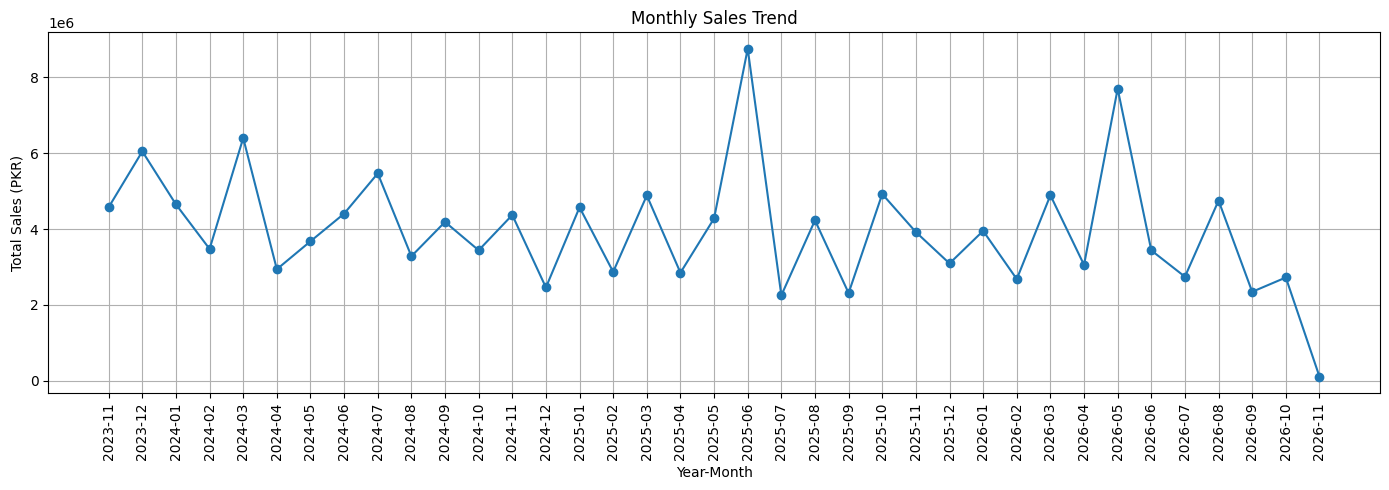

In [ ]:
plt.figure(figsize=(14, 5))

plt.plot(
    monthly_sales_df["year"].astype(str) + "-" +
    monthly_sales_df["month"].astype(str).str.zfill(2),
    monthly_sales_df["total_sales"],
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Year-Month")
plt.ylabel("Total Sales (PKR)")
plt.xticks(rotation=90)
plt.grid(True)
plt.tight_layout()
plt.show()

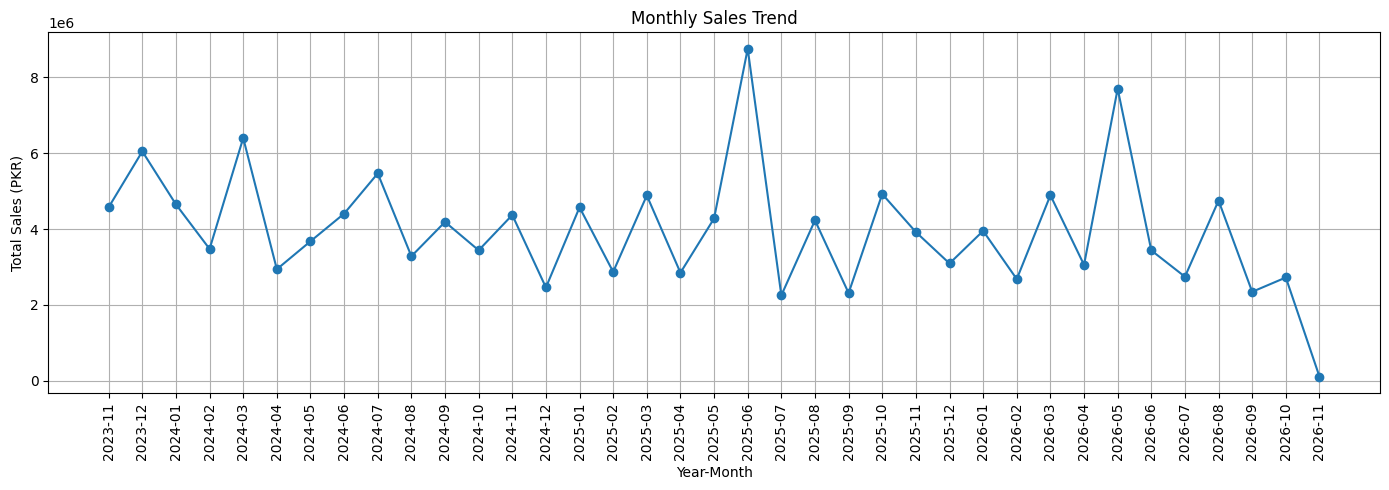

Monthly records: 37
Total sales: 146686462.33

warehouse.dim_product


/tmp/ipykernel_653/373291113.py:29: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  columns = pd.read_sql_query(


,column_name,data_type
0,product_key,bigint
1,source_system,character varying
2,source_product_id,integer
3,product_name,character varying
4,category,character varying



warehouse.dim_location


/tmp/ipykernel_653/373291113.py:29: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  columns = pd.read_sql_query(


,column_name,data_type
0,location_key,bigint
1,city,character varying
2,region,character varying
3,country,character varying


... (2 outputs left out)

,column_name,data_type
0,date_key,bigint
1,full_date,date
2,day_number,integer
3,month_number,integer
4,month_name,character varying
5,quarter_number,integer
6,year_number,integer



warehouse.fact_sales


/tmp/ipykernel_653/373291113.py:29: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  columns = pd.read_sql_query(


,column_name,data_type
0,sales_fact_key,bigint
1,source_system,character varying
2,source_line_id,integer
3,transaction_id,integer
4,date_key,bigint
5,product_key,bigint
6,location_key,bigint
7,quantity,integer
8,unit_price,numeric
9,sales_amount,numeric


In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))
plt.plot(
    monthly_sales_df["year"].astype(str) + "-" +
    monthly_sales_df["month"].astype(str).str.zfill(2),
    monthly_sales_df["total_sales"],
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Year-Month")
plt.ylabel("Total Sales (PKR)")
plt.xticks(rotation=90)
plt.grid(True)
plt.tight_layout()
plt.show()

print("Monthly records:", len(monthly_sales_df))
print("Total sales:", monthly_sales_df["total_sales"].sum())

for table in [
    "warehouse.dim_product",
    "warehouse.dim_location",
    "warehouse.dim_date",
    "warehouse.fact_sales"
]:
    print(f"\n{table}")
    columns = pd.read_sql_query(
        f"SELECT column_name, data_type FROM information_schema.columns "
        f"WHERE table_schema = 'warehouse' AND table_name = '{table.split('.')[-1]}' "
        f"ORDER BY ordinal_position",
        sales_conn
    )
    display(columns)


Q11 - Regional Sales Contribution


/tmp/ipykernel_653/3466212326.py:129: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  results[title] = pd.read_sql_query(query, sales_conn)


,region,total_sales,contribution_percentage
0,North,66021347.90,45.01
1,Central,42455136.56,28.94
2,South,22259684.41,15.18
3,West,15950293.46,10.87



Q13 - Monthly Sales with Three-Month Rolling Average


/tmp/ipykernel_653/3466212326.py:129: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  results[title] = pd.read_sql_query(query, sales_conn)


,year,month,month_name,monthly_sales,rolling_average
0,2023,11,November,4574700.30,4574700.30
1,2023,12,December,6044298.56,5309499.43
2,2024,1,January,4648068.99,5089022.62
3,2024,2,February,3475095.97,4722487.84
4,2024,3,March,6395850.76,4839671.91
5,2024,4,April,2941063.34,4270670.02
6,2024,5,May,3677164.73,4338026.28
7,2024,6,June,4404775.72,3674334.60
8,2024,7,July,5464233.88,4515391.44
9,2024,8,August,3283465.77,4384158.46


... (5 outputs left out)

,category,total_sales,total_units,average_selling_price
0,Clothing,30469439.82,1149,26518.22
1,Furniture,42757709.43,1638,26103.61
2,Electronics,33017346.13,1482,22278.91
3,Food,40441966.95,2356,17165.52


/tmp/ipykernel_653/3466212326.py:129: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  results[title] = pd.read_sql_query(query, sales_conn)



Q19 - Monthly Sales, Units and Growth


,year,month,month_name,monthly_sales,monthly_units,sales_growth_percentage
0,2023,11,November,4574700.30,230,NaN
1,2023,12,December,6044298.56,276,32.12
2,2024,1,January,4648068.99,178,-23.10
3,2024,2,February,3475095.97,146,-25.24
4,2024,3,March,6395850.76,310,84.05
5,2024,4,April,2941063.34,126,-54.02
6,2024,5,May,3677164.73,156,25.03
7,2024,6,June,4404775.72,208,19.79
8,2024,7,July,5464233.88,256,24.05
9,2024,8,August,3283465.77,148,-39.91


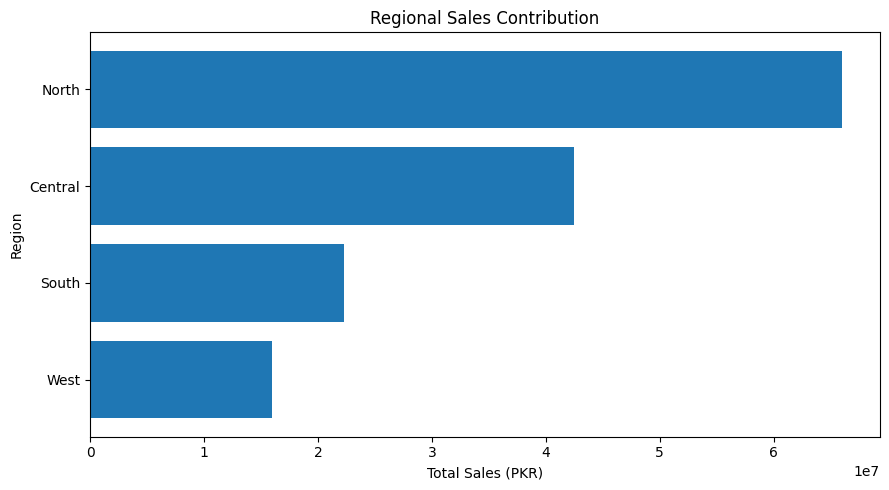

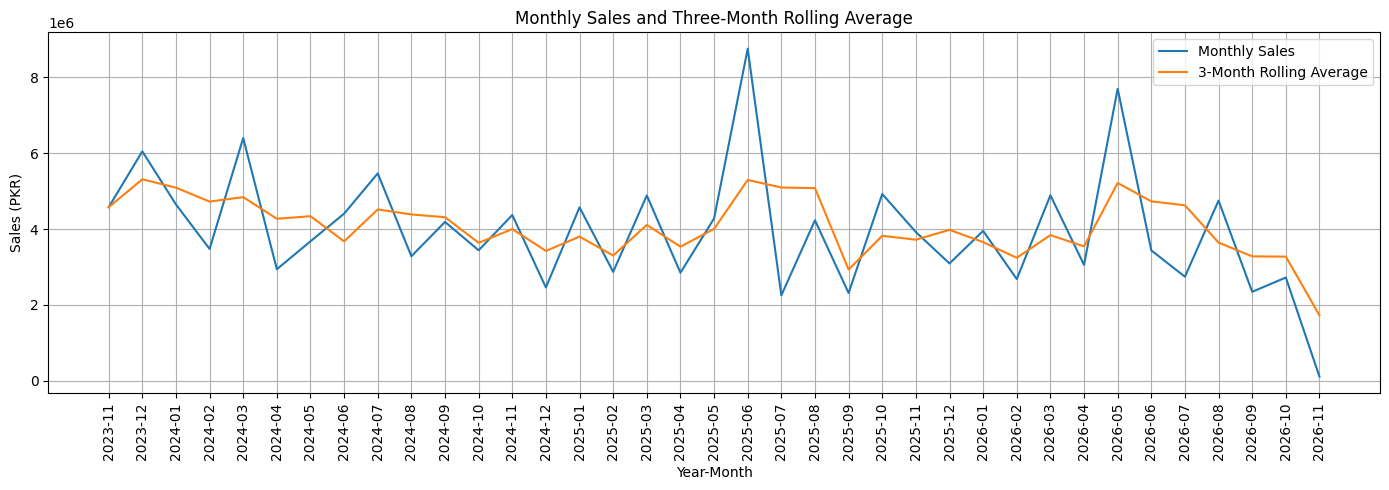

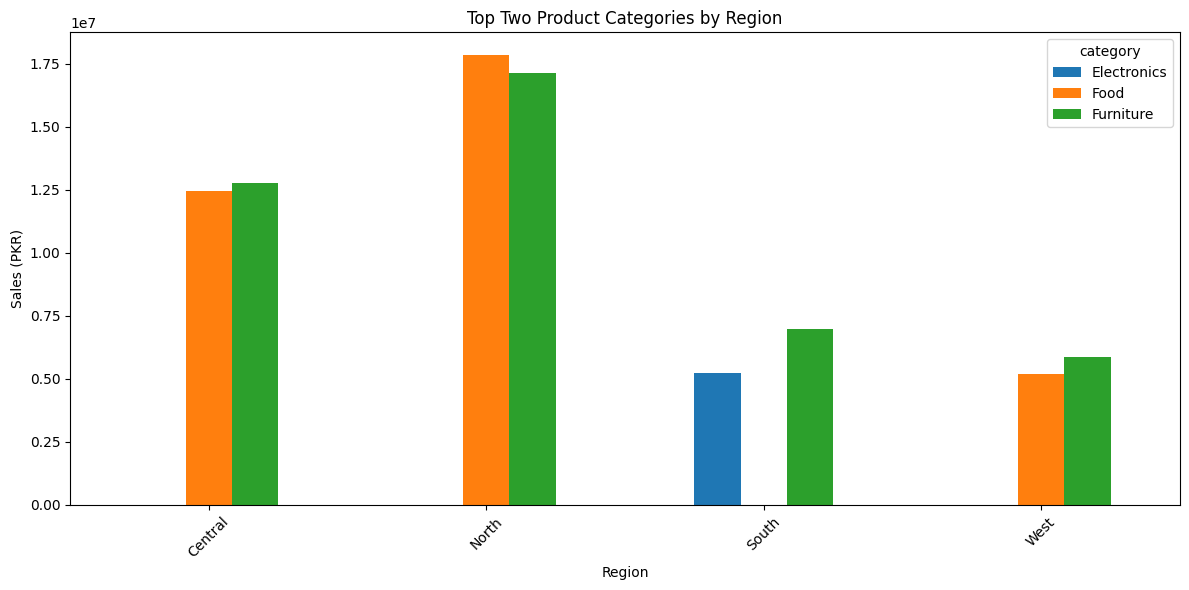

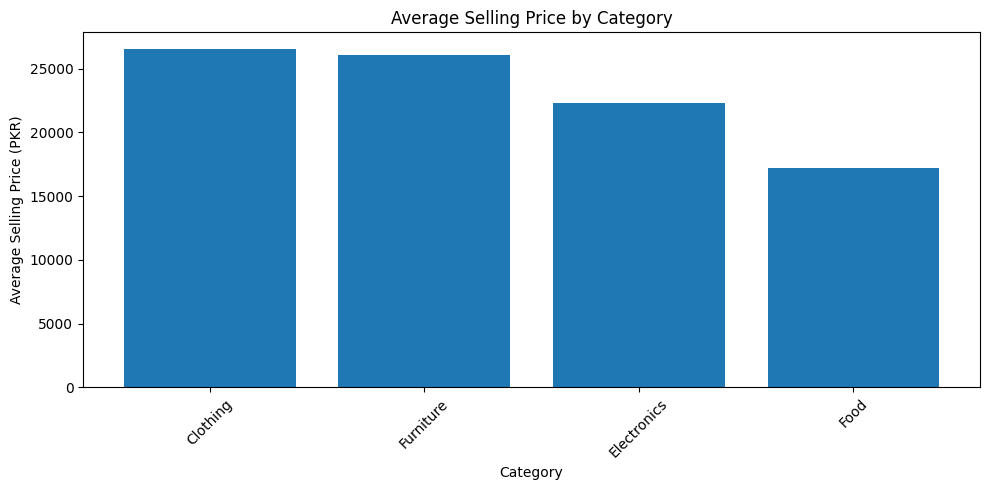

In [ ]:

queries = {
    "Q11 - Regional Sales Contribution": """
        SELECT
            l.region,
            SUM(f.sales_amount) AS total_sales,
            ROUND(
                100.0 * SUM(f.sales_amount) /
                NULLIF(SUM(SUM(f.sales_amount)) OVER (), 0), 2
            ) AS contribution_percentage
        FROM warehouse.fact_sales f
        JOIN warehouse.dim_location l
            ON f.location_key = l.location_key
        GROUP BY l.region
        ORDER BY total_sales DESC;
    """,

    "Q13 - Monthly Sales with Three-Month Rolling Average": """
        WITH monthly AS (
            SELECT
                d.year_number,
                d.month_number,
                d.month_name,
                SUM(f.sales_amount) AS monthly_sales
            FROM warehouse.fact_sales f
            JOIN warehouse.dim_date d
                ON f.date_key = d.date_key
            GROUP BY d.year_number, d.month_number, d.month_name
        )
        SELECT
            year_number AS year,
            month_number AS month,
            month_name,
            monthly_sales,
            ROUND(
                AVG(monthly_sales) OVER (
                    ORDER BY year_number, month_number
                    ROWS BETWEEN 2 PRECEDING AND CURRENT ROW
                ), 2
            ) AS rolling_average
        FROM monthly
        ORDER BY year_number, month_number;
    """,

    "Q15 - Top Two Categories in Each Region": """
        WITH category_sales AS (
            SELECT
                l.region,
                p.category,
                SUM(f.sales_amount) AS total_sales
            FROM warehouse.fact_sales f
            JOIN warehouse.dim_location l
                ON f.location_key = l.location_key
            JOIN warehouse.dim_product p
                ON f.product_key = p.product_key
            GROUP BY l.region, p.category
        ),
        ranked AS (
            SELECT
                region,
                category,
                total_sales,
                ROW_NUMBER() OVER (
                    PARTITION BY region
                    ORDER BY total_sales DESC
                ) AS category_rank
            FROM category_sales
        )
        SELECT region, category, total_sales, category_rank
        FROM ranked
        WHERE category_rank <= 2
        ORDER BY region, category_rank;
    """,

    "Q17 - Category Average Selling Price": """
        SELECT
            p.category,
            SUM(f.sales_amount) AS total_sales,
            SUM(f.quantity) AS total_units,
            ROUND(
                SUM(f.sales_amount) /
                NULLIF(SUM(f.quantity), 0), 2
            ) AS average_selling_price
        FROM warehouse.fact_sales f
        JOIN warehouse.dim_product p
            ON f.product_key = p.product_key
        GROUP BY p.category
        ORDER BY average_selling_price DESC;
    """,

    "Q19 - Monthly Sales, Units and Growth": """
        WITH monthly AS (
            SELECT
                d.year_number,
                d.month_number,
                d.month_name,
                SUM(f.sales_amount) AS monthly_sales,
                SUM(f.quantity) AS monthly_units
            FROM warehouse.fact_sales f
            JOIN warehouse.dim_date d
                ON f.date_key = d.date_key
            GROUP BY d.year_number, d.month_number, d.month_name
        ),
        previous_month AS (
            SELECT
                *,
                LAG(monthly_sales) OVER (
                    ORDER BY year_number, month_number
                ) AS previous_sales
            FROM monthly
        )
        SELECT
            year_number AS year,
            month_number AS month,
            month_name,
            monthly_sales,
            monthly_units,
            ROUND(
                100.0 * (monthly_sales - previous_sales) /
                NULLIF(previous_sales, 0), 2
            ) AS sales_growth_percentage
        FROM previous_month
        ORDER BY year_number, month_number;
    """
}

results = {}

for title, query in queries.items():
    results[title] = pd.read_sql_query(query, sales_conn)
    print("\n" + "=" * 65)
    print(title)
    display(results[title])

# Q11: Regional contribution chart
q11 = results["Q11 - Regional Sales Contribution"]

plt.figure(figsize=(9, 5))
plt.barh(q11["region"], q11["total_sales"])
plt.title("Regional Sales Contribution")
plt.xlabel("Total Sales (PKR)")
plt.ylabel("Region")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# Q13: Monthly sales and rolling average
q13 = results["Q13 - Monthly Sales with Three-Month Rolling Average"]
q13["period"] = (
    q13["year"].astype(str) + "-" +
    q13["month"].astype(str).str.zfill(2)
)

plt.figure(figsize=(14, 5))
plt.plot(q13["period"], q13["monthly_sales"], label="Monthly Sales")
plt.plot(q13["period"], q13["rolling_average"], label="3-Month Rolling Average")
plt.title("Monthly Sales and Three-Month Rolling Average")
plt.xlabel("Year-Month")
plt.ylabel("Sales (PKR)")
plt.xticks(rotation=90)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Q15: Top two categories by region
q15 = results["Q15 - Top Two Categories in Each Region"]
q15_pivot = q15.pivot(
    index="region",
    columns="category",
    values="total_sales"
)

q15_pivot.plot(kind="bar", figsize=(12, 6))
plt.title("Top Two Product Categories by Region")
plt.xlabel("Region")
plt.ylabel("Sales (PKR)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Q17: Average selling price by category
q17 = results["Q17 - Category Average Selling Price"]

plt.figure(figsize=(10, 5))
plt.bar(q17["category"], q17["average_selling_price"])
plt.title("Average Selling Price by Category")
plt.xlabel("Category")
plt.ylabel("Average Selling Price (PKR)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



Practical 10 Queries


Q1 - Sales vs Units by Category


/tmp/ipykernel_653/2348840150.py:195: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  results_p10[title] = pd.read_sql_query(query, sales_conn)


,category,total_sales,total_units
0,Furniture,42757709.43,1638
1,Food,40441966.95,2356
2,Electronics,33017346.13,1482
3,Clothing,30469439.82,1149



Q7 - Category Ranking Change Over Time


/tmp/ipykernel_653/2348840150.py:195: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  results_p10[title] = pd.read_sql_query(query, sales_conn)


,year,month,category,monthly_sales,category_rank
0,2023,11,Food,1903141.98,1
1,2023,11,Furniture,962000.62,2
2,2023,11,Electronics,945437.78,3
3,2023,11,Clothing,764119.92,4
4,2023,12,Clothing,2058132.11,1
...,...,...,...,...,...
140,2026,10,Electronics,1086033.32,1
141,2026,10,Food,788217.00,2
142,2026,10,Clothing,530996.76,3
143,2026,10,Furniture,318568.48,4


... (8 outputs left out)

,year,month,category,market_share_percentage,share_change_percentage_points
0,2023,11,Clothing,16.70,NaN
1,2023,11,Electronics,20.67,NaN
2,2023,11,Food,41.60,NaN
3,2023,11,Furniture,21.03,NaN
4,2023,12,Clothing,34.05,17.35
...,...,...,...,...,...
140,2026,10,Clothing,19.49,4.11
141,2026,10,Electronics,39.87,6.23
142,2026,10,Food,28.94,19.59
143,2026,10,Furniture,11.70,-29.92


/tmp/ipykernel_653/2348840150.py:195: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  results_p10[title] = pd.read_sql_query(query, sales_conn)



Q20 - Cross-Region Performance Imbalance


,category,best_region,best_region_sales,worst_region,worst_region_sales,performance_gap
0,Clothing,North,15665417.57,West,2237776.50,13427641.07
1,Food,North,17848228.62,South,4945348.61,12902880.01
2,Electronics,North,15375126.62,West,2629151.41,12745975.21
3,Furniture,North,17132575.09,West,5879564.69,11253010.40


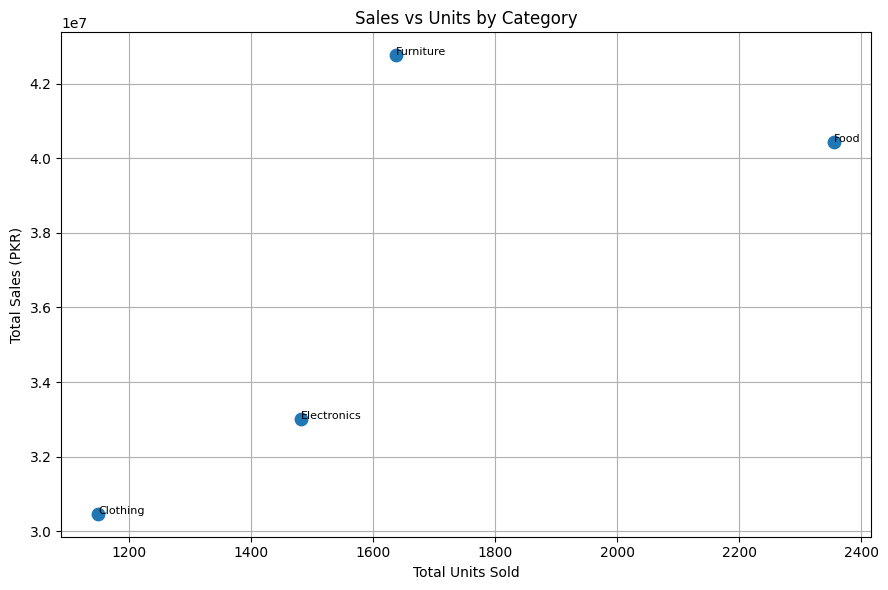

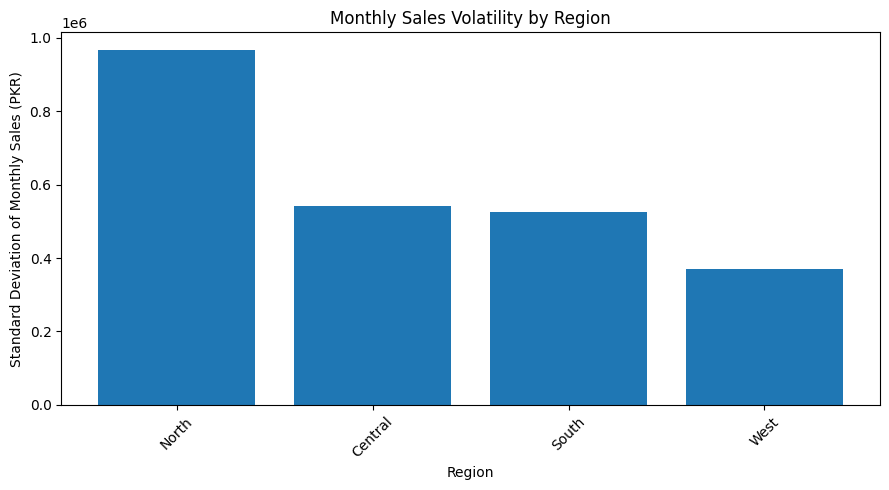

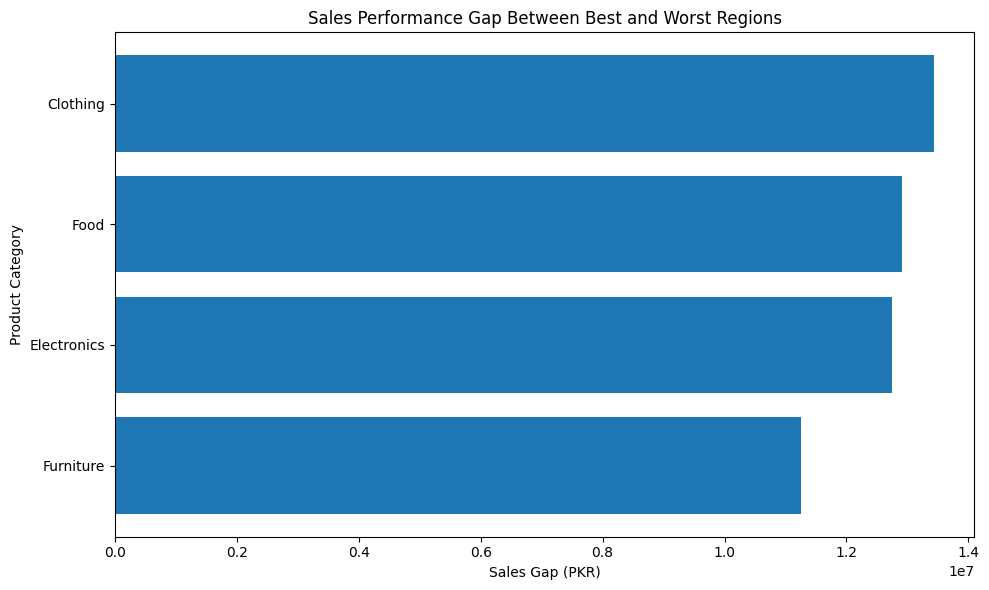

In [ ]:

queries_p10 = {
    "Q1 - Sales vs Units by Category": """
        SELECT
            p.category,
            SUM(f.sales_amount) AS total_sales,
            SUM(f.quantity) AS total_units
        FROM warehouse.fact_sales f
        JOIN warehouse.dim_product p
            ON f.product_key = p.product_key
        GROUP BY p.category
        ORDER BY total_sales DESC;
    """,

    "Q7 - Category Ranking Change Over Time": """
        WITH monthly_category AS (
            SELECT
                d.year_number AS year,
                d.month_number AS month,
                p.category,
                SUM(f.sales_amount) AS monthly_sales
            FROM warehouse.fact_sales f
            JOIN warehouse.dim_date d
                ON f.date_key = d.date_key
            JOIN warehouse.dim_product p
                ON f.product_key = p.product_key
            GROUP BY d.year_number, d.month_number, p.category
        )
        SELECT
            year,
            month,
            category,
            monthly_sales,
            RANK() OVER (
                PARTITION BY year, month
                ORDER BY monthly_sales DESC
            ) AS category_rank
        FROM monthly_category
        ORDER BY year, month, category_rank;
    """,

    "Q10 - Category Contribution to Yearly Sales": """
        WITH category_year AS (
            SELECT
                d.year_number AS year,
                p.category,
                SUM(f.sales_amount) AS category_sales
            FROM warehouse.fact_sales f
            JOIN warehouse.dim_date d
                ON f.date_key = d.date_key
            JOIN warehouse.dim_product p
                ON f.product_key = p.product_key
            GROUP BY d.year_number, p.category
        )
        SELECT
            year,
            category,
            category_sales,
            SUM(category_sales) OVER (
                PARTITION BY year
            ) AS yearly_total
        FROM category_year
        ORDER BY year, category_sales DESC;
    """,

    "Q17 - Regional Sales Volatility": """
        WITH monthly_region AS (
            SELECT
                d.year_number AS year,
                d.month_number AS month,
                l.region,
                SUM(f.sales_amount) AS monthly_sales
            FROM warehouse.fact_sales f
            JOIN warehouse.dim_date d
                ON f.date_key = d.date_key
            JOIN warehouse.dim_location l
                ON f.location_key = l.location_key
            GROUP BY d.year_number, d.month_number, l.region
        )
        SELECT
            year,
            month,
            region,
            monthly_sales,
            ROUND(
                STDDEV_SAMP(monthly_sales) OVER (
                    PARTITION BY region
                ), 2
            ) AS sales_variability
        FROM monthly_region
        ORDER BY region, year, month;
    """,

    "Q18 - Market Share Gain and Loss": """
        WITH monthly_category AS (
            SELECT
                d.year_number AS year,
                d.month_number AS month,
                p.category,
                SUM(f.sales_amount) AS category_sales
            FROM warehouse.fact_sales f
            JOIN warehouse.dim_date d
                ON f.date_key = d.date_key
            JOIN warehouse.dim_product p
                ON f.product_key = p.product_key
            GROUP BY d.year_number, d.month_number, p.category
        ),
        shares AS (
            SELECT
                year,
                month,
                category,
                category_sales,
                100.0 * category_sales /
                    NULLIF(SUM(category_sales) OVER (
                        PARTITION BY year, month
                    ), 0) AS market_share
            FROM monthly_category
        ),
        changes AS (
            SELECT
                *,
                LAG(market_share) OVER (
                    PARTITION BY category
                    ORDER BY year, month
                ) AS previous_share
            FROM shares
        )
        SELECT
            year,
            month,
            category,
            ROUND(market_share, 2) AS market_share_percentage,
            ROUND(market_share - previous_share, 2)
                AS share_change_percentage_points
        FROM changes
        ORDER BY year, month, category;
    """,

    "Q20 - Cross-Region Performance Imbalance": """
        WITH regional_category AS (
            SELECT
                p.category,
                l.region,
                SUM(f.sales_amount) AS region_sales
            FROM warehouse.fact_sales f
            JOIN warehouse.dim_product p
                ON f.product_key = p.product_key
            JOIN warehouse.dim_location l
                ON f.location_key = l.location_key
            GROUP BY p.category, l.region
        ),
        ranked AS (
            SELECT
                category,
                region,
                region_sales,
                ROW_NUMBER() OVER (
                    PARTITION BY category
                    ORDER BY region_sales DESC, region
                ) AS best_rank,
                ROW_NUMBER() OVER (
                    PARTITION BY category
                    ORDER BY region_sales ASC, region
                ) AS worst_rank
            FROM regional_category
        )
        SELECT
            category,
            MAX(region) FILTER (
                WHERE best_rank = 1
            ) AS best_region,
            MAX(region_sales) FILTER (
                WHERE best_rank = 1
            ) AS best_region_sales,
            MAX(region) FILTER (
                WHERE worst_rank = 1
            ) AS worst_region,
            MAX(region_sales) FILTER (
                WHERE worst_rank = 1
            ) AS worst_region_sales,
            MAX(region_sales) FILTER (
                WHERE best_rank = 1
            ) - MAX(region_sales) FILTER (
                WHERE worst_rank = 1
            ) AS performance_gap
        FROM ranked
        GROUP BY category
        ORDER BY performance_gap DESC;
    """
}

results_p10 = {}

for title, query in queries_p10.items():
    results_p10[title] = pd.read_sql_query(query, sales_conn)
    print("\n" + "=" * 70)
    print(title)
    display(results_p10[title])

# Q1: Sales vs Units by Category - Scatter Chart
q1 = results_p10["Q1 - Sales vs Units by Category"]

plt.figure(figsize=(9, 6))
plt.scatter(q1["total_units"], q1["total_sales"], s=80)

for _, row in q1.iterrows():
    plt.annotate(
        str(row["category"]),
        (row["total_units"], row["total_sales"]),
        fontsize=8
    )

plt.title("Sales vs Units by Category")
plt.xlabel("Total Units Sold")
plt.ylabel("Total Sales (PKR)")
plt.grid(True)
plt.tight_layout()
plt.show()


# Q17: Regional Sales Volatility - Bar Chart
q17 = results_p10["Q17 - Regional Sales Volatility"]

q17_chart = (
    q17[["region", "sales_variability"]]
    .drop_duplicates()
    .sort_values("sales_variability", ascending=False)
)

plt.figure(figsize=(9, 5))
plt.bar(q17_chart["region"], q17_chart["sales_variability"])
plt.title("Monthly Sales Volatility by Region")
plt.xlabel("Region")
plt.ylabel("Standard Deviation of Monthly Sales (PKR)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# Q20: Cross-Region Performance Imbalance - Bar Chart
q20 = results_p10["Q20 - Cross-Region Performance Imbalance"]

plt.figure(figsize=(10, 6))
plt.barh(q20["category"], q20["performance_gap"])
plt.title("Sales Performance Gap Between Best and Worst Regions")
plt.xlabel("Sales Gap (PKR)")
plt.ylabel("Product Category")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()




In [ ]:

import os
import re

Q10_PATH = os.path.join(PROJECT_PATH, "Q10_SQL_Analysis")
RESULTS_PATH = os.path.join(Q10_PATH, "query_results")

os.makedirs(RESULTS_PATH, exist_ok=True)

q10_queries = {
    "P9_Q3_Monthly_Sales_Trend": monthly_sales_query,
    "P9_Q11_Regional_Contribution": queries["Q11 - Regional Sales Contribution"],
    "P9_Q13_Rolling_Average": queries["Q13 - Monthly Sales with Three-Month Rolling Average"],
    "P9_Q15_Top_Categories_Region": queries["Q15 - Top Two Categories in Each Region"],
    "P9_Q17_Category_ASP": queries["Q17 - Category Average Selling Price"],
    "P9_Q19_Monthly_Growth": queries["Q19 - Monthly Sales, Units and Growth"],
    "P10_Q1_Sales_Units_Category": queries_p10["Q1 - Sales vs Units by Category"],
    "P10_Q7_Category_Ranking": queries_p10["Q7 - Category Ranking Change Over Time"],
    "P10_Q10_Category_Yearly_Contribution": queries_p10["Q10 - Category Contribution to Yearly Sales"],
    "P10_Q17_Regional_Volatility": queries_p10["Q17 - Regional Sales Volatility"],
    "P10_Q18_Market_Share_Change": queries_p10["Q18 - Market Share Gain and Loss"],
    "P10_Q20_Regional_Imbalance": queries_p10["Q20 - Cross-Region Performance Imbalance"]
}

q10_results = {
    "P9_Q3_Monthly_Sales_Trend": monthly_sales_df,
    "P9_Q11_Regional_Contribution": results["Q11 - Regional Sales Contribution"],
    "P9_Q13_Rolling_Average": results["Q13 - Monthly Sales with Three-Month Rolling Average"],
    "P9_Q15_Top_Categories_Region": results["Q15 - Top Two Categories in Each Region"],
    "P9_Q17_Category_ASP": results["Q17 - Category Average Selling Price"],
    "P9_Q19_Monthly_Growth": results["Q19 - Monthly Sales, Units and Growth"],
    "P10_Q1_Sales_Units_Category": results_p10["Q1 - Sales vs Units by Category"],
    "P10_Q7_Category_Ranking": results_p10["Q7 - Category Ranking Change Over Time"],
    "P10_Q10_Category_Yearly_Contribution": results_p10["Q10 - Category Contribution to Yearly Sales"],
    "P10_Q17_Regional_Volatility": results_p10["Q17 - Regional Sales Volatility"],
    "P10_Q18_Market_Share_Change": results_p10["Q18 - Market Share Gain and Loss"],
    "P10_Q20_Regional_Imbalance": results_p10["Q20 - Cross-Region Performance Imbalance"]
}

documentation = [
    ["P9 Q3", "Monthly sales trend", "One row per month", "Line chart", "Shows changes in sales over time."],
    ["P9 Q11", "Regional sales contribution", "One row per region", "Horizontal bar chart", "Identifies regions contributing the most revenue."],
    ["P9 Q13", "Three-month rolling average", "One row per month", "Line chart", "Smooths short-term fluctuations in monthly sales."],
    ["P9 Q15", "Top two categories per region", "Up to two rows per region", "Grouped bar chart", "Identifies leading categories within each region."],
    ["P9 Q17", "Category average selling price", "One row per category", "Column chart", "Compares average revenue per unit across categories."],
    ["P9 Q19", "Monthly sales, units and growth", "One row per month", "Combo chart", "Compares revenue, volume and month-over-month growth."],
    ["P10 Q1", "Sales versus units by category", "One row per category", "Scatter chart", "Examines the relationship between sales value and units."],
    ["P10 Q7", "Category ranking over time", "One row per month and category", "Ribbon-style line chart", "Tracks changes in category rankings."],
    ["P10 Q10", "Category contribution to yearly sales", "One row per year and category", "Waterfall-style chart", "Shows category contributions to annual sales."],
    ["P10 Q17", "Regional sales volatility", "One row per month and region", "Bar chart", "Compares monthly sales variability between regions."],
    ["P10 Q18", "Market share gain and loss", "One row per month and category", "Multi-line chart", "Tracks changes in category market share."],
    ["P10 Q20", "Cross-region performance imbalance", "One row per category", "Horizontal bar chart", "Measures the sales gap between the best and worst regions."]
]

for name, df in q10_results.items():
    df.to_csv(
        os.path.join(RESULTS_PATH, name + ".csv"),
        index=False
    )

with open(os.path.join(Q10_PATH, "Q10_Combined_Queries.sql"), "w") as file:
    for name, query in q10_queries.items():
        file.write(f"\n-- {name}\n")
        file.write(query.strip() + ";\n")

documentation_df = pd.DataFrame(
    documentation,
    columns=[
        "Task",
        "Analysis",
        "Output Grain",
        "Visualization",
        "Business Interpretation"
    ]
)

documentation_df.to_csv(
    os.path.join(Q10_PATH, "Q10_Query_Documentation.csv"),
    index=False
)

print("Q10 evidence saved successfully.")
print("Queries saved:", len(q10_queries))
print("Result CSV files saved:", len(q10_results))
print("Documentation rows:", len(documentation_df))
print("\nFiles:")
for folder, _, files in os.walk(Q10_PATH):
    for filename in files:
        print(os.path.relpath(os.path.join(folder, filename), Q10_PATH))


Q10 evidence saved successfully.
Queries saved: 12
Result CSV files saved: 12
Documentation rows: 12

Files:
Q10_Combined_Queries.sql
Q10_Query_Documentation.csv
query_results/P9_Q3_Monthly_Sales_Trend.csv
query_results/P9_Q11_Regional_Contribution.csv
query_results/P9_Q13_Rolling_Average.csv
query_results/P9_Q15_Top_Categories_Region.csv
query_results/P9_Q17_Category_ASP.csv
query_results/P9_Q19_Monthly_Growth.csv
query_results/P10_Q1_Sales_Units_Category.csv
query_results/P10_Q7_Category_Ranking.csv
query_results/P10_Q10_Category_Yearly_Contribution.csv
query_results/P10_Q17_Regional_Volatility.csv
query_results/P10_Q18_Market_Share_Change.csv
query_results/P10_Q20_Regional_Imbalance.csv



# Q10: Analytic SQL Portfolio (CLO4)

## 1. Objective

The objective of this task is to use analytical SQL queries to extract, aggregate, compare, and investigate business performance from the centralized data warehouse.

The analysis uses the warehouse star schema containing:

- `warehouse.fact_sales`
- `warehouse.dim_date`
- `warehouse.dim_product`
- `warehouse.dim_location`

The queries were adapted to PostgreSQL syntax and use aggregation, joins, common table expressions, ranking functions, window functions, and analytical calculations.

## 2. Selected Practical Exercises

The project rubric requires 12 analytic SQL queries: six from Practical 9 and six from Practical 10.

The selected exercises cover all the required analytical areas.

### Practical 9: Basic and Advanced Sales Analysis

| Practical Task | Analysis | Output Grain | Visualization |
|---|---|---|---|
| Q3 | Monthly Sales Trend | One row per month | Line Chart |
| Q11 | Regional Sales Contribution | One row per region | Horizontal Bar Chart |
| Q13 | Three-Month Rolling Average | One row per month | Line Chart |
| Q15 | Top Two Categories per Region | Up to two rows per region | Grouped Bar Chart |
| Q17 | Category Average Selling Price | One row per category | Column Chart |
| Q19 | Monthly Sales, Units and Growth | One row per month | Combo Chart |

### Practical 10: Diagnostic Analytics

| Practical Task | Analysis | Output Grain | Visualization |
|---|---|---|---|
| Q1 | Sales vs Units by Category | One row per category | Scatter Chart |
| Q7 | Category Ranking Change Over Time | One row per month and category | Ribbon-Style Chart |
| Q10 | Category Contribution to Yearly Sales | One row per year and category | Waterfall Chart |
| Q17 | Regional Sales Volatility | One row per month and region | Bar Chart |
| Q18 | Market Share Gain and Loss | One row per month and category | Multi-Line Chart |
| Q20 | Cross-Region Performance Imbalance | One row per category | Horizontal Bar Chart |

## 3. Analytical Techniques Used

The selected queries demonstrate the following techniques:

1. **Aggregation:** SUM, AVG and GROUP BY for calculating sales, quantities and category performance.
2. **Window functions:** LAG, RANK, ROW_NUMBER and window-based calculations.
3. **Rolling analysis:** Three-month moving averages for identifying sales trends.
4. **Growth analysis:** Month-over-month sales growth using previous-period values.
5. **Contribution analysis:** Regional and category sales contribution to overall or yearly totals.
6. **Average Selling Price:** Total sales divided by total units, with NULLIF to prevent division by zero.
7. **Ranking:** Identifying leading categories within each region and tracking rankings over time.
8. **Volatility analysis:** Standard deviation of monthly regional sales.
9. **Market share analysis:** Monthly category market share and changes in percentage points.
10. **Diagnostic investigation:** Comparing the best- and worst-performing regions for each product category.

## 4. Query Results and Visualizations

All 12 selected SQL queries were executed successfully.

Their result tables were displayed in Google Colab and exported as CSV files.

The corresponding charts were generated from the query results to support management analysis.

The result sets and SQL statements are preserved in the project Google Drive folder.

## 5. Evidence and File Organization

The Q10 evidence is stored in:

`CT472_Project/Q10_SQL_Analysis/`

The folder contains:

- `Q10_Combined_Queries.sql`: Combined SQL statements for the 12 selected queries.
- `Q10_Query_Documentation.csv`: Task numbers, analysis descriptions, output grains, chart types and business interpretation descriptions.
- `query_results/`: Twelve CSV files containing the corresponding query results.

## 6. Business Value of the Analysis

The analytical query portfolio provides management with a structured view of business performance.

- Regional contribution analysis identifies the regions responsible for the largest share of revenue.
- Monthly sales trends and rolling averages help identify changes in performance over time.
- Category ranking analysis identifies leading and declining product categories.
- Average selling price analysis compares revenue generated per unit across categories.
- Sales growth and market share analysis help identify changes in business performance.
- Regional volatility analysis highlights differences in the stability of regional sales.
- Cross-region performance imbalance identifies categories with significant differences between their strongest and weakest regions.

These results support comparison, contribution, trend analysis, operational investigation and management decision-making.

## 7. Scope and Limitations

The project rubric requires six selected queries from each practical. Therefore, this portfolio contains six selected Practical 9 exercises and six selected Practical 10 exercises.

The remaining exercises in the two practical sheets are not represented in this 12-query portfolio.

The analysis is based on synthetic data. Its results demonstrate the analytical SQL techniques and warehouse reporting process but should not be interpreted as actual company performance.

The dataset contains 36 completed historical months from November 2023 through October 2026. November 2026 records belong to a controlled incremental-loading test and should not be treated as a complete historical month.

Some chart presentations require refinement to match their requested visualization types exactly. Result-specific findings and reusable SQL views must also be completed before the Q10 portfolio is considered fully finalized.

## 8. Conclusion

The 12 selected analytical SQL queries demonstrate the use of aggregation and window functions to analyze sales, quantities, contributions, trends, growth, rankings, average selling prices, market share and regional performance.

The queries and their result tables have been saved as project evidence, and corresponding visualizations have been generated.

The remaining work is to finalize reusable SQL views, refine the identified charts, and document specific findings from the actual query outputs.


In [ ]:

view_names = {
    "P9_Q3_Monthly_Sales_Trend": "vw_q10_p9_monthly_sales",
    "P9_Q11_Regional_Contribution": "vw_q10_p9_regional_contribution",
    "P9_Q13_Rolling_Average": "vw_q10_p9_rolling_average",
    "P9_Q15_Top_Categories_Region": "vw_q10_p9_top_categories_region",
    "P9_Q17_Category_ASP": "vw_q10_p9_category_asp",
    "P9_Q19_Monthly_Growth": "vw_q10_p9_monthly_growth",
    "P10_Q1_Sales_Units_Category": "vw_q10_p10_sales_units_category",
    "P10_Q7_Category_Ranking": "vw_q10_p10_category_ranking",
    "P10_Q10_Category_Yearly_Contribution": "vw_q10_p10_yearly_contribution",
    "P10_Q17_Regional_Volatility": "vw_q10_p10_regional_volatility",
    "P10_Q18_Market_Share_Change": "vw_q10_p10_market_share_change",
    "P10_Q20_Regional_Imbalance": "vw_q10_p10_regional_imbalance"
}

view_status = []

for query_name, view_name in view_names.items():
    query = q10_queries[query_name].strip().rstrip(";")

    try:
        sales_cursor.execute(
            f"CREATE OR REPLACE VIEW warehouse.{view_name} AS {query}"
        )
        sales_conn.commit()

        sales_cursor.execute(
            f"SELECT COUNT(*) FROM warehouse.{view_name}"
        )
        row_count = sales_cursor.fetchone()[0]

        view_status.append([view_name, row_count, "PASS"])

    except Exception as e:
        sales_conn.rollback()
        view_status.append([view_name, str(e), "FAIL"])

view_status_df = pd.DataFrame(
    view_status,
    columns=["SQL View", "Rows Returned", "Status"]
)

display(view_status_df)

print("Views created:", sum(x[2] == "PASS" for x in view_status))
print("Views failed:", sum(x[2] == "FAIL" for x in view_status))


,SQL View,Rows Returned,Status
0,vw_q10_p9_monthly_sales,37,PASS
1,vw_q10_p9_regional_contribution,4,PASS
2,vw_q10_p9_rolling_average,37,PASS
3,vw_q10_p9_top_categories_region,8,PASS
4,vw_q10_p9_category_asp,4,PASS
5,vw_q10_p9_monthly_growth,37,PASS
6,vw_q10_p10_sales_units_category,4,PASS
7,vw_q10_p10_category_ranking,145,PASS
8,vw_q10_p10_yearly_contribution,16,PASS
9,vw_q10_p10_regional_volatility,140,PASS


Views created: 12
Views failed: 0


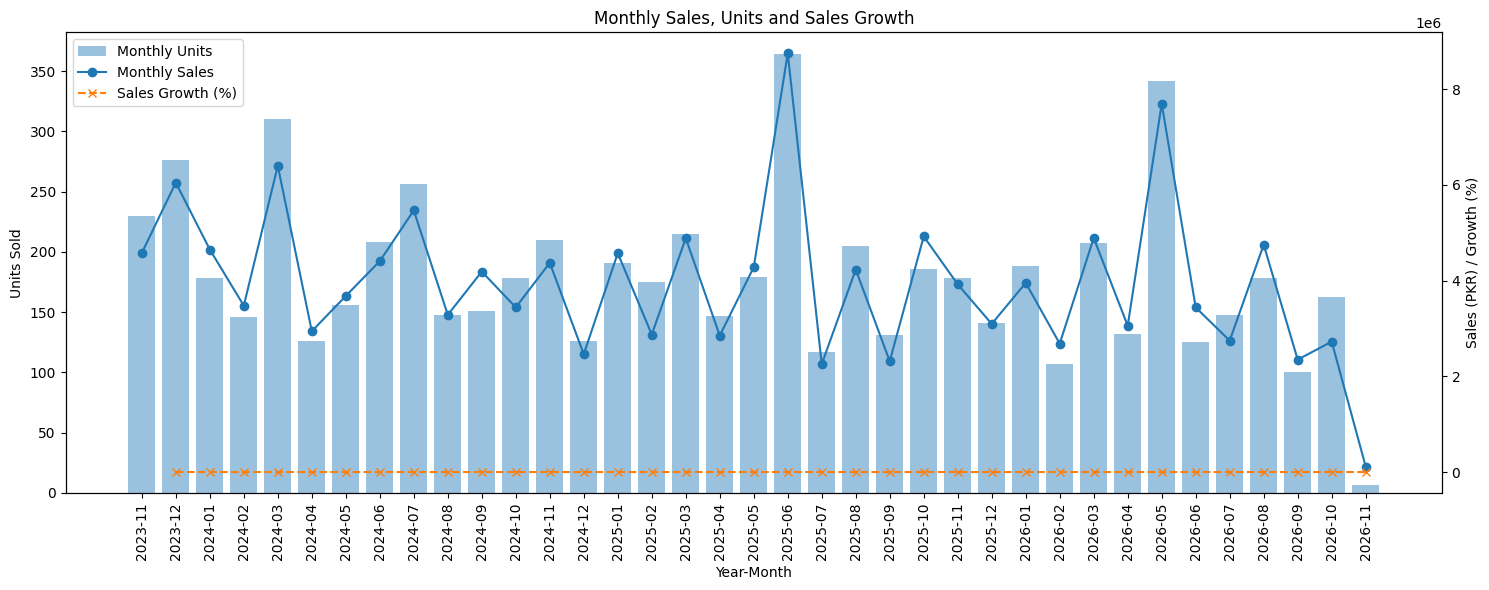

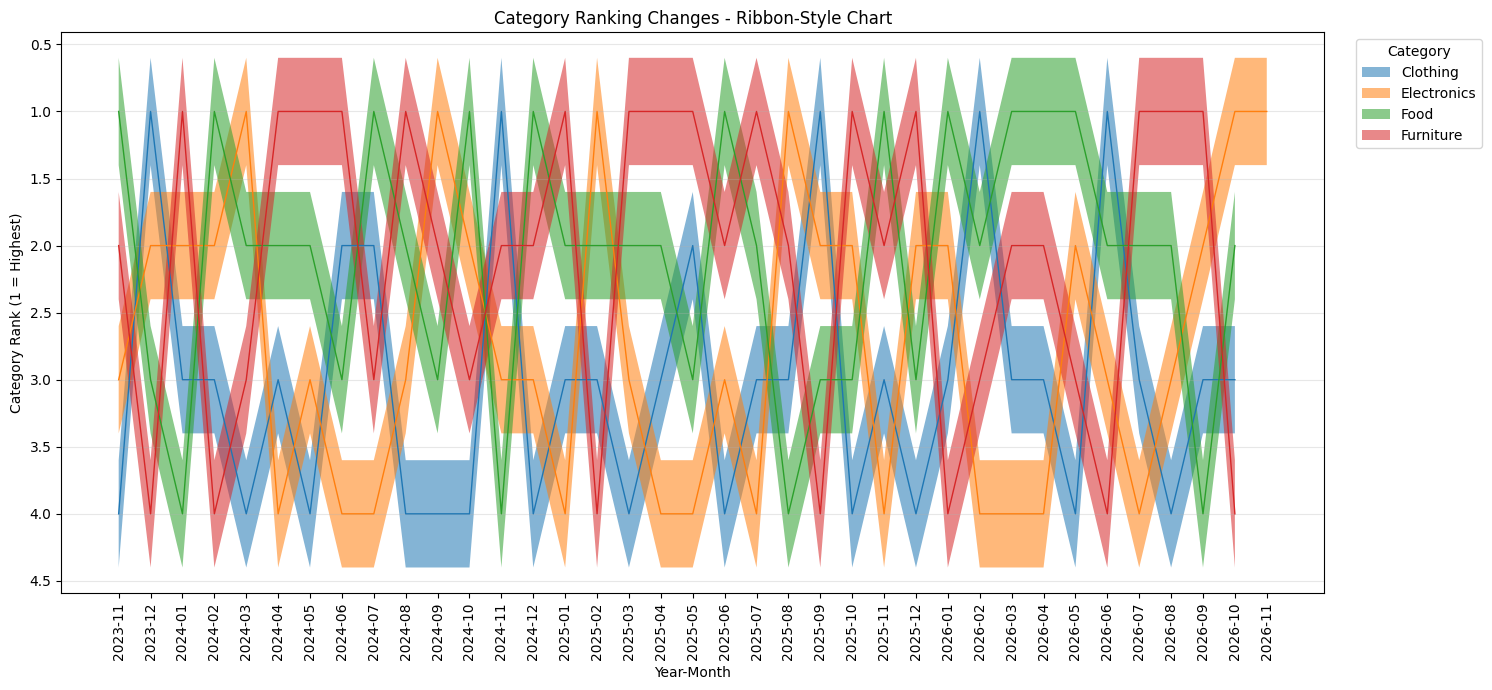

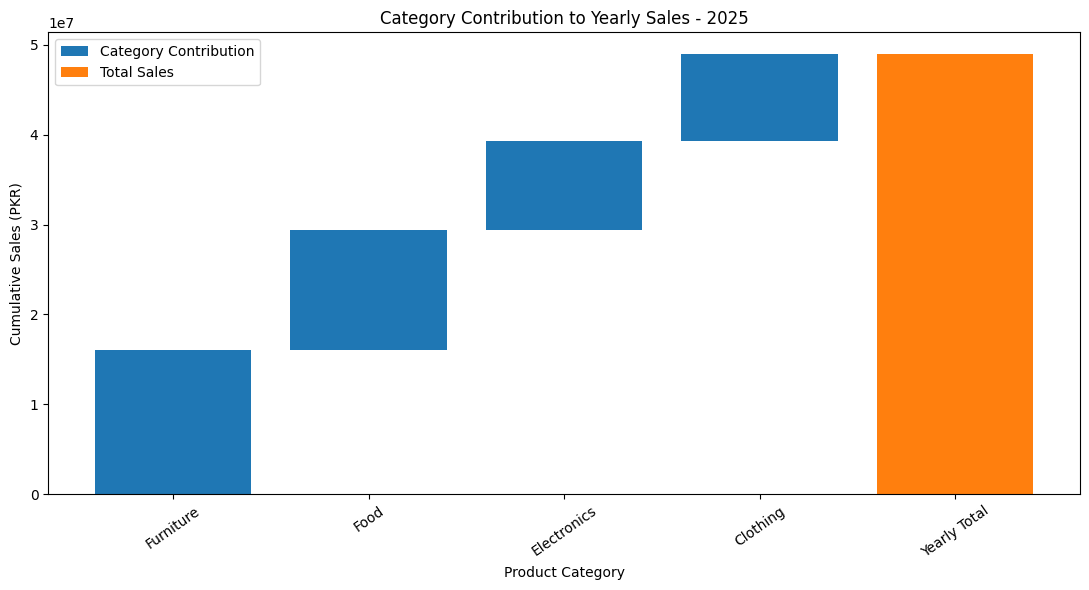

Selected completed year: 2025
Categories: 4
Yearly total sales: 48934202.82


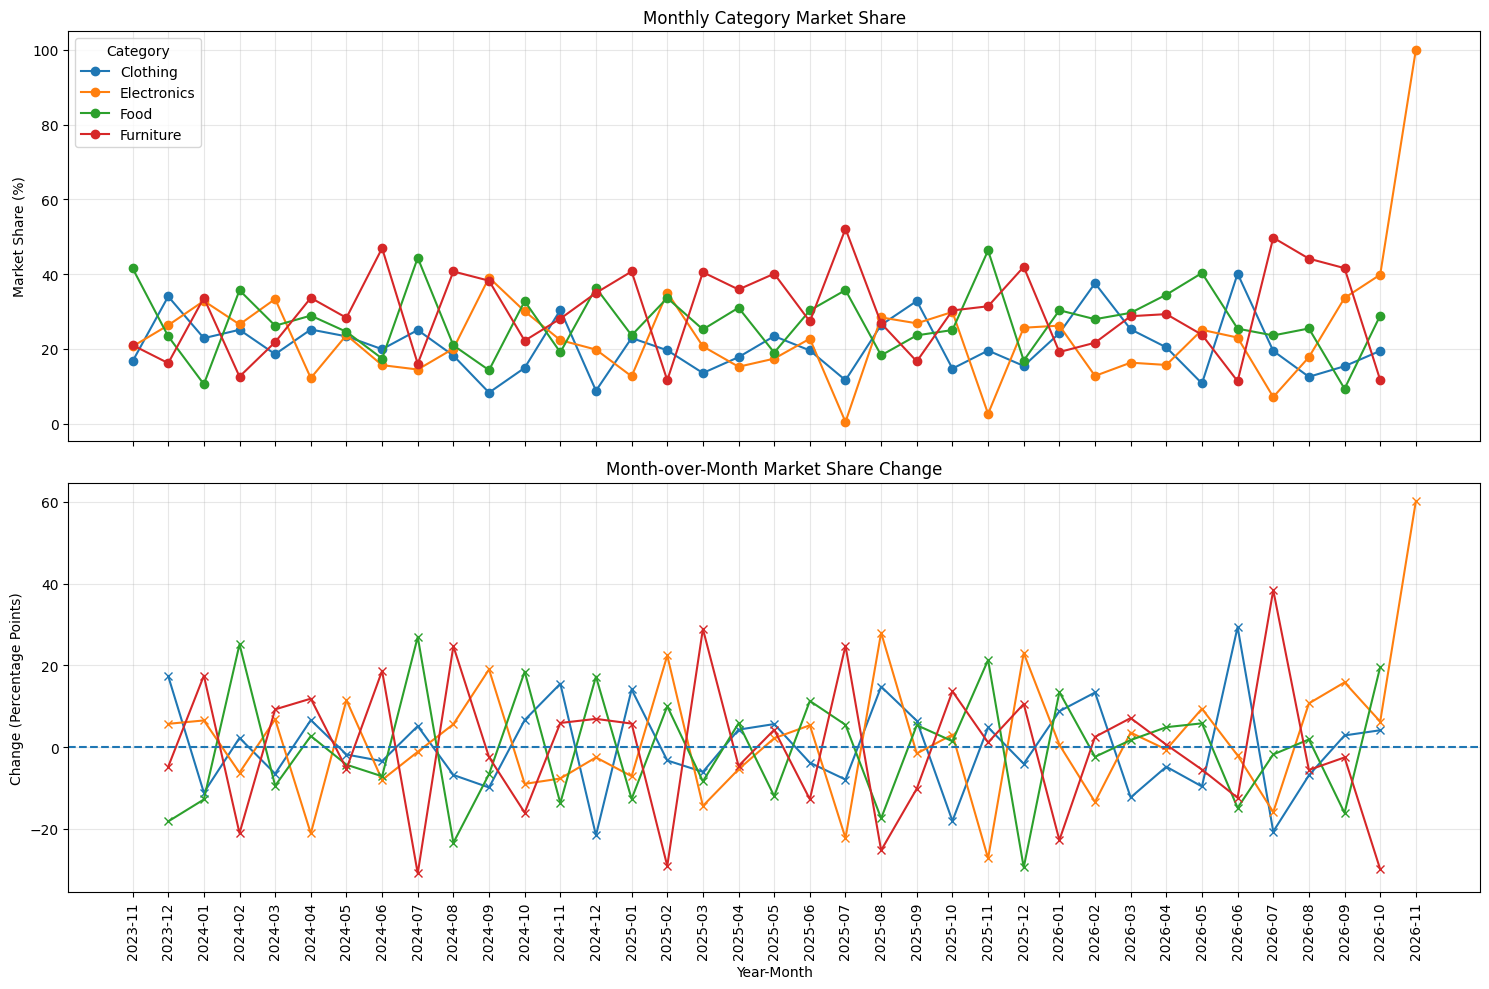

Four refined charts generated successfully.


In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# -----------------------------------------
# P9 Q19: Monthly Sales, Units and Growth
# -----------------------------------------

q19 = results["Q19 - Monthly Sales, Units and Growth"].copy()
q19["period"] = (
    q19["year"].astype(str) + "-" +
    q19["month"].astype(str).str.zfill(2)
)

fig, ax1 = plt.subplots(figsize=(15, 6))

ax1.bar(
    q19["period"],
    q19["monthly_units"],
    alpha=0.45,
    label="Monthly Units"
)
ax1.set_ylabel("Units Sold")
ax1.set_xlabel("Year-Month")

ax2 = ax1.twinx()
ax2.plot(
    q19["period"],
    q19["monthly_sales"],
    marker="o",
    label="Monthly Sales"
)
ax2.plot(
    q19["period"],
    q19["sales_growth_percentage"],
    marker="x",
    linestyle="--",
    label="Sales Growth (%)"
)
ax2.set_ylabel("Sales (PKR) / Growth (%)")

ax1.set_title("Monthly Sales, Units and Sales Growth")
ax1.tick_params(axis="x", rotation=90)

handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(
    handles1 + handles2,
    labels1 + labels2,
    loc="upper left"
)

plt.tight_layout()
plt.show()


# -----------------------------------------
# P10 Q7: Category Ranking Ribbon-Style
# -----------------------------------------

q7 = results_p10[
    "Q7 - Category Ranking Change Over Time"
].copy()

q7["period"] = (
    q7["year"].astype(str) + "-" +
    q7["month"].astype(str).str.zfill(2)
)

q7_pivot = q7.pivot(
    index="period",
    columns="category",
    values="category_rank"
)

fig, ax = plt.subplots(figsize=(15, 7))
x = np.arange(len(q7_pivot.index))

for category in q7_pivot.columns:
    ranks = q7_pivot[category].to_numpy(dtype=float)
    ax.fill_between(
        x,
        ranks - 0.4,
        ranks + 0.4,
        alpha=0.55,
        label=str(category)
    )
    ax.plot(x, ranks, linewidth=1)

ax.set_title("Category Ranking Changes - Ribbon-Style Chart")
ax.set_xlabel("Year-Month")
ax.set_ylabel("Category Rank (1 = Highest)")
ax.set_xticks(x)
ax.set_xticklabels(q7_pivot.index, rotation=90)
ax.invert_yaxis()
ax.legend(title="Category", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# -----------------------------------------
# P10 Q10: Proper Waterfall-Style Chart
# Use completed year 2025
# -----------------------------------------

q10 = results_p10[
    "Q10 - Category Contribution to Yearly Sales"
].copy()

selected_year = 2025
q10_latest = q10[
    q10["year"] == selected_year
].sort_values("category_sales", ascending=False).copy()

if q10_latest.empty:
    raise ValueError("No records found for completed year 2025.")

categories = q10_latest["category"].astype(str).tolist()
values = q10_latest["category_sales"].to_numpy(dtype=float)

cumulative = np.cumsum(values)
previous = np.insert(cumulative[:-1], 0, 0)

fig, ax = plt.subplots(figsize=(11, 6))

ax.bar(
    categories,
    values,
    bottom=previous,
    label="Category Contribution"
)

yearly_total = values.sum()

ax.bar(
    "Yearly Total",
    yearly_total,
    label="Total Sales"
)

ax.set_title(
    f"Category Contribution to Yearly Sales - {selected_year}"
)
ax.set_xlabel("Product Category")
ax.set_ylabel("Cumulative Sales (PKR)")
ax.tick_params(axis="x", rotation=35)
ax.legend()

plt.tight_layout()
plt.show()

print("Selected completed year:", selected_year)
print("Categories:", len(q10_latest))
print("Yearly total sales:", round(yearly_total, 2))


# -----------------------------------------
# P10 Q18: Market Share and Monthly Change
# -----------------------------------------

q18 = results_p10[
    "Q18 - Market Share Gain and Loss"
].copy()

q18["period"] = (
    q18["year"].astype(str) + "-" +
    q18["month"].astype(str).str.zfill(2)
)

share_pivot = q18.pivot(
    index="period",
    columns="category",
    values="market_share_percentage"
)

change_pivot = q18.pivot(
    index="period",
    columns="category",
    values="share_change_percentage_points"
)

fig, (ax1, ax2) = plt.subplots(
    2, 1,
    figsize=(15, 10),
    sharex=True
)

for category in share_pivot.columns:
    ax1.plot(
        share_pivot.index,
        share_pivot[category],
        marker="o",
        label=str(category)
    )

    ax2.plot(
        change_pivot.index,
        change_pivot[category],
        marker="x",
        label=str(category)
    )

ax1.set_title("Monthly Category Market Share")
ax1.set_ylabel("Market Share (%)")
ax1.legend(title="Category")
ax1.grid(True, alpha=0.3)

ax2.set_title("Month-over-Month Market Share Change")
ax2.set_ylabel("Change (Percentage Points)")
ax2.set_xlabel("Year-Month")
ax2.axhline(0, linestyle="--")
ax2.grid(True, alpha=0.3)

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

print("Four refined charts generated successfully.")


In [ ]:
q10_summary = []

for name, df in q10_results.items():
    q10_summary.append({
        "Query": name,
        "Rows": len(df),
        "Columns": len(df.columns),
        "Missing Values": int(df.isna().sum().sum()),
        "Status": "PASS" if len(df) > 0 else "CHECK"
    })

q10_summary_df = pd.DataFrame(q10_summary)

display(q10_summary_df)

print("Total query results:", len(q10_summary_df))
print("Total result rows:", q10_summary_df["Rows"].sum())
print("Queries with data:", (q10_summary_df["Status"] == "PASS").sum())

,Query,Rows,Columns,Missing Values,Status
0,P9_Q3_Monthly_Sales_Trend,37,4,0,PASS
1,P9_Q11_Regional_Contribution,4,3,0,PASS
2,P9_Q13_Rolling_Average,37,6,0,PASS
3,P9_Q15_Top_Categories_Region,8,4,0,PASS
4,P9_Q17_Category_ASP,4,4,0,PASS
5,P9_Q19_Monthly_Growth,37,7,1,PASS
6,P10_Q1_Sales_Units_Category,4,3,0,PASS
7,P10_Q7_Category_Ranking,145,5,0,PASS
8,P10_Q10_Category_Yearly_Contribution,16,4,0,PASS
9,P10_Q17_Regional_Volatility,140,5,0,PASS


Total query results: 12
Total result rows: 581
Queries with data: 12


In [ ]:

findings = {}

# P9 Q3: Monthly sales trend
df = q10_results["P9_Q3_Monthly_Sales_Trend"]
findings["P9 Q3"] = {
    "Highest sales month": df.loc[df["total_sales"].idxmax()].to_dict(),
    "Lowest sales month": df.loc[df["total_sales"].idxmin()].to_dict(),
    "Total sales": round(df["total_sales"].sum(), 2)
}

# P9 Q11: Regional contribution
df = q10_results["P9_Q11_Regional_Contribution"]
findings["P9 Q11"] = {
    "Highest contributing region": df.iloc[0].to_dict(),
    "Lowest contributing region": df.iloc[-1].to_dict()
}

# P9 Q13: Rolling average
df = q10_results["P9_Q13_Rolling_Average"]
findings["P9 Q13"] = {
    "Highest rolling average": df.loc[df["rolling_average"].idxmax()].to_dict(),
    "Lowest rolling average": df.loc[df["rolling_average"].idxmin()].to_dict()
}

# P9 Q15: Top categories per region
df = q10_results["P9_Q15_Top_Categories_Region"]
findings["P9 Q15"] = df.to_dict("records")

# P9 Q17: Average selling price
df = q10_results["P9_Q17_Category_ASP"]
findings["P9 Q17"] = {
    "Highest ASP": df.loc[df["average_selling_price"].idxmax()].to_dict(),
    "Lowest ASP": df.loc[df["average_selling_price"].idxmin()].to_dict()
}

# P9 Q19: Monthly growth
df = q10_results["P9_Q19_Monthly_Growth"]
valid_growth = df.dropna(subset=["sales_growth_percentage"])
findings["P9 Q19"] = {
    "Highest growth month": valid_growth.loc[
        valid_growth["sales_growth_percentage"].idxmax()
    ].to_dict(),
    "Lowest growth month": valid_growth.loc[
        valid_growth["sales_growth_percentage"].idxmin()
    ].to_dict()
}

# P10 Q1: Sales versus units
df = q10_results["P10_Q1_Sales_Units_Category"]
findings["P10 Q1"] = df.to_dict("records")

# P10 Q7: Category ranking
df = q10_results["P10_Q7_Category_Ranking"]
findings["P10 Q7"] = {
    "First month rankings": df[
        (df["year"] == df["year"].min()) &
        (df["month"] == df[df["year"] == df["year"].min()]["month"].min())
    ].to_dict("records"),
    "Last month rankings": df[
        (df["year"] == df["year"].max()) &
        (df["month"] == df[df["year"] == df["year"].max()]["month"].max())
    ].to_dict("records")
}

# P10 Q10: Yearly contribution
df = q10_results["P10_Q10_Category_Yearly_Contribution"]
findings["P10 Q10"] = {
    "Yearly totals": df.groupby("year")["category_sales"].sum().to_dict(),
    "Latest available year": int(df["year"].max())
}

# P10 Q17: Regional volatility
df = q10_results["P10_Q17_Regional_Volatility"]
volatility = (
    df.groupby("region")["sales_variability"]
    .first()
    .sort_values(ascending=False)
)
findings["P10 Q17"] = {
    "Highest volatility region": volatility.index[0],
    "Highest standard deviation": round(volatility.iloc[0], 2),
    "Lowest volatility region": volatility.index[-1],
    "Lowest standard deviation": round(volatility.iloc[-1], 2)
}

# P10 Q18: Market share change
df = q10_results["P10_Q18_Market_Share_Change"]
valid = df.dropna(subset=["share_change_percentage_points"])
findings["P10 Q18"] = {
    "Largest market share gain": valid.loc[
        valid["share_change_percentage_points"].idxmax()
    ].to_dict(),
    "Largest market share loss": valid.loc[
        valid["share_change_percentage_points"].idxmin()
    ].to_dict()
}

# P10 Q20: Regional imbalance
df = q10_results["P10_Q20_Regional_Imbalance"]
findings["P10 Q20"] = {
    "Largest regional gap": df.iloc[0].to_dict(),
    "Smallest regional gap": df.iloc[-1].to_dict()
}

for task, result in findings.items():
    print("\n" + "=" * 70)
    print(task)
    print(result)



P9 Q3
{'Highest sales month': {'year': 2025, 'month': 6, 'month_name': 'June     ', 'total_sales': 8747022.4}, 'Lowest sales month': {'year': 2026, 'month': 11, 'month_name': 'November', 'total_sales': 115156.09}, 'Total sales': np.float64(146686462.33)}

P9 Q11
{'Highest contributing region': {'region': 'North', 'total_sales': 66021347.9, 'contribution_percentage': 45.01}, 'Lowest contributing region': {'region': 'West', 'total_sales': 15950293.46, 'contribution_percentage': 10.87}}

P9 Q13
{'Highest rolling average': {'year': 2023, 'month': 12, 'month_name': 'December ', 'monthly_sales': 6044298.56, 'rolling_average': 5309499.43, 'period': '2023-12'}, 'Lowest rolling average': {'year': 2026, 'month': 11, 'month_name': 'November', 'monthly_sales': 115156.09, 'rolling_average': 1728720.96, 'period': '2026-11'}}

P9 Q15
[{'region': 'Central', 'category': 'Furniture', 'total_sales': 12771533.52, 'category_rank': 1}, {'region': 'Central', 'category': 'Food', 'total_sales': 12444588.86, '


# Q10: Results, Findings and Business Interpretations

## Practical 9 Findings

### Q3 – Monthly Sales Trend
The highest monthly sales occurred in June 2025, reaching PKR 8,747,022.40. This identifies June 2025 as the strongest month in the observed dataset. The lowest value occurred in November 2026, but this month represents a controlled incremental test and is excluded from historical performance conclusions.

### Q11 – Regional Sales Contribution
The North region contributed 45.01% of total sales, making it the largest regional contributor. The West region contributed 10.87%, the smallest share. Management can investigate the factors behind the regional difference.

### Q13 – Three-Month Rolling Average
The highest rolling average was PKR 5,309,499.43 in December 2023. The lowest was PKR 1,728,720.96 in November 2026. The November 2026 figure is affected by incomplete test data and should not be interpreted as a genuine decline.

### Q15 – Top Two Categories per Region
Furniture ranked first in Central, South and West. Food ranked first in North. The second-ranked categories differed across regions, showing that product-category performance is not uniform geographically.

### Q17 – Category Average Selling Price
Clothing had the highest average selling price at PKR 26,518.22, while Food had the lowest at PKR 17,165.52. This indicates differences in revenue generated per unit across product categories.

### Q19 – Monthly Sales, Units and Growth
May 2026 recorded the highest month-over-month sales growth at 151.76%. November 2026 recorded -95.77%, but that result is based on an incomplete incremental test month and is not treated as a genuine business decline.

## Practical 10 Findings

### Q1 – Sales versus Units by Category
Furniture generated the highest total sales of PKR 42,757,709.43. Food recorded the highest sales volume at 2,356 units. Therefore, the category with the highest revenue is not necessarily the category with the highest unit volume.

### Q7 – Category Ranking Change Over Time
Food ranked first in November 2023. Electronics ranked first in November 2026. The final month contains only one category because it represents an incremental test batch. Therefore, the final-month ranking is excluded from historical ranking conclusions.

### Q10 – Category Contribution to Yearly Sales
The complete year 2025 recorded total sales of PKR 48,934,202.82, slightly higher than 2024 at PKR 48,747,025.07. The years 2023 and 2026 are partial years and are not directly comparable with complete years.

### Q17 – Regional Sales Volatility
North had the highest monthly sales standard deviation at PKR 966,178.79, while West had the lowest at PKR 370,192.37. This indicates greater variation in North's monthly sales compared with West. The result describes variability, not necessarily poor performance.

### Q18 – Market Share Gain and Loss
Furniture experienced the largest historical market-share reduction in July 2024, decreasing by 30.92 percentage points compared with the previous month. The largest reported gain was Electronics in November 2026, but this test month contains only one category and is excluded from historical interpretation.

### Q20 – Cross-Region Performance Imbalance
Clothing had the largest regional performance gap at PKR 13,427,641.07. North was its strongest region and West its weakest. Furniture had the smallest gap among the categories, at PKR 11,253,010.40.

## Overall Conclusion

The 12 analytical queries demonstrate how SQL aggregation and window functions support comparison, contribution, trend, growth, ranking, pricing, volatility and diagnostic analysis.

The results identify North as the largest regional contributor, Furniture as the highest-revenue category, Food as the highest-volume category, and North as the region with the greatest monthly sales variability.

The analysis also demonstrates why incomplete periods and controlled test batches must be identified before drawing management conclusions.

All results are based on the project's synthetic dataset and should not be interpreted as actual commercial performance.


In [ ]:
df = q10_results["P10_Q17_Regional_Volatility"]

print("Columns:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

print("\nLast five rows:")
display(df.tail())

Columns:
['year', 'month', 'region', 'monthly_sales', 'sales_variability']

First five rows:


,year,month,region,monthly_sales,sales_variability
0,2023,11,Central,1569573.97,542969.05
1,2023,12,Central,1946679.67,542969.05
2,2024,1,Central,1864016.11,542969.05
3,2024,2,Central,1460957.43,542969.05
4,2024,3,Central,2519713.47,542969.05



Last five rows:


,year,month,region,monthly_sales,sales_variability
135,2026,5,West,1123589.70,370192.37
136,2026,7,West,70231.98,370192.37
137,2026,8,West,393585.00,370192.37
138,2026,9,West,534832.52,370192.37
139,2026,10,West,44392.44,370192.37


In [ ]:
df = q10_results["P10_Q17_Regional_Volatility"].copy()

volatility_check = (
    df.groupby("region")
    .agg(
        Months_Analyzed=("monthly_sales", "count"),
        First_Year=("year", "min"),
        Last_Year=("year", "max"),
        SQL_Standard_Deviation=("sales_variability", "first"),
        Recalculated_Standard_Deviation=("monthly_sales", "std")
    )
    .reset_index()
)

volatility_check["Difference"] = (
    volatility_check["SQL_Standard_Deviation"] -
    volatility_check["Recalculated_Standard_Deviation"]
).round(2)

display(volatility_check)

print("Latest month:", int(df["year"].max()), int(
    df.loc[df["year"].idxmax(), "month"]
))

,region,Months_Analyzed,First_Year,Last_Year,SQL_Standard_Deviation,Recalculated_Standard_Deviation,Difference
0,Central,36,2023,2026,542969.05,542969.050850,-0.0
1,North,37,2023,2026,966178.79,966178.791840,-0.0
2,South,34,2023,2026,525831.29,525831.288107,0.0
3,West,33,2023,2026,370192.37,370192.366677,0.0


Latest month: 2026 1


In [ ]:
df = q10_results["P10_Q17_Regional_Volatility"].copy()

df["period"] = pd.to_datetime(
    dict(year=df["year"], month=df["month"], day=1)
)

coverage = (
    df.groupby("region")
    .agg(
        Months=("period", "nunique"),
        First_Month=("period", "min"),
        Last_Month=("period", "max")
    )
    .reset_index()
)

display(coverage)

print("\nNovember 2026 records:")
display(df[df["period"] == "2026-11-01"])

,region,Months,First_Month,Last_Month
0,Central,36,2023-11-01,2026-10-01
1,North,37,2023-11-01,2026-11-01
2,South,34,2023-11-01,2026-10-01
3,West,33,2023-11-01,2026-10-01



November 2026 records:


,year,month,region,monthly_sales,sales_variability,period
72,2026,11,North,115156.09,966178.79,2026-11-01


In [ ]:
import pandas as pd

df = q10_results["P10_Q17_Regional_Volatility"].copy()

regions = sorted(df["region"].unique())

months = pd.date_range(
    start="2023-11-01",
    end="2026-10-01",
    freq="MS"
)

corrected_rows = []

for region in regions:
    regional_data = df[df["region"] == region].copy()

    regional_data["period"] = pd.to_datetime(
        dict(
            year=regional_data["year"],
            month=regional_data["month"],
            day=1
        )
    )

    monthly_sales = (
        regional_data
        .set_index("period")["monthly_sales"]
        .reindex(months, fill_value=0)
    )

    corrected_rows.append({
        "region": region,
        "Months_Analyzed": len(monthly_sales),
        "Total_Sales": round(monthly_sales.sum(), 2),
        "Average_Monthly_Sales": round(monthly_sales.mean(), 2),
        "Corrected_Standard_Deviation": round(monthly_sales.std(), 2)
    })

corrected_volatility_df = pd.DataFrame(corrected_rows)

display(corrected_volatility_df)

,region,Months_Analyzed,Total_Sales,Average_Monthly_Sales,Corrected_Standard_Deviation
0,Central,36,42455136.56,1179309.35,542969.05
1,North,36,65906191.81,1830727.55,937205.76
2,South,36,22259684.41,618324.57,532757.84
3,West,36,15950293.46,443063.71,379014.16


In [ ]:

sql = """
CREATE OR REPLACE VIEW warehouse.vw_q10_p10_regional_volatility AS
WITH calendar AS (
    SELECT generate_series(
        DATE '2023-11-01',
        DATE '2026-10-01',
        INTERVAL '1 month'
    )::date AS month_start
),
regions AS (
    SELECT DISTINCT region
    FROM warehouse.dim_location
    WHERE location_key <> 0
      AND region IS NOT NULL
),
monthly_sales AS (
    SELECT
        DATE_TRUNC('month', d.full_date)::date AS month_start,
        l.region,
        SUM(f.sales_amount) AS monthly_sales
    FROM warehouse.fact_sales f
    JOIN warehouse.dim_date d
        ON f.date_key = d.date_key
    JOIN warehouse.dim_location l
        ON f.location_key = l.location_key
    WHERE d.full_date >= DATE '2023-11-01'
      AND d.full_date < DATE '2026-11-01'
    GROUP BY 1, 2
),
complete_months AS (
    SELECT
        EXTRACT(YEAR FROM c.month_start)::integer AS year,
        EXTRACT(MONTH FROM c.month_start)::integer AS month,
        r.region,
        COALESCE(m.monthly_sales, 0)::numeric AS monthly_sales
    FROM calendar c
    CROSS JOIN regions r
    LEFT JOIN monthly_sales m
        ON m.month_start = c.month_start
       AND m.region = r.region
)
SELECT
    year,
    month,
    region,
    monthly_sales,
    STDDEV_SAMP(monthly_sales) OVER (
        PARTITION BY region
    ) AS sales_variability
FROM complete_months;
"""

sales_cursor.execute(sql)
sales_conn.commit()

sales_cursor.execute("""
    SELECT COUNT(*)
    FROM warehouse.vw_q10_p10_regional_volatility
""")

print("Corrected view rows:", sales_cursor.fetchone()[0])

sales_cursor.execute("""
    SELECT
        region,
        COUNT(*) AS months,
        MAX(sales_variability) AS standard_deviation
    FROM warehouse.vw_q10_p10_regional_volatility
    GROUP BY region
    ORDER BY region
""")

for row in sales_cursor.fetchall():
    print(row)


Corrected view rows: 144
('Central', 36, Decimal('542969.05084971'))
('North', 36, Decimal('937205.76484127'))
('South', 36, Decimal('532757.83619492'))
('West', 36, Decimal('379014.15814731'))


In [ ]:
corrected_sql = """
SELECT year, month, region, monthly_sales, sales_variability
FROM warehouse.vw_q10_p10_regional_volatility
ORDER BY region, year, month
"""

corrected_volatility_result = pd.read_sql_query(
    corrected_sql, sales_conn
)

q10_results["P10_Q17_Regional_Volatility"] = corrected_volatility_result

results_path = os.path.join(
    PROJECT_PATH,
    "Q10_SQL_Analysis",
    "query_results"
)

corrected_volatility_result.to_csv(
    os.path.join(
        results_path,
        "P10_Q17_Regional_Volatility.csv"
    ),
    index=False
)

display(corrected_volatility_result.head())
print("Corrected rows:", len(corrected_volatility_result))
print("Corrected volatility CSV saved.")

/tmp/ipykernel_653/606869300.py:7: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  corrected_volatility_result = pd.read_sql_query(


,year,month,region,monthly_sales,sales_variability
0,2023,11,Central,1569573.97,542969.05085
1,2023,12,Central,1946679.67,542969.05085
2,2024,1,Central,1864016.11,542969.05085
3,2024,2,Central,1460957.43,542969.05085
4,2024,3,Central,2519713.47,542969.05085


Corrected rows: 144
Corrected volatility CSV saved.


In [ ]:
import os
import pandas as pd

results_path = os.path.join(
    PROJECT_PATH, "Q10_SQL_Analysis", "query_results"
)

verification = []

for name, df in q10_results.items():
    filename = f"{name}.csv"
    filepath = os.path.join(results_path, filename)

    verification.append({
        "Query": name,
        "DataFrame_Rows": len(df),
        "File_Exists": os.path.exists(filepath),
        "Saved_Rows": (
            len(pd.read_csv(filepath))
            if os.path.exists(filepath) else 0
        ),
        "Status": (
            "PASS"
            if os.path.exists(filepath)
            and len(pd.read_csv(filepath)) == len(df)
            else "CHECK"
        )
    })

q10_file_verification = pd.DataFrame(verification)
display(q10_file_verification)

print("\nTotal files:", len(q10_file_verification))
print("Passed:", (q10_file_verification["Status"] == "PASS").sum())
print("Failed:", (q10_file_verification["Status"] == "CHECK").sum())

,Query,DataFrame_Rows,File_Exists,Saved_Rows,Status
0,P9_Q3_Monthly_Sales_Trend,37,True,37,PASS
1,P9_Q11_Regional_Contribution,4,True,4,PASS
2,P9_Q13_Rolling_Average,37,True,37,PASS
3,P9_Q15_Top_Categories_Region,8,True,8,PASS
4,P9_Q17_Category_ASP,4,True,4,PASS
5,P9_Q19_Monthly_Growth,37,True,37,PASS
6,P10_Q1_Sales_Units_Category,4,True,4,PASS
7,P10_Q7_Category_Ranking,145,True,145,PASS
8,P10_Q10_Category_Yearly_Contribution,16,True,16,PASS
9,P10_Q17_Regional_Volatility,144,True,144,PASS



Total files: 12
Passed: 12
Failed: 0


In [ ]:
view_names = [
    "vw_q10_p9_monthly_sales",
    "vw_q10_p9_regional_contribution",
    "vw_q10_p9_rolling_average",
    "vw_q10_p9_top_categories_region",
    "vw_q10_p9_category_asp",
    "vw_q10_p9_monthly_growth",
    "vw_q10_p10_sales_units_category",
    "vw_q10_p10_category_ranking",
    "vw_q10_p10_yearly_contribution",
    "vw_q10_p10_regional_volatility",
    "vw_q10_p10_market_share_change",
    "vw_q10_p10_regional_imbalance"
]

view_verification = []

for view in view_names:
    sales_cursor.execute(
        f"SELECT COUNT(*) FROM warehouse.{view}"
    )
    count = sales_cursor.fetchone()[0]

    view_verification.append({
        "SQL_View": view,
        "Rows_Returned": count,
        "Status": "PASS" if count > 0 else "CHECK"
    })

view_verification_df = pd.DataFrame(view_verification)
display(view_verification_df)

print("Total views:", len(view_verification_df))
print("Passed:", (view_verification_df["Status"] == "PASS").sum())
print("Failed:", (view_verification_df["Status"] == "CHECK").sum())

,SQL_View,Rows_Returned,Status
0,vw_q10_p9_monthly_sales,37,PASS
1,vw_q10_p9_regional_contribution,4,PASS
2,vw_q10_p9_rolling_average,37,PASS
3,vw_q10_p9_top_categories_region,8,PASS
4,vw_q10_p9_category_asp,4,PASS
5,vw_q10_p9_monthly_growth,37,PASS
6,vw_q10_p10_sales_units_category,4,PASS
7,vw_q10_p10_category_ranking,145,PASS
8,vw_q10_p10_yearly_contribution,16,PASS
9,vw_q10_p10_regional_volatility,144,PASS


Total views: 12
Passed: 12
Failed: 0



## Q10 – Final Verification and Evidence

### SQL View Verification
All 12 reusable SQL views were successfully created and tested in the warehouse schema. Every view returned records successfully, with zero failed checks.

### Query Result Evidence
All 12 selected analytical query results were exported to CSV files. The corrected regional volatility result replaced the earlier version in the query_results folder.

### Regional Volatility Correction
The original regional volatility analysis included an incomplete November 2026 incremental test record for the North region. This record was excluded from the historical comparison.

The analysis was recalculated using a consistent 36-month period from November 2023 through October 2026. Missing region-month observations were represented as zero sales to ensure comparable coverage.

The corrected SQL view returned 144 rows (36 months for each of four regions). Its standard deviations matched the independent Python calculations.

| Region | Average Monthly Sales (PKR) | Standard Deviation (PKR) |
|---|---:|---:|
| Central | 1,179,309.35 | 542,969.05 |
| North | 1,830,727.55 | 937,205.76 |
| South | 618,324.57 | 532,757.84 |
| West | 443,063.71 | 379,014.16 |

North had the highest monthly sales variability, while West had the lowest.

### Period and Data Limitations
The main historical dataset covers 36 completed months from November 2023 through October 2026. November 2026 contains a controlled incremental test batch and is not treated as a complete historical month.

The 2023 and 2026 annual results are partial-year periods and should not be directly compared with complete years.

### Final Q10 Outcome
The selected six Practical 9 queries and six Practical 10 queries were executed successfully. Their results, visualizations, SQL views, interpretations and evidence exports support comparison, contribution, trend, rolling averages, growth, average selling price, ranking changes, relationships, volatility and regional diagnostic analysis.

All findings are based on synthetic project data.


In [ ]:
import os
import pandas as pd

q10_path = os.path.join(PROJECT_PATH, "Q10_SQL_Analysis")

files_to_check = [
    "Q10_Combined_Queries.sql",
    "Q10_Query_Documentation.csv"
]

print("Q10 EXPORT FILE VERIFICATION")

for filename in files_to_check:
    filepath = os.path.join(q10_path, filename)

    print("\nFile:", filename)
    print("Exists:", os.path.exists(filepath))

    if os.path.exists(filepath):
        print("Size:", os.path.getsize(filepath), "bytes")

        if filename.endswith(".sql"):
            with open(filepath, "r", encoding="utf-8") as f:
                content = f.read()

            print("SQL statements:", content.upper().count("SELECT"))
            print("Volatility view included:",
                  "vw_q10_p10_regional_volatility" in content)

        elif filename.endswith(".csv"):
            documentation = pd.read_csv(filepath)
            print("Documentation rows:", len(documentation))
            display(documentation)

Q10 EXPORT FILE VERIFICATION

File: Q10_Combined_Queries.sql
Exists: True
Size: 10056 bytes
SQL statements: 25
Volatility view included: False

File: Q10_Query_Documentation.csv
Exists: True
Size: 1569 bytes
Documentation rows: 12


,Task,Analysis,Output Grain,Visualization,Business Interpretation
0,P9 Q3,Monthly sales trend,One row per month,Line chart,Shows changes in sales over time.
1,P9 Q11,Regional sales contribution,One row per region,Horizontal bar chart,Identifies regions contributing the most revenue.
2,P9 Q13,Three-month rolling average,One row per month,Line chart,Smooths short-term fluctuations in monthly sales.
3,P9 Q15,Top two categories per region,Up to two rows per region,Grouped bar chart,Identifies leading categories within each region.
4,P9 Q17,Category average selling price,One row per category,Column chart,Compares average revenue per unit across categ...
5,P9 Q19,"Monthly sales, units and growth",One row per month,Combo chart,"Compares revenue, volume and month-over-month ..."
6,P10 Q1,Sales versus units by category,One row per category,Scatter chart,Examines the relationship between sales value ...
7,P10 Q7,Category ranking over time,One row per month and category,Ribbon-style line chart,Tracks changes in category rankings.
8,P10 Q10,Category contribution to yearly sales,One row per year and category,Waterfall-style chart,Shows category contributions to annual sales.
9,P10 Q17,Regional sales volatility,One row per month and region,Bar chart,Compares monthly sales variability between reg...


In [ ]:
sql_file = os.path.join(
    PROJECT_PATH,
    "Q10_SQL_Analysis",
    "Q10_Combined_Queries.sql"
)

with open(sql_file, "r", encoding="utf-8") as f:
    q10_sql_content = f.read()

print(q10_sql_content)


-- P9_Q3_Monthly_Sales_Trend
SELECT
    d.year_number AS year,
    d.month_number AS month,
    d.month_name AS month_name,
    SUM(f.sales_amount) AS total_sales
FROM warehouse.fact_sales f
JOIN warehouse.dim_date d
    ON f.date_key = d.date_key
GROUP BY
    d.year_number,
    d.month_number,
    d.month_name
ORDER BY
    d.year_number,
    d.month_number;;

-- P9_Q11_Regional_Contribution
SELECT
            l.region,
            SUM(f.sales_amount) AS total_sales,
            ROUND(
                100.0 * SUM(f.sales_amount) /
                NULLIF(SUM(SUM(f.sales_amount)) OVER (), 0), 2
            ) AS contribution_percentage
        FROM warehouse.fact_sales f
        JOIN warehouse.dim_location l
            ON f.location_key = l.location_key
        GROUP BY l.region
        ORDER BY total_sales DESC;;

-- P9_Q13_Rolling_Average
WITH monthly AS (
            SELECT
                d.year_number,
                d.month_number,
                d.month_name,
                SU

In [ ]:

import os
import pandas as pd

q10_path = os.path.join(PROJECT_PATH, "Q10_SQL_Analysis")

sql_path = os.path.join(q10_path, "Q10_Combined_Queries.sql")
doc_path = os.path.join(q10_path, "Q10_Query_Documentation.csv")

# Read existing SQL
with open(sql_path, "r", encoding="utf-8") as f:
    sql_content = f.read()

# Replace only the old volatility query
start_marker = "-- P10_Q17_Regional_Volatility"
end_marker = "-- P10_Q18_Market_Share_Change"

start = sql_content.index(start_marker)
end = sql_content.index(end_marker)

corrected_volatility_sql = """-- P10_Q17_Regional_Volatility
WITH calendar AS (
    SELECT generate_series(
        DATE '2023-11-01',
        DATE '2026-10-01',
        INTERVAL '1 month'
    )::date AS month_start
),
regions AS (
    SELECT DISTINCT region
    FROM warehouse.dim_location
    WHERE location_key <> 0
      AND region IS NOT NULL
),
monthly_sales AS (
    SELECT
        DATE_TRUNC('month', d.full_date)::date AS month_start,
        l.region,
        SUM(f.sales_amount) AS monthly_sales
    FROM warehouse.fact_sales f
    JOIN warehouse.dim_date d
        ON f.date_key = d.date_key
    JOIN warehouse.dim_location l
        ON f.location_key = l.location_key
    WHERE d.full_date >= DATE '2023-11-01'
      AND d.full_date < DATE '2026-11-01'
    GROUP BY 1, 2
),
complete_months AS (
    SELECT
        EXTRACT(YEAR FROM c.month_start)::integer AS year,
        EXTRACT(MONTH FROM c.month_start)::integer AS month,
        r.region,
        COALESCE(m.monthly_sales, 0)::numeric AS monthly_sales
    FROM calendar c
    CROSS JOIN regions r
    LEFT JOIN monthly_sales m
        ON m.month_start = c.month_start
       AND m.region = r.region
)
SELECT
    year,
    month,
    region,
    monthly_sales,
    ROUND(
        STDDEV_SAMP(monthly_sales) OVER (
            PARTITION BY region
        ), 2
    ) AS sales_variability
FROM complete_months
ORDER BY region, year, month;

"""

sql_content = (
    sql_content[:start]
    + corrected_volatility_sql
    + sql_content[end:]
)

with open(sql_path, "w", encoding="utf-8") as f:
    f.write(sql_content)

# Update actual business interpretations
documentation = pd.read_csv(doc_path)

interpretations = {
    "P9 Q3": "June 2025 recorded the highest monthly sales at PKR 8,747,022.40. November 2026 is an incomplete test month and is excluded from historical conclusions.",
    "P9 Q11": "North contributed 45.01% of total sales, the largest regional share. West contributed 10.87%, the smallest share.",
    "P9 Q13": "The highest three-month rolling average was PKR 5,309,499.43 in December 2023. The incomplete November 2026 test period is not used as a historical performance benchmark.",
    "P9 Q15": "Furniture ranked first in Central, South and West, while Food ranked first in North, demonstrating regional differences in category performance.",
    "P9 Q17": "Clothing had the highest average selling price at PKR 26,518.22, while Food had the lowest at PKR 17,165.52.",
    "P9 Q19": "May 2026 recorded the highest month-over-month sales growth at 151.76%. November 2026 showed -95.77%, but this is an incomplete incremental test month.",
    "P10 Q1": "Furniture generated the highest revenue at PKR 42,757,709.43, while Food recorded the highest volume at 2,356 units.",
    "P10 Q7": "Food ranked first in November 2023. The November 2026 test month contains only Electronics, so it is excluded from historical ranking conclusions.",
    "P10 Q10": "Complete-year sales reached PKR 48,934,202.82 in 2025, slightly exceeding 2024 sales of PKR 48,747,025.07. 2023 and 2026 are partial years.",
    "P10 Q17": "Using a common 36-month period and zero-filled missing region-months, North had the highest standard deviation at PKR 937,205.76, while West had the lowest at PKR 379,014.16.",
    "P10 Q18": "Furniture experienced the largest historical market-share decline in July 2024, falling 30.92 percentage points. The November 2026 Electronics gain is excluded because that test month contains only one category.",
    "P10 Q20": "Clothing had the largest regional sales gap at PKR 13,427,641.07, between North and West. Furniture had the smallest category gap at PKR 11,253,010.40."
}

for task, interpretation in interpretations.items():
    documentation.loc[
        documentation["Task"] == task,
        "Business Interpretation"
    ] = interpretation

documentation.loc[
    documentation["Task"] == "P10 Q18",
    "Visualization"
] = "Two-panel line chart"

documentation.to_csv(doc_path, index=False)

# Final file checks
with open(sql_path, "r", encoding="utf-8") as f:
    final_sql = f.read()

final_docs = pd.read_csv(doc_path)

print("SQL file updated:", os.path.exists(sql_path))
print("Documentation file updated:", os.path.exists(doc_path))
print("SQL query sections:", final_sql.count("-- P"))
print("Documentation rows:", len(final_docs))
print(
    "Corrected volatility query included:",
    "generate_series" in final_sql
    and "2026-10-01" in final_sql
)
print(
    "All interpretations updated:",
    final_docs["Business Interpretation"].notna().all()
)
print("Q10 export files updated successfully!")


SQL file updated: True
Documentation file updated: True
SQL query sections: 12
Documentation rows: 12
Corrected volatility query included: True
All interpretations updated: True
Q10 export files updated successfully!


In [ ]:
import os
import matplotlib.pyplot as plt

Q10_CHART_DIR = os.path.join(
    PROJECT_PATH,
    "Q10_SQL_Analysis",
    "Q10_Charts"
)

os.makedirs(Q10_CHART_DIR, exist_ok=True)

def save_chart(filename):
    plt.gcf().savefig(
        os.path.join(Q10_CHART_DIR, filename),
        dpi=300,
        bbox_inches="tight"
    )

print("Chart folder ready:", Q10_CHART_DIR)

Chart folder ready: /content/drive/MyDrive/CT472_Project/Q10_SQL_Analysis/Q10_Charts


In [ ]:
import matplotlib.pyplot as plt
import os

Q10_CHART_DIR = os.path.join(
    PROJECT_PATH, "Q10_SQL_Analysis", "Q10_Charts"
)

os.makedirs(Q10_CHART_DIR, exist_ok=True)

original_show = plt.show
chart_counter = 0

def save_and_show(*args, **kwargs):
    global chart_counter

    chart_counter += 1

    filename = f"Q10_Chart_{chart_counter:02d}.png"

    plt.gcf().savefig(
        os.path.join(Q10_CHART_DIR, filename),
        dpi=300,
        bbox_inches="tight"
    )

    original_show(*args, **kwargs)

plt.show = save_and_show

print("Automatic chart saving enabled.")

Automatic chart saving enabled.


In [ ]:
import os

chart_files = sorted([
    f for f in os.listdir(Q10_CHART_DIR)
    if f.lower().endswith(".png")
])

print("Total saved charts:", len(chart_files))

for i, filename in enumerate(chart_files, 1):
    print(i, filename)

Total saved charts: 13
1 Q10_Chart_01.png
2 Q10_Chart_02.png
3 Q10_Chart_03.png
4 Q10_Chart_04.png
5 Q10_Chart_05.png
6 Q10_Chart_06.png
7 Q10_Chart_07.png
8 Q10_Chart_08.png
9 Q10_Chart_09.png
10 Q10_Chart_10.png
11 Q10_Chart_11.png
12 Q10_Chart_12.png
13 Q10_Chart_13.png


In [ ]:
for i, filename in enumerate(chart_files, 1):
    print(i, filename)


1 Q10_Chart_01.png
2 Q10_Chart_02.png
3 Q10_Chart_03.png
4 Q10_Chart_04.png
5 Q10_Chart_05.png
6 Q10_Chart_06.png
7 Q10_Chart_07.png
8 Q10_Chart_08.png
9 Q10_Chart_09.png
10 Q10_Chart_10.png
11 Q10_Chart_11.png
12 Q10_Chart_12.png
13 Q10_Chart_13.png


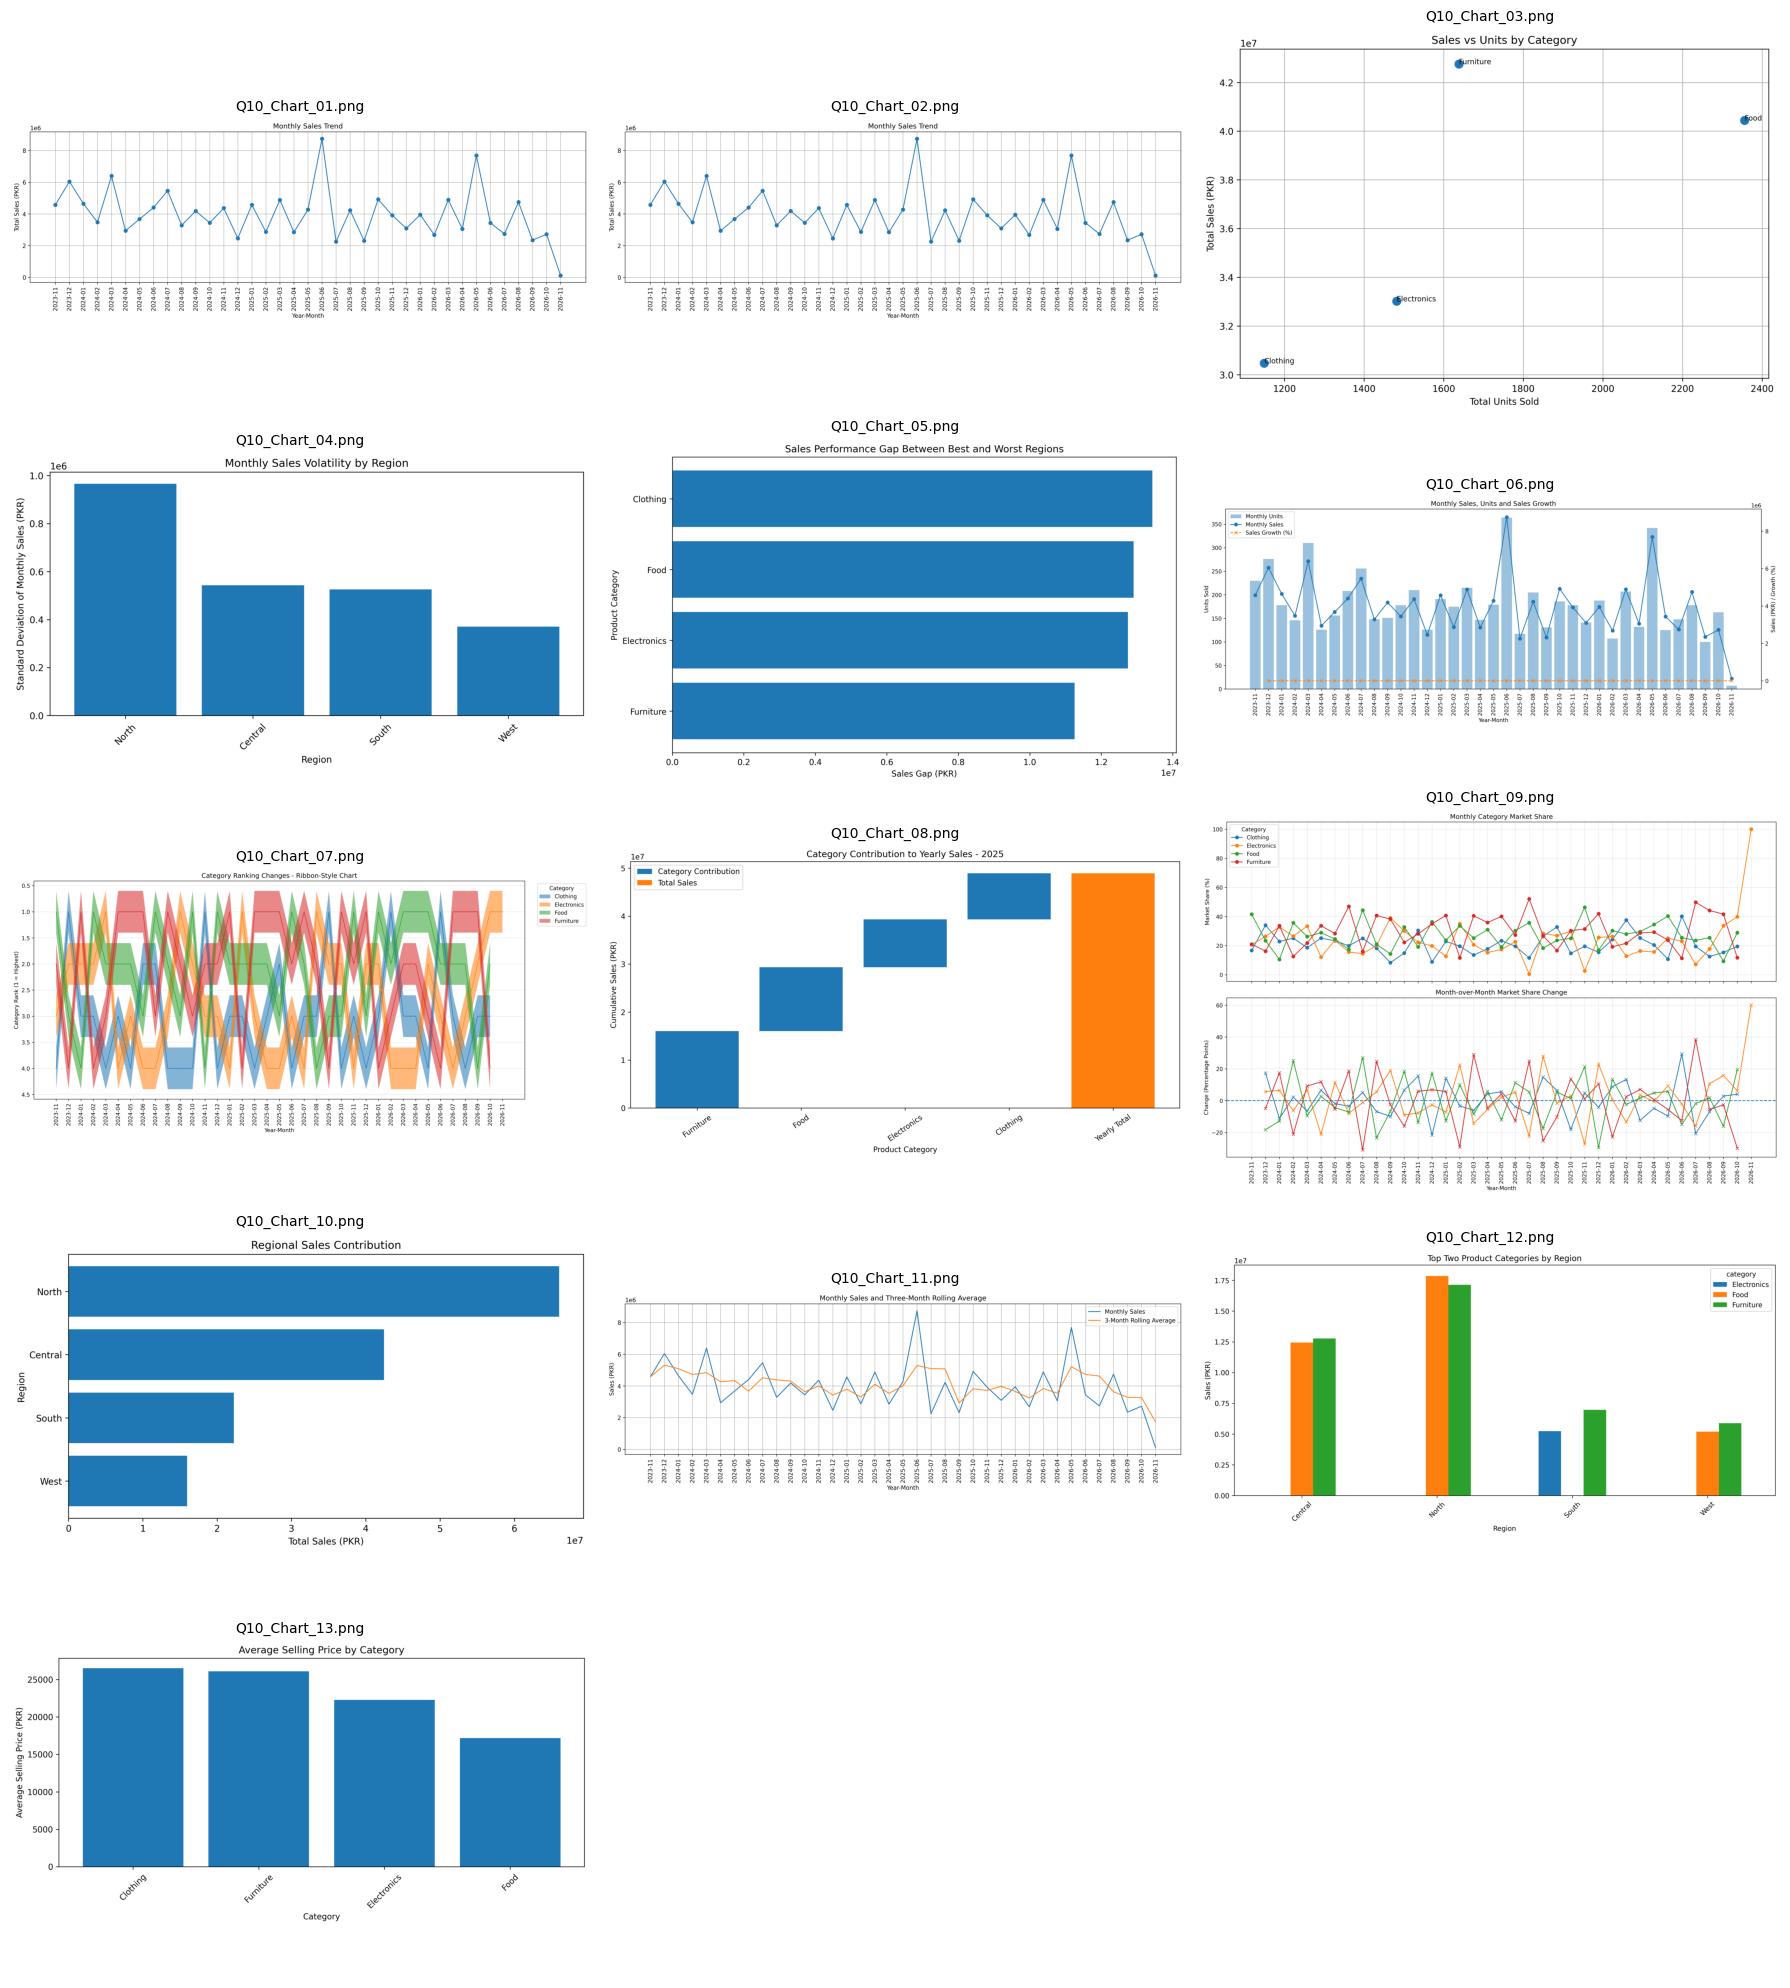

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt
import os
import math

chart_files = sorted([
    f for f in os.listdir(Q10_CHART_DIR)
    if f.endswith(".png")
])

cols = 3
rows = math.ceil(len(chart_files) / cols)

fig, axes = plt.subplots(rows, cols, figsize=(18, rows * 4))
axes = axes.flatten()

for i, filename in enumerate(chart_files):
    img = Image.open(os.path.join(Q10_CHART_DIR, filename))
    axes[i].imshow(img)
    axes[i].set_title(filename, fontsize=10)
    axes[i].axis("off")

for i in range(len(chart_files), len(axes)):
    axes[i].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import os
import shutil

FINAL_CHART_DIR = os.path.join(
    PROJECT_PATH,
    "Q10_SQL_Analysis",
    "Q10_Charts_Final"
)

os.makedirs(FINAL_CHART_DIR, exist_ok=True)

chart_mapping = {
    "P9_Q3_Monthly_Sales_Trend.png": "Q10_Chart_01.png",
    "P10_Q1_Sales_vs_Units.png": "Q10_Chart_03.png",
    "P10_Q17_Regional_Volatility.png": "Q10_Chart_04.png",
    "P10_Q20_Cross_Region_Imbalance.png": "Q10_Chart_05.png",
    "P9_Q19_Monthly_Sales_Units_Growth.png": "Q10_Chart_06.png",
    "P10_Q7_Category_Ranking_Change.png": "Q10_Chart_07.png",
    "P10_Q10_Yearly_Category_Contribution.png": "Q10_Chart_08.png",
    "P10_Q18_Market_Share_Gain_Loss.png": "Q10_Chart_09.png",
    "P9_Q11_Regional_Contribution.png": "Q10_Chart_10.png",
    "P9_Q13_Three_Month_Rolling_Average.png": "Q10_Chart_11.png",
    "P9_Q15_Top_Categories_by_Region.png": "Q10_Chart_12.png",
    "P9_Q17_Average_Selling_Price.png": "Q10_Chart_13.png"
}

for new_name, old_name in chart_mapping.items():
    source = os.path.join(Q10_CHART_DIR, old_name)
    destination = os.path.join(FINAL_CHART_DIR, new_name)

    assert os.path.exists(source), f"Missing chart: {old_name}"
    shutil.copy2(source, destination)

print("Final chart count:", len(os.listdir(FINAL_CHART_DIR)))
print("Duplicate excluded: Q10_Chart_02.png")
print("\nFinal chart files:")

for filename in sorted(os.listdir(FINAL_CHART_DIR)):
    print(filename)

Final chart count: 12
Duplicate excluded: Q10_Chart_02.png

Final chart files:
P10_Q10_Yearly_Category_Contribution.png
P10_Q17_Regional_Volatility.png
P10_Q18_Market_Share_Gain_Loss.png
P10_Q1_Sales_vs_Units.png
P10_Q20_Cross_Region_Imbalance.png
P10_Q7_Category_Ranking_Change.png
P9_Q11_Regional_Contribution.png
P9_Q13_Three_Month_Rolling_Average.png
P9_Q15_Top_Categories_by_Region.png
P9_Q17_Average_Selling_Price.png
P9_Q19_Monthly_Sales_Units_Growth.png
P9_Q3_Monthly_Sales_Trend.png


In [ ]:
!pip -q install reportlab

import os
from reportlab.lib import colors
from reportlab.lib.enums import TA_CENTER
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.units import inch
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Image,
    PageBreak, Table, TableStyle
)

report_path = os.path.join(
    PROJECT_PATH,
    "Q10_SQL_Analysis",
    "Q10_Visual_Analysis_Report.pdf"
)

chart_details = [
    {
        "file": "P9_Q3_Monthly_Sales_Trend.png",
        "task": "Practical 9 - Q3: Monthly Sales Trend",
        "description": "This line chart presents total sales by month across the available reporting period.",
        "finding": "The highest monthly sales occurred in June 2025, reaching PKR 8,747,022.40. The overall recorded sales total was PKR 146,686,462.33.",
        "interpretation": "Monthly sales fluctuate over time, indicating that business performance is not constant. Management can use this trend to identify strong and weak periods for planning.",
        "caveat": "November 2026 is an incomplete controlled test month and should not be compared directly with complete historical months."
    },
    {
        "file": "P9_Q11_Regional_Contribution.png",
        "task": "Practical 9 - Q11: Regional Sales Contribution",
        "description": "This chart compares total sales generated by each geographical region.",
        "finding": "North contributed the highest sales at PKR 66,021,347.90, representing 45.01% of total sales. West contributed the lowest share at 10.87%.",
        "interpretation": "North is the largest contributor to company sales. Management should investigate the factors behind its performance and evaluate opportunities to improve sales in lower-contributing regions."
    },
    {
        "file": "P9_Q13_Three_Month_Rolling_Average.png",
        "task": "Practical 9 - Q13: Three-Month Rolling Average",
        "description": "This chart compares monthly sales with a rolling average calculated over three months.",
        "finding": "The highest recorded rolling average was PKR 5,309,499.43 in December 2023.",
        "interpretation": "The rolling average smooths short-term fluctuations and helps management observe the broader sales direction. It provides a more stable view than individual monthly values.",
        "caveat": "The November 2026 test month is incomplete and should be excluded from historical performance conclusions."
    },
    {
        "file": "P9_Q15_Top_Categories_by_Region.png",
        "task": "Practical 9 - Q15: Top Two Categories in Each Region",
        "description": "This chart compares the two highest-selling product categories in each region.",
        "finding": "Furniture ranked first in Central, South and West. Food ranked first in North. The leading category differs by region.",
        "interpretation": "Product preferences and sales performance vary geographically. Regional managers can use these results to guide product availability and targeted sales strategies."
    },
    {
        "file": "P9_Q17_Average_Selling_Price.png",
        "task": "Practical 9 - Q17: Category Average Selling Price",
        "description": "Average selling price is calculated as total sales divided by total units sold for each category.",
        "finding": "Clothing had the highest average selling price at PKR 26,518.22, while Food had the lowest at PKR 17,165.52.",
        "interpretation": "Average selling price helps compare revenue per unit across product categories. A higher average price does not necessarily mean higher total sales or profitability."
    },
    {
        "file": "P9_Q19_Monthly_Sales_Units_Growth.png",
        "task": "Practical 9 - Q19: Monthly Sales, Units and Growth",
        "description": "This visualization combines monthly sales, units sold and sales growth to examine performance over time.",
        "finding": "The highest recorded monthly growth was 151.76% in May 2026. November 2026 showed a decline of 95.77%, but it is an incomplete test month.",
        "interpretation": "Combining sales, units and growth provides a broader view of monthly performance. Management should investigate unusually large increases or decreases before making operational decisions.",
        "caveat": "The November 2026 result is affected by the controlled test data and is not representative of a complete month."
    },
    {
        "file": "P10_Q1_Sales_vs_Units.png",
        "task": "Practical 10 - Q1: Sales vs Units by Category",
        "description": "This scatter chart compares total sales and units sold across product categories.",
        "finding": "Furniture generated the highest sales at PKR 42,757,709.43, while Food recorded the highest quantity sold at 2,356 units.",
        "interpretation": "The category with the highest sales is not necessarily the category with the highest unit volume. Management should consider both revenue and quantity when evaluating category performance."
    },
    {
        "file": "P10_Q7_Category_Ranking_Change.png",
        "task": "Practical 10 - Q7: Category Ranking Change Over Time",
        "description": "The ribbon-style visualization shows how product-category sales rankings change across months.",
        "finding": "Category rankings vary over time rather than remaining fixed. Food and Furniture frequently occupy leading positions in the historical data.",
        "interpretation": "Ranking changes help identify shifts in category performance and changing customer demand. Management can use these changes to review product strategies and inventory planning.",
        "caveat": "The final November 2026 period contains controlled test data and should not be treated as a complete historical month."
    },
    {
        "file": "P10_Q10_Yearly_Category_Contribution.png",
        "task": "Practical 10 - Q10: Category Contribution to Yearly Sales",
        "description": "This waterfall-style chart illustrates how product categories contribute to total sales for the complete year 2025.",
        "finding": "Total sales in 2025 were PKR 48,934,202.82, compared with PKR 48,747,025.07 in 2024.",
        "interpretation": "The chart shows how individual categories contribute to annual sales. The complete-year comparison indicates a modest increase in total sales from 2024 to 2025.",
        "caveat": "The visualization uses 2025 because 2023 and 2026 are partial years in the available dataset."
    },
    {
        "file": "P10_Q17_Regional_Volatility.png",
        "task": "Practical 10 - Q17: Regional Sales Volatility",
        "description": "This chart compares the standard deviation of monthly sales across regions over a consistent 36-month period.",
        "finding": "North had the highest standard deviation at approximately PKR 937,205.76. West had the lowest at approximately PKR 379,014.16.",
        "interpretation": "Higher standard deviation indicates greater variation in monthly sales. North has the most variable sales, while West has comparatively lower variation. Volatility alone does not indicate whether sales performance is good or bad."
    },
    {
        "file": "P10_Q18_Market_Share_Gain_Loss.png",
        "task": "Practical 10 - Q18: Market Share Gain and Loss",
        "description": "The visualization presents monthly category market shares and changes in percentage points.",
        "finding": "Furniture experienced a historical market-share decline of approximately 30.92 percentage points in July 2024.",
        "interpretation": "Market-share changes reveal shifts in the relative contribution of product categories. Management can investigate significant losses to understand changes in demand, competition or product availability.",
        "caveat": "The incomplete November 2026 test month should be excluded from historical market-share conclusions."
    },
    {
        "file": "P10_Q20_Cross_Region_Imbalance.png",
        "task": "Practical 10 - Q20: Cross-Region Performance Imbalance",
        "description": "This chart compares the difference between the highest and lowest regional sales for each product category.",
        "finding": "Clothing had the largest regional sales gap, approximately PKR 13,427,641.07, between North and West.",
        "interpretation": "The gaps reveal geographical differences in category performance. Management can investigate weaker regional performance and evaluate whether distribution, availability or marketing strategies need improvement."
    }
]

# Verify all images exist
assert len(chart_details) == 12, "The report must contain exactly 12 charts."

for item in chart_details:
    image_path = os.path.join(FINAL_CHART_DIR, item["file"])
    assert os.path.exists(image_path), f"Missing image: {item['file']}"

styles = getSampleStyleSheet()

styles.add(ParagraphStyle(
    name="ReportTitle",
    parent=styles["Title"],
    fontSize=25,
    leading=32,
    alignment=TA_CENTER,
    spaceAfter=20
))

styles.add(ParagraphStyle(
    name="ChartHeading",
    parent=styles["Heading1"],
    fontSize=16,
    leading=21,
    spaceAfter=12
))

styles.add(ParagraphStyle(
    name="BodyCustom",
    parent=styles["BodyText"],
    fontSize=10,
    leading=15,
    spaceAfter=9
))

styles.add(ParagraphStyle(
    name="SmallCenter",
    parent=styles["BodyText"],
    fontSize=10,
    alignment=TA_CENTER,
    leading=15
))

doc = SimpleDocTemplate(
    report_path,
    pagesize=A4,
    rightMargin=0.65 * inch,
    leftMargin=0.65 * inch,
    topMargin=0.65 * inch,
    bottomMargin=0.65 * inch
)

story = []

# Cover page
story.append(Spacer(1, 1.4 * inch))
story.append(Paragraph(
    "SQL ANALYTICAL QUERIES",
    styles["ReportTitle"]
))
story.append(Paragraph(
    "Visual Analysis Report",
    styles["Heading1"]
))
story.append(Spacer(1, 0.3 * inch))
story.append(Paragraph(
    "CT-472 Data Warehouse and Business Intelligence Project",
    styles["SmallCenter"]
))
story.append(Spacer(1, 0.4 * inch))
story.append(Paragraph(
    "Practical 9 and Practical 10",
    styles["SmallCenter"]
))
story.append(Spacer(1, 0.2 * inch))
story.append(Paragraph(
    "12 Selected Analytical Visualizations",
    styles["SmallCenter"]
))
story.append(Spacer(1, 1.0 * inch))

cover_data = [
    ["Analysis Area", "Coverage"],
    ["Practical 9", "6 analytical queries"],
    ["Practical 10", "6 analytical queries"],
    ["Visualization Count", "12 final charts"],
    ["Sales Currency", "PKR"]
]

cover_table = Table(
    cover_data,
    colWidths=[2.3 * inch, 3.3 * inch]
)

cover_table.setStyle(TableStyle([
    ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#243B53")),
    ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
    ("GRID", (0, 0), (-1, -1), 0.5, colors.grey),
    ("PADDING", (0, 0), (-1, -1), 9),
    ("FONTNAME", (0, 0), (-1, 0), "Helvetica-Bold"),
]))

story.append(cover_table)
story.append(Spacer(1, 1.0 * inch))
story.append(Paragraph(
    "Prepared using the integrated warehouse sales data and SQL analytical views.",
    styles["SmallCenter"]
))
story.append(PageBreak())

# Individual chart pages
for index, item in enumerate(chart_details, 1):

    story.append(Paragraph(
        item["task"],
        styles["ChartHeading"]
    ))

    story.append(Paragraph(
        f"<b>Chart {index} of 12</b>",
        styles["BodyCustom"]
    ))

    image_path = os.path.join(FINAL_CHART_DIR, item["file"])
    chart_image = Image(image_path)

    max_width = 7.0 * inch
    max_height = 3.65 * inch

    scale = min(
        max_width / chart_image.imageWidth,
        max_height / chart_image.imageHeight
    )

    chart_image.drawWidth = chart_image.imageWidth * scale
    chart_image.drawHeight = chart_image.imageHeight * scale

    story.append(chart_image)
    story.append(Spacer(1, 12))

    story.append(Paragraph(
        "<b>Analysis</b>",
        styles["Heading3"]
    ))
    story.append(Paragraph(
        item["description"],
        styles["BodyCustom"]
    ))

    story.append(Paragraph(
        "<b>Key Finding</b>",
        styles["Heading3"]
    ))
    story.append(Paragraph(
        item["finding"],
        styles["BodyCustom"]
    ))

    story.append(Paragraph(
        "<b>Business Interpretation</b>",
        styles["Heading3"]
    ))
    story.append(Paragraph(
        item["interpretation"],
        styles["BodyCustom"]
    ))

    if "caveat" in item:
        story.append(Paragraph(
            "<b>Data Limitation</b>",
            styles["Heading3"]
        ))
        story.append(Paragraph(
            item["caveat"],
            styles["BodyCustom"]
        ))

    if index < len(chart_details):
        story.append(PageBreak())

# Conclusion page
story.append(PageBreak())
story.append(Paragraph(
    "Overall Conclusion",
    styles["ChartHeading"]
))

conclusion = [
    "The twelve selected analytical queries demonstrate how SQL aggregation, "
    "window functions, ranking, rolling averages and contribution analysis "
    "can support business intelligence reporting.",

    "The Practical 9 visualizations examine monthly sales trends, regional "
    "contribution, category performance, average selling prices and sales growth.",

    "The Practical 10 visualizations extend the analysis through category "
    "rankings, market-share changes, regional volatility and cross-region "
    "performance differences.",

    "The findings show that sales performance differs across time periods, "
    "product categories and geographical regions. These insights can support "
    "management decisions involving sales planning, inventory allocation and "
    "regional performance review.",

    "The analysis is descriptive and identifies patterns and relationships. "
    "It does not establish that one factor caused another.",

    "The final November 2026 records were introduced as controlled test data "
    "and represent an incomplete period. Partial years and test-period values "
    "must be considered when interpreting historical comparisons."
]

for paragraph in conclusion:
    story.append(Paragraph(paragraph, styles["BodyCustom"]))
    story.append(Spacer(1, 8))

story.append(Spacer(1, 15))
story.append(Paragraph(
    "<b>Final Report: 12 charts from 12 selected SQL analytical queries.</b>",
    styles["BodyCustom"]
))

# Footer
def add_footer(canvas, doc):
    canvas.saveState()
    canvas.setFont("Helvetica", 8)
    canvas.setFillColor(colors.grey)
    canvas.drawString(
        0.65 * inch,
        0.35 * inch,
        "CT-472 | SQL Visual Analysis Report"
    )
    canvas.drawRightString(
        A4[0] - 0.65 * inch,
        0.35 * inch,
        f"Page {doc.page}"
    )
    canvas.restoreState()

doc.build(
    story,
    onFirstPage=add_footer,
    onLaterPages=add_footer
)

print("PDF report created successfully!")
print("Report:", report_path)
print("Charts included:", len(chart_details))
print("File size:", round(os.path.getsize(report_path) / 1024, 2), "KB")

PDF report created successfully!
Report: /content/drive/MyDrive/CT472_Project/Q10_SQL_Analysis/Q10_Visual_Analysis_Report.pdf
Charts included: 12
File size: 5166.95 KB


In [ ]:
import os

print("PDF exists:", os.path.exists(report_path))
print("PDF size:", round(os.path.getsize(report_path) / 1024, 2), "KB")
print("Final chart images:", len(os.listdir(FINAL_CHART_DIR)))

PDF exists: True
PDF size: 5166.95 KB
Final chart images: 12


REMAINING TASK 08

In [ ]:
import os
import pandas as pd

metadata_dir = os.path.join(PROJECT_PATH, "metadata")
source_models_dir = os.path.join(PROJECT_PATH, "source_models")

print("METADATA EXPORTS")
print("=" * 60)

for filename in sorted(os.listdir(metadata_dir)):
    path = os.path.join(metadata_dir, filename)

    if filename.endswith(".csv"):
        df = pd.read_csv(path)
        print(f"{filename}: {len(df)} rows")

print("\nSOURCE MODEL FILES")
print("=" * 60)

for filename in sorted(os.listdir(source_models_dir)):
    path = os.path.join(source_models_dir, filename)
    print(f"{filename}: {os.path.getsize(path):,} bytes")

METADATA EXPORTS
meta_column_mapping.csv: 30 rows
meta_etl_batch.csv: 8 rows
meta_record_lineage.csv: 3603 rows
meta_source_column.csv: 84 rows
meta_source_constraint.csv: 53 rows
meta_source_object.csv: 20 rows
meta_source_system.csv: 4 rows
meta_transformation_rule.csv: 8 rows
metadata_verification_summary.csv: 8 rows

SOURCE MODEL FILES
finance_duckdb_draft_ddl.sql: 1,385 bytes
finance_duckdb_erd.md: 1,001 bytes
inventory_sqlite_draft_ddl.sql: 2,079 bytes
inventory_sqlite_erd.md: 1,086 bytes
sales_postgresql_draft_ddl.sql: 1,941 bytes
sales_postgresql_erd.md: 944 bytes


In [ ]:
import os
import pandas as pd

finance_erd_path = os.path.join(
    PROJECT_PATH, "source_models", "finance_duckdb_erd.md"
)

constraint_path = os.path.join(
    PROJECT_PATH, "metadata", "meta_source_constraint.csv"
)

print("CURRENT FINANCE ERD")
print("=" * 70)

with open(finance_erd_path, "r", encoding="utf-8") as file:
    print(file.read())

print("\nFINANCE CAPTURED CONSTRAINTS")
print("=" * 70)

constraints_df = pd.read_csv(constraint_path)

finance_constraints = constraints_df[
    constraints_df.astype(str).apply(
        lambda column: column.str.contains(
            "finance", case=False, na=False
        )
    ).any(axis=1)
]

print(finance_constraints.to_string(index=False))

CURRENT FINANCE ERD
# Finance Database - Reverse Engineered ERD

```mermaid
erDiagram
    finance_accounts ||--o{ finance_transactions : classifies
    finance_departments ||--o{ finance_transactions : records
    finance_transactions ||--o{ finance_transaction_lines : contains
    finance_departments ||--o{ finance_budgets : receives

    finance_accounts {
        integer account_id PK
    }
    finance_departments {
        integer department_id PK
    }
    finance_transactions {
        integer transaction_id PK
        integer account_id FK
        integer department_id FK
    }
    finance_transaction_lines {
        integer line_id PK
        integer transaction_id FK
    }
    finance_budgets {
        integer budget_id PK
        integer department_id FK
    }
```

## Evidence
- Source system: SRC_FINANCE
- Database engine: DuckDB
- Schema: main
- Tables: 5
- Columns: 18
- Primary keys: 5
- Foreign keys: 4
- NOT NULL constraints: 17
- Relationships shown are based on declared

In [ ]:
import os

finance_erd_path = os.path.join(
    PROJECT_PATH, "source_models", "finance_duckdb_erd.md"
)

finance_erd_lines = [
    "# Finance Database - Reverse Engineered ERD",
    "",
    "## Relationship Evidence",
    "",
    "The DuckDB metadata catalogue captured four FOREIGN KEY constraints.",
    "However, the referenced table and referenced column fields were not",
    "available in the extracted constraint metadata.",
    "",
    "The four relationship endpoints below were reconstructed from the",
    "source schema and validated against the source data. They are therefore",
    "labelled as inferred/reconstructed rather than directly reverse-engineered",
    "from the captured relationship metadata.",
    "",
    "```mermaid",
    "erDiagram",
    '    finance_accounts ||--o{ finance_transactions : "inferred relationship"',
    '    finance_departments ||--o{ finance_transactions : "inferred relationship"',
    '    finance_transactions ||--o{ finance_transaction_lines : "inferred relationship"',
    '    finance_departments ||--o{ finance_budgets : "inferred relationship"',
    "",
    "    finance_accounts {",
    "        integer account_id PK",
    "    }",
    "    finance_departments {",
    "        integer department_id PK",
    "    }",
    "    finance_transactions {",
    "        integer transaction_id PK",
    "        integer account_id FK",
    "        integer department_id FK",
    "    }",
    "    finance_transaction_lines {",
    "        integer line_id PK",
    "        integer transaction_id FK",
    "    }",
    "    finance_budgets {",
    "        integer budget_id PK",
    "        integer department_id FK",
    "    }",
    "```",
    "",
    "## Evidence",
    "",
    "- Source system: SRC_FINANCE",
    "- Database engine: DuckDB",
    "- Schema: main",
    "- Tables: 5",
    "- Columns: 18",
    "- Primary keys: 5",
    "- Foreign key constraints captured: 4",
    "- NOT NULL constraints: 17",
    "- Foreign-key constraint types were captured from the source catalogue.",
    "- Referenced table and column endpoints were unavailable in the captured metadata.",
    "- Relationship endpoints shown in this ERD are inferred/reconstructed",
    "  from the source schema and validated against the source data.",
    "",
    "## Reverse Engineering Limitation",
    "",
    "The draft ERD and DDL represent the five source tables and their",
    "identified primary and foreign key structures. The extracted metadata",
    "does not independently establish the referenced endpoints of the",
    "DuckDB foreign keys. These endpoints are documented as inferred.",
    "Other DBMS-specific features such as indexes, triggers, defaults,",
    "and additional database-specific definitions may not be fully preserved."
]

with open(finance_erd_path, "w", encoding="utf-8") as file:
    file.write("\n".join(finance_erd_lines))

print("Finance ERD updated successfully.")
print("File exists:", os.path.exists(finance_erd_path))
print("File size:", os.path.getsize(finance_erd_path), "bytes")

Finance ERD updated successfully.
File exists: True
File size: 2212 bytes


In [ ]:
query = """
SELECT
    COUNT(*) AS transaction_lines,
    SUM(quantity) AS total_quantity,
    ROUND(SUM(sales_amount), 2) AS total_sales_pkr,
    COUNT(DISTINCT source_system) AS source_systems,
    COUNT(DISTINCT batch_id) AS batches
FROM warehouse.fact_sales;
"""

sales_kpi_lineage = pd.read_sql_query(query, sales_conn)

print("DASHBOARD KPI SOURCE")
print("=" * 60)
print(sales_kpi_lineage.to_string(index=False))

print("\nSOURCE SYSTEM CONTRIBUTION")
print("=" * 60)

source_query = """
SELECT
    source_system,
    batch_id,
    COUNT(*) AS transaction_lines,
    SUM(quantity) AS total_quantity,
    ROUND(SUM(sales_amount), 2) AS total_sales_pkr
FROM warehouse.fact_sales
GROUP BY source_system, batch_id
ORDER BY source_system, batch_id;
"""

print(pd.read_sql_query(source_query, sales_conn).to_string(index=False))

DASHBOARD KPI SOURCE
 transaction_lines  total_quantity  total_sales_pkr  source_systems  batches
              1201            6625     146686462.33               1        2

SOURCE SYSTEM CONTRIBUTION
source_system          batch_id  transaction_lines  total_quantity  total_sales_pkr
        SALES INITIAL_SALES_001               1199            6612     146472601.02
        SALES  SECOND_SALES_002                  2              13        213861.31


/tmp/ipykernel_653/3055285410.py:11: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  sales_kpi_lineage = pd.read_sql_query(query, sales_conn)
/tmp/ipykernel_653/3055285410.py:32: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  print(pd.read_sql_query(source_query, sales_conn).to_string(index=False))


In [ ]:
import os
import pandas as pd

kpi_lineage_query = """
SELECT
    f.sales_fact_key,
    f.source_system,
    f.source_line_id,
    f.transaction_id,
    f.date_key,
    f.product_key,
    f.location_key,
    f.quantity,
    f.unit_price,
    f.sales_amount,
    f.batch_id,
    l.source_table,
    l.source_record_key
FROM warehouse.fact_sales f
LEFT JOIN warehouse.meta_record_lineage l
    ON l.target_table = 'warehouse.fact_sales'
    AND l.target_record_id = CAST(f.sales_fact_key AS VARCHAR)
ORDER BY f.sales_fact_key;
"""

kpi_lineage_df = pd.read_sql_query(kpi_lineage_query, sales_conn)

print("DASHBOARD KPI RECORD-LEVEL LINEAGE")
print("=" * 70)
print("Warehouse fact records:", len(kpi_lineage_df))
print("Records with lineage:", kpi_lineage_df["source_record_key"].notna().sum())
print("Missing lineage:", kpi_lineage_df["source_record_key"].isna().sum())
print("Sales total:", round(kpi_lineage_df["sales_amount"].sum(), 2))

lineage_dir = os.path.join(PROJECT_PATH, "metadata")
kpi_lineage_path = os.path.join(
    lineage_dir, "q8_dashboard_kpi_record_lineage.csv"
)

kpi_lineage_df.to_csv(kpi_lineage_path, index=False)

print("\nSaved:", kpi_lineage_path)
print("\nSample contributing records:")
print(kpi_lineage_df.head(5).to_string(index=False))

/tmp/ipykernel_653/1665417434.py:26: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  kpi_lineage_df = pd.read_sql_query(kpi_lineage_query, sales_conn)


DatabaseError: Execution failed on sql '
SELECT
    f.sales_fact_key,
    f.source_system,
    f.source_line_id,
    f.transaction_id,
    f.date_key,
    f.product_key,
    f.location_key,
    f.quantity,
    f.unit_price,
    f.sales_amount,
    f.batch_id,
    l.source_table,
    l.source_record_key
FROM warehouse.fact_sales f
LEFT JOIN warehouse.meta_record_lineage l
    ON l.target_table = 'warehouse.fact_sales'
    AND l.target_record_id = CAST(f.sales_fact_key AS VARCHAR)
ORDER BY f.sales_fact_key;
': column l.source_table does not exist
LINE 14:     l.source_table,
             ^


In [ ]:
lineage_columns_query = """
SELECT
    column_name,
    data_type
FROM information_schema.columns
WHERE table_schema = 'warehouse'
  AND table_name = 'meta_record_lineage'
ORDER BY ordinal_position;
"""

lineage_columns_df = pd.read_sql_query(
    lineage_columns_query, sales_conn
)

print(lineage_columns_df.to_string(index=False))

/tmp/ipykernel_653/2293008529.py:11: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  lineage_columns_df = pd.read_sql_query(


           column_name                   data_type
            lineage_id                      bigint
          target_table           character varying
      target_record_id           character varying
      source_system_id           character varying
      source_object_id           character varying
     source_record_key           character varying
              batch_id           character varying
     relationship_role           character varying
transformation_rule_id           character varying
       captured_at_utc timestamp without time zone


In [ ]:
kpi_lineage_query = """
SELECT
    f.sales_fact_key,
    f.source_system,
    f.source_line_id,
    f.transaction_id,
    f.date_key,
    f.product_key,
    f.location_key,
    f.quantity,
    f.unit_price,
    f.sales_amount,
    f.batch_id,
    l.source_system_id,
    l.source_object_id,
    l.source_record_key,
    l.transformation_rule_id,
    l.relationship_role
FROM warehouse.fact_sales f
LEFT JOIN warehouse.meta_record_lineage l
    ON l.target_table = 'warehouse.fact_sales'
    AND l.target_record_id = CAST(f.sales_fact_key AS VARCHAR)
ORDER BY f.sales_fact_key;
"""

kpi_lineage_df = pd.read_sql_query(
    kpi_lineage_query, sales_conn
)

print("DASHBOARD KPI RECORD-LEVEL LINEAGE")
print("=" * 70)
print("Warehouse fact records:", len(kpi_lineage_df))
print("Records with lineage:", kpi_lineage_df["source_record_key"].notna().sum())
print("Missing lineage:", kpi_lineage_df["source_record_key"].isna().sum())
print("Sales total:", round(kpi_lineage_df["sales_amount"].sum(), 2))

kpi_lineage_path = os.path.join(
    PROJECT_PATH, "metadata", "q8_dashboard_kpi_record_lineage.csv"
)

kpi_lineage_df.to_csv(kpi_lineage_path, index=False)

print("\nSaved:", kpi_lineage_path)
print("\nSample contributing records:")
print(kpi_lineage_df.head(5).to_string(index=False))

/tmp/ipykernel_653/1285333970.py:26: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  kpi_lineage_df = pd.read_sql_query(


DASHBOARD KPI RECORD-LEVEL LINEAGE
Warehouse fact records: 1201
Records with lineage: 1201
Missing lineage: 0
Sales total: 146686462.33

Saved: /content/drive/MyDrive/CT472_Project/metadata/q8_dashboard_kpi_record_lineage.csv

Sample contributing records:
 sales_fact_key source_system  source_line_id  transaction_id  date_key  product_key  location_key  quantity  unit_price  sales_amount          batch_id source_system_id                         source_object_id source_record_key transformation_rule_id    relationship_role
              1         SALES               1             734       809           38             4         6    16450.87      98705.22  SECOND_SALES_002        SRC_SALES SRC_SALES:public.sales_transaction_lines                 1                   None DIRECT SOURCE RECORD
              2         SALES               2             445       714            6             8         7    20753.44     145274.08 INITIAL_SALES_001        SRC_SALES SRC_SALES:public.sales_trans

### Dashboard KPI Lineage – Total Sales

The dashboard's Total Sales KPI is calculated from `warehouse.fact_sales` by summing `sales_amount`.

**KPI results:**

| Metric | Verified result |
|---|---:|
| Transaction lines | 1,201 |
| Total quantity | 6,625 |
| Total Sales | PKR 146,686,462.33 |
| Source systems | 1 |
| ETL batches | 2 |

**Batch contribution:**

| Batch | Records | Quantity | Sales (PKR) |
|---|---:|---:|---:|
| INITIAL_SALES_001 | 1,199 | 6,612 | 146,472,601.02 |
| SECOND_SALES_002 | 2 | 13 | 213,861.31 |

**Record-level lineage validation:**

- Warehouse fact records: 1,201
- Records with matching lineage: 1,201
- Missing lineage records: 0
- Source object: `SRC_SALES:public.sales_transaction_lines`
- Lineage relationship: DIRECT SOURCE RECORD
- Export: `metadata/q8_dashboard_kpi_record_lineage.csv`

The record-level lineage confirms that every warehouse Sales fact record contributing to the KPI can be traced to its source record key and ETL batch. The aggregated KPI reconciles exactly with the warehouse fact total.

The pandas DBAPI warning did not affect query execution or the exported results.

LAB 02

In [ ]:
lab2_schema_query = """
SELECT
    table_name,
    column_name,
    data_type
FROM information_schema.columns
WHERE table_schema = 'warehouse'
  AND table_name IN (
      'fact_sales',
      'dim_date',
      'dim_product',
      'dim_location'
  )
ORDER BY table_name, ordinal_position;
"""

lab2_schema_df = pd.read_sql_query(
    lab2_schema_query, sales_conn
)

print("LAB 2 - WAREHOUSE SCHEMA")
print("=" * 70)
print(lab2_schema_df.to_string(index=False))

LAB 2 - WAREHOUSE SCHEMA
  table_name       column_name         data_type
    dim_date          date_key            bigint
    dim_date         full_date              date
    dim_date        day_number           integer
    dim_date      month_number           integer
    dim_date        month_name character varying
    dim_date    quarter_number           integer
    dim_date       year_number           integer
dim_location      location_key            bigint
dim_location              city character varying
dim_location            region character varying
dim_location           country character varying
 dim_product       product_key            bigint
 dim_product     source_system character varying
 dim_product source_product_id           integer
 dim_product      product_name character varying
 dim_product          category character varying
  fact_sales    sales_fact_key            bigint
  fact_sales     source_system character varying
  fact_sales    source_line_id           int

/tmp/ipykernel_653/3838750569.py:17: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  lab2_schema_df = pd.read_sql_query(


In [ ]:
collapse_sales_sql = """
DROP TABLE IF EXISTS warehouse.lab2_collapsed_sales;

CREATE TABLE warehouse.lab2_collapsed_sales AS
SELECT
    f.sales_fact_key,
    f.source_system,
    f.source_line_id,
    f.transaction_id,

    d.full_date,
    d.day_number,
    d.month_number,
    d.month_name,
    d.quarter_number,
    d.year_number,

    p.source_product_id,
    p.product_name,
    p.category,

    l.city,
    l.region,
    l.country,

    f.quantity,
    f.unit_price,
    f.sales_amount,
    f.batch_id

FROM warehouse.fact_sales f
LEFT JOIN warehouse.dim_date d
    ON f.date_key = d.date_key
LEFT JOIN warehouse.dim_product p
    ON f.product_key = p.product_key
LEFT JOIN warehouse.dim_location l
    ON f.location_key = l.location_key;
"""

with sales_conn.cursor() as cursor:
    cursor.execute(collapse_sales_sql)

sales_conn.commit()

check_query = """
SELECT
    COUNT(*) AS collapsed_rows,
    COUNT(DISTINCT sales_fact_key) AS unique_sales_records,
    ROUND(SUM(sales_amount), 2) AS total_sales,
    COUNT(*) FILTER (WHERE full_date IS NULL) AS missing_dates,
    COUNT(*) FILTER (WHERE product_name IS NULL) AS missing_products,
    COUNT(*) FILTER (WHERE city IS NULL) AS missing_locations
FROM warehouse.lab2_collapsed_sales;
"""

collapsed_check = pd.read_sql_query(check_query, sales_conn)

print("COLLAPSING VALIDATION")
print("=" * 60)
print(collapsed_check.to_string(index=False))

COLLAPSING VALIDATION
 collapsed_rows  unique_sales_records  total_sales  missing_dates  missing_products  missing_locations
           1201                  1201 146686462.33              0                 0                  0


/tmp/ipykernel_653/3796996590.py:56: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  collapsed_check = pd.read_sql_query(check_query, sales_conn)


In [ ]:
vertical_split_sql = """
DROP TABLE IF EXISTS warehouse.lab2_sales_core;
DROP TABLE IF EXISTS warehouse.lab2_sales_details;

CREATE TABLE warehouse.lab2_sales_core AS
SELECT
    sales_fact_key,
    transaction_id,
    full_date,
    region,
    category,
    quantity,
    sales_amount
FROM warehouse.lab2_collapsed_sales;

CREATE TABLE warehouse.lab2_sales_details AS
SELECT
    sales_fact_key,
    source_system,
    source_line_id,
    product_name,
    city,
    country,
    unit_price,
    batch_id
FROM warehouse.lab2_collapsed_sales;
"""

with sales_conn.cursor() as cursor:
    cursor.execute(vertical_split_sql)

sales_conn.commit()

vertical_check = pd.read_sql_query("""
SELECT
    (SELECT COUNT(*) FROM warehouse.lab2_sales_core) AS core_rows,
    (SELECT COUNT(*) FROM warehouse.lab2_sales_details) AS detail_rows,
    (SELECT COUNT(DISTINCT sales_fact_key)
     FROM warehouse.lab2_sales_core) AS unique_core_keys,
    (SELECT COUNT(DISTINCT sales_fact_key)
     FROM warehouse.lab2_sales_details) AS unique_detail_keys,
    (SELECT COUNT(*)
     FROM warehouse.lab2_sales_core c
     JOIN warehouse.lab2_sales_details d
       ON c.sales_fact_key = d.sales_fact_key) AS matched_records;
""", sales_conn)

print("VERTICAL SPLITTING VALIDATION")
print("=" * 60)
print(vertical_check.to_string(index=False))

VERTICAL SPLITTING VALIDATION
 core_rows  detail_rows  unique_core_keys  unique_detail_keys  matched_records
      1201         1201              1201                1201             1201


/tmp/ipykernel_653/2852390436.py:34: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  vertical_check = pd.read_sql_query("""


In [ ]:
horizontal_split_sql = """
DROP TABLE IF EXISTS warehouse.lab2_sales_2023;
DROP TABLE IF EXISTS warehouse.lab2_sales_2024;
DROP TABLE IF EXISTS warehouse.lab2_sales_2025;
DROP TABLE IF EXISTS warehouse.lab2_sales_2026;

CREATE TABLE warehouse.lab2_sales_2023 AS
SELECT * FROM warehouse.lab2_collapsed_sales
WHERE year_number = 2023;

CREATE TABLE warehouse.lab2_sales_2024 AS
SELECT * FROM warehouse.lab2_collapsed_sales
WHERE year_number = 2024;

CREATE TABLE warehouse.lab2_sales_2025 AS
SELECT * FROM warehouse.lab2_collapsed_sales
WHERE year_number = 2025;

CREATE TABLE warehouse.lab2_sales_2026 AS
SELECT * FROM warehouse.lab2_collapsed_sales
WHERE year_number = 2026;
"""

with sales_conn.cursor() as cursor:
    cursor.execute(horizontal_split_sql)

sales_conn.commit()

horizontal_check = pd.read_sql_query("""
SELECT '2023' AS year, COUNT(*) AS rows
FROM warehouse.lab2_sales_2023
UNION ALL
SELECT '2024', COUNT(*) FROM warehouse.lab2_sales_2024
UNION ALL
SELECT '2025', COUNT(*) FROM warehouse.lab2_sales_2025
UNION ALL
SELECT '2026', COUNT(*) FROM warehouse.lab2_sales_2026
UNION ALL
SELECT 'TOTAL', SUM(row_count)
FROM (
    SELECT COUNT(*) AS row_count FROM warehouse.lab2_sales_2023
    UNION ALL
    SELECT COUNT(*) FROM warehouse.lab2_sales_2024
    UNION ALL
    SELECT COUNT(*) FROM warehouse.lab2_sales_2025
    UNION ALL
    SELECT COUNT(*) FROM warehouse.lab2_sales_2026
) AS yearly_counts;
""", sales_conn)

print("HORIZONTAL SPLITTING VALIDATION")
print("=" * 60)
print(horizontal_check.to_string(index=False))

HORIZONTAL SPLITTING VALIDATION
 year   rows
 2023   84.0
 2024  408.0
 2025  396.0
 2026  313.0
TOTAL 1201.0


/tmp/ipykernel_653/4284100706.py:29: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  horizontal_check = pd.read_sql_query("""


In [ ]:
prejoin_sql = """
DROP TABLE IF EXISTS warehouse.lab2_prejoined_sales;

CREATE TABLE warehouse.lab2_prejoined_sales AS
SELECT
    f.sales_fact_key,
    f.transaction_id,
    f.source_line_id,

    d.full_date,
    d.month_name,
    d.quarter_number,
    d.year_number,

    p.product_name,
    p.category,

    l.city,
    l.region,
    l.country,

    f.quantity,
    f.unit_price,
    f.sales_amount

FROM warehouse.fact_sales f
INNER JOIN warehouse.dim_date d
    ON f.date_key = d.date_key
INNER JOIN warehouse.dim_product p
    ON f.product_key = p.product_key
INNER JOIN warehouse.dim_location l
    ON f.location_key = l.location_key;
"""

with sales_conn.cursor() as cursor:
    cursor.execute(prejoin_sql)

sales_conn.commit()

prejoin_check = pd.read_sql_query("""
SELECT
    COUNT(*) AS prejoined_rows,
    COUNT(DISTINCT sales_fact_key) AS unique_records,
    ROUND(SUM(sales_amount), 2) AS total_sales,
    COUNT(DISTINCT category) AS categories,
    COUNT(DISTINCT region) AS regions
FROM warehouse.lab2_prejoined_sales;
""", sales_conn)

print("PRE-JOINING VALIDATION")
print("=" * 60)
print(prejoin_check.to_string(index=False))

PRE-JOINING VALIDATION
 prejoined_rows  unique_records  total_sales  categories  regions
           1201            1201 146686462.33           4        4


/tmp/ipykernel_653/1642914924.py:40: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  prejoin_check = pd.read_sql_query("""


In [ ]:
redundant_sql = """
DROP TABLE IF EXISTS warehouse.lab2_redundant_sales;

CREATE TABLE warehouse.lab2_redundant_sales AS
SELECT
    f.*,
    p.category AS product_category
FROM warehouse.fact_sales f
JOIN warehouse.dim_product p
    ON f.product_key = p.product_key;
"""

with sales_conn.cursor() as cursor:
    cursor.execute(redundant_sql)

sales_conn.commit()

redundant_check = pd.read_sql_query("""
SELECT
    COUNT(*) AS total_rows,
    COUNT(DISTINCT sales_fact_key) AS unique_records,
    COUNT(*) FILTER (
        WHERE product_category IS NULL
    ) AS missing_categories,
    ROUND(SUM(sales_amount), 2) AS total_sales
FROM warehouse.lab2_redundant_sales;
""", sales_conn)

print("REDUNDANT COLUMN VALIDATION")
print("=" * 60)
print(redundant_check.to_string(index=False))

print("\nCATEGORY SALES WITHOUT DIMENSION JOIN")
print("=" * 60)

category_query = """
SELECT
    product_category,
    COUNT(*) AS transaction_lines,
    ROUND(SUM(sales_amount), 2) AS total_sales
FROM warehouse.lab2_redundant_sales
GROUP BY product_category
ORDER BY total_sales DESC;
"""

print(pd.read_sql_query(category_query, sales_conn).to_string(index=False))

REDUNDANT COLUMN VALIDATION
 total_rows  unique_records  missing_categories  total_sales
       1201            1201                   0 146686462.33

CATEGORY SALES WITHOUT DIMENSION JOIN
product_category  transaction_lines  total_sales
       Furniture                292  42757709.43
            Food                427  40441966.95
     Electronics                273  33017346.13
        Clothing                209  30469439.82


/tmp/ipykernel_653/1378304657.py:18: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  redundant_check = pd.read_sql_query("""
/tmp/ipykernel_653/1378304657.py:46: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  print(pd.read_sql_query(category_query, sales_conn).to_string(index=False))


In [ ]:
derived_sql = """
DROP TABLE IF EXISTS warehouse.lab2_derived_sales;

CREATE TABLE warehouse.lab2_derived_sales AS
SELECT
    sales_fact_key,
    transaction_id,
    full_date,
    product_name,
    category,
    region,
    quantity,
    unit_price,
    sales_amount,

    ROUND(
        sales_amount / NULLIF(quantity, 0),
        2
    ) AS sales_per_unit,

    CASE
        WHEN sales_amount < 50000 THEN 'Low'
        WHEN sales_amount < 200000 THEN 'Medium'
        ELSE 'High'
    END AS sales_band

FROM warehouse.lab2_collapsed_sales;
"""

with sales_conn.cursor() as cursor:
    cursor.execute(derived_sql)

sales_conn.commit()

derived_check = pd.read_sql_query("""
SELECT
    COUNT(*) AS total_rows,
    COUNT(*) FILTER (
        WHERE sales_per_unit IS NULL
    ) AS missing_derived_values,
    COUNT(*) FILTER (
        WHERE sales_band IS NULL
    ) AS missing_sales_bands,
    ROUND(SUM(sales_amount), 2) AS total_sales,
    ROUND(AVG(sales_per_unit), 2) AS average_sales_per_unit
FROM warehouse.lab2_derived_sales;
""", sales_conn)

print("DERIVED ATTRIBUTES VALIDATION")
print("=" * 60)
print(derived_check.to_string(index=False))

print("\nSALES BAND DISTRIBUTION")
print("=" * 60)

band_query = """
SELECT
    sales_band,
    COUNT(*) AS transaction_lines,
    ROUND(SUM(sales_amount), 2) AS total_sales
FROM warehouse.lab2_derived_sales
GROUP BY sales_band
ORDER BY
    CASE sales_band
        WHEN 'Low' THEN 1
        WHEN 'Medium' THEN 2
        WHEN 'High' THEN 3
    END;
"""

print(pd.read_sql_query(band_query, sales_conn).to_string(index=False))

DERIVED ATTRIBUTES VALIDATION
 total_rows  missing_derived_values  missing_sales_bands  total_sales  average_sales_per_unit
       1201                       0                    0 146686462.33                22202.19

SALES BAND DISTRIBUTION
sales_band  transaction_lines  total_sales
       Low                425   9499826.05
    Medium                508  58381972.94
      High                268  78804663.34


/tmp/ipykernel_653/2875569384.py:35: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  derived_check = pd.read_sql_query("""
/tmp/ipykernel_653/2875569384.py:71: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  print(pd.read_sql_query(band_query, sales_conn).to_string(index=False))


LAB 03

In [ ]:
lab3_identification_query = """
SELECT
    'FACT' AS table_type,
    'fact_sales' AS table_name,
    COUNT(*) AS total_rows
FROM warehouse.fact_sales

UNION ALL

SELECT
    'DIMENSION',
    'dim_date',
    COUNT(*)
FROM warehouse.dim_date

UNION ALL

SELECT
    'DIMENSION',
    'dim_product',
    COUNT(*)
FROM warehouse.dim_product

UNION ALL

SELECT
    'DIMENSION',
    'dim_location',
    COUNT(*)
FROM warehouse.dim_location;
"""

lab3_identification = pd.read_sql_query(
    lab3_identification_query, sales_conn
)

print("LAB 3 - FACT AND DIMENSION IDENTIFICATION")
print("=" * 65)
print(lab3_identification.to_string(index=False))


LAB 3 - FACT AND DIMENSION IDENTIFICATION
table_type   table_name  total_rows
      FACT   fact_sales        1201
 DIMENSION     dim_date        1098
 DIMENSION  dim_product         121
 DIMENSION dim_location          11


/tmp/ipykernel_653/3918832334.py:33: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  lab3_identification = pd.read_sql_query(


In [ ]:
lab3_schema_query = """
SELECT
    c.table_name,
    c.column_name,
    c.data_type,
    c.is_nullable,
    CASE
        WHEN tc.constraint_type = 'PRIMARY KEY' THEN 'PRIMARY KEY'
        WHEN tc.constraint_type = 'FOREIGN KEY' THEN 'FOREIGN KEY'
        ELSE ''
    END AS key_type
FROM information_schema.columns c
LEFT JOIN information_schema.key_column_usage kcu
    ON c.table_schema = kcu.table_schema
    AND c.table_name = kcu.table_name
    AND c.column_name = kcu.column_name
LEFT JOIN information_schema.table_constraints tc
    ON kcu.constraint_schema = tc.constraint_schema
    AND kcu.constraint_name = tc.constraint_name
WHERE c.table_schema = 'warehouse'
AND c.table_name IN (
    'fact_sales',
    'dim_date',
    'dim_product',
    'dim_location'
)
ORDER BY
    c.table_name,
    c.ordinal_position;
"""

lab3_schema = pd.read_sql_query(
    lab3_schema_query, sales_conn
)

print("LAB 3 - STAR SCHEMA STRUCTURE")
print("=" * 85)
print(lab3_schema.to_string(index=False))

LAB 3 - STAR SCHEMA STRUCTURE
  table_name       column_name         data_type is_nullable    key_type
    dim_date          date_key            bigint          NO PRIMARY KEY
    dim_date         full_date              date          NO            
    dim_date        day_number           integer         YES            
    dim_date      month_number           integer         YES            
    dim_date        month_name character varying         YES            
    dim_date    quarter_number           integer         YES            
    dim_date       year_number           integer         YES            
dim_location      location_key            bigint          NO PRIMARY KEY
dim_location              city character varying         YES            
dim_location            region character varying         YES            
dim_location           country character varying         YES            
 dim_product       product_key            bigint          NO PRIMARY KEY
 dim_product     sour

/tmp/ipykernel_653/2669741897.py:32: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  lab3_schema = pd.read_sql_query(


In [ ]:
lab3_aggregation_queries = {
    "Q6 - Yearly Sales": """
        SELECT
            d.year_number AS year,
            SUM(f.sales_amount) AS total_sales,
            SUM(f.quantity) AS total_units
        FROM warehouse.fact_sales f
        JOIN warehouse.dim_date d
            ON f.date_key = d.date_key
        GROUP BY d.year_number
        ORDER BY d.year_number;
    """,

    "Q7 - Category Sales": """
        SELECT
            p.category,
            SUM(f.sales_amount) AS total_sales,
            SUM(f.quantity) AS total_units
        FROM warehouse.fact_sales f
        JOIN warehouse.dim_product p
            ON f.product_key = p.product_key
        GROUP BY p.category
        ORDER BY total_sales DESC;
    """,

    "Q8 - Regional Sales": """
        SELECT
            l.region,
            SUM(f.sales_amount) AS total_sales,
            SUM(f.quantity) AS total_units
        FROM warehouse.fact_sales f
        JOIN warehouse.dim_location l
            ON f.location_key = l.location_key
        GROUP BY l.region
        ORDER BY total_sales DESC;
    """
}

for title, query in lab3_aggregation_queries.items():
    result = pd.read_sql_query(query, sales_conn)

    print("\n" + "=" * 75)
    print(title)
    print("=" * 75)
    print(result.to_string(index=False))


Q6 - Yearly Sales
 year  total_sales  total_units
 2023  10618998.86          506
 2024  48747025.07         2193
 2025  48934202.82         2229
 2026  38386235.58         1697

Q7 - Category Sales
   category  total_sales  total_units
  Furniture  42757709.43         1638
       Food  40441966.95         2356
Electronics  33017346.13         1482
   Clothing  30469439.82         1149

Q8 - Regional Sales
 region  total_sales  total_units
  North  66021347.90         2761
Central  42455136.56         2090
  South  22259684.41         1006
   West  15950293.46          768


/tmp/ipykernel_653/1872603249.py:40: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  result = pd.read_sql_query(query, sales_conn)
/tmp/ipykernel_653/1872603249.py:40: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  result = pd.read_sql_query(query, sales_conn)
/tmp/ipykernel_653/1872603249.py:40: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  result = pd.read_sql_query(query, sales_conn)


In [ ]:
lab3_two_dimension_queries = {
    "Q9 - Year and Product Category": """
        SELECT
            d.year_number AS year,
            p.category,
            SUM(f.sales_amount) AS total_sales,
            SUM(f.quantity) AS total_units
        FROM warehouse.fact_sales f
        JOIN warehouse.dim_date d
            ON f.date_key = d.date_key
        JOIN warehouse.dim_product p
            ON f.product_key = p.product_key
        GROUP BY
            d.year_number,
            p.category
        ORDER BY
            d.year_number,
            total_sales DESC;
    """,

    "Q10 - Quarter and Region": """
        SELECT
            d.quarter_number AS quarter,
            l.region,
            SUM(f.sales_amount) AS total_sales,
            SUM(f.quantity) AS total_units
        FROM warehouse.fact_sales f
        JOIN warehouse.dim_date d
            ON f.date_key = d.date_key
        JOIN warehouse.dim_location l
            ON f.location_key = l.location_key
        GROUP BY
            d.quarter_number,
            l.region
        ORDER BY
            d.quarter_number,
            total_sales DESC;
    """,

    "Q11 - Country and Product Category": """
        SELECT
            l.country,
            p.category,
            SUM(f.sales_amount) AS total_sales,
            SUM(f.quantity) AS total_units
        FROM warehouse.fact_sales f
        JOIN warehouse.dim_location l
            ON f.location_key = l.location_key
        JOIN warehouse.dim_product p
            ON f.product_key = p.product_key
        GROUP BY
            l.country,
            p.category
        ORDER BY
            l.country,
            total_sales DESC;
    """
}

for title, query in lab3_two_dimension_queries.items():
    result = pd.read_sql_query(query, sales_conn)

    print("\n" + "=" * 80)
    print(title)
    print("=" * 80)
    print(result.to_string(index=False))


Q9 - Year and Product Category
 year    category  total_sales  total_units
 2023        Food   3317025.37          217
 2023    Clothing   2822252.03           80
 2023 Electronics   2537833.82          107
 2023   Furniture   1941887.64          102
 2024   Furniture  14170101.09          538
 2024        Food  12501052.40          716
 2024 Electronics  12093291.32          532
 2024    Clothing   9982580.26          407
 2025   Furniture  16024981.06          602
 2025        Food  13328355.79          805
 2025 Electronics   9971408.39          454
 2025    Clothing   9609457.58          368
 2026        Food  11295533.39          618
 2026   Furniture  10620739.64          396
 2026 Electronics   8414812.60          389
 2026    Clothing   8055149.95          294

Q10 - Quarter and Region
 quarter  region  total_sales  total_units
       1   North  15849677.75          655
       1 Central  11746565.54          562
       1   South   6507794.86          296
       1    West   426

/tmp/ipykernel_653/3028136900.py:61: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  result = pd.read_sql_query(query, sales_conn)
/tmp/ipykernel_653/3028136900.py:61: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  result = pd.read_sql_query(query, sales_conn)
/tmp/ipykernel_653/3028136900.py:61: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  result = pd.read_sql_query(query, sales_conn)


In [ ]:
lab3_q12_query = """
SELECT
    d.year_number AS year,
    p.category,
    l.region,
    SUM(f.sales_amount) AS total_sales,
    SUM(f.quantity) AS total_units
FROM warehouse.fact_sales f
JOIN warehouse.dim_date d
    ON f.date_key = d.date_key
JOIN warehouse.dim_product p
    ON f.product_key = p.product_key
JOIN warehouse.dim_location l
    ON f.location_key = l.location_key
GROUP BY
    d.year_number,
    p.category,
    l.region
ORDER BY
    d.year_number,
    p.category,
    total_sales DESC;
"""

lab3_q12 = pd.read_sql_query(
    lab3_q12_query, sales_conn
)

print("LAB 3 - Q12: YEAR, CATEGORY AND REGION")
print("=" * 85)
print(lab3_q12.to_string(index=False))

print("\nTotal combinations:", len(lab3_q12))
print("Total sales:", round(lab3_q12["total_sales"].sum(), 2))
print("Total units:", lab3_q12["total_units"].sum())

LAB 3 - Q12: YEAR, CATEGORY AND REGION
 year    category  region  total_sales  total_units
 2023    Clothing   North   1968542.04           55
 2023    Clothing Central    816710.93           23
 2023    Clothing    West     36999.06            2
 2023 Electronics   North   1687760.99           54
 2023 Electronics Central    428112.58           23
 2023 Electronics    West    421960.25           30
 2023        Food   North   1501956.57           90
 2023        Food Central   1324390.91           93
 2023        Food   South    282948.42           13
 2023        Food    West    207729.47           21
 2023   Furniture Central    947039.22           27
 2023   Furniture   North    885078.96           61
 2023   Furniture   South     73279.48           11
 2023   Furniture    West     36489.98            3
 2024    Clothing   North   4592003.61          191
 2024    Clothing   South   2375314.46           88
 2024    Clothing Central   2138316.39           98
 2024    Clothing    West

/tmp/ipykernel_653/3042680723.py:25: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  lab3_q12 = pd.read_sql_query(


## Lab 3 – Exploring the Star Schema and Basic OLAP Operations

**Objective:** Explore the warehouse star schema and perform basic OLAP aggregations using PostgreSQL.

**Schema adaptation:** The original practical uses the Oracle AV schema. Since this project uses PostgreSQL and its own warehouse schema, equivalent tables were used:

- `warehouse.fact_sales` – Sales fact table
- `warehouse.dim_date` – Time dimension
- `warehouse.dim_product` – Product dimension
- `warehouse.dim_location` – Geography dimension

**Tasks completed:**

1. Identified the fact and dimension tables.
2. Inspected table columns, data types, nullability, primary keys and foreign keys.
3. Identified measures and dimension relationships.
4. Aggregated sales by year, product category and region.
5. Analyzed sales by year and product category.
6. Analyzed sales by quarter and region.
7. Analyzed sales by country and product category.
8. Performed three-dimensional aggregation by year, category and region.

**Key findings:**

- Total sales: PKR 146,686,462.33.
- Total units sold: 6,625.
- Furniture generated the highest category sales.
- North recorded the highest regional sales.
- All sales records belong to Pakistan.
- The three-dimensional query returned 62 combinations and reconciled exactly with the fact table totals.

**Conclusion:** The practical demonstrated dimensional analysis and OLAP aggregation using the project's warehouse star schema. PostgreSQL equivalents were used instead of Oracle-specific AV objects because the project warehouse is hosted on PostgreSQL.

LAB 04

In [ ]:
lab4_years_query = """
SELECT DISTINCT year_number
FROM warehouse.dim_date
WHERE year_number IS NOT NULL
ORDER BY year_number;
"""

lab4_years = pd.read_sql_query(
    lab4_years_query, sales_conn
)

print("LAB 4 - AVAILABLE YEARS")
print("=" * 50)
print(lab4_years.to_string(index=False))

LAB 4 - AVAILABLE YEARS
 year_number
        1900
        2023
        2024
        2025
        2026


/tmp/ipykernel_653/3926762415.py:8: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  lab4_years = pd.read_sql_query(


In [ ]:
lab4_q1_query = """
SELECT
    d.year_number AS year,
    d.quarter_number AS quarter,
    d.month_number AS month,
    CASE
        WHEN GROUPING(d.year_number) = 1
            THEN 'GRAND TOTAL'
        WHEN GROUPING(d.quarter_number) = 1
            THEN 'YEAR SUBTOTAL'
        WHEN GROUPING(d.month_number) = 1
            THEN 'QUARTER SUBTOTAL'
        ELSE 'MONTH DETAIL'
    END AS aggregation_level,
    SUM(f.sales_amount) AS total_sales,
    SUM(f.quantity) AS total_units
FROM warehouse.fact_sales f
JOIN warehouse.dim_date d
    ON f.date_key = d.date_key
WHERE d.year_number BETWEEN 2023 AND 2026
GROUP BY ROLLUP(
    d.year_number,
    d.quarter_number,
    d.month_number
)
ORDER BY
    GROUPING(d.year_number),
    d.year_number,
    GROUPING(d.quarter_number),
    d.quarter_number,
    GROUPING(d.month_number),
    d.month_number;
"""

lab4_q1 = pd.read_sql_query(
    lab4_q1_query, sales_conn
)

print("LAB 4 - Q1: TIME ROLL-UP")
print("=" * 100)
print(lab4_q1.to_string(index=False))

LAB 4 - Q1: TIME ROLL-UP
  year  quarter  month aggregation_level  total_sales  total_units
2023.0      4.0   11.0      MONTH DETAIL   4574700.30          230
2023.0      4.0   12.0      MONTH DETAIL   6044298.56          276
2023.0      4.0    NaN  QUARTER SUBTOTAL  10618998.86          506
2023.0      NaN    NaN     YEAR SUBTOTAL  10618998.86          506
2024.0      1.0    1.0      MONTH DETAIL   4648068.99          178
2024.0      1.0    2.0      MONTH DETAIL   3475095.97          146
2024.0      1.0    3.0      MONTH DETAIL   6395850.76          310
2024.0      1.0    NaN  QUARTER SUBTOTAL  14519015.72          634
2024.0      2.0    4.0      MONTH DETAIL   2941063.34          126
2024.0      2.0    5.0      MONTH DETAIL   3677164.73          156
2024.0      2.0    6.0      MONTH DETAIL   4404775.72          208
2024.0      2.0    NaN  QUARTER SUBTOTAL  11023003.79          490
2024.0      3.0    7.0      MONTH DETAIL   5464233.88          256
2024.0      3.0    8.0      MONTH DET

/tmp/ipykernel_653/3097359144.py:35: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  lab4_q1 = pd.read_sql_query(


In [ ]:
lab4_q2_query = """
SELECT
    d.year_number AS year,
    d.quarter_number AS quarter,
    d.month_number AS month,
    GROUPING(d.year_number) AS year_grouping,
    GROUPING(d.quarter_number) AS quarter_grouping,
    GROUPING(d.month_number) AS month_grouping,
    CASE
        WHEN GROUPING(d.year_number) = 1
            THEN 'GRAND TOTAL'
        WHEN GROUPING(d.quarter_number) = 1
            THEN 'YEAR SUBTOTAL'
        WHEN GROUPING(d.month_number) = 1
            THEN 'QUARTER SUBTOTAL'
        ELSE 'MONTH DETAIL'
    END AS aggregation_level,
    SUM(f.sales_amount) AS total_sales,
    SUM(f.quantity) AS total_units
FROM warehouse.fact_sales f
JOIN warehouse.dim_date d
    ON f.date_key = d.date_key
WHERE d.year_number BETWEEN 2023 AND 2026
GROUP BY ROLLUP(
    d.year_number,
    d.quarter_number,
    d.month_number
)
ORDER BY
    GROUPING(d.year_number),
    d.year_number,
    GROUPING(d.quarter_number),
    d.quarter_number,
    GROUPING(d.month_number),
    d.month_number;
"""

lab4_q2 = pd.read_sql_query(
    lab4_q2_query, sales_conn
)

print("LAB 4 - Q2: GROUPING() LABELS")
print("=" * 115)
print(lab4_q2.to_string(index=False))

LAB 4 - Q2: GROUPING() LABELS
  year  quarter  month  year_grouping  quarter_grouping  month_grouping aggregation_level  total_sales  total_units
2023.0      4.0   11.0              0                 0               0      MONTH DETAIL   4574700.30          230
2023.0      4.0   12.0              0                 0               0      MONTH DETAIL   6044298.56          276
2023.0      4.0    NaN              0                 0               1  QUARTER SUBTOTAL  10618998.86          506
2023.0      NaN    NaN              0                 1               1     YEAR SUBTOTAL  10618998.86          506
2024.0      1.0    1.0              0                 0               0      MONTH DETAIL   4648068.99          178
2024.0      1.0    2.0              0                 0               0      MONTH DETAIL   3475095.97          146
2024.0      1.0    3.0              0                 0               0      MONTH DETAIL   6395850.76          310
2024.0      1.0    NaN              0     

/tmp/ipykernel_653/5938368.py:38: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  lab4_q2 = pd.read_sql_query(


In [ ]:
lab4_q3_query = """
SELECT
    d.year_number AS year,
    d.quarter_number AS quarter,
    d.month_number AS month,
    d.month_name,
    SUM(f.sales_amount) AS total_sales,
    SUM(f.quantity) AS total_units
FROM warehouse.fact_sales f
JOIN warehouse.dim_date d
    ON f.date_key = d.date_key
WHERE d.year_number BETWEEN 2023 AND 2026
GROUP BY
    d.year_number,
    d.quarter_number,
    d.month_number,
    d.month_name
ORDER BY
    d.year_number,
    d.quarter_number,
    d.month_number;
"""

lab4_q3 = pd.read_sql_query(
    lab4_q3_query, sales_conn
)

print("LAB 4 - Q3: DRILL DOWN YEAR TO QUARTER AND MONTH")
print("=" * 100)
print(lab4_q3.to_string(index=False))

LAB 4 - Q3: DRILL DOWN YEAR TO QUARTER AND MONTH
 year  quarter  month month_name  total_sales  total_units
 2023        4     11  November    4574700.30          230
 2023        4     12  December    6044298.56          276
 2024        1      1  January     4648068.99          178
 2024        1      2  February    3475095.97          146
 2024        1      3  March       6395850.76          310
 2024        2      4  April       2941063.34          126
 2024        2      5  May         3677164.73          156
 2024        2      6  June        4404775.72          208
 2024        3      7  July        5464233.88          256
 2024        3      8  August      3283465.77          148
 2024        3      9  September   4186639.93          151
 2024        4     10  October     3440166.92          178
 2024        4     11  November    4369575.78          210
 2024        4     12  December    2460923.28          126
 2025        1      1  January     4571039.71          191
 2025  

/tmp/ipykernel_653/3528502538.py:24: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  lab4_q3 = pd.read_sql_query(


In [ ]:
lab4_q4_query = """
SELECT
    d.year_number AS year,
    p.category,
    SUM(f.sales_amount) AS total_sales,
    SUM(f.quantity) AS total_units
FROM warehouse.fact_sales f
JOIN warehouse.dim_date d
    ON f.date_key = d.date_key
JOIN warehouse.dim_product p
    ON f.product_key = p.product_key
WHERE d.year_number = 2025
GROUP BY
    d.year_number,
    p.category
ORDER BY total_sales DESC;
"""

lab4_q4 = pd.read_sql_query(
    lab4_q4_query, sales_conn
)

print("LAB 4 - Q4: SLICE - SALES IN 2025")
print("=" * 75)
print(lab4_q4.to_string(index=False))

LAB 4 - Q4: SLICE - SALES IN 2025
 year    category  total_sales  total_units
 2025   Furniture  16024981.06          602
 2025        Food  13328355.79          805
 2025 Electronics   9971408.39          454
 2025    Clothing   9609457.58          368


/tmp/ipykernel_653/3809066230.py:19: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  lab4_q4 = pd.read_sql_query(


In [ ]:
lab4_q5_query = """
SELECT
    d.year_number AS year,
    l.region,
    p.category,
    SUM(f.sales_amount) AS total_sales,
    SUM(f.quantity) AS total_units
FROM warehouse.fact_sales f
JOIN warehouse.dim_date d
    ON f.date_key = d.date_key
JOIN warehouse.dim_location l
    ON f.location_key = l.location_key
JOIN warehouse.dim_product p
    ON f.product_key = p.product_key
WHERE d.year_number IN (2024, 2025)
  AND l.region IN ('North', 'Central')
  AND p.category IN ('Furniture', 'Food')
GROUP BY
    d.year_number,
    l.region,
    p.category
ORDER BY
    d.year_number,
    l.region,
    p.category;
"""

lab4_q5 = pd.read_sql_query(
    lab4_q5_query, sales_conn
)

print("LAB 4 - Q5: DICE OPERATION")
print("=" * 90)
print(lab4_q5.to_string(index=False))

LAB 4 - Q5: DICE OPERATION
 year  region  category  total_sales  total_units
 2024 Central      Food   4418595.63          236
 2024 Central Furniture   4864500.14          173
 2024   North      Food   4722597.71          272
 2024   North Furniture   5698328.28          195
 2025 Central      Food   4283561.97          310
 2025 Central Furniture   3979719.00          174
 2025   North      Food   4923912.61          277
 2025   North Furniture   6202196.14          213


/tmp/ipykernel_653/1398279921.py:28: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  lab4_q5 = pd.read_sql_query(


In [ ]:
lab4_q6_query = """
SELECT
    d.year_number AS year,
    p.category,
    l.region,
    GROUPING(d.year_number) AS year_grouping,
    GROUPING(p.category) AS category_grouping,
    GROUPING(l.region) AS region_grouping,
    CASE
        WHEN GROUPING(d.year_number) = 1
         AND GROUPING(p.category) = 1
         AND GROUPING(l.region) = 1
            THEN 'GRAND TOTAL'
        WHEN GROUPING(d.year_number) = 1
            THEN 'ALL YEARS SUBTOTAL'
        WHEN GROUPING(p.category) = 1
            THEN 'ALL CATEGORIES SUBTOTAL'
        WHEN GROUPING(l.region) = 1
            THEN 'ALL REGIONS SUBTOTAL'
        ELSE 'DETAIL'
    END AS aggregation_level,
    SUM(f.sales_amount) AS total_sales,
    SUM(f.quantity) AS total_units
FROM warehouse.fact_sales f
JOIN warehouse.dim_date d
    ON f.date_key = d.date_key
JOIN warehouse.dim_product p
    ON f.product_key = p.product_key
JOIN warehouse.dim_location l
    ON f.location_key = l.location_key
WHERE d.year_number BETWEEN 2023 AND 2026
GROUP BY CUBE(
    d.year_number,
    p.category,
    l.region
)
ORDER BY
    GROUPING(d.year_number),
    d.year_number,
    GROUPING(p.category),
    p.category,
    GROUPING(l.region),
    l.region;
"""

lab4_q6 = pd.read_sql_query(
    lab4_q6_query, sales_conn
)

print("LAB 4 - Q6: CUBE OPERATION")
print("=" * 130)
print(lab4_q6.to_string(index=False))

print("\nTotal output rows:", len(lab4_q6))

LAB 4 - Q6: CUBE OPERATION
  year    category  region  year_grouping  category_grouping  region_grouping       aggregation_level  total_sales  total_units
2023.0    Clothing Central              0                  0                0                  DETAIL    816710.93           23
2023.0    Clothing   North              0                  0                0                  DETAIL   1968542.04           55
2023.0    Clothing    West              0                  0                0                  DETAIL     36999.06            2
2023.0    Clothing    None              0                  0                1    ALL REGIONS SUBTOTAL   2822252.03           80
2023.0 Electronics Central              0                  0                0                  DETAIL    428112.58           23
2023.0 Electronics   North              0                  0                0                  DETAIL   1687760.99           54
2023.0 Electronics    West              0                  0                0

/tmp/ipykernel_653/3009541446.py:46: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  lab4_q6 = pd.read_sql_query(


In [ ]:
lab4_q7_query = """
SELECT
    d.year_number AS year,
    p.category,
    l.region,
    CASE
        WHEN GROUPING(d.year_number) = 0
         AND GROUPING(p.category) = 1
         AND GROUPING(l.region) = 1
            THEN 'YEAR TOTAL'
        WHEN GROUPING(d.year_number) = 1
         AND GROUPING(p.category) = 0
         AND GROUPING(l.region) = 1
            THEN 'CATEGORY TOTAL'
        WHEN GROUPING(d.year_number) = 1
         AND GROUPING(p.category) = 1
         AND GROUPING(l.region) = 0
            THEN 'REGION TOTAL'
        ELSE 'GRAND TOTAL'
    END AS aggregation_level,
    SUM(f.sales_amount) AS total_sales,
    SUM(f.quantity) AS total_units
FROM warehouse.fact_sales f
JOIN warehouse.dim_date d
    ON f.date_key = d.date_key
JOIN warehouse.dim_product p
    ON f.product_key = p.product_key
JOIN warehouse.dim_location l
    ON f.location_key = l.location_key
WHERE d.year_number BETWEEN 2023 AND 2026
GROUP BY GROUPING SETS (
    (d.year_number),
    (p.category),
    (l.region),
    ()
)
ORDER BY
    GROUPING(d.year_number),
    d.year_number,
    GROUPING(p.category),
    p.category,
    GROUPING(l.region),
    l.region;
"""

lab4_q7 = pd.read_sql_query(
    lab4_q7_query, sales_conn
)

print("LAB 4 - Q7: GROUPING SETS")
print("=" * 100)
print(lab4_q7.to_string(index=False))

print("\nTotal output rows:", len(lab4_q7))

LAB 4 - Q7: GROUPING SETS
  year    category  region aggregation_level  total_sales  total_units
2023.0        None    None        YEAR TOTAL  10618998.86          506
2024.0        None    None        YEAR TOTAL  48747025.07         2193
2025.0        None    None        YEAR TOTAL  48934202.82         2229
2026.0        None    None        YEAR TOTAL  38386235.58         1697
   NaN    Clothing    None    CATEGORY TOTAL  30469439.82         1149
   NaN Electronics    None    CATEGORY TOTAL  33017346.13         1482
   NaN        Food    None    CATEGORY TOTAL  40441966.95         2356
   NaN   Furniture    None    CATEGORY TOTAL  42757709.43         1638
   NaN        None Central      REGION TOTAL  42455136.56         2090
   NaN        None   North      REGION TOTAL  66021347.90         2761
   NaN        None   South      REGION TOTAL  22259684.41         1006
   NaN        None    West      REGION TOTAL  15950293.46          768
   NaN        None    None       GRAND TOTAL 146686

/tmp/ipykernel_653/2659318549.py:46: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  lab4_q7 = pd.read_sql_query(


In [ ]:
lab4_q8_query = """
SELECT
    p.category,
    SUM(f.sales_amount) FILTER (
        WHERE d.year_number = 2024
    ) AS sales_2024,
    SUM(f.sales_amount) FILTER (
        WHERE d.year_number = 2025
    ) AS sales_2025,
    SUM(f.sales_amount) FILTER (
        WHERE d.year_number = 2026
    ) AS sales_2026,
    SUM(f.sales_amount) AS total_sales
FROM warehouse.fact_sales f
JOIN warehouse.dim_date d
    ON f.date_key = d.date_key
JOIN warehouse.dim_product p
    ON f.product_key = p.product_key
WHERE d.year_number IN (2024, 2025, 2026)
GROUP BY p.category
ORDER BY total_sales DESC;
"""

lab4_q8 = pd.read_sql_query(
    lab4_q8_query, sales_conn
)

print("LAB 4 - Q8: PIVOT - CATEGORY BY YEAR")
print("=" * 100)
print(lab4_q8.to_string(index=False))

LAB 4 - Q8: PIVOT - CATEGORY BY YEAR
   category  sales_2024  sales_2025  sales_2026  total_sales
  Furniture 14170101.09 16024981.06 10620739.64  40815821.79
       Food 12501052.40 13328355.79 11295533.39  37124941.58
Electronics 12093291.32  9971408.39  8414812.60  30479512.31
   Clothing  9982580.26  9609457.58  8055149.95  27647187.79


/tmp/ipykernel_653/4176807465.py:24: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  lab4_q8 = pd.read_sql_query(


In [ ]:
lab4_q9_query = """
WITH regional_category_sales AS (
    SELECT
        d.year_number AS year,
        l.region,
        p.category,
        SUM(f.sales_amount) AS total_sales,
        SUM(f.quantity) AS total_units
    FROM warehouse.fact_sales f
    JOIN warehouse.dim_date d
        ON f.date_key = d.date_key
    JOIN warehouse.dim_product p
        ON f.product_key = p.product_key
    JOIN warehouse.dim_location l
        ON f.location_key = l.location_key
    WHERE d.year_number BETWEEN 2023 AND 2026
    GROUP BY
        d.year_number,
        l.region,
        p.category
),
ranked_categories AS (
    SELECT
        year,
        region,
        category,
        total_sales,
        total_units,
        RANK() OVER (
            PARTITION BY year, region
            ORDER BY total_sales DESC
        ) AS sales_rank
    FROM regional_category_sales
)
SELECT
    year,
    region,
    category,
    total_sales,
    total_units,
    sales_rank
FROM ranked_categories
WHERE sales_rank <= 3
ORDER BY
    year,
    region,
    sales_rank;
"""

lab4_q9 = pd.read_sql_query(
    lab4_q9_query, sales_conn
)

print("LAB 4 - Q9: TOP 3 CATEGORIES BY REGION AND YEAR")
print("=" * 110)
print(lab4_q9.to_string(index=False))

print("\nTotal result rows:", len(lab4_q9))

LAB 4 - Q9: TOP 3 CATEGORIES BY REGION AND YEAR
 year  region    category  total_sales  total_units  sales_rank
 2023 Central        Food   1324390.91           93           1
 2023 Central   Furniture    947039.22           27           2
 2023 Central    Clothing    816710.93           23           3
 2023   North    Clothing   1968542.04           55           1
 2023   North Electronics   1687760.99           54           2
 2023   North        Food   1501956.57           90           3
 2023   South        Food    282948.42           13           1
 2023   South   Furniture     73279.48           11           2
 2023    West Electronics    421960.25           30           1
 2023    West        Food    207729.47           21           2
 2023    West    Clothing     36999.06            2           3
 2024 Central   Furniture   4864500.14          173           1
 2024 Central        Food   4418595.63          236           2
 2024 Central Electronics   4037475.18          198     

/tmp/ipykernel_653/3561383872.py:50: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  lab4_q9 = pd.read_sql_query(


LAB 5

In [ ]:
lab5_queries = {

    "Q1 - Aggregate vs Analytic Functions": """
        SELECT
            p.category,
            d.year_number AS year,
            d.month_number AS month,
            SUM(f.sales_amount) AS monthly_sales,
            SUM(SUM(f.sales_amount)) OVER (
                PARTITION BY p.category
            ) AS category_total_sales,
            SUM(SUM(f.sales_amount)) OVER () AS overall_total_sales
        FROM warehouse.fact_sales f
        JOIN warehouse.dim_date d
            ON f.date_key = d.date_key
        JOIN warehouse.dim_product p
            ON f.product_key = p.product_key
        WHERE d.year_number BETWEEN 2023 AND 2026
        GROUP BY
            p.category,
            d.year_number,
            d.month_number
        ORDER BY
            p.category,
            year,
            month;
    """,

    "Q2 - Ranking Categories by Sales": """
        SELECT
            p.category,
            SUM(f.sales_amount) AS total_sales,
            SUM(f.quantity) AS total_units,
            RANK() OVER (
                ORDER BY SUM(f.sales_amount) DESC
            ) AS sales_rank
        FROM warehouse.fact_sales f
        JOIN warehouse.dim_product p
            ON f.product_key = p.product_key
        JOIN warehouse.dim_date d
            ON f.date_key = d.date_key
        WHERE d.year_number BETWEEN 2023 AND 2026
        GROUP BY p.category
        ORDER BY sales_rank;
    """,

    "Q3 - Top 3 Product Categories": """
        WITH category_sales AS (
            SELECT
                p.category,
                SUM(f.sales_amount) AS total_sales,
                SUM(f.quantity) AS total_units
            FROM warehouse.fact_sales f
            JOIN warehouse.dim_product p
                ON f.product_key = p.product_key
            JOIN warehouse.dim_date d
                ON f.date_key = d.date_key
            WHERE d.year_number BETWEEN 2023 AND 2026
            GROUP BY p.category
        ),
        ranked_categories AS (
            SELECT
                category,
                total_sales,
                total_units,
                DENSE_RANK() OVER (
                    ORDER BY total_sales DESC
                ) AS sales_rank
            FROM category_sales
        )
        SELECT *
        FROM ranked_categories
        WHERE sales_rank <= 3
        ORDER BY sales_rank;
    """,

    "Q4 - Running Total of Monthly Sales": """
        WITH monthly_sales AS (
            SELECT
                d.year_number AS year,
                d.month_number AS month,
                d.month_name,
                SUM(f.sales_amount) AS monthly_sales
            FROM warehouse.fact_sales f
            JOIN warehouse.dim_date d
                ON f.date_key = d.date_key
            WHERE d.year_number BETWEEN 2023 AND 2026
            GROUP BY
                d.year_number,
                d.month_number,
                d.month_name
        )
        SELECT
            year,
            month,
            month_name,
            monthly_sales,
            SUM(monthly_sales) OVER (
                PARTITION BY year
                ORDER BY month
                ROWS BETWEEN UNBOUNDED PRECEDING
                AND CURRENT ROW
            ) AS running_total
        FROM monthly_sales
        ORDER BY year, month;
    """,

    "Q5 - Three Month Moving Average": """
        WITH monthly_sales AS (
            SELECT
                d.year_number AS year,
                d.month_number AS month,
                d.month_name,
                SUM(f.sales_amount) AS monthly_sales
            FROM warehouse.fact_sales f
            JOIN warehouse.dim_date d
                ON f.date_key = d.date_key
            WHERE d.year_number BETWEEN 2023 AND 2026
            GROUP BY
                d.year_number,
                d.month_number,
                d.month_name
        )
        SELECT
            year,
            month,
            month_name,
            monthly_sales,
            ROUND(
                AVG(monthly_sales) OVER (
                    PARTITION BY year
                    ORDER BY month
                    ROWS BETWEEN 2 PRECEDING
                    AND CURRENT ROW
                ), 2
            ) AS three_month_moving_average
        FROM monthly_sales
        ORDER BY year, month;
    """,

    "Q6 - LAG Previous Month Sales": """
        WITH monthly_sales AS (
            SELECT
                d.year_number AS year,
                d.month_number AS month,
                d.month_name,
                SUM(f.sales_amount) AS monthly_sales
            FROM warehouse.fact_sales f
            JOIN warehouse.dim_date d
                ON f.date_key = d.date_key
            WHERE d.year_number BETWEEN 2023 AND 2026
            GROUP BY
                d.year_number,
                d.month_number,
                d.month_name
        )
        SELECT
            year,
            month,
            month_name,
            monthly_sales,
            LAG(monthly_sales) OVER (
                ORDER BY year, month
            ) AS previous_month_sales
        FROM monthly_sales
        ORDER BY year, month;
    """,

    "Q7 - LEAD and Monthly Sales Growth": """
        WITH monthly_sales AS (
            SELECT
                d.year_number AS year,
                d.month_number AS month,
                d.month_name,
                SUM(f.sales_amount) AS monthly_sales
            FROM warehouse.fact_sales f
            JOIN warehouse.dim_date d
                ON f.date_key = d.date_key
            WHERE d.year_number BETWEEN 2023 AND 2026
            GROUP BY
                d.year_number,
                d.month_number,
                d.month_name
        ),
        sales_comparison AS (
            SELECT
                year,
                month,
                month_name,
                monthly_sales,
                LAG(monthly_sales) OVER (
                    ORDER BY year, month
                ) AS previous_month_sales,
                LEAD(monthly_sales) OVER (
                    ORDER BY year, month
                ) AS next_month_sales
            FROM monthly_sales
        )
        SELECT
            year,
            month,
            month_name,
            monthly_sales,
            previous_month_sales,
            next_month_sales,
            ROUND(
                100.0 * (monthly_sales - previous_month_sales)
                / NULLIF(previous_month_sales, 0),
                2
            ) AS growth_percentage
        FROM sales_comparison
        ORDER BY year, month;
    """,

    "Q8 - Category Contribution to Total Sales": """
        SELECT
            p.category,
            SUM(f.sales_amount) AS category_sales,
            ROUND(
                100.0 * SUM(f.sales_amount)
                / NULLIF(SUM(SUM(f.sales_amount)) OVER (), 0),
                2
            ) AS contribution_percentage
        FROM warehouse.fact_sales f
        JOIN warehouse.dim_product p
            ON f.product_key = p.product_key
        JOIN warehouse.dim_date d
            ON f.date_key = d.date_key
        WHERE d.year_number BETWEEN 2023 AND 2026
        GROUP BY p.category
        ORDER BY category_sales DESC;
    """,

    "Q9 - NTILE Category Sales Distribution": """
        WITH category_sales AS (
            SELECT
                p.category,
                SUM(f.sales_amount) AS total_sales,
                SUM(f.quantity) AS total_units
            FROM warehouse.fact_sales f
            JOIN warehouse.dim_product p
                ON f.product_key = p.product_key
            JOIN warehouse.dim_date d
                ON f.date_key = d.date_key
            WHERE d.year_number BETWEEN 2023 AND 2026
            GROUP BY p.category
        )
        SELECT
            category,
            total_sales,
            total_units,
            NTILE(4) OVER (
                ORDER BY total_sales DESC
            ) AS sales_quartile
        FROM category_sales
        ORDER BY sales_quartile, total_sales DESC;
    """,

    "Q10 - Regional Product Performance": """
        WITH regional_performance AS (
            SELECT
                d.year_number AS year,
                l.region,
                p.category,
                SUM(f.sales_amount) AS total_sales,
                SUM(f.quantity) AS total_units
            FROM warehouse.fact_sales f
            JOIN warehouse.dim_date d
                ON f.date_key = d.date_key
            JOIN warehouse.dim_product p
                ON f.product_key = p.product_key
            JOIN warehouse.dim_location l
                ON f.location_key = l.location_key
            WHERE d.year_number BETWEEN 2023 AND 2026
            GROUP BY
                d.year_number,
                l.region,
                p.category
        ),
        performance_analysis AS (
            SELECT
                year,
                region,
                category,
                total_sales,
                total_units,
                RANK() OVER (
                    PARTITION BY year, region
                    ORDER BY total_sales DESC
                ) AS sales_rank,
                LAG(total_sales) OVER (
                    PARTITION BY region, category
                    ORDER BY year
                ) AS previous_year_sales
            FROM regional_performance
        )
        SELECT
            year,
            region,
            category,
            total_sales,
            total_units,
            sales_rank,
            previous_year_sales,
            ROUND(
                100.0 * (total_sales - previous_year_sales)
                / NULLIF(previous_year_sales, 0),
                2
            ) AS year_over_year_growth
        FROM performance_analysis
        ORDER BY
            year,
            region,
            sales_rank;
    """
}


lab5_results = {}

for question, query in lab5_queries.items():

    print("\n" + "=" * 120)
    print(question.upper())
    print("=" * 120)

    result = pd.read_sql_query(query, sales_conn)

    lab5_results[question] = result

    print(result.to_string(index=False))
    print("\nRows returned:", len(result))


print("\n" + "=" * 120)
print("LAB 5 - ALL 10 EXERCISES EXECUTED")
print("=" * 120)

print("Total exercises:", len(lab5_results))
print("Total result rows:", sum(len(df) for df in lab5_results.values()))


Q1 - AGGREGATE VS ANALYTIC FUNCTIONS
   category  year  month  monthly_sales  category_total_sales  overall_total_sales
   Clothing  2023     11      764119.92           30469439.82         146686462.33
   Clothing  2023     12     2058132.11           30469439.82         146686462.33
   Clothing  2024      1     1064100.01           30469439.82         146686462.33
   Clothing  2024      2      873230.62           30469439.82         146686462.33
   Clothing  2024      3     1189657.40           30469439.82         146686462.33
   Clothing  2024      4      741270.81           30469439.82         146686462.33
   Clothing  2024      5      859406.06           30469439.82         146686462.33
   Clothing  2024      6      877713.70           30469439.82         146686462.33
   Clothing  2024      7     1369387.28           30469439.82         146686462.33
   Clothing  2024      8      598227.43           30469439.82         146686462.33
   Clothing  2024      9      348440.84          

/tmp/ipykernel_653/1349669861.py:327: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  result = pd.read_sql_query(query, sales_conn)
/tmp/ipykernel_653/1349669861.py:327: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  result = pd.read_sql_query(query, sales_conn)
/tmp/ipykernel_653/1349669861.py:327: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  result = pd.read_sql_query(query, sales_conn)
/tmp/ipykernel_653/1349669861.py:327: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI o

 year  month month_name  monthly_sales  running_total
 2023     11  November      4574700.30     4574700.30
 2023     12  December      6044298.56    10618998.86
 2024      1  January       4648068.99     4648068.99
 2024      2  February      3475095.97     8123164.96
 2024      3  March         6395850.76    14519015.72
 2024      4  April         2941063.34    17460079.06
 2024      5  May           3677164.73    21137243.79
 2024      6  June          4404775.72    25542019.51
 2024      7  July          5464233.88    31006253.39
 2024      8  August        3283465.77    34289719.16
 2024      9  September     4186639.93    38476359.09
 2024     10  October       3440166.92    41916526.01
 2024     11  November      4369575.78    46286101.79
 2024     12  December      2460923.28    48747025.07
 2025      1  January       4571039.71     4571039.71
 2025      2  February      2871974.34     7443014.05
 2025      3  March         4883492.69    12326506.74
 2025      4  April         

/tmp/ipykernel_653/1349669861.py:327: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  result = pd.read_sql_query(query, sales_conn)
/tmp/ipykernel_653/1349669861.py:327: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  result = pd.read_sql_query(query, sales_conn)
/tmp/ipykernel_653/1349669861.py:327: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  result = pd.read_sql_query(query, sales_conn)
/tmp/ipykernel_653/1349669861.py:327: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI o

   category  category_sales  contribution_percentage
  Furniture     42757709.43                    29.15
       Food     40441966.95                    27.57
Electronics     33017346.13                    22.51
   Clothing     30469439.82                    20.77

Rows returned: 4

Q9 - NTILE CATEGORY SALES DISTRIBUTION
   category  total_sales  total_units  sales_quartile
  Furniture  42757709.43         1638               1
       Food  40441966.95         2356               2
Electronics  33017346.13         1482               3
   Clothing  30469439.82         1149               4

Rows returned: 4

Q10 - REGIONAL PRODUCT PERFORMANCE
 year  region    category  total_sales  total_units  sales_rank  previous_year_sales  year_over_year_growth
 2023 Central        Food   1324390.91           93           1                  NaN                    NaN
 2023 Central   Furniture    947039.22           27           2                  NaN                    NaN
 2023 Central    Clothing    

/tmp/ipykernel_653/1349669861.py:327: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  result = pd.read_sql_query(query, sales_conn)
/tmp/ipykernel_653/1349669861.py:327: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  result = pd.read_sql_query(query, sales_conn)


In [ ]:
lab5_q5_corrected_query = """
WITH monthly_sales AS (
    SELECT
        d.year_number AS year,
        d.month_number AS month,
        d.month_name,
        SUM(f.sales_amount) AS monthly_sales
    FROM warehouse.fact_sales f
    JOIN warehouse.dim_date d
        ON f.date_key = d.date_key
    WHERE d.year_number BETWEEN 2023 AND 2026
    GROUP BY
        d.year_number,
        d.month_number,
        d.month_name
)
SELECT
    year,
    month,
    month_name,
    monthly_sales,
    ROUND(
        AVG(monthly_sales) OVER (
            ORDER BY year, month
            ROWS BETWEEN 2 PRECEDING AND CURRENT ROW
        ), 2
    ) AS three_month_moving_average
FROM monthly_sales
ORDER BY year, month;
"""

lab5_results["Q5 - Three Month Moving Average"] = pd.read_sql_query(
    lab5_q5_corrected_query, sales_conn
)

print("LAB 5 - Q5: CORRECTED THREE-MONTH MOVING AVERAGE")
print("=" * 100)
print(lab5_results["Q5 - Three Month Moving Average"].to_string(index=False))

LAB 5 - Q5: CORRECTED THREE-MONTH MOVING AVERAGE
 year  month month_name  monthly_sales  three_month_moving_average
 2023     11  November      4574700.30                  4574700.30
 2023     12  December      6044298.56                  5309499.43
 2024      1  January       4648068.99                  5089022.62
 2024      2  February      3475095.97                  4722487.84
 2024      3  March         6395850.76                  4839671.91
 2024      4  April         2941063.34                  4270670.02
 2024      5  May           3677164.73                  4338026.28
 2024      6  June          4404775.72                  3674334.60
 2024      7  July          5464233.88                  4515391.44
 2024      8  August        3283465.77                  4384158.46
 2024      9  September     4186639.93                  4311446.53
 2024     10  October       3440166.92                  3636757.54
 2024     11  November      4369575.78                  3998794.21
 2024     12 

/tmp/ipykernel_653/3588895575.py:32: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  lab5_results["Q5 - Three Month Moving Average"] = pd.read_sql_query(


# Lab 5 – Analytic Functions for Advanced Sales Analysis

## Objective
To apply SQL analytic and window functions to the warehouse sales data for ranking, cumulative analysis, moving averages, month-to-month comparisons, contribution analysis, and regional product performance.

## Database Adaptation
The original practical was designed around the AV Sales schema and Oracle SQL. This implementation uses the existing PostgreSQL warehouse schema:

- `warehouse.fact_sales`
- `warehouse.dim_date`
- `warehouse.dim_product`
- `warehouse.dim_location`

PostgreSQL window-function syntax was used.

## Exercises Completed

| Question | Exercise | SQL Functions |
|---|---|---|
| Q1 | Aggregate vs. analytic functions | SUM(), OVER() |
| Q2 | Ranking categories by sales | RANK() |
| Q3 | Top three product categories | DENSE_RANK() |
| Q4 | Running total of monthly sales | SUM() OVER() |
| Q5 | Three-month moving average | AVG() OVER() |
| Q6 | Previous month sales | LAG() |
| Q7 | Next month and monthly growth | LEAD(), LAG() |
| Q8 | Category contribution to total sales | SUM() OVER() |
| Q9 | Category sales distribution | NTILE(4) |
| Q10 | Regional product performance | RANK(), LAG() |

## Results and Findings

- Total warehouse sales analyzed: **PKR 146,686,462.33**.
- Total quantity sold: **6,625 units**.
- Furniture recorded the highest category sales: **PKR 42,757,709.43**.
- Food recorded the highest quantity sold: **2,356 units**.
- Furniture contributed **29.15%** of total sales.
- Food contributed **27.57%**.
- Electronics contributed **22.51%**.
- Clothing contributed **20.77%**.
- Monthly running totals were calculated for each year.
- A corrected three-month moving average was calculated continuously across year boundaries.
- LAG() and LEAD() were used to compare previous and next monthly sales.
- Regional category rankings and year-over-year growth were calculated.

## Validation

All ten exercises executed successfully. The corrected Q5 moving average was verified across calendar-year boundaries. The output contained 370 rows across the original ten exercises, with the corrected Q5 result replacing its earlier version.

## Conclusion

The practical demonstrated how analytic functions provide detailed comparisons without collapsing individual result rows. Ranking, running totals, moving averages, previous-period comparisons, contribution percentages, and regional performance analysis support more advanced business intelligence reporting.</

TASK 11

In [ ]:
from pathlib import Path

q11_folder = Path(PROJECT_PATH) / "Q11_PowerBI"
q11_folder.mkdir(parents=True, exist_ok=True)

q11_exports = {
    "fact_sales.csv": """
        SELECT *
        FROM warehouse.fact_sales
        ORDER BY sales_fact_key;
    """,

    "fact_purchasing.csv": """
        SELECT *
        FROM warehouse.fact_purchasing
        ORDER BY purchasing_fact_key;
    """,

    "fact_inventory_movement.csv": """
        SELECT *
        FROM warehouse.fact_inventory_movement
        ORDER BY inventory_fact_key;
    """,

    "dim_date.csv": """
        SELECT *
        FROM warehouse.dim_date
        ORDER BY date_key;
    """,

    "dim_product.csv": """
        SELECT *
        FROM warehouse.dim_product
        ORDER BY product_key;
    """,

    "dim_location.csv": """
        SELECT *
        FROM warehouse.dim_location
        ORDER BY location_key;
    """,

    "etl_batch_log.csv": """
        SELECT *
        FROM warehouse.etl_batch_log
        ORDER BY batch_id;
    """
}

q11_export_summary = []

for filename, query in q11_exports.items():

    df = pd.read_sql_query(query, sales_conn)

    output_path = q11_folder / filename
    df.to_csv(output_path, index=False)

    q11_export_summary.append({
        "file": filename,
        "rows": len(df),
        "columns": len(df.columns),
        "size_bytes": output_path.stat().st_size,
        "status": "EXPORTED"
    })

q11_export_summary = pd.DataFrame(q11_export_summary)

print("Q11 - POWER BI DATA EXPORT")
print("=" * 100)
print(q11_export_summary.to_string(index=False))

print("\nExport folder:", q11_folder)
print("\nTotal exported rows:", q11_export_summary["rows"].sum())
print("Total exported files:", len(q11_export_summary))

/tmp/ipykernel_653/1303392579.py:54: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql_query(query, sales_conn)


Q11 - POWER BI DATA EXPORT
                       file  rows  columns  size_bytes   status
             fact_sales.csv  1201       11       77888 EXPORTED
        fact_purchasing.csv  1201       11       91385 EXPORTED
fact_inventory_movement.csv  1201       12       99803 EXPORTED
               dim_date.csv  1098        7       40643 EXPORTED
            dim_product.csv   121        5        5444 EXPORTED
           dim_location.csv    11        4         323 EXPORTED
          etl_batch_log.csv     8       10         928 EXPORTED

Export folder: /content/drive/MyDrive/CT472_Project/Q11_PowerBI

Total exported rows: 4841
Total exported files: 7


TASK 12

In [ ]:
q12_monthly_query = """
SELECT
    d.year_number,
    d.month_number,
    MIN(d.full_date) AS month_date,
    SUM(f.sales_amount) AS monthly_sales,
    SUM(f.quantity) AS monthly_units,
    COUNT(*) AS transaction_lines
FROM warehouse.fact_sales f
JOIN warehouse.dim_date d
    ON f.date_key = d.date_key
WHERE d.full_date >= '2023-11-01'
  AND d.full_date < '2026-11-01'
GROUP BY
    d.year_number,
    d.month_number
ORDER BY
    d.year_number,
    d.month_number;
"""

q12_monthly_sales = pd.read_sql_query(q12_monthly_query, sales_conn)

print("Monthly records:", len(q12_monthly_sales))
print("\nFirst 5 months:")
display(q12_monthly_sales.head())

print("\nLast 5 months:")
display(q12_monthly_sales.tail())

print("\nDate range:")
print(
    q12_monthly_sales["month_date"].min(),
    "to",
    q12_monthly_sales["month_date"].max()
)

print("\nMissing values:")
print(q12_monthly_sales.isnull().sum())

/tmp/ipykernel_653/801248430.py:22: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  q12_monthly_sales = pd.read_sql_query(q12_monthly_query, sales_conn)


Monthly records: 36

First 5 months:


,year_number,month_number,month_date,monthly_sales,monthly_units,transaction_lines
0,2023,11,2023-11-01,4574700.30,230,41
1,2023,12,2023-12-01,6044298.56,276,43
2,2024,1,2024-01-01,4648068.99,178,39
3,2024,2,2024-02-03,3475095.97,146,27
4,2024,3,2024-03-01,6395850.76,310,50



Last 5 months:


,year_number,month_number,month_date,monthly_sales,monthly_units,transaction_lines
31,2026,6,2026-06-01,3437367.34,125,27
32,2026,7,2026-07-02,2744239.86,148,28
33,2026,8,2026-08-01,4748741.51,178,33
34,2026,9,2026-09-01,2347191.24,100,22
35,2026,10,2026-10-03,2723815.56,163,27



Date range:
2023-11-01 to 2026-10-03

Missing values:
year_number          0
month_number         0
month_date           0
monthly_sales        0
monthly_units        0
transaction_lines    0
dtype: int64


In [ ]:
q12_monthly_sales["month_start"] = pd.to_datetime(
    q12_monthly_sales["year_number"].astype(str)
    + "-"
    + q12_monthly_sales["month_number"].astype(str)
    + "-01"
)

q12_monthly_sales = q12_monthly_sales.sort_values(
    "month_start"
).reset_index(drop=True)

q12_model_data = q12_monthly_sales[
    ["month_start", "monthly_sales"]
].copy()

q12_model_data = q12_model_data.rename(
    columns={
        "month_start": "ds",
        "monthly_sales": "y"
    }
)

expected_months = pd.date_range(
    start="2023-11-01",
    end="2026-10-01",
    freq="MS"
)

print("Total observations:", len(q12_model_data))
print("Unique months:", q12_model_data["ds"].nunique())
print("Missing months:", len(
    expected_months.difference(q12_model_data["ds"])
))
print("Duplicate months:", q12_model_data["ds"].duplicated().sum())
print("Missing sales values:", q12_model_data["y"].isna().sum())

print("\nPrepared dataset:")
display(q12_model_data.head())

print("\nLast 5 observations:")
display(q12_model_data.tail())

Total observations: 36
Unique months: 36
Missing months: 0
Duplicate months: 0
Missing sales values: 0

Prepared dataset:


,ds,y
0,2023-11-01,4574700.30
1,2023-12-01,6044298.56
2,2024-01-01,4648068.99
3,2024-02-01,3475095.97
4,2024-03-01,6395850.76



Last 5 observations:


,ds,y
31,2026-06-01,3437367.34
32,2026-07-01,2744239.86
33,2026-08-01,4748741.51
34,2026-09-01,2347191.24
35,2026-10-01,2723815.56


In [ ]:
q12_train = q12_model_data.iloc[:-3].copy()
q12_test = q12_model_data.iloc[-3:].copy()

print("Training observations:", len(q12_train))
print("Training period:", q12_train["ds"].min(), "to", q12_train["ds"].max())

print("\nTesting observations:", len(q12_test))
print("Testing period:", q12_test["ds"].min(), "to", q12_test["ds"].max())

print("\nTraining data:")
display(q12_train.tail())

print("\nUntouched test data:")
display(q12_test)

Training observations: 33
Training period: 2023-11-01 00:00:00 to 2026-07-01 00:00:00

Testing observations: 3
Testing period: 2026-08-01 00:00:00 to 2026-10-01 00:00:00

Training data:


,ds,y
28,2026-03-01,4888964.90
29,2026-04-01,3055582.18
30,2026-05-01,7692852.23
31,2026-06-01,3437367.34
32,2026-07-01,2744239.86



Untouched test data:


,ds,y
33,2026-08-01,4748741.51
34,2026-09-01,2347191.24
35,2026-10-01,2723815.56


In [ ]:
q12_baseline = q12_test.copy()

q12_baseline["baseline_prediction"] = [
    q12_train.loc[
        q12_train["ds"] == (date - pd.DateOffset(years=1)),
        "y"
    ].iloc[0]
    for date in q12_test["ds"]
]

q12_baseline["error"] = (
    q12_baseline["y"] - q12_baseline["baseline_prediction"]
)

q12_baseline["absolute_error"] = q12_baseline["error"].abs()
q12_baseline["squared_error"] = q12_baseline["error"] ** 2

q12_baseline_mae = q12_baseline["absolute_error"].mean()
q12_baseline_rmse = (
    q12_baseline["squared_error"].mean() ** 0.5
)

print("SEASONAL NAIVE BASELINE")
display(q12_baseline)

print("\nBaseline MAE:", round(q12_baseline_mae, 2))
print("Baseline RMSE:", round(q12_baseline_rmse, 2))

SEASONAL NAIVE BASELINE


,ds,y,baseline_prediction,error,absolute_error,squared_error
33,2026-08-01,4748741.51,4229500.47,519241.04,519241.04,2.696113e+11
34,2026-09-01,2347191.24,2314523.64,32667.60,32667.60,1.067172e+09
35,2026-10-01,2723815.56,4921470.18,-2197654.62,2197654.62,4.829686e+12



Baseline MAE: 916521.09
Baseline RMSE: 1303887.04


In [ ]:
%pip install prophet

In [ ]:
from prophet import Prophet

print("Prophet imported successfully.")

Prophet imported successfully.


In [ ]:
from prophet import Prophet
from sklearn.metrics import mean_absolute_error, mean_squared_error
from itertools import product

q12_param_grid = list(product(
    [0.01, 0.05, 0.1],
    [1.0, 10.0]
))

q12_cv_results = []

for cps, sps in q12_param_grid:
    fold_errors = []

    for train_end in [24, 27, 30]:
        fold_train = q12_train.iloc[:train_end].copy()
        fold_valid = q12_train.iloc[train_end:train_end + 3].copy()

        model = Prophet(
            yearly_seasonality=True,
            weekly_seasonality=False,
            daily_seasonality=False,
            seasonality_mode="additive",
            changepoint_prior_scale=cps,
            seasonality_prior_scale=sps
        )

        model.fit(fold_train)

        future = model.make_future_dataframe(
            periods=3,
            freq="MS"
        )

        forecast = model.predict(future)

        predictions = forecast.tail(3)["yhat"].values
        actuals = fold_valid["y"].values

        fold_errors.extend(actuals - predictions)

    mae = mean_absolute_error(
        [0] * len(fold_errors),
        fold_errors
    )

    rmse = mean_squared_error(
        [0] * len(fold_errors),
        fold_errors
    ) ** 0.5

    q12_cv_results.append({
        "changepoint_prior_scale": cps,
        "seasonality_prior_scale": sps,
        "CV_MAE": mae,
        "CV_RMSE": rmse
    })

q12_cv_results = pd.DataFrame(q12_cv_results).sort_values(
    "CV_MAE"
).reset_index(drop=True)

display(q12_cv_results)

print("\nBest parameters:")
display(q12_cv_results.head(1))

INFO:prophet:n_changepoints greater than number of observations. Using 18.
INFO:prophet:n_changepoints greater than number of observations. Using 20.
INFO:prophet:n_changepoints greater than number of observations. Using 23.
INFO:prophet:n_changepoints greater than number of observations. Using 18.
INFO:prophet:n_changepoints greater than number of observations. Using 20.
INFO:prophet:n_changepoints greater than number of observations. Using 23.
INFO:prophet:n_changepoints greater than number of observations. Using 18.
INFO:prophet:n_changepoints greater than number of observations. Using 20.
INFO:prophet:n_changepoints greater than number of observations. Using 23.
INFO:prophet:n_changepoints greater than number of observations. Using 18.
INFO:prophet:n_changepoints greater than number of observations. Using 20.
INFO:prophet:n_changepoints greater than number of observations. Using 23.
INFO:prophet:n_changepoints greater than number of observations. Using 18.
INFO:prophet:n_changepoin

,changepoint_prior_scale,seasonality_prior_scale,CV_MAE,CV_RMSE
0,0.05,1.0,2.109738e+06,2.958472e+06
1,0.01,1.0,2.117846e+06,2.959030e+06
2,0.10,1.0,2.274146e+06,3.258817e+06
3,0.10,10.0,2.494107e+06,3.628386e+06
4,0.05,10.0,2.526849e+06,3.655872e+06
5,0.01,10.0,2.535965e+06,3.645257e+06



Best parameters:


,changepoint_prior_scale,seasonality_prior_scale,CV_MAE,CV_RMSE
0,0.05,1.0,2.109738e+06,2.958472e+06


In [ ]:
q12_cv_results = []

for cps in [0.001, 0.01, 0.05, 0.1]:
    fold_actuals = []
    fold_predictions = []

    for train_end in [24, 27, 30]:
        fold_train = q12_train.iloc[:train_end].copy()
        fold_valid = q12_train.iloc[train_end:train_end + 3].copy()

        model = Prophet(
            yearly_seasonality=False,
            weekly_seasonality=False,
            daily_seasonality=False,
            changepoint_prior_scale=cps,
            n_changepoints=8
        )

        model.fit(fold_train)

        future = model.make_future_dataframe(
            periods=3,
            freq="MS"
        )

        forecast = model.predict(future)

        fold_predictions.extend(
            forecast.tail(3)["yhat"].values
        )

        fold_actuals.extend(fold_valid["y"].values)

    mae = mean_absolute_error(
        fold_actuals,
        fold_predictions
    )

    rmse = mean_squared_error(
        fold_actuals,
        fold_predictions
    ) ** 0.5

    q12_cv_results.append({
        "changepoint_prior_scale": cps,
        "CV_MAE": mae,
        "CV_RMSE": rmse
    })

q12_cv_results = pd.DataFrame(q12_cv_results).sort_values(
    "CV_MAE"
).reset_index(drop=True)

display(q12_cv_results)

print("\nBest configuration:")
display(q12_cv_results.head(1))

,changepoint_prior_scale,CV_MAE,CV_RMSE
0,0.100,965552.643445,1.532229e+06
1,0.050,967264.995111,1.534012e+06
2,0.010,971050.191938,1.531847e+06
3,0.001,993029.630723,1.535850e+06



Best configuration:


,changepoint_prior_scale,CV_MAE,CV_RMSE
0,0.1,965552.643445,1.532229e+06


In [ ]:
q12_prophet_model = Prophet(
    yearly_seasonality=False,
    weekly_seasonality=False,
    daily_seasonality=False,
    changepoint_prior_scale=0.1,
    n_changepoints=8
)

q12_prophet_model.fit(q12_train)

q12_test_future = q12_prophet_model.make_future_dataframe(
    periods=3,
    freq="MS"
)

q12_test_forecast = q12_prophet_model.predict(
    q12_test_future
)

q12_prophet_predictions = q12_test_forecast.tail(3)[
    ["ds", "yhat", "yhat_lower", "yhat_upper"]
].copy()

q12_prophet_evaluation = q12_test[
    ["ds", "y"]
].merge(
    q12_prophet_predictions,
    on="ds"
)

q12_prophet_evaluation["error"] = (
    q12_prophet_evaluation["y"]
    - q12_prophet_evaluation["yhat"]
)

q12_prophet_mae = mean_absolute_error(
    q12_prophet_evaluation["y"],
    q12_prophet_evaluation["yhat"]
)

q12_prophet_rmse = mean_squared_error(
    q12_prophet_evaluation["y"],
    q12_prophet_evaluation["yhat"]
) ** 0.5

print("PROPHET TEST RESULTS")
display(q12_prophet_evaluation)

print("\nProphet MAE:", round(q12_prophet_mae, 2))
print("Prophet RMSE:", round(q12_prophet_rmse, 2))

print("\nMODEL COMPARISON")

q12_model_comparison = pd.DataFrame([
    {
        "Model": "Seasonal Naive",
        "MAE": q12_baseline_mae,
        "RMSE": q12_baseline_rmse
    },
    {
        "Model": "Prophet",
        "MAE": q12_prophet_mae,
        "RMSE": q12_prophet_rmse
    }
])

display(q12_model_comparison)

PROPHET TEST RESULTS


,ds,y,yhat,yhat_lower,yhat_upper,error
0,2026-08-01,4748741.51,3.803386e+06,1.975848e+06,5.614104e+06,9.453551e+05
1,2026-09-01,2347191.24,3.782980e+06,1.953688e+06,5.789764e+06,-1.435788e+06
2,2026-10-01,2723815.56,3.763231e+06,1.958579e+06,5.535603e+06,-1.039416e+06



Prophet MAE: 1140186.41
Prophet RMSE: 1159823.22

MODEL COMPARISON


,Model,MAE,RMSE
0,Seasonal Naive,9.165211e+05,1.303887e+06
1,Prophet,1.140186e+06,1.159823e+06


In [ ]:
q12_prophet_mape = (
    np.abs(
        q12_prophet_evaluation["error"]
        / q12_prophet_evaluation["y"]
    ).mean() * 100
)

q12_baseline_mape = (
    np.abs(
        q12_baseline["error"]
        / q12_baseline["y"]
    ).mean() * 100
)

q12_final_metrics = pd.DataFrame([
    {
        "Model": "Seasonal Naive",
        "MAE": q12_baseline_mae,
        "RMSE": q12_baseline_rmse,
        "MAPE_Percent": q12_baseline_mape,
        "Mean_Error": q12_baseline["error"].mean()
    },
    {
        "Model": "Prophet",
        "MAE": q12_prophet_mae,
        "RMSE": q12_prophet_rmse,
        "MAPE_Percent": q12_prophet_mape,
        "Mean_Error": q12_prophet_evaluation["error"].mean()
    }
])

display(q12_final_metrics.round(2))

,Model,MAE,RMSE,MAPE_Percent,Mean_Error
0,Seasonal Naive,916521.09,1303887.04,31.00,-548581.99
1,Prophet,1140186.41,1159823.22,39.75,-509949.70


In [ ]:
q12_future_prophet = Prophet(
    yearly_seasonality=False,
    weekly_seasonality=False,
    daily_seasonality=False,
    changepoint_prior_scale=0.1,
    n_changepoints=8
)

q12_future_prophet.fit(q12_model_data)

q12_future_dates = q12_future_prophet.make_future_dataframe(
    periods=3,
    freq="MS"
)

q12_future_forecast = q12_future_prophet.predict(
    q12_future_dates
)

q12_prophet_next3 = q12_future_forecast.tail(3)[
    ["ds", "yhat", "yhat_lower", "yhat_upper"]
].copy()

q12_prophet_next3 = q12_prophet_next3.rename(
    columns={
        "ds": "forecast_month",
        "yhat": "prophet_forecast",
        "yhat_lower": "lower_bound",
        "yhat_upper": "upper_bound"
    }
)

q12_prophet_next3["seasonal_naive_forecast"] = [
    q12_model_data.loc[
        q12_model_data["ds"] == (date - pd.DateOffset(years=1)),
        "y"
    ].iloc[0]
    for date in q12_prophet_next3["forecast_month"]
]

print("NEXT THREE MONTHS FORECAST")
display(q12_prophet_next3.round(2))

print("\nTotal Prophet forecast:",
      round(q12_prophet_next3["prophet_forecast"].sum(), 2))

print("Total Seasonal Naive forecast:",
      round(q12_prophet_next3["seasonal_naive_forecast"].sum(), 2))

NEXT THREE MONTHS FORECAST


,forecast_month,prophet_forecast,lower_bound,upper_bound,seasonal_naive_forecast
36,2026-11-01,3568667.41,1742409.98,5473709.85,3920258.50
37,2026-12-01,3541933.84,1804767.10,5306450.24,3093675.18
38,2027-01-01,3514309.16,1633841.37,5307111.63,3950866.11



Total Prophet forecast: 10624910.41
Total Seasonal Naive forecast: 10964799.79


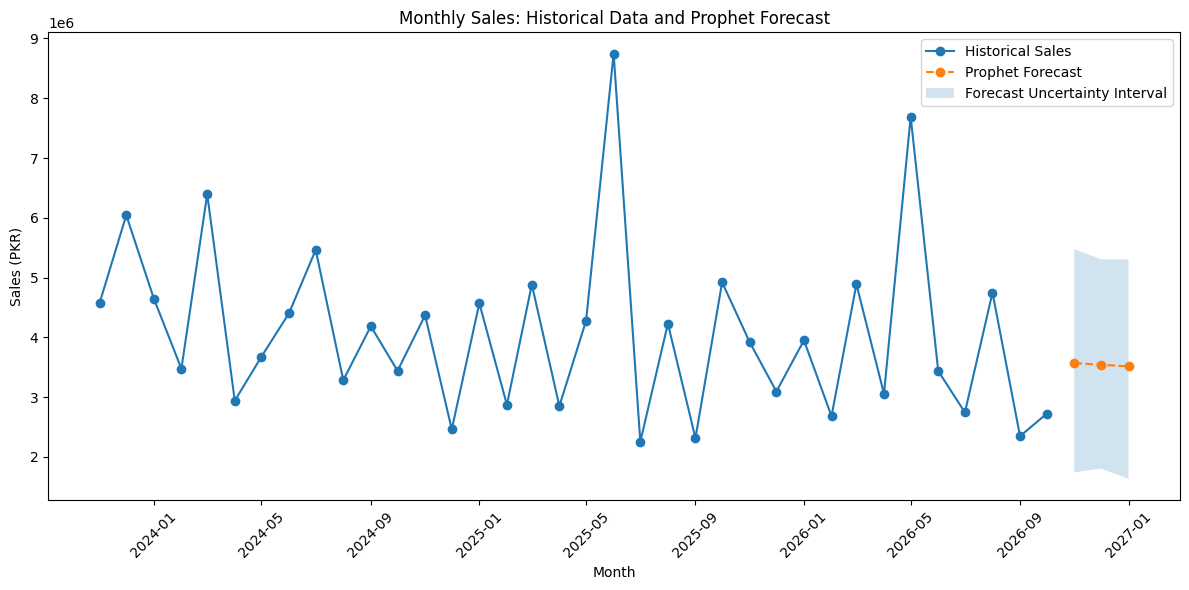

Q12 output folder: /content/drive/MyDrive/CT472_Project/Q12_Forecasting

Saved files:
model_evaluation_metrics.csv - 0.21 KB
monthly_sales_features.csv - 0.77 KB
monthly_sales_forecast.png - 286.88 KB
next_3_month_forecast.csv - 0.3 KB
prophet_rolling_validation.csv - 0.2 KB
prophet_test_predictions.csv - 0.32 KB
seasonal_naive_test_predictions.csv - 0.32 KB


In [ ]:
from pathlib import Path
import matplotlib.pyplot as plt

q12_output_path = Path(PROJECT_PATH) / "Q12_Forecasting"
q12_output_path.mkdir(parents=True, exist_ok=True)

q12_model_data.to_csv(
    q12_output_path / "monthly_sales_features.csv",
    index=False
)

q12_final_metrics.to_csv(
    q12_output_path / "model_evaluation_metrics.csv",
    index=False
)

q12_cv_results.to_csv(
    q12_output_path / "prophet_rolling_validation.csv",
    index=False
)

q12_prophet_evaluation.to_csv(
    q12_output_path / "prophet_test_predictions.csv",
    index=False
)

q12_baseline.to_csv(
    q12_output_path / "seasonal_naive_test_predictions.csv",
    index=False
)

q12_prophet_next3.to_csv(
    q12_output_path / "next_3_month_forecast.csv",
    index=False
)

plt.figure(figsize=(12, 6))

plt.plot(
    q12_model_data["ds"],
    q12_model_data["y"],
    marker="o",
    label="Historical Sales"
)

plt.plot(
    q12_prophet_next3["forecast_month"],
    q12_prophet_next3["prophet_forecast"],
    marker="o",
    linestyle="--",
    label="Prophet Forecast"
)

plt.fill_between(
    q12_prophet_next3["forecast_month"],
    q12_prophet_next3["lower_bound"],
    q12_prophet_next3["upper_bound"],
    alpha=0.2,
    label="Forecast Uncertainty Interval"
)

plt.title("Monthly Sales: Historical Data and Prophet Forecast")
plt.xlabel("Month")
plt.ylabel("Sales (PKR)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    q12_output_path / "monthly_sales_forecast.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Q12 output folder:", q12_output_path)
print("\nSaved files:")

for file in sorted(q12_output_path.iterdir()):
    print(file.name, "-", round(file.stat().st_size / 1024, 2), "KB")

In [ ]:
q12_feature_view_sql = """
CREATE OR REPLACE VIEW warehouse.vw_monthly_sales_forecast_features AS
SELECT
    d.year_number,
    d.month_number,
    DATE_TRUNC('month', d.full_date)::DATE AS month_start,
    SUM(f.sales_amount) AS monthly_sales,
    SUM(f.quantity) AS monthly_units,
    COUNT(*) AS transaction_lines
FROM warehouse.fact_sales f
JOIN warehouse.dim_date d
    ON f.date_key = d.date_key
WHERE d.full_date >= DATE '2023-11-01'
  AND d.full_date < DATE '2026-11-01'
GROUP BY
    d.year_number,
    d.month_number,
    DATE_TRUNC('month', d.full_date)::DATE;
"""

with sales_conn.cursor() as cursor:
    cursor.execute(q12_feature_view_sql)

sales_conn.commit()

q12_view_check = pd.read_sql_query(
    """
    SELECT *
    FROM warehouse.vw_monthly_sales_forecast_features
    ORDER BY month_start
    """,
    sales_conn
)

print("Feature view rows:", len(q12_view_check))
display(q12_view_check.head())
display(q12_view_check.tail())

Feature view rows: 36


/tmp/ipykernel_653/3858136971.py:26: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  q12_view_check = pd.read_sql_query(


,year_number,month_number,month_start,monthly_sales,monthly_units,transaction_lines
0,2023,11,2023-11-01,4574700.30,230,41
1,2023,12,2023-12-01,6044298.56,276,43
2,2024,1,2024-01-01,4648068.99,178,39
3,2024,2,2024-02-01,3475095.97,146,27
4,2024,3,2024-03-01,6395850.76,310,50


,year_number,month_number,month_start,monthly_sales,monthly_units,transaction_lines
31,2026,6,2026-06-01,3437367.34,125,27
32,2026,7,2026-07-01,2744239.86,148,28
33,2026,8,2026-08-01,4748741.51,178,33
34,2026,9,2026-09-01,2347191.24,100,22
35,2026,10,2026-10-01,2723815.56,163,27


In [ ]:
q12_view_check.to_csv(
    q12_output_path / "sql_feature_view_output.csv",
    index=False
)

with open(
    q12_output_path / "forecast_feature_view.sql",
    "w"
) as file:
    file.write(q12_feature_view_sql)

print("Q12 final evidence files:")

for file in sorted(q12_output_path.iterdir()):
    print(file.name)

Q12 final evidence files:
forecast_feature_view.sql
model_evaluation_metrics.csv
monthly_sales_features.csv
monthly_sales_forecast.png
next_3_month_forecast.csv
prophet_rolling_validation.csv
prophet_test_predictions.csv
seasonal_naive_test_predictions.csv
sql_feature_view_output.csv


TASK 13

In [ ]:
import pandas as pd
import numpy as np
q13_anomaly_query = """
SELECT
    d.year_number,
    d.month_number,
    DATE_TRUNC('month', d.full_date)::DATE AS month_start,
    l.region,
    SUM(f.sales_amount) AS monthly_sales,
    SUM(f.quantity) AS monthly_units,
    COUNT(*) AS transaction_lines
FROM warehouse.fact_sales f
JOIN warehouse.dim_date d
    ON f.date_key = d.date_key
JOIN warehouse.dim_location l
    ON f.location_key = l.location_key
WHERE d.full_date >= DATE '2023-11-01'
  AND d.full_date < DATE '2026-11-01'
GROUP BY
    d.year_number,
    d.month_number,
    DATE_TRUNC('month', d.full_date)::DATE,
    l.region
ORDER BY
    l.region,
    month_start;
"""

q13_regional_data = pd.read_sql_query(
    q13_anomaly_query,
    sales_conn
)

print("Total observations:", len(q13_regional_data))
print("Regions:", q13_regional_data["region"].nunique())
print("Unique months:", q13_regional_data["month_start"].nunique())

print("\nRecords per region:")
display(q13_regional_data.groupby("region").size())

print("\nFirst five records:")
display(q13_regional_data.head())

print("\nMissing values:")
print(q13_regional_data.isnull().sum())


/tmp/ipykernel_31552/3478151432.py:29: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  q13_regional_data = pd.read_sql_query(


Total observations: 139
Regions: 4
Unique months: 36

Records per region:


,0
region,
Central,36
North,36
South,34
West,33



First five records:


,year_number,month_number,month_start,region,monthly_sales,monthly_units,transaction_lines
0,2023,11,2023-11-01,Central,1569573.97,81,14
1,2023,12,2023-12-01,Central,1946679.67,85,13
2,2024,1,2024-01-01,Central,1864016.11,73,16
3,2024,2,2024-02-01,Central,1460957.43,52,9
4,2024,3,2024-03-01,Central,2519713.47,144,19



Missing values:
year_number          0
month_number         0
month_start          0
region               0
monthly_sales        0
monthly_units        0
transaction_lines    0
dtype: int64


In [ ]:

q13_regional_data["month_start"] = pd.to_datetime(
    q13_regional_data["month_start"]
)

q13_all_months = pd.date_range(
    start="2023-11-01",
    end="2026-10-01",
    freq="MS"
)

q13_all_regions = sorted(q13_regional_data["region"].unique())

q13_complete_index = pd.MultiIndex.from_product(
    [q13_all_regions, q13_all_months],
    names=["region", "month_start"]
)

q13_regional_data = (
    q13_regional_data
    .set_index(["region", "month_start"])
    .reindex(q13_complete_index)
    .reset_index()
)

q13_regional_data["monthly_sales"] = q13_regional_data["monthly_sales"].fillna(0)
q13_regional_data["monthly_units"] = q13_regional_data["monthly_units"].fillna(0)
q13_regional_data["transaction_lines"] = q13_regional_data["transaction_lines"].fillna(0)

q13_regional_data["year_number"] = q13_regional_data["month_start"].dt.year
q13_regional_data["month_number"] = q13_regional_data["month_start"].dt.month

q13_regional_data = q13_regional_data[
    [
        "year_number",
        "month_number",
        "month_start",
        "region",
        "monthly_sales",
        "monthly_units",
        "transaction_lines"
    ]
].sort_values(["region", "month_start"]).reset_index(drop=True)

print("Total observations:", len(q13_regional_data))
print("\nRecords per region:")
display(q13_regional_data.groupby("region").size())

print("\nZero-sales observations:", (q13_regional_data["monthly_sales"] == 0).sum())
print("\nMissing values:")
print(q13_regional_data.isnull().sum())


Total observations: 144

Records per region:


,0
region,
Central,36
North,36
South,36
West,36



Zero-sales observations: 5

Missing values:
year_number          0
month_number         0
month_start          0
region               0
monthly_sales        0
monthly_units        0
transaction_lines    0
dtype: int64


In [ ]:

q13_calibration = q13_regional_data[
    q13_regional_data["month_start"] <= "2026-04-01"
].copy()

q13_review = q13_regional_data[
    q13_regional_data["month_start"] > "2026-04-01"
].copy()

q13_thresholds = []

for region in q13_calibration["region"].unique():
    region_sales = q13_calibration.loc[
        q13_calibration["region"] == region,
        "monthly_sales"
    ]

    median_sales = region_sales.median()
    mad = (region_sales - median_sales).abs().median()

    spread = 1.4826 * mad

    if spread == 0:
        spread = region_sales.std()

    lower_limit = max(0, median_sales - 3 * spread)
    upper_limit = median_sales + 3 * spread

    q13_thresholds.append({
        "region": region,
        "median_sales": median_sales,
        "mad": mad,
        "lower_limit": lower_limit,
        "upper_limit": upper_limit
    })

q13_threshold_summary = pd.DataFrame(q13_thresholds)

q13_threshold_review = q13_review.merge(
    q13_threshold_summary,
    on="region",
    how="left"
)

q13_threshold_review["threshold_anomaly"] = np.select(
    [
        q13_threshold_review["monthly_sales"]
        < q13_threshold_review["lower_limit"],

        q13_threshold_review["monthly_sales"]
        > q13_threshold_review["upper_limit"]
    ],
    ["LOW", "HIGH"],
    default="NORMAL"
)

print("Calibration observations:", len(q13_calibration))
print("Review observations:", len(q13_review))

print("\nRegional thresholds:")
display(q13_threshold_summary.round(2))

print("\nStatistical anomaly results:")
display(
    q13_threshold_review[
        [
            "month_start",
            "region",
            "monthly_sales",
            "lower_limit",
            "upper_limit",
            "threshold_anomaly"
        ]
    ].round(2)
)

print("\nAnomaly counts:")
display(
    q13_threshold_review["threshold_anomaly"].value_counts()
)


Calibration observations: 120
Review observations: 24

Regional thresholds:


,region,median_sales,mad,lower_limit,upper_limit
0,Central,1064189.59,389919.40,0,2798473.12
1,North,1618495.64,607111.24,0,4318805.01
2,South,598893.04,288289.26,0,1881146.04
3,West,412943.94,252570.55,0,1536327.24



Statistical anomaly results:


,month_start,region,monthly_sales,lower_limit,upper_limit,threshold_anomaly
0,2026-05-01,Central,1300529.48,0,2798473.12,NORMAL
1,2026-06-01,Central,879057.37,0,2798473.12,NORMAL
2,2026-07-01,Central,891508.40,0,2798473.12,NORMAL
3,2026-08-01,Central,1413097.25,0,2798473.12,NORMAL
4,2026-09-01,Central,773999.38,0,2798473.12,NORMAL
5,2026-10-01,Central,1419904.27,0,2798473.12,NORMAL
6,2026-05-01,North,4644043.27,0,4318805.01,HIGH
7,2026-06-01,North,2327249.82,0,4318805.01,NORMAL
8,2026-07-01,North,1075539.17,0,4318805.01,NORMAL
9,2026-08-01,North,2430772.52,0,4318805.01,NORMAL



Anomaly counts:


,count
threshold_anomaly,
NORMAL,23
HIGH,1


In [ ]:

from sklearn.ensemble import IsolationForest

q13_iforest_results = []

q13_features = [
    "monthly_sales",
    "monthly_units",
    "transaction_lines"
]

for region in q13_regional_data["region"].unique():

    train_region = q13_calibration[
        q13_calibration["region"] == region
    ].copy()

    review_region = q13_review[
        q13_review["region"] == region
    ].copy()

    X_train = np.log1p(train_region[q13_features])
    X_review = np.log1p(review_region[q13_features])

    model = IsolationForest(
        n_estimators=200,
        contamination=0.05,
        random_state=472
    )

    model.fit(X_train)

    predictions = model.predict(X_review)
    scores = model.decision_function(X_review)

    review_region["iforest_prediction"] = predictions
    review_region["iforest_score"] = scores
    review_region["iforest_anomaly"] = np.where(
        predictions == -1,
        "ANOMALY",
        "NORMAL"
    )

    q13_iforest_results.append(review_region)

q13_iforest_results = pd.concat(
    q13_iforest_results,
    ignore_index=True
)

print("Isolation Forest review observations:",
      len(q13_iforest_results))

print("\nIsolation Forest classifications:")
display(
    q13_iforest_results["iforest_anomaly"].value_counts()
)

print("\nDetailed results:")
display(
    q13_iforest_results[
        [
            "month_start",
            "region",
            "monthly_sales",
            "iforest_score",
            "iforest_anomaly"
        ]
    ].sort_values(["region", "month_start"]).round(3)
)


Isolation Forest review observations: 24

Isolation Forest classifications:


,count
iforest_anomaly,
NORMAL,23
ANOMALY,1



Detailed results:


,month_start,region,monthly_sales,iforest_score,iforest_anomaly
0,2026-05-01,Central,1300529.48,0.156,NORMAL
1,2026-06-01,Central,879057.37,0.173,NORMAL
2,2026-07-01,Central,891508.40,0.205,NORMAL
3,2026-08-01,Central,1413097.25,0.200,NORMAL
4,2026-09-01,Central,773999.38,0.170,NORMAL
5,2026-10-01,Central,1419904.27,0.144,NORMAL
6,2026-05-01,North,4644043.27,0.042,NORMAL
7,2026-06-01,North,2327249.82,0.207,NORMAL
8,2026-07-01,North,1075539.17,0.122,NORMAL
9,2026-08-01,North,2430772.52,0.184,NORMAL


In [ ]:

q13_comparison = q13_threshold_review[
    [
        "month_start",
        "region",
        "monthly_sales",
        "threshold_anomaly"
    ]
].merge(
    q13_iforest_results[
        [
            "month_start",
            "region",
            "iforest_anomaly"
        ]
    ],
    on=["month_start", "region"],
    how="inner"
)

q13_comparison["agreement"] = np.where(
    (q13_comparison["threshold_anomaly"] == "NORMAL")
    == (q13_comparison["iforest_anomaly"] == "NORMAL"),
    "AGREE",
    "DISAGREE"
)

print("Method comparison:")
display(q13_comparison)

print("\nAgreement summary:")
display(q13_comparison["agreement"].value_counts())

print("\nFlagged observations:")
display(
    q13_comparison[
        (q13_comparison["threshold_anomaly"] != "NORMAL")
        | (q13_comparison["iforest_anomaly"] != "NORMAL")
    ]
)


Method comparison:


,month_start,region,monthly_sales,threshold_anomaly,iforest_anomaly,agreement
0,2026-05-01,Central,1300529.48,NORMAL,NORMAL,AGREE
1,2026-06-01,Central,879057.37,NORMAL,NORMAL,AGREE
2,2026-07-01,Central,891508.40,NORMAL,NORMAL,AGREE
3,2026-08-01,Central,1413097.25,NORMAL,NORMAL,AGREE
4,2026-09-01,Central,773999.38,NORMAL,NORMAL,AGREE
5,2026-10-01,Central,1419904.27,NORMAL,NORMAL,AGREE
6,2026-05-01,North,4644043.27,HIGH,NORMAL,DISAGREE
7,2026-06-01,North,2327249.82,NORMAL,NORMAL,AGREE
8,2026-07-01,North,1075539.17,NORMAL,NORMAL,AGREE
9,2026-08-01,North,2430772.52,NORMAL,NORMAL,AGREE



Agreement summary:


,count
agreement,
AGREE,22
DISAGREE,2



Flagged observations:


,month_start,region,monthly_sales,threshold_anomaly,iforest_anomaly,agreement
6,2026-05-01,North,4644043.27,HIGH,NORMAL,DISAGREE
19,2026-06-01,West,0.00,NORMAL,ANOMALY,DISAGREE


In [ ]:

q13_injected_data = q13_review.copy()

q13_injected_data["known_anomaly"] = 0

q13_injection_cases = [
    ("Central", "2026-05-01", 8.0),
    ("North", "2026-06-01", 0.0),
    ("South", "2026-07-01", 7.0),
    ("West", "2026-08-01", 0.0)
]

for region, month, multiplier in q13_injection_cases:
    mask = (
        (q13_injected_data["region"] == region)
        & (q13_injected_data["month_start"] == month)
    )

    q13_injected_data.loc[mask, "monthly_sales"] *= multiplier
    q13_injected_data.loc[mask, "known_anomaly"] = 1

print("Injected dataset observations:", len(q13_injected_data))
print("Injected anomalies:", q13_injected_data["known_anomaly"].sum())

print("\nInjected test cases:")
display(
    q13_injected_data[
        q13_injected_data["known_anomaly"] == 1
    ][
        ["month_start", "region", "monthly_sales", "known_anomaly"]
    ]
)


Injected dataset observations: 24
Injected anomalies: 4

Injected test cases:


,month_start,region,monthly_sales,known_anomaly
30,2026-05-01,Central,10404235.84,1
67,2026-06-01,North,0.00,1
104,2026-07-01,South,4948722.17,1
141,2026-08-01,West,0.00,1


In [ ]:

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

q13_injected_data = q13_injected_data.merge(
    q13_threshold_summary[
        ["region", "lower_limit", "upper_limit"]
    ],
    on="region",
    how="left"
)

q13_injected_data["threshold_prediction"] = (
    (q13_injected_data["monthly_sales"] < q13_injected_data["lower_limit"])
    | (q13_injected_data["monthly_sales"] > q13_injected_data["upper_limit"])
).astype(int)

q13_injected_data["iforest_prediction"] = 0

for region in q13_injected_data["region"].unique():

    train_region = q13_calibration[
        q13_calibration["region"] == region
    ]

    test_mask = q13_injected_data["region"] == region

    X_train = np.log1p(train_region[q13_features])
    X_test = np.log1p(
        q13_injected_data.loc[test_mask, q13_features]
    )

    model = IsolationForest(
        n_estimators=200,
        contamination=0.05,
        random_state=472
    )

    model.fit(X_train)

    predictions = model.predict(X_test)

    q13_injected_data.loc[
        test_mask, "iforest_prediction"
    ] = (predictions == -1).astype(int)

q13_evaluation_rows = []

for method, prediction_column in [
    ("Statistical Threshold", "threshold_prediction"),
    ("Isolation Forest", "iforest_prediction")
]:

    actual = q13_injected_data["known_anomaly"]
    predicted = q13_injected_data[prediction_column]

    tn, fp, fn, tp = confusion_matrix(
        actual, predicted, labels=[0, 1]
    ).ravel()

    q13_evaluation_rows.append({
        "method": method,
        "true_positives": tp,
        "false_positives": fp,
        "true_negatives": tn,
        "false_negatives": fn,
        "precision": precision_score(actual, predicted, zero_division=0),
        "recall": recall_score(actual, predicted, zero_division=0),
        "f1_score": f1_score(actual, predicted, zero_division=0),
        "false_alerts": fp
    })

q13_injection_metrics = pd.DataFrame(q13_evaluation_rows)

print("Injected anomaly evaluation:")
display(q13_injection_metrics.round(3))

print("\nDetailed injected test classifications:")
display(
    q13_injected_data[
        [
            "month_start",
            "region",
            "monthly_sales",
            "known_anomaly",
            "threshold_prediction",
            "iforest_prediction"
        ]
    ].sort_values(["region", "month_start"])
)


Injected anomaly evaluation:


,method,true_positives,false_positives,true_negatives,false_negatives,precision,recall,f1_score,false_alerts
0,Statistical Threshold,2,1,19,2,0.667,0.5,0.571,1
1,Isolation Forest,0,1,19,4,0.000,0.0,0.000,1



Detailed injected test classifications:


,month_start,region,monthly_sales,known_anomaly,threshold_prediction,iforest_prediction
0,2026-05-01,Central,10404235.84,1,1,0
1,2026-06-01,Central,879057.37,0,0,0
2,2026-07-01,Central,891508.40,0,0,0
3,2026-08-01,Central,1413097.25,0,0,0
4,2026-09-01,Central,773999.38,0,0,0
5,2026-10-01,Central,1419904.27,0,0,0
6,2026-05-01,North,4644043.27,0,1,0
7,2026-06-01,North,0.00,1,0,0
8,2026-07-01,North,1075539.17,0,0,0
9,2026-08-01,North,2430772.52,0,0,0


In [ ]:

q13_lineage_query = """
WITH selected_cases AS (
    SELECT 'North' AS region, DATE '2026-05-01' AS month_start,
           'Original statistical alert' AS case_type
    UNION ALL
    SELECT 'West', DATE '2026-06-01',
           'Original Isolation Forest alert'
    UNION ALL
    SELECT 'South', DATE '2026-07-01',
           'Injected test case - original source data'
)
SELECT
    c.case_type,
    c.region,
    c.month_start,
    COUNT(DISTINCT f.sales_fact_key) AS fact_records,
    SUM(f.sales_amount) AS original_sales_amount,
    SUM(f.quantity) AS original_units,
    COUNT(DISTINCT rl.target_record_id) AS traced_records,
    STRING_AGG(DISTINCT rl.source_object_id, ', ') AS source_objects,
    STRING_AGG(DISTINCT rl.source_system_id, ', ') AS source_systems,
    STRING_AGG(DISTINCT rl.batch_id, ', ') AS source_batches
FROM selected_cases c
JOIN warehouse.dim_location l
    ON l.region = c.region
JOIN warehouse.dim_date d
    ON DATE_TRUNC('month', d.full_date)::DATE = c.month_start
JOIN warehouse.fact_sales f
    ON f.location_key = l.location_key
   AND f.date_key = d.date_key
LEFT JOIN warehouse.meta_record_lineage rl
    ON rl.target_table = 'warehouse.fact_sales'
   AND rl.target_record_id = f.sales_fact_key::TEXT
GROUP BY
    c.case_type,
    c.region,
    c.month_start
ORDER BY c.month_start, c.region;
"""

q13_lineage_review = pd.read_sql_query(
    q13_lineage_query,
    sales_conn
)

print("Three-case source lineage review:")
display(q13_lineage_review)

print("\nLineage coverage:")
print(
    "Fact records:",
    q13_lineage_review["fact_records"].sum()
)
print(
    "Traced records:",
    q13_lineage_review["traced_records"].sum()
)


/tmp/ipykernel_31552/1690852834.py:41: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  q13_lineage_review = pd.read_sql_query(


Three-case source lineage review:


,case_type,region,month_start,fact_records,original_sales_amount,original_units,traced_records,source_objects,source_systems,source_batches
0,Original statistical alert,North,2026-05-01,36,4644043.27,191,36,SRC_SALES:public.sales_transaction_lines,SRC_SALES,INITIAL_SALES_001
1,Injected test case - original source data,South,2026-07-01,10,706960.31,44,10,SRC_SALES:public.sales_transaction_lines,SRC_SALES,INITIAL_SALES_001



Lineage coverage:
Fact records: 46
Traced records: 46


In [ ]:

q13_lineage_query = """
WITH selected_cases AS (
    SELECT 'North' AS region, DATE '2026-05-01' AS month_start,
           'Original statistical alert' AS case_type
    UNION ALL
    SELECT 'West', DATE '2026-06-01',
           'Original Isolation Forest alert'
    UNION ALL
    SELECT 'South', DATE '2026-07-01',
           'Injected test case - original source data'
)
SELECT
    c.case_type,
    c.region,
    c.month_start,
    COUNT(DISTINCT f.sales_fact_key) AS fact_records,
    COALESCE(SUM(f.sales_amount), 0) AS original_sales_amount,
    COALESCE(SUM(f.quantity), 0) AS original_units,
    COUNT(DISTINCT rl.target_record_id) AS traced_records,
    STRING_AGG(DISTINCT rl.source_object_id, ', ') AS source_objects,
    STRING_AGG(DISTINCT rl.source_system_id, ', ') AS source_systems,
    STRING_AGG(DISTINCT rl.batch_id, ', ') AS source_batches
FROM selected_cases c
JOIN warehouse.dim_location l
    ON l.region = c.region
JOIN warehouse.dim_date d
    ON DATE_TRUNC('month', d.full_date)::DATE = c.month_start
LEFT JOIN warehouse.fact_sales f
    ON f.location_key = l.location_key
   AND f.date_key = d.date_key
LEFT JOIN warehouse.meta_record_lineage rl
    ON rl.target_table = 'warehouse.fact_sales'
   AND rl.target_record_id = f.sales_fact_key::TEXT
GROUP BY
    c.case_type,
    c.region,
    c.month_start
ORDER BY c.month_start, c.region;
"""

q13_lineage_review = pd.read_sql_query(
    q13_lineage_query,
    sales_conn
)

print("Three-case source lineage review:")
display(q13_lineage_review)

print("\nLineage coverage:")
print("Fact records:", q13_lineage_review["fact_records"].sum())
print("Traced records:", q13_lineage_review["traced_records"].sum())


/tmp/ipykernel_31552/3858732435.py:41: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  q13_lineage_review = pd.read_sql_query(


Three-case source lineage review:


,case_type,region,month_start,fact_records,original_sales_amount,original_units,traced_records,source_objects,source_systems,source_batches
0,Original statistical alert,North,2026-05-01,36,4644043.27,191,36,SRC_SALES:public.sales_transaction_lines,SRC_SALES,INITIAL_SALES_001
1,Original Isolation Forest alert,West,2026-06-01,0,0.00,0,0,None,None,None
2,Injected test case - original source data,South,2026-07-01,10,706960.31,44,10,SRC_SALES:public.sales_transaction_lines,SRC_SALES,INITIAL_SALES_001



Lineage coverage:
Fact records: 46
Traced records: 46


In [ ]:

from pathlib import Path

q13_output_path = Path(PROJECT_PATH) / "Q13_Anomaly_Detection"
q13_output_path.mkdir(parents=True, exist_ok=True)

q13_regional_data.to_csv(
    q13_output_path / "regional_monthly_sales_features.csv",
    index=False
)

q13_threshold_summary.to_csv(
    q13_output_path / "statistical_thresholds.csv",
    index=False
)

q13_threshold_review.to_csv(
    q13_output_path / "statistical_anomaly_results.csv",
    index=False
)

q13_iforest_results.to_csv(
    q13_output_path / "isolation_forest_results.csv",
    index=False
)

q13_comparison.to_csv(
    q13_output_path / "method_comparison.csv",
    index=False
)

q13_injected_data.to_csv(
    q13_output_path / "injected_anomaly_test.csv",
    index=False
)

q13_injection_metrics.to_csv(
    q13_output_path / "anomaly_model_evaluation.csv",
    index=False
)

q13_lineage_review.to_csv(
    q13_output_path / "three_case_source_lineage.csv",
    index=False
)

print("Q13 evidence files saved:")
for file in sorted(q13_output_path.iterdir()):
    print(file.name)

print("\nTotal files:", len(list(q13_output_path.iterdir())))


Q13 evidence files saved:
anomaly_model_evaluation.csv
injected_anomaly_test.csv
isolation_forest_results.csv
method_comparison.csv
regional_monthly_sales_features.csv
statistical_anomaly_results.csv
statistical_thresholds.csv
three_case_source_lineage.csv

Total files: 8


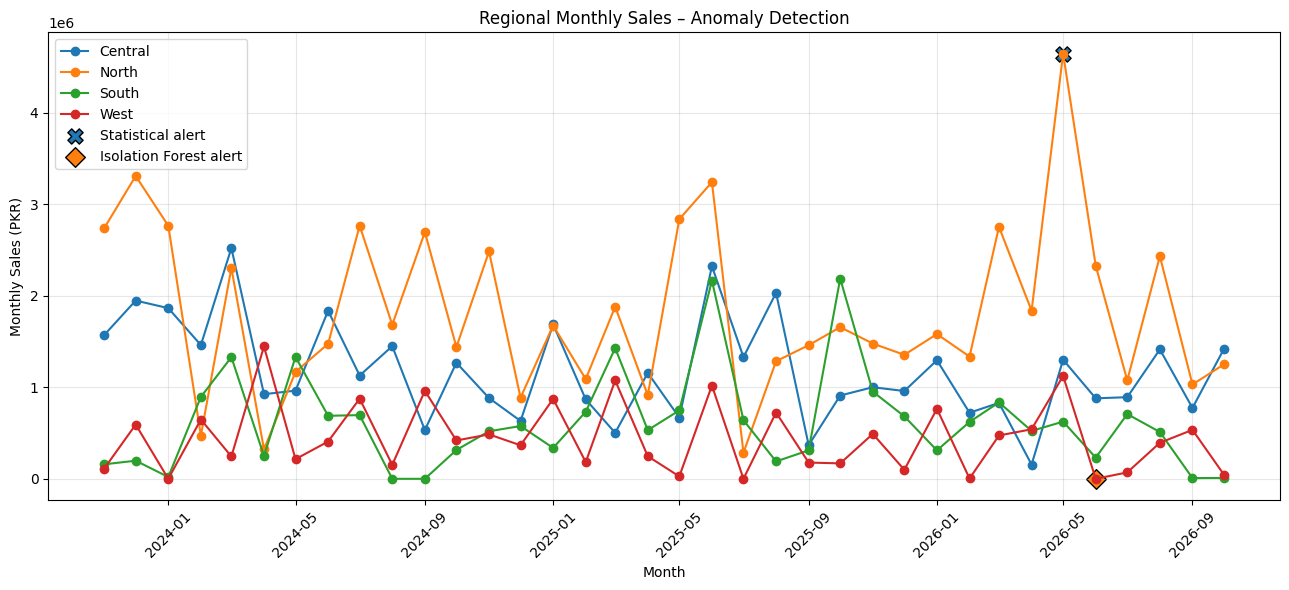

In [ ]:

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(13, 6))

for region in sorted(q13_regional_data["region"].unique()):
    region_data = q13_regional_data[
        q13_regional_data["region"] == region
    ].sort_values("month_start")

    ax.plot(
        region_data["month_start"],
        region_data["monthly_sales"],
        marker="o",
        label=region
    )

for _, row in q13_threshold_review[
    q13_threshold_review["threshold_anomaly"] != "NORMAL"
].iterrows():
    ax.scatter(
        row["month_start"],
        row["monthly_sales"],
        marker="X",
        s=120,
        edgecolors="black",
        label="Statistical alert"
    )

for _, row in q13_iforest_results[
    q13_iforest_results["iforest_anomaly"] == "ANOMALY"
].iterrows():
    ax.scatter(
        row["month_start"],
        row["monthly_sales"],
        marker="D",
        s=100,
        edgecolors="black",
        label="Isolation Forest alert"
    )

ax.set_title("Regional Monthly Sales – Anomaly Detection")
ax.set_xlabel("Month")
ax.set_ylabel("Monthly Sales (PKR)")
ax.legend()
ax.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    q13_output_path / "q13_anomaly_detection.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [ ]:

q13_feature_view_sql = """
CREATE OR REPLACE VIEW warehouse.vw_region_monthly_sales_anomaly_features AS
SELECT
    d.year_number,
    d.month_number,
    DATE_TRUNC('month', d.full_date)::DATE AS month_start,
    l.region,
    SUM(f.sales_amount) AS monthly_sales,
    SUM(f.quantity) AS monthly_units,
    COUNT(*) AS transaction_lines
FROM warehouse.fact_sales f
JOIN warehouse.dim_date d
    ON f.date_key = d.date_key
JOIN warehouse.dim_location l
    ON f.location_key = l.location_key
WHERE d.full_date >= DATE '2023-11-01'
  AND d.full_date < DATE '2026-11-01'
GROUP BY
    d.year_number,
    d.month_number,
    DATE_TRUNC('month', d.full_date)::DATE,
    l.region;
"""

with open(
    q13_output_path / "anomaly_feature_view.sql",
    "w"
) as file:
    file.write(q13_feature_view_sql)

with sales_conn.cursor() as cursor:
    cursor.execute(q13_feature_view_sql)

sales_conn.commit()

q13_sql_view_output = pd.read_sql_query(
    """
    SELECT *
    FROM warehouse.vw_region_monthly_sales_anomaly_features
    ORDER BY region, month_start
    """,
    sales_conn
)

q13_sql_view_output.to_csv(
    q13_output_path / "sql_anomaly_feature_view_output.csv",
    index=False
)

print("SQL view created successfully.")
print("SQL view rows:", len(q13_sql_view_output))
print("SQL output saved.")
print("Evidence files:", len(list(q13_output_path.iterdir())))


/tmp/ipykernel_31552/930738184.py:36: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  q13_sql_view_output = pd.read_sql_query(


SQL view created successfully.
SQL view rows: 139
SQL output saved.
Evidence files: 11


### Q13 – Anomaly Detection and Investigation

**Objective:** Identify unusual regional monthly sales patterns using a statistical threshold method and Isolation Forest, evaluate detection performance, and trace selected cases through warehouse lineage.

**1. Anomaly feature dataset**

A SQL feature view, `warehouse.vw_region_monthly_sales_anomaly_features`, aggregates sales by region and month. It contains monthly sales, units, and transaction-line counts.

The original SQL view returned 139 observations. Python expanded this to a complete panel of 144 observations covering four regions over 36 months. Missing region-month combinations were assigned zero sales, zero units, and zero transaction lines.

**2. Statistical threshold method**

Region-specific thresholds were calculated using the median and Median Absolute Deviation (MAD), calibrated on the first 30 months (November 2023–April 2026). The final six months (May–October 2026) were reserved for review.

The method identified one high-sales observation: North, May 2026, with PKR 4,644,043.27.

The lower threshold was zero for all regions, so zero-sales observations were not identified as low anomalies by the strict lower-bound comparison. This is a limitation of the selected threshold method.

**3. Isolation Forest**

Isolation Forest used log-transformed monthly sales, units, and transaction-line counts. It was trained on the same 30-month calibration period, using 200 trees, contamination of 0.05, and random state 472.

It identified one observation in the review period: West, June 2026, with zero sales. The statistical and Isolation Forest methods identified different observations.

**4. Method comparison**

The two methods were compared over 24 review observations. There were 23 observations classified as normal by both methods and one disagreement, with each method flagging a different observation.

**5. Controlled injected-anomaly evaluation**

A separate copy of the six-month review dataset was used to inject four known anomalies. The original warehouse data was not modified.

| Method | Precision | Recall | F1-score | False alerts |
|---|---:|---:|---:|---:|
| Statistical Threshold | 0.667 | 0.500 | 0.571 | 1 |
| Isolation Forest | 0.000 | 0.000 | 0.000 | 1 |

The statistical method detected two of four injected anomalies. Isolation Forest did not detect any of the four injected cases in this test. These results show that the methods have limitations and require further calibration before operational use.

**6. Source lineage investigation**

Three cases were reviewed:

- North, May 2026: 36 fact records, all 36 traced to `SRC_SALES`.
- West, June 2026: zero fact records and zero traced records, consistent with the absence of recorded sales transactions.
- South, July 2026: 10 original fact records, all 10 traced to `SRC_SALES`. The injected test multiplier was applied only to the separate evaluation copy.

Overall, all 46 existing fact records in the three reviewed cases had complete lineage coverage.

**7. Evidence and limitations**

The `Q13_Anomaly_Detection` folder contains the regional monthly feature data, statistical thresholds, statistical results, Isolation Forest results, method comparison, injected test data, evaluation metrics, lineage review, anomaly chart, SQL feature view, and SQL view output.

The anomaly methods identify unusual observations, not confirmed fraud, errors, or business causes. Flagged observations require human investigation. The six-month review period and four injected test cases are limited evaluation samples, so the reported metrics should not be interpreted as proof of future detection performance.

**Conclusion:** Q13 demonstrates a complete anomaly-detection workflow, including feature engineering, calibration, anomaly identification, controlled evaluation, and source lineage investigation. Both methods are retained with their limitations documented.

TASK 14

In [ ]:

q14_create_tables_sql = """
CREATE TABLE IF NOT EXISTS warehouse.model_run (
    model_run_id BIGSERIAL PRIMARY KEY,
    run_key VARCHAR(100) NOT NULL UNIQUE,
    model_name VARCHAR(100) NOT NULL,
    model_version VARCHAR(50),
    task_type VARCHAR(30) NOT NULL,
    source_view VARCHAR(150),
    training_start DATE,
    training_end DATE,
    evaluation_start DATE,
    evaluation_end DATE,
    parameters JSONB,
    metrics JSONB,
    run_status VARCHAR(30) NOT NULL DEFAULT 'COMPLETED',
    created_at TIMESTAMPTZ NOT NULL DEFAULT CURRENT_TIMESTAMP
);

CREATE TABLE IF NOT EXISTS warehouse.forecast_result (
    forecast_result_id BIGSERIAL PRIMARY KEY,
    model_run_id BIGINT NOT NULL
        REFERENCES warehouse.model_run(model_run_id),
    forecast_month DATE NOT NULL,
    forecast_value NUMERIC(18,2) NOT NULL,
    lower_bound NUMERIC(18,2),
    upper_bound NUMERIC(18,2),
    actual_value NUMERIC(18,2),
    forecast_type VARCHAR(30) NOT NULL DEFAULT 'FUTURE',
    created_at TIMESTAMPTZ NOT NULL DEFAULT CURRENT_TIMESTAMP,
    UNIQUE (model_run_id, forecast_month)
);

CREATE TABLE IF NOT EXISTS warehouse.anomaly_result (
    anomaly_result_id BIGSERIAL PRIMARY KEY,
    model_run_id BIGINT NOT NULL
        REFERENCES warehouse.model_run(model_run_id),
    month_start DATE NOT NULL,
    region VARCHAR(100) NOT NULL,
    observed_sales NUMERIC(18,2) NOT NULL,
    detector_method VARCHAR(50) NOT NULL,
    anomaly_label VARCHAR(30) NOT NULL,
    anomaly_score NUMERIC(18,6),
    lower_threshold NUMERIC(18,2),
    upper_threshold NUMERIC(18,2),
    created_at TIMESTAMPTZ NOT NULL DEFAULT CURRENT_TIMESTAMP,
    UNIQUE (model_run_id, month_start, region)
);

CREATE INDEX IF NOT EXISTS idx_forecast_result_month
    ON warehouse.forecast_result(forecast_month);

CREATE INDEX IF NOT EXISTS idx_anomaly_result_month_region
    ON warehouse.anomaly_result(month_start, region);
"""

with sales_conn.cursor() as cursor:
    cursor.execute(q14_create_tables_sql)

sales_conn.commit()

q14_table_check = pd.read_sql_query(
    """
    SELECT table_name
    FROM information_schema.tables
    WHERE table_schema = 'warehouse'
      AND table_name IN (
          'model_run',
          'forecast_result',
          'anomaly_result'
      )
    ORDER BY table_name;
    """,
    sales_conn
)

print("Q14 warehouse tables:")
display(q14_table_check)
print("Tables created:", len(q14_table_check))


/tmp/ipykernel_31552/2860427595.py:61: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  q14_table_check = pd.read_sql_query(


Q14 warehouse tables:


,table_name
0,anomaly_result
1,forecast_result
2,model_run


Tables created: 3


In [ ]:

import json

q14_forecast_runs = [
    {
        "run_key": "Q12_PROPHET_V1",
        "model_name": "Prophet",
        "model_version": "1.0",
        "task_type": "FORECAST",
        "source_view": "warehouse.fact_sales + warehouse.dim_date",
        "parameters": {
            "yearly_seasonality": False,
            "weekly_seasonality": False,
            "daily_seasonality": False,
            "changepoint_prior_scale": 0.1,
            "n_changepoints": 8
        },
        "metrics": {
            "test_mae": 1140186.41,
            "test_rmse": 1159823.22,
            "test_mape_percent": 39.75,
            "test_mean_error": -509949.70,
            "rolling_cv_mae": 965552.64
        }
    },
    {
        "run_key": "Q12_SEASONAL_NAIVE_V1",
        "model_name": "Seasonal Naive",
        "model_version": "1.0",
        "task_type": "FORECAST",
        "source_view": "warehouse.fact_sales + warehouse.dim_date",
        "parameters": {
            "forecast_method": "Same month previous year",
            "seasonal_period": 12
        },
        "metrics": {
            "test_mae": 916521.09,
            "test_rmse": 1303887.04,
            "test_mape_percent": 31.00,
            "test_mean_error": -548581.99
        }
    }
]

q14_insert_run_sql = """
INSERT INTO warehouse.model_run (
    run_key,
    model_name,
    model_version,
    task_type,
    source_view,
    training_start,
    training_end,
    evaluation_start,
    evaluation_end,
    parameters,
    metrics,
    run_status
)
VALUES (
    %s, %s, %s, %s, %s,
    %s, %s, %s, %s,
    %s::jsonb, %s::jsonb, 'COMPLETED'
)
ON CONFLICT (run_key)
DO UPDATE SET
    model_name = EXCLUDED.model_name,
    model_version = EXCLUDED.model_version,
    parameters = EXCLUDED.parameters,
    metrics = EXCLUDED.metrics,
    run_status = EXCLUDED.run_status;
"""

with sales_conn.cursor() as cursor:
    for run in q14_forecast_runs:
        cursor.execute(
            q14_insert_run_sql,
            (
                run["run_key"],
                run["model_name"],
                run["model_version"],
                run["task_type"],
                run["source_view"],
                "2023-11-01",
                "2026-07-01",
                "2026-08-01",
                "2026-10-01",
                json.dumps(run["parameters"]),
                json.dumps(run["metrics"])
            )
        )

sales_conn.commit()

q14_run_check = pd.read_sql_query(
    """
    SELECT
        model_run_id,
        run_key,
        model_name,
        task_type,
        training_start,
        training_end,
        evaluation_start,
        evaluation_end,
        run_status
    FROM warehouse.model_run
    ORDER BY model_run_id;
    """,
    sales_conn
)

display(q14_run_check)
print("Registered forecasting runs:", len(q14_run_check))


/tmp/ipykernel_31552/2076549555.py:94: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  q14_run_check = pd.read_sql_query(


,model_run_id,run_key,model_name,task_type,training_start,training_end,evaluation_start,evaluation_end,run_status
0,1,Q12_PROPHET_V1,Prophet,FORECAST,2023-11-01,2026-07-01,2026-08-01,2026-10-01,COMPLETED
1,2,Q12_SEASONAL_NAIVE_V1,Seasonal Naive,FORECAST,2023-11-01,2026-07-01,2026-08-01,2026-10-01,COMPLETED


Registered forecasting runs: 2


In [ ]:

q14_anomaly_runs = [
    {
        "run_key": "Q13_STATISTICAL_THRESHOLD_V1",
        "model_name": "Statistical Threshold MAD",
        "model_version": "1.0",
        "task_type": "ANOMALY",
        "source_view": "warehouse.vw_region_monthly_sales_anomaly_features",
        "parameters": {
            "method": "Median plus/minus 3 scaled MAD",
            "calibration_months": 30,
            "review_months": 6,
            "mad_scaling_factor": 1.4826,
            "regions": ["Central", "North", "South", "West"]
        },
        "metrics": {
            "injected_test_precision": 0.667,
            "injected_test_recall": 0.500,
            "injected_test_f1": 0.571,
            "injected_test_false_alerts": 1,
            "injected_test_true_positives": 2,
            "injected_test_false_negatives": 2
        }
    },
    {
        "run_key": "Q13_ISOLATION_FOREST_V1",
        "model_name": "Isolation Forest",
        "model_version": "1.0",
        "task_type": "ANOMALY",
        "source_view": "warehouse.vw_region_monthly_sales_anomaly_features",
        "parameters": {
            "n_estimators": 200,
            "contamination": 0.05,
            "random_state": 472,
            "features": [
                "monthly_sales",
                "monthly_units",
                "transaction_lines"
            ],
            "log_transform": "log1p"
        },
        "metrics": {
            "injected_test_precision": 0.000,
            "injected_test_recall": 0.000,
            "injected_test_f1": 0.000,
            "injected_test_false_alerts": 1,
            "injected_test_true_positives": 0,
            "injected_test_false_negatives": 4
        }
    }
]

q14_insert_run_sql = """
INSERT INTO warehouse.model_run (
    run_key,
    model_name,
    model_version,
    task_type,
    source_view,
    training_start,
    training_end,
    evaluation_start,
    evaluation_end,
    parameters,
    metrics,
    run_status
)
VALUES (
    %s, %s, %s, %s, %s,
    %s, %s, %s, %s,
    %s::jsonb, %s::jsonb, 'COMPLETED'
)
ON CONFLICT (run_key)
DO UPDATE SET
    model_name = EXCLUDED.model_name,
    model_version = EXCLUDED.model_version,
    parameters = EXCLUDED.parameters,
    metrics = EXCLUDED.metrics,
    run_status = EXCLUDED.run_status;
"""

with sales_conn.cursor() as cursor:
    for run in q14_anomaly_runs:
        cursor.execute(
            q14_insert_run_sql,
            (
                run["run_key"],
                run["model_name"],
                run["model_version"],
                run["task_type"],
                run["source_view"],
                "2023-11-01",
                "2026-04-01",
                "2026-05-01",
                "2026-10-01",
                json.dumps(run["parameters"]),
                json.dumps(run["metrics"])
            )
        )

sales_conn.commit()

q14_anomaly_run_check = pd.read_sql_query(
    """
    SELECT
        model_run_id,
        run_key,
        model_name,
        task_type,
        training_start,
        training_end,
        evaluation_start,
        evaluation_end,
        run_status
    FROM warehouse.model_run
    WHERE task_type = 'ANOMALY'
    ORDER BY model_run_id;
    """,
    sales_conn
)

display(q14_anomaly_run_check)
print("Registered anomaly runs:", len(q14_anomaly_run_check))


/tmp/ipykernel_31552/26405980.py:102: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  q14_anomaly_run_check = pd.read_sql_query(


,model_run_id,run_key,model_name,task_type,training_start,training_end,evaluation_start,evaluation_end,run_status
0,3,Q13_STATISTICAL_THRESHOLD_V1,Statistical Threshold MAD,ANOMALY,2023-11-01,2026-04-01,2026-05-01,2026-10-01,COMPLETED
1,4,Q13_ISOLATION_FOREST_V1,Isolation Forest,ANOMALY,2023-11-01,2026-04-01,2026-05-01,2026-10-01,COMPLETED


Registered anomaly runs: 2


In [ ]:

q12_prophet_next3 = pd.DataFrame({
    "forecast_month": pd.to_datetime([
        "2026-11-01",
        "2026-12-01",
        "2027-01-01"
    ]),
    "prophet_forecast": [
        3568667.41,
        3541933.84,
        3514309.16
    ],
    "lower_bound": [
        1742409.98,
        1804767.10,
        1633841.37
    ],
    "upper_bound": [
        5473709.85,
        5306450.24,
        5307111.63
    ],
    "seasonal_naive_forecast": [
        3920258.50,
        3093675.18,
        3950866.11
    ]
})

q14_forecast_insert_sql = """
INSERT INTO warehouse.forecast_result (
    model_run_id,
    forecast_month,
    forecast_value,
    lower_bound,
    upper_bound,
    actual_value,
    forecast_type
)
VALUES (%s, %s, %s, %s, %s, NULL, 'FUTURE')
ON CONFLICT (model_run_id, forecast_month)
DO UPDATE SET
    forecast_value = EXCLUDED.forecast_value,
    lower_bound = EXCLUDED.lower_bound,
    upper_bound = EXCLUDED.upper_bound,
    forecast_type = EXCLUDED.forecast_type;
"""

with sales_conn.cursor() as cursor:
    for _, row in q12_prophet_next3.iterrows():

        cursor.execute(
            q14_forecast_insert_sql,
            (
                1,
                row["forecast_month"].date(),
                float(row["prophet_forecast"]),
                float(row["lower_bound"]),
                float(row["upper_bound"])
            )
        )

        cursor.execute(
            q14_forecast_insert_sql,
            (
                2,
                row["forecast_month"].date(),
                float(row["seasonal_naive_forecast"]),
                None,
                None
            )
        )

sales_conn.commit()

q14_forecast_check = pd.read_sql_query(
    """
    SELECT
        mr.run_key,
        fr.forecast_month,
        fr.forecast_value,
        fr.lower_bound,
        fr.upper_bound,
        fr.forecast_type
    FROM warehouse.forecast_result fr
    JOIN warehouse.model_run mr
        ON fr.model_run_id = mr.model_run_id
    ORDER BY mr.model_run_id, fr.forecast_month;
    """,
    sales_conn
)

display(q14_forecast_check)

print("Total forecast records:", len(q14_forecast_check))


/tmp/ipykernel_31552/3066087073.py:75: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  q14_forecast_check = pd.read_sql_query(


,run_key,forecast_month,forecast_value,lower_bound,upper_bound,forecast_type
0,Q12_PROPHET_V1,2026-11-01,3568667.41,1742409.98,5473709.85,FUTURE
1,Q12_PROPHET_V1,2026-12-01,3541933.84,1804767.10,5306450.24,FUTURE
2,Q12_PROPHET_V1,2027-01-01,3514309.16,1633841.37,5307111.63,FUTURE
3,Q12_SEASONAL_NAIVE_V1,2026-11-01,3920258.50,NaN,NaN,FUTURE
4,Q12_SEASONAL_NAIVE_V1,2026-12-01,3093675.18,NaN,NaN,FUTURE
5,Q12_SEASONAL_NAIVE_V1,2027-01-01,3950866.11,NaN,NaN,FUTURE


Total forecast records: 6


In [ ]:

q14_threshold_data = q13_threshold_review.copy()

if "lower_limit" not in q14_threshold_data.columns:
    q14_threshold_data = q14_threshold_data.merge(
        q13_threshold_summary[
            ["region", "lower_limit", "upper_limit"]
        ],
        on="region",
        how="left"
    )

q14_anomaly_insert_sql = """
INSERT INTO warehouse.anomaly_result (
    model_run_id,
    month_start,
    region,
    observed_sales,
    detector_method,
    anomaly_label,
    anomaly_score,
    lower_threshold,
    upper_threshold
)
VALUES (%s, %s, %s, %s, %s, %s, %s, %s, %s)
ON CONFLICT (model_run_id, month_start, region)
DO UPDATE SET
    observed_sales = EXCLUDED.observed_sales,
    anomaly_label = EXCLUDED.anomaly_label,
    anomaly_score = EXCLUDED.anomaly_score,
    lower_threshold = EXCLUDED.lower_threshold,
    upper_threshold = EXCLUDED.upper_threshold;
"""

with sales_conn.cursor() as cursor:

    for _, row in q14_threshold_data.iterrows():
        cursor.execute(
            q14_anomaly_insert_sql,
            (
                3,
                pd.to_datetime(row["month_start"]).date(),
                row["region"],
                float(row["monthly_sales"]),
                "Statistical Threshold MAD",
                row["threshold_anomaly"],
                None,
                float(row["lower_limit"]),
                float(row["upper_limit"])
            )
        )

    for _, row in q13_iforest_results.iterrows():
        cursor.execute(
            q14_anomaly_insert_sql,
            (
                4,
                pd.to_datetime(row["month_start"]).date(),
                row["region"],
                float(row["monthly_sales"]),
                "Isolation Forest",
                row["iforest_anomaly"],
                float(row["iforest_score"]),
                None,
                None
            )
        )

sales_conn.commit()

q14_anomaly_check = pd.read_sql_query(
    """
    SELECT
        mr.run_key,
        ar.month_start,
        ar.region,
        ar.observed_sales,
        ar.detector_method,
        ar.anomaly_label,
        ar.anomaly_score
    FROM warehouse.anomaly_result ar
    JOIN warehouse.model_run mr
        ON ar.model_run_id = mr.model_run_id
    ORDER BY mr.model_run_id, ar.month_start, ar.region;
    """,
    sales_conn
)

print("Total anomaly result records:", len(q14_anomaly_check))

print("\nRecords by detector:")
display(q14_anomaly_check.groupby("detector_method").size())

print("\nFlagged observations:")
display(
    q14_anomaly_check[
        q14_anomaly_check["anomaly_label"] != "NORMAL"
    ]
)


/tmp/ipykernel_31552/2432061628.py:70: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  q14_anomaly_check = pd.read_sql_query(


Total anomaly result records: 48

Records by detector:


,0
detector_method,
Isolation Forest,24
Statistical Threshold MAD,24



Flagged observations:


,run_key,month_start,region,observed_sales,detector_method,anomaly_label,anomaly_score
1,Q13_STATISTICAL_THRESHOLD_V1,2026-05-01,North,4644043.27,Statistical Threshold MAD,HIGH,NaN
31,Q13_ISOLATION_FOREST_V1,2026-06-01,West,0.00,Isolation Forest,ANOMALY,-0.030461


In [ ]:

q14_integrity_check = pd.read_sql_query(
    """
    SELECT
        (SELECT COUNT(*)
         FROM warehouse.model_run) AS model_runs,

        (SELECT COUNT(*)
         FROM warehouse.forecast_result) AS forecast_records,

        (SELECT COUNT(*)
         FROM warehouse.anomaly_result) AS anomaly_records,

        (SELECT COUNT(*)
         FROM (
             SELECT run_key
             FROM warehouse.model_run
             GROUP BY run_key
             HAVING COUNT(*) > 1
         ) duplicates) AS duplicate_model_runs,

        (SELECT COUNT(*)
         FROM (
             SELECT model_run_id, forecast_month
             FROM warehouse.forecast_result
             GROUP BY model_run_id, forecast_month
             HAVING COUNT(*) > 1
         ) duplicates) AS duplicate_forecasts,

        (SELECT COUNT(*)
         FROM (
             SELECT model_run_id, month_start, region
             FROM warehouse.anomaly_result
             GROUP BY model_run_id, month_start, region
             HAVING COUNT(*) > 1
         ) duplicates) AS duplicate_anomalies;
    """,
    sales_conn
)

display(q14_integrity_check)

print("\nModel run details:")
display(
    pd.read_sql_query(
        """
        SELECT run_key, model_name, task_type, run_status
        FROM warehouse.model_run
        ORDER BY model_run_id;
        """,
        sales_conn
    )
)

print("\nIntegrity checks:")
print("Expected model runs: 4")
print("Expected forecast records: 6")
print("Expected anomaly records: 48")
print("Expected duplicate counts: 0")


/tmp/ipykernel_31552/1647548239.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  q14_integrity_check = pd.read_sql_query(


,model_runs,forecast_records,anomaly_records,duplicate_model_runs,duplicate_forecasts,duplicate_anomalies
0,4,6,48,0,0,0



Model run details:


/tmp/ipykernel_31552/1647548239.py:44: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  pd.read_sql_query(


,run_key,model_name,task_type,run_status
0,Q12_PROPHET_V1,Prophet,FORECAST,COMPLETED
1,Q12_SEASONAL_NAIVE_V1,Seasonal Naive,FORECAST,COMPLETED
2,Q13_STATISTICAL_THRESHOLD_V1,Statistical Threshold MAD,ANOMALY,COMPLETED
3,Q13_ISOLATION_FOREST_V1,Isolation Forest,ANOMALY,COMPLETED



Integrity checks:
Expected model runs: 4
Expected forecast records: 6
Expected anomaly records: 48
Expected duplicate counts: 0


In [ ]:

with sales_conn.cursor() as cursor:

    for _, row in q12_prophet_next3.iterrows():
        cursor.execute(
            q14_forecast_insert_sql,
            (
                1,
                row["forecast_month"].date(),
                float(row["prophet_forecast"]),
                float(row["lower_bound"]),
                float(row["upper_bound"])
            )
        )

        cursor.execute(
            q14_forecast_insert_sql,
            (
                2,
                row["forecast_month"].date(),
                float(row["seasonal_naive_forecast"]),
                None,
                None
            )
        )

    for _, row in q14_threshold_data.iterrows():
        cursor.execute(
            q14_anomaly_insert_sql,
            (
                3,
                pd.to_datetime(row["month_start"]).date(),
                row["region"],
                float(row["monthly_sales"]),
                "Statistical Threshold MAD",
                row["threshold_anomaly"],
                None,
                float(row["lower_limit"]),
                float(row["upper_limit"])
            )
        )

    for _, row in q13_iforest_results.iterrows():
        cursor.execute(
            q14_anomaly_insert_sql,
            (
                4,
                pd.to_datetime(row["month_start"]).date(),
                row["region"],
                float(row["monthly_sales"]),
                "Isolation Forest",
                row["iforest_anomaly"],
                float(row["iforest_score"]),
                None,
                None
            )
        )

sales_conn.commit()

q14_retry_check = pd.read_sql_query(
    """
    SELECT
        (SELECT COUNT(*) FROM warehouse.model_run) AS model_runs,
        (SELECT COUNT(*) FROM warehouse.forecast_result) AS forecast_records,
        (SELECT COUNT(*) FROM warehouse.anomaly_result) AS anomaly_records,
        (SELECT COUNT(DISTINCT run_key)
         FROM warehouse.model_run) AS unique_model_runs,
        (SELECT COUNT(DISTINCT (model_run_id, forecast_month))
         FROM warehouse.forecast_result) AS unique_forecasts,
        (SELECT COUNT(DISTINCT (model_run_id, month_start, region))
         FROM warehouse.anomaly_result) AS unique_anomalies;
    """,
    sales_conn
)

display(q14_retry_check)

print("Retry test passed:",
      q14_retry_check.iloc[0]["model_runs"] == 4
      and q14_retry_check.iloc[0]["forecast_records"] == 6
      and q14_retry_check.iloc[0]["anomaly_records"] == 48
      and q14_retry_check.iloc[0]["unique_model_runs"] == 4
      and q14_retry_check.iloc[0]["unique_forecasts"] == 6
      and q14_retry_check.iloc[0]["unique_anomalies"] == 48)


/tmp/ipykernel_31552/1080916205.py:60: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  q14_retry_check = pd.read_sql_query(


,model_runs,forecast_records,anomaly_records,unique_model_runs,unique_forecasts,unique_anomalies
0,4,6,48,4,6,48


Retry test passed: True


In [ ]:

q14_output_path = Path(PROJECT_PATH) / "Q14_AI_Results_Integration"
q14_output_path.mkdir(parents=True, exist_ok=True)

q14_exports = {
    "model_run.csv": """
        SELECT * FROM warehouse.model_run
        ORDER BY model_run_id
    """,
    "forecast_result.csv": """
        SELECT * FROM warehouse.forecast_result
        ORDER BY model_run_id, forecast_month
    """,
    "anomaly_result.csv": """
        SELECT * FROM warehouse.anomaly_result
        ORDER BY model_run_id, month_start, region
    """
}

for filename, query in q14_exports.items():
    df = pd.read_sql_query(query, sales_conn)
    df.to_csv(q14_output_path / filename, index=False)
    print(filename, ":", len(df), "rows")

q14_integrity_check.to_csv(
    q14_output_path / "q14_integrity_check.csv",
    index=False
)

q14_retry_check.to_csv(
    q14_output_path / "q14_retry_check.csv",
    index=False
)

print("\nQ14 evidence folder:")
for file in sorted(q14_output_path.iterdir()):
    print(file.name)

print("\nTotal evidence files:",
      len(list(q14_output_path.iterdir())))


/tmp/ipykernel_31552/482580011.py:20: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql_query(query, sales_conn)
/tmp/ipykernel_31552/482580011.py:20: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql_query(query, sales_conn)


model_run.csv : 4 rows
forecast_result.csv : 6 rows


/tmp/ipykernel_31552/482580011.py:20: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql_query(query, sales_conn)


anomaly_result.csv : 48 rows

Q14 evidence folder:
anomaly_result.csv
forecast_result.csv
model_run.csv
q14_integrity_check.csv
q14_retry_check.csv

Total evidence files: 5


## Q14 – AI Results Integration

### 1. Objective

The purpose of this task was to integrate forecasting and anomaly-detection outputs into the data warehouse without modifying or duplicating the original fact records. AI model runs and their results are stored in separate warehouse tables.

### 2. Warehouse tables

Three tables were created:

| Table | Purpose |
|---|---|
| `warehouse.model_run` | Stores model identity, task, parameters, evaluation period, metrics and run status |
| `warehouse.forecast_result` | Stores forecast values, confidence bounds, actual values and forecast months |
| `warehouse.anomaly_result` | Stores observed sales, detector, anomaly label, score and thresholds |

Primary keys and foreign keys connect results to their corresponding model runs. Unique constraints prevent duplicate forecast and anomaly results.

### 3. Registered model runs

Four completed model runs were registered:

| Run key | Model | Task |
|---|---|---|
| Q12_PROPHET_V1 | Prophet | Forecast |
| Q12_SEASONAL_NAIVE_V1 | Seasonal Naive | Forecast |
| Q13_STATISTICAL_THRESHOLD_V1 | Statistical Threshold MAD | Anomaly |
| Q13_ISOLATION_FOREST_V1 | Isolation Forest | Anomaly |

### 4. Forecast results

Six future forecast records were stored for November 2026 through January 2027: three Prophet forecasts and three Seasonal Naive forecasts.

The Prophet forecast includes lower and upper prediction bounds. The Seasonal Naive forecast does not produce prediction bounds in this implementation.

The holdout evaluation showed:

| Model | MAE (PKR) | RMSE (PKR) | MAPE |
|---|---:|---:|---:|
| Seasonal Naive | 916,521.09 | 1,303,887.04 | 31.00% |
| Prophet | 1,140,186.41 | 1,159,823.22 | 39.75% |

Seasonal Naive performed better on MAE and MAPE, while Prophet performed better on RMSE. The results were retained without tuning against the holdout period.

### 5. Anomaly results

A total of 48 anomaly records were stored: 24 for each detector.

The statistical method flagged North in May 2026 with sales of PKR 4,644,043.27. Isolation Forest flagged West in June 2026, where no sales records existed.

The injected-anomaly evaluation showed that the statistical method performed better than Isolation Forest on this test dataset. Neither method should be treated as an automatic business decision system; alerts require human investigation.

### 6. Retry and integrity validation

The following results were verified:

| Validation | Actual result |
|---|---:|
| Model runs | 4 |
| Forecast records | 6 |
| Anomaly records | 48 |
| Duplicate model runs | 0 |
| Duplicate forecasts | 0 |
| Duplicate anomalies | 0 |

The forecast and anomaly insert operations were executed again using their conflict-handling rules. The record counts remained unchanged, confirming safe retry behavior.

### 7. Recommendations and limitations

- Use Seasonal Naive as the primary simple forecast benchmark because it achieved lower MAE and MAPE on the holdout period.
- Retain Prophet as an alternative scenario because it achieved lower RMSE.
- Treat the three-month forecast as uncertain and review actual results as new months become available.
- Treat anomaly flags as investigation leads, not proof of fraud, operational failure or a specific cause.
- Improve low-sales anomaly detection and evaluate anomaly models on additional labelled observations before operational deployment.
- The forecasting evaluation uses only three holdout months, so model performance conclusions are limited.

### 8. Conclusion

The warehouse now stores model runs, future forecasts and anomaly results separately from the operational fact tables. Model-run relationships, unique result keys, integrity checks and retry tests were successfully verified. This provides an auditable foundation for integrating AI outputs into business intelligence reporting.

REMAINING TASK 08

In [ ]:

q8_ai_input_lineage_query = """
SELECT
    DATE_TRUNC('month', d.full_date)::DATE AS month_start,
    l.region,
    f.sales_fact_key,
    f.source_system,
    f.source_line_id,
    f.quantity,
    f.sales_amount,
    ml.source_system_id,
    ml.source_object_id,
    ml.source_record_key,
    ml.batch_id,
    ml.transformation_rule_id,
    ml.relationship_role
FROM warehouse.fact_sales f
JOIN warehouse.dim_date d
    ON f.date_key = d.date_key
JOIN warehouse.dim_location l
    ON f.location_key = l.location_key
LEFT JOIN warehouse.meta_record_lineage ml
    ON ml.target_table = 'warehouse.fact_sales'
    AND ml.target_record_id::TEXT = f.sales_fact_key::TEXT
WHERE DATE_TRUNC('month', d.full_date)::DATE = DATE '2026-05-01'
  AND l.region = 'North'
ORDER BY f.sales_fact_key;
"""

q8_ai_input_lineage = pd.read_sql_query(
    q8_ai_input_lineage_query,
    sales_conn
)

display(q8_ai_input_lineage)

print("\nAI input-series lineage summary")
print("Region: North")
print("Month: May 2026")
print("Warehouse fact records:", len(q8_ai_input_lineage))
print("Total sales:", round(q8_ai_input_lineage["sales_amount"].sum(), 2))
print("Total units:", q8_ai_input_lineage["quantity"].sum())
print("Records with lineage:",
      q8_ai_input_lineage["source_record_key"].notna().sum())
print("Missing lineage:",
      q8_ai_input_lineage["source_record_key"].isna().sum())


/tmp/ipykernel_31552/2675210101.py:29: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  q8_ai_input_lineage = pd.read_sql_query(


,month_start,region,sales_fact_key,source_system,source_line_id,quantity,sales_amount,source_system_id,source_object_id,source_record_key,batch_id,transformation_rule_id,relationship_role
0,2026-05-01,North,7,SALES,7,2,92887.88,SRC_SALES,SRC_SALES:public.sales_transaction_lines,7,INITIAL_SALES_001,None,DIRECT SOURCE RECORD
1,2026-05-01,North,19,SALES,19,8,57534.80,SRC_SALES,SRC_SALES:public.sales_transaction_lines,19,INITIAL_SALES_001,None,DIRECT SOURCE RECORD
2,2026-05-01,North,69,SALES,69,4,46821.32,SRC_SALES,SRC_SALES:public.sales_transaction_lines,69,INITIAL_SALES_001,None,DIRECT SOURCE RECORD
3,2026-05-01,North,81,SALES,81,7,326422.04,SRC_SALES,SRC_SALES:public.sales_transaction_lines,81,INITIAL_SALES_001,None,DIRECT SOURCE RECORD
4,2026-05-01,North,84,SALES,84,2,78119.18,SRC_SALES,SRC_SALES:public.sales_transaction_lines,84,INITIAL_SALES_001,None,DIRECT SOURCE RECORD
5,2026-05-01,North,96,SALES,96,3,3153.87,SRC_SALES,SRC_SALES:public.sales_transaction_lines,96,INITIAL_SALES_001,None,DIRECT SOURCE RECORD
6,2026-05-01,North,157,SALES,157,1,28089.30,SRC_SALES,SRC_SALES:public.sales_transaction_lines,157,INITIAL_SALES_001,None,DIRECT SOURCE RECORD
7,2026-05-01,North,253,SALES,253,3,58404.24,SRC_SALES,SRC_SALES:public.sales_transaction_lines,253,INITIAL_SALES_001,None,DIRECT SOURCE RECORD
8,2026-05-01,North,278,SALES,278,1,16450.87,SRC_SALES,SRC_SALES:public.sales_transaction_lines,278,INITIAL_SALES_001,None,DIRECT SOURCE RECORD
9,2026-05-01,North,343,SALES,343,10,280893.00,SRC_SALES,SRC_SALES:public.sales_transaction_lines,343,INITIAL_SALES_001,None,DIRECT SOURCE RECORD



AI input-series lineage summary
Region: North
Month: May 2026
Warehouse fact records: 36
Total sales: 4644043.27
Total units: 191
Records with lineage: 36
Missing lineage: 0


In [ ]:

q8_metadata_path = Path(PROJECT_PATH) / "metadata"
q8_metadata_path.mkdir(parents=True, exist_ok=True)

q8_ai_input_lineage.to_csv(
    q8_metadata_path / "q8_ai_input_series_lineage.csv",
    index=False
)

q8_ai_lineage_summary = pd.DataFrame([{
    "month_start": "2026-05-01",
    "region": "North",
    "fact_records": len(q8_ai_input_lineage),
    "total_sales_pkr": round(q8_ai_input_lineage["sales_amount"].sum(), 2),
    "total_units": int(q8_ai_input_lineage["quantity"].sum()),
    "traced_records": int(
        q8_ai_input_lineage["source_record_key"].notna().sum()
    ),
    "missing_lineage": int(
        q8_ai_input_lineage["source_record_key"].isna().sum()
    ),
    "source_system": "SRC_SALES",
    "source_object": "SRC_SALES:public.sales_transaction_lines",
    "source_batch": "INITIAL_SALES_001"
}])

q8_ai_lineage_summary.to_csv(
    q8_metadata_path / "q8_ai_input_series_lineage_summary.csv",
    index=False
)

print("Detailed lineage exported:",
      (q8_metadata_path / "q8_ai_input_series_lineage.csv").exists())

print("Summary exported:",
      (q8_metadata_path / "q8_ai_input_series_lineage_summary.csv").exists())

display(q8_ai_lineage_summary)


Detailed lineage exported: True
Summary exported: True


,month_start,region,fact_records,total_sales_pkr,total_units,traced_records,missing_lineage,source_system,source_object,source_batch
0,2026-05-01,North,36,4644043.27,191,36,0,SRC_SALES,SRC_SALES:public.sales_transaction_lines,INITIAL_SALES_001


In [ ]:
q12_folder = Path(PROJECT_PATH) / "Q12_Forecasting"

print("Q12 folder exists:", q12_folder.exists())
print("\nSaved files:")

for file in sorted(q12_folder.iterdir()):
    print(file.name)

Q12 folder exists: True

Saved files:
forecast_feature_view.sql
model_evaluation_metrics.csv
monthly_sales_features.csv
monthly_sales_forecast.png
next_3_month_forecast.csv
prophet_rolling_validation.csv
prophet_test_predictions.csv
seasonal_naive_test_predictions.csv
sql_feature_view_output.csv


Backup Cell

In [ ]:
import shutil

shutil.copy2(
    "/content/inventory.db",
    os.path.join(PROJECT_PATH, "inventory.db")
)

shutil.copy2(
    "/content/finance.duckdb",
    os.path.join(PROJECT_PATH, "finance.duckdb")
)

print("Local databases backed up to Google Drive!")

Local databases backed up to Google Drive!
